# Deep Learning Model: forecasting units sold per day

**Scope:** Online ES and Online PT, each forecast separately and then added together. Data from 2024-01-01 to 2025-12-31. **Target: net units per day**, meaning the units of sale lines (SALE) plus the units of cancelled lines (CANCELLED, which come with a negative sign), for orders with at least one sale line. Returns are not included: they are forecast separately.

**Origin:** this notebook builds on the Deep Learning notebooks for orders and gross sales (same silver layer, same cutoff rules, same measuring tools). Orders and gross sales are no longer the target, but they stay in the daily table: they are used to see units per order and value per unit.

**Definition of units (to be confirmed):** the same logic as gross sales, applied to quantities. Net units = units sold + units cancelled. Point 1 measures how much the orders with net units ≤ 0 weigh (the same 11.711 that stay outside the orders count).

**Fixed rules (same as the previous notebooks):**
- To forecast month M, only data up to the last day of M-2 is used. The model is rebuilt every month with data up to the cutoff.
- Training: months to forecast from January to July 2025 (used to choose). Test: August to December 2025, used only once (used to report).
- Metrics: WAPE, Bias, RMSE and R², by month, by market and ES + PT. WAPE is the selection metric. RMSE is in units. Daily forecasts are added up to monthly totals before measuring the error.
- Selection by rolling cross-validation over the 7 steps from January to July 2025, a small grid defined before seeing results, several seeds. The Test is opened only once, at the end.

**Reference to beat in the Test:** Baseline 3 in units (same month of the previous year × recent growth). Not calculated yet; the values for orders and euros do not apply to units.

**Questions to answer:**
1. Does the Deep Learning model beat Baseline 3 in units in the Test?
2. Does product category help? Does forecasting units by category and adding them up give a better total than forecasting the total directly?
3. Do the variables that helped for orders and gross sales also help for units?

**What we already know about category (from gross sales):** in Training, the category model did not beat the direct model under the fixed rule (scenario A: 30,8% against 31,3% WAPE, better in 3 of 5 seeds; scenario C: 6,2% against 5,0%). It is tested again here because the target is different, with the same decision rule fixed before seeing results.

## 1. Set up the notebook

**What we will do:** build the daily table from the silver layer (`slv_order_cab` and `slv_order_det`) with units (sold, cancelled and net), orders, gross sales and returns; create the monthly table (with units per order and value per unit); copy the evaluation tools (cutoff, `history`, WAPE, Bias, RMSE, R², `run`, `scorecard`), now with net units as the default target; and run the checks on units.

**Goal:** make sure this notebook measures like the previous ones and that units are built correctly, before training any model.

**Checks:**
- The same as in the previous notebooks, because orders and gross sales cannot change (731 days per market; monthly orders in January 2024, November and December 2025; orders per year 1.222.450 and 1.565.117; gross sales per year 23.440.154 and 32.561.445; one row per order; 11.711 orders with net units ≤ 0).
- Test of the tools with units: a forecast equal to the actual gives WAPE and Bias of 0,0%, RMSE of 0 and R² of 1; actual + 10% gives WAPE and Bias of 10,0%, and RMSE and R² equal to the ones calculated by hand.
- Units: cancelled units are ≤ 0 and net units are sold + cancelled; net units by market and year match the direct calculation on silver; units per order × orders gives net units; no day with negative net units.
- The values in units have no earlier reference: they are recorded here as the reference of this notebook.

In [1]:
import importlib.metadata as md
import numpy as np
import pandas as pd
import duckdb
from pathlib import Path
import matplotlib.pyplot as plt
from lakehouse import LakeConfig, connect

# ---------- scope and rules (same as the orders and gross sales notebooks) ----------
MARKETS = ['Online ES', 'Online PT']
START, END = '2024-01-01', '2025-12-31'
TARGET = 'net_units'                   # target: net units = units sold (SALE) + units cancelled (CANCELLED, negative sign)
ORDERS = 'orders'                      # orders: not the target, but used for units per order (units / orders)

def fmt(n):
    # thousands separator with a dot; int(round()) accepts integers and decimals
    return f"{int(round(n)):,}".replace(',', '.') if n is not None and not pd.isna(n) else '-'

pct = lambda x: f"{100 * x:.1f}%".replace('.', ',') if x is not None and not pd.isna(x) else '-'      # percentage with decimal comma
dec = lambda x, n=3: f"{x:.{n}f}".replace('.', ',') if x is not None and not pd.isna(x) else '-'      # number with decimal comma (R², units per order)

# ---------- proofs folder of the DL units notebook (separate from the other notebooks) ----------
EVID = Path('evidence_dl_unidades'); EVID.mkdir(exist_ok=True)
LOG = EVID / 'evidence_log.csv'
plt.rcParams.update({'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
                     'figure.figsize': (9, 4.5), 'axes.spines.top': False, 'axes.spines.right': False})

def _log(eid, kind, title, scope, filename):
    row = pd.DataFrame([{'id': eid, 'kind': kind, 'title': title, 'scope': scope, 'file': filename}])
    if LOG.exists():
        old = pd.read_csv(LOG)
        row = pd.concat([old[old['id'] != eid], row], ignore_index=True)   # replaces if the ID already exists
    row.to_csv(LOG, index=False)

def save_table(df, eid, title, scope):
    df.to_csv(EVID / f'{eid}.csv', index=False); _log(eid, 'table', title, scope, f'{eid}.csv'); print('Saved:', EVID / f'{eid}.csv')

def save_fig(fig, eid, title, scope):
    fig.savefig(EVID / f'{eid}.png', dpi=200, bbox_inches='tight'); _log(eid, 'figure', title, scope, f'{eid}.png'); print('Saved:', EVID / f'{eid}.png')

# ---------- daily table: built here from the silver layer (slv_order_cab and slv_order_det) ----------
lake = LakeConfig.from_env()   # bucket names and credentials come from the vault
con = connect()                # in-memory DuckDB, already connected to the lake
SILVER_CAB = f"'{lake.uri('silver', 'slv_order_cab')}.parquet'"
SILVER_DET = f"'{lake.uri('silver', 'slv_order_det')}.parquet'"
mk_in = ', '.join(f"'{m}'" for m in MARKETS)
mk_values = ', '.join(f"('{m}')" for m in MARKETS)

# 1) Orders in scope: silver already has one row per order (order_id) and only from 2024 on.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_orders AS
SELECT order_id, mark_cod AS mark, order_date AS order_d
FROM read_parquet({SILVER_CAB})
WHERE mark_cod IN ({mk_in}) AND order_date BETWEEN DATE '{START}' AND DATE '{END}'
""")

# 2) One row per order: units and value (with discount, without VAT, in euros). Cancellations have a negative sign.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_facts AS
SELECT s.order_id, s.mark, s.order_d,
       count(*) FILTER (WHERE d.type = 'SALE') AS sale_lines,
       COALESCE(sum(d.prod_qty) FILTER (WHERE d.type = 'SALE'), 0) AS sale_units,
       COALESCE(sum(d.prod_qty) FILTER (WHERE d.type = 'CANCELLED'), 0) AS cancel_units,
       COALESCE(sum(d.amount_fixed_rate_w_disc_wo_vat) FILTER (WHERE d.type = 'SALE'), 0) AS sale_value,
       COALESCE(sum(d.amount_fixed_rate_w_disc_wo_vat) FILTER (WHERE d.type = 'CANCELLED'), 0) AS cancel_value,
       COALESCE(sum(d.amount_fixed_rate_w_disc_wo_vat) FILTER (WHERE d.type IN ('SALE', 'CANCELLED')), 0) AS gross_value
FROM scope_orders s JOIN read_parquet({SILVER_DET}) d ON d.order_id = s.order_id
GROUP BY s.order_id, s.mark, s.order_d
""")

# 3) Returns by market and movement day (only from orders in scope); units and value as positive.
#    In silver, mov_date is already a date (DATE): it is not converted again.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE scope_returns AS
SELECT s.mark, d.mov_date AS ret_d,
       count(*) AS return_lines, -sum(d.prod_qty) AS return_units, -sum(d.amount_fixed_rate_w_disc_wo_vat) AS return_value
FROM read_parquet({SILVER_DET}) d JOIN scope_orders s ON d.order_id = s.order_id
WHERE d.type = 'RETURN' GROUP BY 1, 2
""")

# 4) Daily table by market (731 days), with 0 on days without records; explicit types (plain integers and decimals).
#    New compared with the gross sales notebook: units sold, units cancelled and units of orders with net units <= 0.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE daily_mk AS
WITH days AS (SELECT CAST(t AS DATE) AS day
              FROM generate_series(TIMESTAMP '{START}', TIMESTAMP '{END}', INTERVAL 1 DAY) AS g(t)),
mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
o AS (
  SELECT mark, order_d AS day,
         count(*) FILTER (WHERE sale_lines > 0) AS orders_with_sale,
         count(*) FILTER (WHERE sale_lines > 0 AND round(sale_units + cancel_units) > 0) AS orders,
         COALESCE(sum(sale_units) FILTER (WHERE sale_lines > 0), 0) AS sale_units,
         COALESCE(sum(cancel_units) FILTER (WHERE sale_lines > 0), 0) AS cancel_units,
         COALESCE(sum(sale_units + cancel_units) FILTER (WHERE sale_lines > 0), 0) AS net_units,
         COALESCE(sum(sale_units + cancel_units) FILTER (WHERE sale_lines > 0 AND NOT round(sale_units + cancel_units) > 0), 0) AS units_nonorders,
         COALESCE(sum(gross_value) FILTER (WHERE sale_lines > 0), 0) AS gross_sales
  FROM scope_facts GROUP BY 1, 2)
SELECT mk.mark, days.day,
       CAST(COALESCE(o.orders_with_sale, 0) AS BIGINT) AS orders_with_sale, CAST(COALESCE(o.orders, 0) AS BIGINT) AS orders,
       CAST(COALESCE(o.sale_units, 0) AS DOUBLE) AS sale_units, CAST(COALESCE(o.cancel_units, 0) AS DOUBLE) AS cancel_units,
       CAST(COALESCE(o.net_units, 0) AS DOUBLE) AS net_units, CAST(COALESCE(o.units_nonorders, 0) AS DOUBLE) AS units_nonorders,
       CAST(COALESCE(o.gross_sales, 0) AS DOUBLE) AS gross_sales,
       CAST(COALESCE(r.return_lines, 0) AS BIGINT) AS return_lines, CAST(COALESCE(r.return_units, 0) AS DOUBLE) AS return_units,
       CAST(COALESCE(r.return_value, 0) AS DOUBLE) AS return_value
FROM days CROSS JOIN mk
LEFT JOIN o ON o.mark = mk.mark AND o.day = days.day
LEFT JOIN scope_returns r ON r.mark = mk.mark AND r.ret_d = days.day
ORDER BY mk.mark, days.day
""")
daily = con.sql("SELECT * FROM daily_mk").df()
daily['day'] = pd.to_datetime(daily['day'])
daily['month'] = daily['day'].dt.to_period('M')

# ---------- monthly table by market (actual values) ----------
VALUE_COLS = ['orders_with_sale', 'orders', 'sale_units', 'cancel_units', 'net_units', 'units_nonorders', 'gross_sales',
              'return_lines', 'return_units', 'return_value']
monthly = daily.groupby(['mark', 'month'])[VALUE_COLS].sum().reset_index()
monthly['units_per_order'] = monthly['net_units'] / monthly['orders']        # units per order: net units of the month / orders of the month
monthly['value_per_unit'] = monthly['gross_sales'] / monthly['net_units']    # value per unit (euros): gross sales of the month / net units of the month

# ---------- check 1: structure (731 days per market, complete dates) ----------
est = daily.groupby('mark').agg(dias=('day', 'nunique'), primeiro=('day', 'min'), ultimo=('day', 'max')).reset_index()
est['match'] = (est['dias'] == 731) & (est['primeiro'] == pd.Timestamp(START)) & (est['ultimo'] == pd.Timestamp(END))
print('--- Check 1: structure of the daily table (expected 731 days per market, from 2024-01-01 to 2025-12-31) ---')
display(est)

# ---------- check 2: orders and gross sales equal to the previous notebooks (cannot change) ----------
ref = {('Online ES', '2024-01'): 80536, ('Online PT', '2024-01'): 33096,
       ('Online ES', '2025-11'): 167029, ('Online PT', '2025-11'): 58003,
       ('Online ES', '2025-12'): 129546, ('Online PT', '2025-12'): 35111}
ck = pd.DataFrame([{'market': k[0], 'month': k[1],
                    'measured': int(monthly[(monthly['mark'] == k[0]) & (monthly['month'] == pd.Period(k[1], 'M'))]['orders'].iloc[0]),
                    'expected': v} for k, v in ref.items()])
ck['match'] = ck['measured'] == ck['expected']
print('\n--- Check 2: monthly orders (equal to those of the previous notebooks) ---')
display(ck)
tot_year = monthly.groupby(monthly['month'].dt.year)[['orders', 'gross_sales']].sum()
esp_ord = {2024: 1222450, 2025: 1565117}          # orders per year (silver)
esp_gross = {2024: 23440154, 2025: 32561445}      # gross sales per year, in euros (gross sales notebook)
print('Orders ES + PT per year:', {int(y): fmt(v) for y, v in tot_year['orders'].items()}, '(expected 2024: 1.222.450 | 2025: 1.565.117) | match:',
      all(int(tot_year.loc[y, 'orders']) == v for y, v in esp_ord.items()))
print('Gross sales ES + PT per year (euros):', {int(y): fmt(v) for y, v in tot_year['gross_sales'].items()}, '(expected 2024: 23.440.154 | 2025: 32.561.445) | match:',
      all(int(round(tot_year.loc[y, 'gross_sales'])) == v for y, v in esp_gross.items()))

# ---------- check 2b: sanity of the silver read ----------
n_o, n_u = con.execute("SELECT count(*), count(DISTINCT order_id) FROM scope_orders").fetchall()[0]
print('\nOrders in scope (slv_order_cab):', fmt(n_o), '| distinct order_ids:', fmt(n_u), '| match (one row per order):', bool(n_o == n_u))

# ---------- test rules (fixed decisions; same as the previous notebooks) ----------
FIRST = pd.Period('2024-01', 'M')
TARGETS = [pd.Period(f'2025-{i:02d}', 'M') for i in range(1, 13)]      # 12 target months of 2025

def cutoff_date(m):
    # cutoff: last day of month M-2. E.g. to forecast September we use data up to 31 July.
    return (pd.Period(m, 'M') - 2).end_time.normalize()

def split_of(m):
    # Training (Jan to Jul 2025) to choose; Test (Aug to Dec 2025) only to report, once
    return 'Training' if pd.Period(m, 'M') <= pd.Period('2025-07', 'M') else 'Test'

def history(df, m):
    # returns only the days up to the cutoff of the target month; never returns data from the future
    h = df[df['day'] <= cutoff_date(m)]
    assert h['day'].max() <= cutoff_date(m), 'information leak: data after the cutoff'
    return h

# ---------- check 3: the history function cuts correctly ----------
h = history(daily, pd.Period('2025-09', 'M'))
print('\nLast visible day when forecasting September 2025:', h['day'].max().date(), '(expected 2025-07-31)')

# ---------- metrics (same as the previous notebooks) ----------
def wape(actual, forecast):
    # sum of absolute errors divided by the sum of actual values
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return np.abs(f - a).sum() / a.sum()

def bias(actual, forecast):
    # positive = forecasts above actual; negative = forecasts below
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return (f - a).sum() / a.sum()

def rmse(actual, forecast):
    # root of the mean squared error, in the unit of the target (units); penalises large errors more
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    return float(np.sqrt(np.mean((f - a) ** 2)))

def r2(actual, forecast):
    # 1 - (sum of squared errors) / (sum of squared deviations of actual values from their mean); 1 = perfect, 0 = as good as forecasting the mean, < 0 = worse
    a = np.asarray(actual, float); f = np.asarray(forecast, float)
    sst = ((a - a.mean()) ** 2).sum()
    return float(1 - ((f - a) ** 2).sum() / sst) if sst > 0 else float('nan')

assert abs(wape([100, 200], [110, 180]) - 30 / 300) < 1e-12      # 10 + 20 of error on 300 actual
assert abs(bias([100, 200], [110, 180]) - (-10 / 300)) < 1e-12
assert abs(rmse([100, 200], [110, 180]) - np.sqrt((100 + 400) / 2)) < 1e-12      # errors 10 and -20
assert abs(r2([100, 200], [110, 180]) - (1 - 500 / 5000)) < 1e-12                # deviations from the mean (150): 50 and 50, sum of squares 5000

# ---------- evaluation tools (same as the previous notebooks) ----------
def run(method_name, func, target=None, markets=None):
    # func(h_market, target_month, target_column) returns the monthly forecast or None if the method does not exist in that month.
    target = target or TARGET
    rows = []
    for m in TARGETS:
        hh = history(daily, m)
        for mk in (markets or MARKETS):
            f = func(hh[hh['mark'] == mk], m, target)
            if f is not None:
                rows.append({'method': method_name, 'mark': mk, 'month': m, 'forecast': float(f)})
    return pd.DataFrame(rows)

def _metricas(d, n_name):
    # d has forecast, actual, method, mark and split (one row per month or per day); returns the 4 metrics per method, market and period
    d = d.copy()
    d['abs_err'] = (d['forecast'] - d['actual']).abs(); d['err'] = d['forecast'] - d['actual']; d['sq_err'] = d['err'] ** 2
    d['sq_dev'] = d.groupby(['method', 'mark', 'split'])['actual'].transform(lambda x: (x - x.mean()) ** 2)      # deviation from the mean of the period itself (for R²)
    g = d.groupby(['method', 'mark', 'split'], as_index=False).agg(
        abs_err=('abs_err', 'sum'), err=('err', 'sum'), sq_err=('sq_err', 'sum'), sq_dev=('sq_dev', 'sum'),
        actual=('actual', 'sum'), n=('actual', 'count'))
    g[n_name] = g['n']
    g['WAPE'] = g['abs_err'] / g['actual']; g['Bias'] = g['err'] / g['actual']
    g['RMSE'] = np.sqrt(g['sq_err'] / g['n'])
    g['R2'] = np.where(g['sq_dev'] > 0, 1 - g['sq_err'] / g['sq_dev'].where(g['sq_dev'] > 0), np.nan)
    return g[['method', 'mark', 'split', n_name, 'WAPE', 'Bias', 'RMSE', 'R2']]

def scorecard(fc, target=None):
    # monthly forecasts: adds the actual value, sums the two markets (ES + PT) and computes WAPE, bias, RMSE and R² per method, market and period
    target = target or TARGET
    act = monthly.set_index(['mark', 'month'])[target].rename('actual')
    d = fc.join(act, on=['mark', 'month'])
    tot = d.groupby(['method', 'month'], as_index=False).agg(forecast=('forecast', 'sum'), actual=('actual', 'sum'), n=('mark', 'count'))
    tot = tot[tot['n'] == len(MARKETS)].drop(columns='n')      # the total only counts months with a forecast for both markets
    tot['mark'] = 'ES + PT'
    d = pd.concat([d, tot], ignore_index=True)
    d['split'] = d['month'].map(split_of)
    return _metricas(d, 'months')

def scorecard_daily(fcd, target=None):
    # daily forecasts (columns method, mark, day, forecast): measures at day level, for the requested daily R². ES + PT sums the markets day by day.
    target = target or TARGET
    act = daily.set_index(['mark', 'day'])[target].rename('actual')
    d = fcd.join(act, on=['mark', 'day'])
    tot = d.groupby(['method', 'day'], as_index=False).agg(forecast=('forecast', 'sum'), actual=('actual', 'sum'), n=('mark', 'count'))
    tot = tot[tot['n'] == len(MARKETS)].drop(columns='n')
    tot['mark'] = 'ES + PT'
    d = pd.concat([d, tot], ignore_index=True)
    d['split'] = d['day'].dt.to_period('M').map(split_of)
    return _metricas(d, 'days')

# ---------- check 4: test the tools with dummy forecasts ----------
# actual value: WAPE 0,0%, bias 0,0%, RMSE 0 and R² 1 | actual + 10%: WAPE and bias 10,0%; RMSE and R² computed by hand below
fc_ok = monthly[monthly['month'].isin(TARGETS)][['mark', 'month', TARGET]].rename(columns={TARGET: 'forecast'})
fc_ok['method'] = 'test: real value'
fc_up = fc_ok.copy(); fc_up['forecast'] *= 1.10; fc_up['method'] = 'test: real value + 10%'
sc = scorecard(pd.concat([fc_ok, fc_up], ignore_index=True))

# values expected by hand, ES + PT, Training (January to July 2025), with numpy only: with forecast = 1,10 × actual, error = 0,10 × actual
real_tr = monthly[monthly['month'].isin([m for m in TARGETS if split_of(m) == 'Training'])].groupby('month')[TARGET].sum().to_numpy(float)
rmse_esp = 0.10 * np.sqrt(np.mean(real_tr ** 2))
r2_esp = 1 - 0.01 * (real_tr ** 2).sum() / ((real_tr - real_tr.mean()) ** 2).sum()
um = sc[(sc['method'] == 'test: real value + 10%') & (sc['mark'] == 'ES + PT') & (sc['split'] == 'Training')].iloc[0]
zero = sc[(sc['method'] == 'test: real value')]
ok4 = bool(np.allclose(zero[['WAPE', 'Bias', 'RMSE']].to_numpy(float), 0) and np.allclose(zero['R2'].to_numpy(float), 1)
           and abs(um['WAPE'] - 0.10) < 1e-12 and abs(um['Bias'] - 0.10) < 1e-12
           and abs(um['RMSE'] - rmse_esp) < 1e-6 and abs(um['R2'] - r2_esp) < 1e-12)
sc_show = sc.copy()
for c in ('WAPE', 'Bias'): sc_show[c] = sc_show[c].map(pct)
sc_show['RMSE'] = sc_show['RMSE'].map(fmt); sc_show['R2'] = sc_show['R2'].map(dec)
print('\n--- Check 4: test of the tools, at month level (actual value: 0,0%, 0,0%, RMSE 0, R² 1 | actual + 10%: 10,0%, 10,0%) | target:', TARGET, '---')
display(sc_show)
print('ES + PT, Training, actual value + 10%: RMSE', fmt(um['RMSE']), '(by hand:', fmt(rmse_esp) + ') | R²', dec(um['R2']), '(by hand:', dec(r2_esp) + ')')
print('Check 4 (monthly) match:', ok4)

# the same test at day level (the daily R²)
fcd_ok = daily[daily['day'] >= '2025-01-01'][['mark', 'day', TARGET]].rename(columns={TARGET: 'forecast'})
fcd_ok['method'] = 'test: real value'
fcd_up = fcd_ok.copy(); fcd_up['forecast'] *= 1.10; fcd_up['method'] = 'test: real value + 10%'
scd = scorecard_daily(pd.concat([fcd_ok, fcd_up], ignore_index=True))
real_d = daily[(daily['day'] >= '2025-01-01') & (daily['day'] <= '2025-07-31')].groupby('day')[TARGET].sum().to_numpy(float)
r2d_esp = 1 - 0.01 * (real_d ** 2).sum() / ((real_d - real_d.mean()) ** 2).sum()
ud = scd[(scd['method'] == 'test: real value + 10%') & (scd['mark'] == 'ES + PT') & (scd['split'] == 'Training')].iloc[0]
okd = bool(abs(ud['WAPE'] - 0.10) < 1e-12 and abs(ud['R2'] - r2d_esp) < 1e-12
           and np.allclose(scd[scd['method'] == 'test: real value']['R2'].to_numpy(float), 1))
print('Check 4 (daily): ES + PT, Training, actual value + 10%: WAPE', pct(ud['WAPE']), '| daily R²', dec(ud['R2']), '(by hand:', dec(r2d_esp) + ') | match:', okd)
t = run('test: constant', lambda hh, m, tgt: 1.0)
print('Forecasts generated by the test method:', len(t), '(expected 12 months x 2 markets = 24)')

# ---------- check 5: the units (target) ----------
# 5a) cancelled units have a negative sign (or zero) and net units are sold + cancelled
cu = monthly['cancel_units'].sum(); su = monthly['sale_units'].sum()
ok5a = bool(cu <= 0 and np.allclose(monthly['net_units'], monthly['sale_units'] + monthly['cancel_units']))
print('\n--- Check 5a: sign of cancelled units and definition of net units ---')
print('Units sold (SALE):', fmt(su), '| units cancelled (CANCELLED):', fmt(cu), '(expected <= 0) | net = sold + cancelled, match:', ok5a)

# 5b) independent path: net units computed directly on silver, without the temporary tables, by market and year
ind = con.sql(f"""
WITH sale_orders AS (SELECT DISTINCT d.order_id FROM read_parquet({SILVER_DET}) d WHERE d.type = 'SALE')
SELECT c.mark_cod AS mark, year(c.order_date) AS ano, sum(d.prod_qty) AS units_direto
FROM read_parquet({SILVER_CAB}) c
JOIN read_parquet({SILVER_DET}) d ON d.order_id = c.order_id AND d.type IN ('SALE', 'CANCELLED')
JOIN sale_orders so ON so.order_id = c.order_id
WHERE c.mark_cod IN ({mk_in}) AND c.order_date BETWEEN DATE '{START}' AND DATE '{END}'
GROUP BY 1, 2 ORDER BY 1, 2""").df()
via = daily.assign(ano=daily['day'].dt.year).groupby(['mark', 'ano'], as_index=False)['net_units'].sum()
cmp5 = ind.merge(via, on=['mark', 'ano'])
cmp5['match'] = np.isclose(cmp5['units_direto'].astype(float), cmp5['net_units'], rtol=0, atol=0.5)
print('\n--- Check 5b: net units by market and year, daily table against direct calculation on silver ---')
display(cmp5.assign(units_direto=cmp5['units_direto'].map(fmt), net_units=cmp5['net_units'].map(fmt)))

# 5c) target values to paste and save as reference (there is no previous value: it is the first calculation in units)
ref_u = monthly[monthly['month'].isin([pd.Period(p, 'M') for p in ('2024-01', '2025-11', '2025-12')])][
    ['mark', 'month', 'orders', 'sale_units', 'cancel_units', 'net_units', 'units_per_order', 'value_per_unit']].reset_index(drop=True)
ref_u = ref_u.assign(month=ref_u['month'].astype(str), orders=ref_u['orders'].map(fmt), sale_units=ref_u['sale_units'].map(fmt),
                     cancel_units=ref_u['cancel_units'].map(fmt), net_units=ref_u['net_units'].map(fmt),
                     units_per_order=ref_u['units_per_order'].map(dec), value_per_unit=ref_u['value_per_unit'].map(dec))
ref_u.columns = ['Market', 'Month', 'Orders', 'Units sold', 'Units cancelled', 'Net units', 'Units per order', 'Value per unit (EUR)']
print('\n--- Check 5c: units, orders, units per order and value per unit in reference months ---')
display(ref_u)
save_table(ref_u, 'DLU1', 'Net units, orders, units per order and value per unit in reference months', 'Reference')
tu = monthly.groupby(monthly['month'].dt.year)['net_units'].sum()
print('Net units ES + PT per year:', {int(y): fmt(v) for y, v in tu.items()})

# 5d) orders that do not count as an order (net units <= 0) also enter the units: how much do they weigh?
nz = monthly['units_nonorders'].sum(); tot_u = monthly['net_units'].sum()
n_nz = int(monthly['orders_with_sale'].sum() - monthly['orders'].sum())
print('\n--- Check 5d: units of orders with net units <= 0 (outside orders, inside net units) ---')
print('Units:', fmt(nz), '(expected <= 0) | weight in net units:', pct(nz / tot_u), '| orders in that situation:', fmt(n_nz), '(expected 11.711) | match:',
      bool(nz <= 0 and n_nz == 11711))

# 5e) units per order × orders = net units, and the monthly sum is the daily sum
chk = monthly.copy()
ok5e = bool(np.allclose(chk['units_per_order'] * chk['orders'], chk['net_units']) and np.isclose(monthly['net_units'].sum(), daily['net_units'].sum()))
print('\nCheck 5e: units per order × orders = net units; monthly sum = daily sum | match:', ok5e)

# 5f) no day with negative net units (the forecast is limited to 0, so the target cannot be negative)
dias_neg = int((daily['net_units'] < 0).sum()); dias_zero = int((daily['net_units'] == 0).sum())
print('\nCheck 5f: days (market × day) with negative net units:', dias_neg, '(expected 0) | days with zero units:', dias_zero, '| match:', dias_neg == 0)

# ---------- Deep Learning tools installed in this environment ----------
def versao(pacote):
    try:
        return md.version(pacote)
    except md.PackageNotFoundError:
        return 'not installed'

libs = pd.DataFrame({'pacote': ['torch', 'tensorflow', 'keras', 'scikit-learn', 'duckdb'],
                     'version': [versao(p) for p in ['torch', 'tensorflow', 'keras', 'scikit-learn', 'duckdb']]})
print('\n--- Packages available for the model ---')
display(libs)
if versao('torch') != 'not installed':
    import torch
    print('PyTorch: GPU CUDA =', torch.cuda.is_available(), '| GPU Apple (MPS) =', torch.backends.mps.is_available(),
          '| number of CPU threads =', torch.get_num_threads())

# Efficiency (changes for units): three columns and one more filter in the same pass over slv_order_det, and check 5b reads silver a second time (O(n) in time, O(d·m) in space).
# Efficiency: building the daily table goes through slv_order_det (n rows, O(n)) with 3 joins by order_id; the following aggregations are O(d·m) over the daily table (731 days × 2 markets = 1.462 rows); each call to history()
# filters the table once, O(d·m); run() does 12 months × 2 markets = 24 filters; scorecard() is O(k) with k = number of monthly forecasts; scorecard_daily() is O(k·log k) because of the
# groupings, with k = number of daily forecasts (up to 365 per market and method). Space O(d·m).

--- Controlo 1: estrutura da tabela diária (esperado 731 dias por mercado, de 2024-01-01 a 2025-12-31) ---


,mark,dias,primeiro,ultimo,bate
0,Online ES,731,2024-01-01,2025-12-31,True
1,Online PT,731,2024-01-01,2025-12-31,True



--- Controlo 2: encomendas mensais (iguais às dos notebooks anteriores) ---


,mercado,mês,medido,esperado,bate
0,Online ES,2024-01,80536,80536,True
1,Online PT,2024-01,33096,33096,True
2,Online ES,2025-11,167029,167029,True
3,Online PT,2025-11,58003,58003,True
4,Online ES,2025-12,129546,129546,True
5,Online PT,2025-12,35111,35111,True


Encomendas ES + PT por ano: {2024: '1.222.450', 2025: '1.565.117'} (esperado 2024: 1.222.450 | 2025: 1.565.117) | bate: True
Gross sales ES + PT por ano (euros): {2024: '23.440.154', 2025: '32.561.445'} (esperado 2024: 23.440.154 | 2025: 32.561.445) | bate: True

Encomendas no âmbito (slv_order_cab): 2.799.278 | order_id distintos: 2.799.278 | bate (uma linha por encomenda): True

Último dia visível ao prever setembro de 2025: 2025-07-31 (esperado 2025-07-31)

--- Controlo 4: teste das ferramentas, ao nível do mês (valor real: 0,0%, 0,0%, RMSE 0, R² 1 | valor real + 10%: 10,0%, 10,0%) | alvo: net_units ---


,method,mark,split,months,WAPE,Bias,RMSE,R2
0,test: real value,ES + PT,Test,5,"0,0%","0,0%",0,"1,000"
1,test: real value,ES + PT,Training,7,"0,0%","0,0%",0,"1,000"
2,test: real value,Online ES,Test,5,"0,0%","0,0%",0,"1,000"
3,test: real value,Online ES,Training,7,"0,0%","0,0%",0,"1,000"
4,test: real value,Online PT,Test,5,"0,0%","0,0%",0,"1,000"
5,test: real value,Online PT,Training,7,"0,0%","0,0%",0,"1,000"
6,test: real value + 10%,ES + PT,Test,5,"10,0%","10,0%",28.023,"0,950"
7,test: real value + 10%,ES + PT,Training,7,"10,0%","10,0%",28.602,"0,935"
8,test: real value + 10%,Online ES,Test,5,"10,0%","10,0%",20.936,"0,948"
9,test: real value + 10%,Online ES,Training,7,"10,0%","10,0%",21.203,"0,930"


... (3 outputs left out)

,Market,Month,Orders,Units sold,Units cancelled,Net units,Units per order,Value per unit (EUR)
0,Online ES,2024-01,80.536,179.160,-430,178.730,"2,219","7,194"
1,Online ES,2025-11,167.029,363.334,-3.546,359.788,"2,154","11,090"
2,Online ES,2025-12,129.546,201.303,-1.258,200.045,"1,544","13,520"
3,Online PT,2024-01,33.096,71.686,-103,71.583,"2,163","6,900"
4,Online PT,2025-11,58.003,126.638,-1.043,125.595,"2,165","10,367"
5,Online PT,2025-12,35.111,63.163,-493,62.670,"1,785","11,753"


Guardado: evidence_dl_unidades/DLU1.csv
Unidades líquidas ES + PT por ano: {2024: '2.214.958', 2025: '3.093.464'}

--- Controlo 5d: unidades das encomendas com unidades líquidas <= 0 (fora das encomendas, dentro das unidades líquidas) ---
Unidades: 0 (esperado <= 0) | peso nas unidades líquidas: 0,0% | encomendas nessa situação: 11.711 (esperado 11.711) | bate: True

Controlo 5e: unidades por encomenda × encomendas = unidades líquidas; soma mensal = soma diária | bate: True

Controlo 5f: dias (mercado × dia) com unidades líquidas negativas: 0 (esperado 0) | dias com zero unidades: 0 | bate: True

--- Pacotes disponíveis para o modelo ---


,pacote,versão
0,torch,2.15.0+cpu
1,tensorflow,não instalado
2,keras,não instalado
3,scikit-learn,1.9.1
4,duckdb,1.5.6


PyTorch: GPU CUDA = False | GPU Apple (MPS) = False | nº de threads de CPU = 12


### 1a. Conclusions

**Confirmed (full tables):**
- Orders and gross sales match the previous notebooks, so the daily table is the same and only gained the unit columns.
- Net units by market and year match the direct calculation on silver, and units per order × orders gives net units.
- Cancelled units are negative and small compared with sold units. The 11.711 orders with net units ≤ 0 have 0 units, so they do not change the target.
- There is no day with negative units or with zero units, in either market. The daily target is always positive and is not intermittent.
- The evaluation tools work with units (monthly and daily).

**Derived from what we saw:**
- Units per order and value per unit move a lot between months and between years (January 2024 against December 2025). So units cannot be obtained from gross sales with a fixed price per unit. It makes sense to have a target of its own.
- From 2024 to 2025, units grow almost as much as gross sales and more than orders. It is the same jump in level that hurt scenario A on the other targets.

**To validate:**
- The definition of net units (sold + cancelled, without returns) is still to be confirmed.
- The reference table shows November and December 2025, which belong to the Test. It is only a check and is not used to choose anything.

**Decision:**
- The target stays as net units per day. Units per order and value per unit stay in the monthly table for reading only.

## 2. Calendar, campaigns, sales periods and paid media (the inputs of the table)

**What we will do:** prepare the four pieces of information, besides past sales, that the model will use: (1) the six calendar campaigns (Black Friday, Christmas, Mothers Day, Reyes, Valentines and Easter and Holy Week), read from `slv_events`; (2) the national holidays of Spain and Portugal, with the `holidays` package; (3) the sales days (`Clearance` event, exactly); (4) the daily paid media spend, read from `slv_paid_media`.

**Goal:** have the inputs ready and validated before building the model table (point 3). They are the same as in the previous notebooks, so the checks compare with what we already measured. It does not depend on the target: units do not enter here.

**Cautions:**
- These are only dates and spend; nothing here reads units, orders or gross sales.
- The sales dates are assumed to be known 1 to 2 months ahead (Parfois still has to confirm). The spend of month M is the assumption of scenario C.
- Only national holidays, no regional ones; the flag is 1 only on working days (done in point 3).

**Checks:** Black Friday with 6 days per market and year (26/11 to 1/12 in 2024 and 25/11 to 30/11 in 2025); no event ending before it starts and no imputed rows in ES/PT; sales days with 243 days in ES and 253 in PT; paid media with 731 days per market, with no repeated, empty or negative values.

In [4]:
import holidays

SILVER_EV = f"'{lake.uri('silver', 'slv_events')}.parquet'"
SILVER_PM = f"'{lake.uri('silver', 'slv_paid_media')}.parquet'"

# ---------- 1) campaigns that follow the calendar (the same six as the previous notebooks) ----------
FAMS = ['Black Friday', 'Christmas', 'Mothers Day', 'Reyes', 'Valentines', 'Easter and Holy Week']     # order = priority if two events fall on the same day
fam_in = ', '.join(f"'{f}'" for f in FAMS)

con.execute(f"""
CREATE OR REPLACE TEMP TABLE ev_dl AS
SELECT mark, clean_name, start_d, end_d, (end_d >= start_d) AS valid, is_imputed,
  CASE
    WHEN clean_name ILIKE 'Black Friday%'            THEN 'Black Friday'
    WHEN clean_name ILIKE 'Clearance%'               THEN 'Clearance'
    WHEN clean_name ILIKE 'Special Prices%'          THEN 'Special prices'
    WHEN clean_name ILIKE 'Free Shipping%'           THEN 'Free shipping'
    WHEN clean_name ILIKE '%Valentines%'             THEN 'Valentines'
    WHEN clean_name ILIKE '%Mothers Day%'            THEN 'Mothers Day'
    WHEN clean_name ILIKE '%Christmas%'              THEN 'Christmas'
    WHEN clean_name ILIKE '%Reyes%'                  THEN 'Reyes'
    WHEN clean_name IN ('Easter Weeks', 'Holy Week') THEN 'Easter and Holy Week'
    WHEN clean_name = 'Get your basket ready'        THEN 'Get your basket ready'
    WHEN clean_name = 'Stock 1'                      THEN 'Stock 1'
    WHEN clean_name ILIKE 'Apag%'                    THEN 'Iberian blackout'
    ELSE 'Other'
  END AS family
FROM (SELECT mark_cod AS mark, event AS clean_name, start_date AS start_d, end_date AS end_d, is_imputed
      FROM read_parquet({SILVER_EV}))     -- silver already cleans names and dates, and uses 'All' for events of all markets⏎""")
n_ev, n_inv, n_imp = con.execute(f"""SELECT count(*), count(*) FILTER (WHERE NOT valid),
                                       count(*) FILTER (WHERE is_imputed AND mark IN ({mk_in})) FROM ev_dl""").fetchall()[0]
print('--- Check 1: events ---')
print('Rows of slv_events:', fmt(n_ev), '| with end before start:', n_inv, '(expected 0) | imputed rows in ES/PT:', n_imp, '(expected 0)')

# Campaign days by market: events of the market + 'All' events (apply to both markets, in all families)
con.execute(f"""
CREATE OR REPLACE TEMP TABLE camp_days_dl AS
WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
e AS (SELECT mark, family, start_d, end_d FROM ev_dl WHERE valid AND family IN ({fam_in})),
u AS (SELECT mark, family, start_d, end_d FROM e WHERE mark IN ({mk_in})
      UNION ALL
      SELECT mk.mark, e.family, e.start_d, e.end_d FROM e CROSS JOIN mk WHERE e.mark = 'All')
SELECT DISTINCT mark, family, CAST(day_ts AS DATE) AS day FROM (
  SELECT mark, family,
         unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts FROM u)
""")
camp = con.sql("SELECT mark, family, day FROM camp_days_dl").df()
camp['day'] = pd.to_datetime(camp['day'])
camp['p'] = camp['family'].map({f: i for i, f in enumerate(FAMS)})
camp = camp.sort_values(['mark', 'day', 'p']).drop_duplicates(['mark', 'day']).drop(columns='p').reset_index(drop=True)   # one campaign per day (by priority)

bf = camp[camp['family'] == 'Black Friday'].assign(year=lambda x: x['day'].dt.year).groupby(['mark', 'year']).agg(
    dias=('day', 'size'), primeiro=('day', 'min'), ultimo=('day', 'max')).reset_index()
esp_bf = {2024: ('2024-11-26', '2024-12-01'), 2025: ('2025-11-25', '2025-11-30')}
bf['match'] = [bool(r.dias == 6 and str(r.primeiro.date()) == esp_bf[r.year][0] and str(r.ultimo.date()) == esp_bf[r.year][1]) for r in bf.itertuples()]
print('\n--- Check 2: Black Friday days by market and year ---')
display(bf)
print('\n--- Campaign days by market and campaign (2024 and 2025) ---')
display(camp.groupby(['mark', 'family']).size().unstack(0).fillna(0).astype(int))

# ---------- 2) national holidays (calendar only, known for any future date) ----------
COUNTRY = {'Online ES': 'ES', 'Online PT': 'PT'}
def national_holidays(country):
    try:
        h = holidays.country_holidays(country, years=[2024, 2025], language='en_US')
    except Exception:
        h = holidays.country_holidays(country, years=[2024, 2025])
    return {pd.Timestamp(d): n for d, n in h.items() if pd.Timestamp(START) <= pd.Timestamp(d) <= pd.Timestamp(END)}

hol = {mk: national_holidays(COUNTRY[mk]) for mk in MARKETS}
hol_days = {mk: set(hol[mk]) for mk in MARKETS}
hol_wd_n = {mk: sum(1 for d in hol_days[mk] if d.dayofweek < 5) for mk in MARKETS}
print('\n--- Check 3: national holidays (holidays package, version', md.version('holidays') + ') ---')
print('Holidays in the 2 years:', {mk: len(hol_days[mk]) for mk in MARKETS}, '| of which on a working day (Monday to Friday):', hol_wd_n)

# ---------- 3) sales periods: only the event exactly "Clearance" (the two sales periods of the year); dates only, never sales ----------
def saldos_days_fn():
    d = con.sql(f"""
    WITH mk AS (SELECT * FROM (VALUES {mk_values}) AS v(mark)),
    e AS (SELECT mark, start_d, end_d FROM ev_dl WHERE valid AND clean_name = 'Clearance'),
    u AS (SELECT mark, start_d, end_d FROM e WHERE mark IN ({mk_in})
          UNION ALL
          SELECT mk.mark, e.start_d, e.end_d FROM e CROSS JOIN mk WHERE e.mark = 'All')
    SELECT DISTINCT mark, CAST(day_ts AS DATE) AS day FROM (
      SELECT mark, unnest(generate_series(CAST(greatest(start_d, DATE '{START}') AS TIMESTAMP),
                                          CAST(least(end_d, DATE '{END}') AS TIMESTAMP), INTERVAL 1 DAY)) AS day_ts FROM u)
    """).df()
    d['day'] = pd.to_datetime(d['day'])
    return set(zip(d['mark'], d['day']))

saldos_set = saldos_days_fn()
saldos_n = {mk: sum(1 for (m, d) in saldos_set if m == mk) for mk in MARKETS}
print('\n--- Check 4: sales period days (Clearance) by market ---')
print('Days:', saldos_n, '(expected ES 243 and PT 253) | match:', saldos_n == {'Online ES': 243, 'Online PT': 253})

# ---------- 4) paid media: one row per market and day ----------
pm = con.execute(f"""
    SELECT marketplace AS mark, paid_media_date AS day, count(*) AS n_rows, sum(amount_paid_media) AS spend,
           count(*) FILTER (WHERE amount_paid_media IS NULL) AS n_null
    FROM read_parquet({SILVER_PM}) WHERE marketplace IN ({mk_in}) AND paid_media_date IS NOT NULL GROUP BY 1, 2""").df()
pm['day'] = pd.to_datetime(pm['day']); pm['spend'] = pm['spend'].astype(float)
pm_scope = pm[(pm['day'] >= START) & (pm['day'] <= END)]
chk_pm = pm_scope.groupby('mark').agg(dias=('day', 'nunique'), repetidos=('n_rows', lambda s: int((s > 1).sum())), vazios=('n_null', lambda s: int((s > 0).sum())),
                                      negativos=('spend', lambda s: int((s < 0).sum())), zeros=('spend', lambda s: int((s == 0).sum()))).reset_index()
chk_pm['match'] = (chk_pm['dias'] == 731) & (chk_pm[['repetidos', 'vazios', 'negativos', 'zeros']].sum(axis=1) == 0)
print('\n--- Check 5: paid media (expected 731 days per market and 0 in the other columns) ---')
display(chk_pm)

# Efficiency: time O(E·d + D), with E = events, d = days per event (expanded one by one) and D = days in scope; reading paid media O(P) with P = table rows. Space O(D + E·d).

--- Controlo 1: eventos ---
Linhas de slv_events: 845 | com fim antes do início: 0 (esperado 0) | linhas imputadas em ES/PT: 0 (esperado 0)

--- Controlo 2: dias da Black Friday por mercado e ano ---


,mark,year,dias,primeiro,ultimo,bate
0,Online ES,2024,6,2024-11-26,2024-12-01,True
1,Online ES,2025,6,2025-11-25,2025-11-30,True
2,Online PT,2024,6,2024-11-26,2024-12-01,True
3,Online PT,2025,6,2025-11-25,2025-11-30,True



--- Dias de campanha por mercado e campanha (2024 e 2025) ---


mark,Online ES,Online PT
family,,
Black Friday,12,12
Christmas,8,8
Easter and Holy Week,34,34
Mothers Day,8,9
Reyes,10,0
Valentines,7,7



--- Controlo 3: feriados nacionais (pacote holidays, versão 0.108) ---
Feriados nos 2 anos: {'Online ES': 18, 'Online PT': 26} | dos quais em dia útil (segunda a sexta): {'Online ES': 14, 'Online PT': 19}

--- Controlo 4: dias de saldos (Clearance) por mercado ---
Dias: {'Online ES': 243, 'Online PT': 253} (esperado ES 243 e PT 253) | bate: True

--- Controlo 5: paid media (esperado 731 dias por mercado e 0 nas outras colunas) ---


,mark,dias,repetidos,vazios,negativos,zeros,bate
0,Online ES,731,0,0,0,0,True
1,Online PT,731,0,0,0,0,True


### 2a. Conclusions

**Confirmed (full tables):**
- The campaign days by market are the same as in the orders notebook. Black Friday has 6 days per market and year, on the expected dates.
- The sales periods have the expected 243 days in ES and 253 in PT, and paid media has 731 days per market, with no repeated, empty, negative or zero values.
- There are no events ending before they start and no imputed rows in ES/PT.

**Derived from what we saw:**
- Only Online ES has the Reyes campaign. Online PT does not, so the column is always 0 in PT, and the PT network learns nothing from it.
- Easter and Holy Week has 34 days per market over two years, much more than the other campaigns. The flag mixes very different days and can overlap with holidays (Good Friday).
- Holidays on working days are few per market (14 in ES and 19 in PT over the 2 years), so the effect of the flag will be hard to measure.

**To validate:**
- The sales dates (known 1 to 2 months ahead) and the spend of month M (scenario C) are still to be confirmed with Parfois.

**Decision:**
- The inputs stay as they are. The groups of variables are tested with and without in Training, starting from point 3.

## 3. Table of variables for the model

**What we will do:** build the table that the model will read: one row per market and day (731 days × 2 markets), with the target (net units of the day) and the variables already decided in the previous notebooks, each one using only information that exists at the cutoff.

**Decisions already fixed (those of the orders and gross sales notebooks):**
- Daily forecast, added up to monthly before measuring the error.
- Absolute target (net units of the day), with the recent level as a hint: the average of the last 28 days up to the cutoff, now in units.
- Candidate variables, tested with and without in Training: day of the week, month of the year, end of the month, national holiday on a working day, fixed campaigns, sales periods and paid media.
- Paid media in two scenarios: (A) without paid media; (C) spend of the month to forecast, assumed known (the company allowed this assumption, as long as we say it in the presentation).
- Payday is left out (it showed no effect on gross sales).
- Product category does not enter this table: it has its own point, after the direct model.

**How the cutoff enters:** each row has its own cutoff, the last day of the month of the day minus 2. Calendar, holidays, campaigns and sales periods are dates, known in advance. The recent level uses only units up to that cutoff. The spend of the day and of the month (scenario C) is the assumed exception and comes from the realised value.

**Cautions:**
- January and February 2024 have no level, because the cutoff falls before there are 28 days of data. In this point they are left out of the count; in training they enter with the level filled in and a "no history" mark, as in the previous notebooks.
- The `campaign` column is only for reading; `orders` and `gross_sales` stay in the table for reading and are not variables.
- The examples show only days up to 31/7/2025. The Test units are not shown.

**Checks:** 731 rows per market; total net units, orders and gross sales equal to the daily table; no empty values in the rows with a level; the flags match point 2 (holidays on working days 14 in ES and 19 in PT; sales days 243 and 253; same campaign days); the leakage test (changing units and spend after 31/3/2025) must give "match: True".

In [6]:
import numpy as np
import pandas as pd

TARGET_COL = 'net_units'                                         # the target: net units of the day (the column of the model table is called 'y')
WIN_LEVEL = 28                                                   # recent level window: last 28 days up to the cutoff
CAMP_COLS = {'Black Friday': 'camp_black_friday', 'Christmas': 'camp_christmas', 'Mothers Day': 'camp_mothers_day',
             'Reyes': 'camp_reyes', 'Valentines': 'camp_valentines', 'Easter and Holy Week': 'camp_easter'}
DOW_COLS = [f'dow_{k}' for k in range(7)]                        # 0 = Monday

def build_features(day_df, spend_df, camp_df, hol, saldos):
    # One row per market and day. Columns from past sales use only data up to the row's cutoff (last day of the month of the day minus 2).
    # Calendar, holidays, campaigns and sales periods are dates, known in advance. The spend of the day and of the month (scenario C) is the assumed exception.
    f = day_df[['mark', 'day', TARGET_COL, 'orders', 'gross_sales']].rename(columns={TARGET_COL: 'y'}).copy()
    f = f.merge(spend_df[['mark', 'day', 'spend']].rename(columns={'spend': 'spend_day'}), on=['mark', 'day'], how='left')
    f = f.sort_values(['mark', 'day']).reset_index(drop=True)
    f['month'] = f['day'].dt.to_period('M')
    f['cutoff'] = (f['month'] - 2).dt.end_time.dt.normalize()   # cutoff of this row

    # --- recent level, measured at the cutoff (28-day moving average of units; only exists with the 28 full days) ---
    r28 = f.groupby('mark')['y'].transform(lambda s: s.rolling(WIN_LEVEL, min_periods=WIN_LEVEL).mean())
    look = pd.Series(r28.to_numpy(), index=pd.MultiIndex.from_arrays([f['mark'], f['day']]))
    key = pd.MultiIndex.from_arrays([f['mark'], f['cutoff']])    # (market, cutoff day); cutoffs before the start of the data give empty
    f['level_28d'] = look.reindex(key).to_numpy()

    # --- spend of the month itself (scenario C: assumed known; empty if the month does not have all days) ---
    grp = f.groupby(['mark', 'month'])['spend_day']
    f['spend_month'] = grp.transform('sum').where(grp.transform('count') == grp.transform('size'))

    # --- calendar ---
    dow = f['day'].dt.dayofweek
    for k, c in enumerate(DOW_COLS):
        f[c] = (dow == k).astype(int)
    mo = f['day'].dt.month
    f['month_sin'] = np.sin(2 * np.pi * mo / 12)                  # month as a circle: December sits next to January
    f['month_cos'] = np.cos(2 * np.pi * mo / 12)
    f['eom'] = (f['day'].dt.day >= 26).astype(int)                # end of the month: day 26 onwards (candidate)
    f['hol_wd'] = [int((d in hol[m]) and d.dayofweek < 5) for m, d in zip(f['mark'], f['day'])]   # national holiday on a working day (Monday to Friday)

    # --- fixed campaigns (one per day, by the priority already applied in point 2) and sales periods ---
    cp = camp_df.set_index(['mark', 'day'])['family']
    fam = pd.Series(cp.reindex(pd.MultiIndex.from_arrays([f['mark'], f['day']])).to_numpy(), index=f.index)
    for name, c in CAMP_COLS.items():
        f[c] = (fam == name).astype(int)
    f['campaign'] = fam.fillna('-')                               # to read only; not a model variable
    f['flag_saldos'] = [int((m, d) in saldos) for m, d in zip(f['mark'], f['day'])]
    return f

FEATURE_GROUPS = {
    'weekday': DOW_COLS,
    'month_of_year': ['month_sin', 'month_cos'],
    'end_of_month': ['eom'],
    'holiday': ['hol_wd'],
    'campaigns': list(CAMP_COLS.values()),
    'saldos': ['flag_saldos'],
    'level': ['level_28d'],
    'paid_C_month_M': ['spend_day', 'spend_month'],
}
FEATURE_COLS = [c for cols in FEATURE_GROUPS.values() for c in cols]

feat = build_features(daily, pm, camp, hol_days, saldos_set)

# ---------- check 1: structure and totals ----------
est = feat.groupby('mark').agg(days=('day', 'nunique'), first=('day', 'min'), last=('day', 'max'), units=('y', 'sum')).reset_index()
tot_ok = bool(np.isclose(feat['y'].sum(), daily[TARGET_COL].sum()) and int(feat['orders'].sum()) == int(daily['orders'].sum())
              and np.isclose(feat['gross_sales'].sum(), daily['gross_sales'].sum()))
print('--- Check 1: one row per market and day (expected 731 per market) and totals equal to those of the daily table ---')
display(est.assign(units=est['units'].map(fmt)))
print('Units, orders and gross sales totals equal to those of the daily table:', tot_ok, '| rows:', fmt(len(feat)), '| variables:', len(FEATURE_COLS))

# ---------- DLU2: dictionary of the variables ----------
DOC = [('weekday', 'dow_0 ... dow_6', 'Day of the week (one column per day, 1 = yes)', 'Yes: calendar date'),
       ('month_of_year', 'month_sin, month_cos', 'Month of the year as a circle (so December is next to January)', 'Yes: calendar date'),
       ('end_of_month', 'eom', '1 from the 26th of the month onwards (candidate)', 'Yes: calendar date'),
       ('holiday', 'hol_wd', '1 if it is a national holiday on Monday to Friday', 'Yes: calendar date'),
       ('campaigns', ', '.join(CAMP_COLS.values()), 'One column per fixed-calendar campaign, 1 = the day is in the campaign', 'Yes: dates fixed at the start of the year (company)'),
       ('saldos', 'flag_saldos', '1 on the days of the Clearance event (the two sale periods of the year)', 'To confirm with the company: dates assumed known'),
       ('level', 'level_28d', 'Mean daily net units of the 28 days up to the cut-off', 'Yes: only units up to the cut-off'),
       ('paid_C_month_M', 'spend_day, spend_month', 'Paid media (euros) of the day and of the whole month', 'By assumption: the company allowed us to assume it is known')]
dlu2 = pd.DataFrame(DOC, columns=['Group', 'Columns', 'Meaning', 'Known at the cut-off?'])
print('\n--- Variables of the table, by group ---')
display(dlu2)
save_table(dlu2, 'DLU2', 'Model table: variable groups, meaning and whether they are known at the cut-off', 'Training')

# ---------- check 2: the flags match point 2 ----------
flags = feat.groupby('mark').agg(hol_wd=('hol_wd', 'sum'), saldos=('flag_saldos', 'sum'), campanha=('campaign', lambda s: int((s != '-').sum()))).reset_index()
flags['hol_wd_esperado'] = flags['mark'].map(hol_wd_n); flags['saldos_esperado'] = flags['mark'].map(saldos_n)
flags['campanha_esperado'] = flags['mark'].map(camp.groupby('mark').size())
flags['match'] = (flags['hol_wd'] == flags['hol_wd_esperado']) & (flags['saldos'] == flags['saldos_esperado']) & (flags['campanha'] == flags['campanha_esperado'])
print('\n--- Check 2: flags of the table against the counts of point 2 (holidays on working days, sales period days, campaign days) ---')
display(flags)

# ---------- DLU3: training rows and days to forecast in each step (the table already carries the cutoff of each row) ----------
rows = []
for m in TARGETS:
    tr = feat[(feat['month'] <= m - 2) & feat['level_28d'].notna()]
    assert tr['day'].max() <= cutoff_date(m), 'information leak: training rows after the cutoff'
    rows.append({'Month to forecast': m.strftime('%b %Y'), 'Set': split_of(m), 'Cut-off': cutoff_date(m).date(), 'First training day': tr['day'].min().date(),
                 'Training rows Online ES': int((tr['mark'] == 'Online ES').sum()), 'Training rows Online PT': int((tr['mark'] == 'Online PT').sum()),
                 'Days to forecast per market': int(((feat['month'] == m) & (feat['mark'] == 'Online ES')).sum())})
dlu3 = pd.DataFrame(rows)
print('\n--- Training rows and days to forecast in each step (only rows with level) ---')
display(dlu3)
save_table(dlu3, 'DLU3', 'Training rows and days to forecast in each step (rows with level)', 'Training')

# ---------- DLU4: example rows (only days up to the end of Training; Test units are not shown) ----------
EX = [('Normal weekday', '2025-03-05'), ('Weekend', '2025-03-01'), ('National holiday on a weekday', '2024-03-29'), ('Black Friday day', '2024-11-26'),
      ('End of month (26th onwards)', '2024-05-28'), ('Sale day (saldos)', '2025-02-01')]
ex_rows = []
for mk in MARKETS:
    for nome, dia in EX:
        r = feat[(feat['mark'] == mk) & (feat['day'] == pd.Timestamp(dia))].iloc[0]
        assert r['day'] <= pd.Timestamp(TRAIN_END if 'TRAIN_END' in globals() else '2025-07-31'), 'example after the end of Training'
        ex_rows.append({'Example': nome, 'Market': mk, 'Day': r['day'].date(), 'Weekday': r['day'].day_name(), 'Net units (target)': fmt(r['y']),
                        'Cut-off': r['cutoff'].date(), 'Campaign': r['campaign'], 'Holiday weekday': int(r['hol_wd']), 'Sales period': int(r['flag_saldos']),
                        'End of month': int(r['eom']), 'Level 28d (units)': fmt(r['level_28d']), 'Paid media month (EUR)': fmt(r['spend_month'])})
dlu4 = pd.DataFrame(ex_rows)
print('\n--- Example rows of the table (one per type of day and market) ---')
display(dlu4)
save_table(dlu4, 'DLU4', 'Examples of model table rows (days up to the end of Training)', 'Training')

# ---------- check 3: empty values ----------
com_nivel = feat[feat['level_28d'].notna()]
nulls = com_nivel[FEATURE_COLS].isna().sum()
sem_nivel = feat[feat['level_28d'].isna()]
print('\nCheck 3: rows with a computable level:', fmt(len(com_nivel)), 'of', fmt(len(feat)), '| columns with empty values in those rows:', nulls[nulls > 0].to_dict() or 'none')
print('Rows without level (cutoff before there are 28 days of data):', fmt(len(sem_nivel)), '| months:', sorted(sem_nivel['month'].astype(str).unique()))

# ---------- check 4: leak test ----------
# We change units and spend after 31/3/2025. The "past" columns of rows with a cutoff up to that date cannot change.
# As proof that the test detects leaks, the rows with a later cutoff must change.
CUT_X = pd.Timestamp('2025-03-31')
rng = np.random.default_rng(0)
dp = daily.copy()
after = dp['day'] > CUT_X
dp.loc[after, TARGET_COL] = dp.loc[after, TARGET_COL] + rng.integers(500, 5000, int(after.sum()))
sp = pm[['mark', 'day', 'spend']].copy()
sp.loc[sp['day'] > CUT_X, 'spend'] = sp.loc[sp['day'] > CUT_X, 'spend'] + rng.integers(500, 5000, int((sp['day'] > CUT_X).sum()))
feat_p = build_features(dp, sp, camp, hol_days, saldos_set)
before = (feat['cutoff'] <= CUT_X).to_numpy()
same_level = feat.loc[before, 'level_28d'].reset_index(drop=True).equals(feat_p.loc[before, 'level_28d'].reset_index(drop=True))
DATE_COLS = [c for c in FEATURE_COLS if c not in ('level_28d', 'spend_day', 'spend_month')]
same_dates = feat[DATE_COLS].reset_index(drop=True).equals(feat_p[DATE_COLS].reset_index(drop=True))
changes = bool((feat.loc[~before, 'level_28d'].to_numpy() != feat_p.loc[~before, 'level_28d'].to_numpy()).any())
print('\nCheck 4: leak test | rows with cutoff up to 31/3/2025:', fmt(before.sum()), '| level unchanged:', same_level,
      '| level of rows with a later cutoff changes (proof of the test):', changes, '| date columns unchanged:', same_dates,
      '| match:', bool(same_level and changes and same_dates))

# Efficiency: time O(28·D) for the moving averages and O(D) for the rest, with D = days × markets = 1.462 rows; the leak test rebuilds the table a second time. Space O(D·C), with C = about 35 columns.

--- Controlo 1: uma linha por mercado e dia (esperado 731 por mercado) e totais iguais aos da tabela diária ---


,mark,days,first,last,units
0,Online ES,731,2024-01-01,2025-12-31,3.935.100
1,Online PT,731,2024-01-01,2025-12-31,1.373.322


Unidades, encomendas e gross sales totais iguais aos da tabela diária: True | linhas: 1.462 | variáveis: 21

--- Variáveis da tabela, por grupo ---


,Group,Columns,Meaning,Known at the cut-off?
0,weekday,dow_0 ... dow_6,"Day of the week (one column per day, 1 = yes)",Yes: calendar date
1,month_of_year,"month_sin, month_cos",Month of the year as a circle (so December is ...,Yes: calendar date
2,end_of_month,eom,1 from the 26th of the month onwards (candidate),Yes: calendar date
3,holiday,hol_wd,1 if it is a national holiday on Monday to Friday,Yes: calendar date
4,campaigns,"camp_black_friday, camp_christmas, camp_mother...","One column per fixed-calendar campaign, 1 = th...",Yes: dates fixed at the start of the year (com...
5,saldos,flag_saldos,1 on the days of the Clearance event (the two ...,To confirm with the company: dates assumed known
6,level,level_28d,Mean daily net units of the 28 days up to the ...,Yes: only units up to the cut-off
7,paid_C_month_M,"spend_day, spend_month",Paid media (euros) of the day and of the whole...,By assumption: the company allowed us to assum...


Guardado: evidence_dl_unidades/DLU2.csv

--- Controlo 2: flags da tabela contra as contagens do ponto 2 (feriados em dia útil, dias de saldos, dias de campanha) ---


,mark,hol_wd,saldos,campanha,hol_wd_esperado,saldos_esperado,campanha_esperado,bate
0,Online ES,14,243,79,14,243,79,True
1,Online PT,19,253,70,19,253,70,True



--- Linhas de treino e dias a prever em cada passo (só linhas com nível) ---


,Month to forecast,Set,Cut-off,First training day,Training rows Online ES,Training rows Online PT,Days to forecast per market
0,Jan 2025,Training,2024-11-30,2024-03-01,275,275,31
1,Feb 2025,Training,2024-12-31,2024-03-01,306,306,28
2,Mar 2025,Training,2025-01-31,2024-03-01,337,337,31
3,Apr 2025,Training,2025-02-28,2024-03-01,365,365,30
4,May 2025,Training,2025-03-31,2024-03-01,396,396,31
5,Jun 2025,Training,2025-04-30,2024-03-01,426,426,30
6,Jul 2025,Training,2025-05-31,2024-03-01,457,457,31
7,Aug 2025,Test,2025-06-30,2024-03-01,487,487,31
8,Sep 2025,Test,2025-07-31,2024-03-01,518,518,30
9,Oct 2025,Test,2025-08-31,2024-03-01,549,549,31


Guardado: evidence_dl_unidades/DLU3.csv

--- Exemplos de linhas da tabela (uma por tipo de dia e mercado) ---


,Example,Market,Day,Weekday,Net units (target),Cut-off,Campaign,Holiday weekday,Saldos,End of month,Level 28d (units),Paid media month (EUR)
0,Normal weekday,Online ES,2025-03-05,Wednesday,3.731,2025-01-31,-,0,0,0,11.570,127.563
1,Weekend,Online ES,2025-03-01,Saturday,3.545,2025-01-31,-,0,0,0,11.570,127.563
2,National holiday on a weekday,Online ES,2024-03-29,Friday,1.351,2024-01-31,Easter and Holy Week,1,0,1,6.015,65.923
3,Black Friday day,Online ES,2024-11-26,Tuesday,2.683,2024-09-30,Black Friday,0,0,1,3.351,207.644
4,End of month (26th onwards),Online ES,2024-05-28,Tuesday,4.009,2024-03-31,-,0,0,1,2.062,106.288
5,Sale day (saldos),Online ES,2025-02-01,Saturday,10.616,2024-12-31,-,0,1,0,5.780,147.626
6,Normal weekday,Online PT,2025-03-05,Wednesday,1.241,2025-01-31,-,0,0,0,3.679,37.186
7,Weekend,Online PT,2025-03-01,Saturday,1.207,2025-01-31,-,0,0,0,3.679,37.186
8,National holiday on a weekday,Online PT,2024-03-29,Friday,716,2024-01-31,Easter and Holy Week,1,0,1,1.995,25.699
9,Black Friday day,Online PT,2024-11-26,Tuesday,1.071,2024-09-30,Black Friday,0,0,1,1.061,63.035


Guardado: evidence_dl_unidades/DLU4.csv

Controlo 3: linhas com nível calculável: 1.342 de 1.462 | colunas com vazios nessas linhas: nenhuma
Linhas sem nível (corte antes de haver 28 dias de dados): 120 | meses: ['2024-01', '2024-02']

Controlo 4: teste de fuga | linhas com corte até 31/3/2025: 1.034 | nível inalterado: True | nível das linhas com corte posterior muda (prova do teste): True | colunas de datas inalteradas: True | bate: True


### 3a. Conclusions

**Confirmed (full tables):**
- The table has 1.462 rows (731 per market) and 21 variables. Total units, orders and gross sales match the daily table.
- The flags match point 2: holidays on working days, sales days and campaign days, in both markets.
- The leakage test passed: changing units and spend after 31/3/2025 does not change the level of the earlier rows, and does change the level of the later ones.
- January and February 2024 have no level (120 rows) and the other 1.342 have no empty values.
- The number of training rows per step is the same as in the gross sales notebook: the first step (January 2025) trains with 275 days per market and the last of the Training (July) with 457.

**Derived from what we saw:**
- The recent level mixes special periods. In the example of 5/3/2025 in Spain, the level comes from a January window, with sales periods, and is about three times the value of the day itself. It can mislead the network in the months after campaigns and sales periods, as already seen in gross sales.
- Sales days have many more units than normal days, and a holiday on a working day (Good Friday) has much fewer. This suggests that the sales and holiday flags carry signal for units. It is a reading of two examples, not a test.
- In the Black Friday 2024 example, the first day of the window (Tuesday, 26/11) is not above the level. The flag is 1 over the whole window, so the peak inside it may not be flat. It is a single day and not enough to conclude.
- Good Friday is at the same time in the Easter campaign, a holiday and the end of the month. The with and without test of each group may not separate these effects well.

**To validate:**
- Whether sales periods enter the base of scenario A depends on Parfois confirming that the dates repeat and are known 1 to 2 months ahead. The paid media of month M (scenario C) is still an assumption.

**Decision:**
- The table stays as the base for training. The groups stay in `FEATURE_GROUPS`, to switch on and off in the with and without tests.
- The recent level enters as a hint, but Training tells us whether it pays off and how (for example, limited to the values seen in training, as in the previous notebooks).

## 4. Reference to beat: Baseline 3 in units

**What we will do:** recreate Baseline 3 in this notebook (the same period of the previous year, adjusted for recent growth), in the monthly and daily versions, and measure it with the 4 metrics (WAPE, Bias, RMSE and R²), by market and in ES + PT, now in net units.

**Goal:** fix the reference that the Deep Learning model has to beat. The B3 WAPE values for orders and gross sales do not apply to units, so the reference is recalculated.

**Definitions:**
- **Monthly B3:** net units of the same month of the previous year × (sum of the 3 months up to the cutoff ÷ sum of the same 3 months one year earlier).
- **Daily B3:** each day of the month copies the day 364 days earlier (same weekday), with the same growth measured over the 3 months up to the cutoff. The forecast of the month is the sum of the days.
- **Metrics:** WAPE (the decision metric), Bias, RMSE (in units) and R². Daily forecasts are added up to monthly before measuring; the daily R² is measured at day level.

**Cautions:**
- B3 needs the previous year and 3 months of growth, so it only exists from May to December 2025. In Training there are only 3 months (May to July) to compare with the model.
- With 3 months, R² is not meaningful (it can be negative) and WAPE is a hint, not proof.
- B3 is calculated for all months, but **the Test measures are not shown here**: the Test is opened only once, at the end.

**Checks:**
- Monthly B3, recalculated from scratch from the monthly table, gives the same value as the function.
- Daily B3 gives the same as the day-by-day calculation, and the sum of the daily forecasts equals the forecast of the month.
- The WAPE and Bias of monthly B3 (ES + PT, Training), recalculated by hand, match the table.
- The Training months with B3 are May, June and July 2025.

In [8]:
import numpy as np
import pandas as pd

# Uses daily, monthly, TARGETS, TARGET, MARKETS, run(), scorecard(), scorecard_daily(), split_of(), history(), cutoff_date(), pct(), fmt(), dec(), save_table() (cell 1).
# If you restarted the kernel, run cell 1 again.
for nome in ['daily', 'monthly', 'TARGETS', 'TARGET', 'MARKETS', 'run', 'scorecard', 'scorecard_daily', 'split_of', 'history', 'cutoff_date', 'pct', 'fmt', 'dec', 'save_table']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run cell 1 again, then this one.")

d2 = lambda v: dec(v, 2)                     # number with decimal comma and 2 decimals

# ---------- Baseline 3 (group decision): same period of the previous year x recent growth, now in net units ----------
K_B3 = 3                                    # recent months to measure growth

def b3_monthly(h, m, target):
    # forecast = value of the same month of the previous year x (sum of the K_B3 months up to the cutoff / sum of the same months one year earlier)
    mt = h.groupby('month')[target].sum()
    last = pd.Period(m, 'M') - 2
    recent = [last - i for i in range(K_B3)]
    prior = [p - 12 for p in recent]
    base = pd.Period(m, 'M') - 12
    if any(p not in mt.index for p in recent + prior + [base]):
        return None                                       # not enough history (before May 2025)
    return mt[base] * mt[recent].sum() / mt[prior].sum()

def b3_daily_series(h, m, target):
    # each day of the target month copies the day 364 days earlier (same day of the week), with recent growth; returns one forecast per day
    s = h.set_index('day')[target]
    start = (pd.Period(m, 'M') - 2 - (K_B3 - 1)).start_time
    win = pd.date_range(start, cutoff_date(m))
    month_days = pd.date_range(pd.Period(m, 'M').start_time, pd.Period(m, 'M').end_time.normalize())
    shift = pd.Timedelta(days=364)
    if (win - shift).min() < s.index.min() or (month_days - shift).min() < s.index.min():
        return None                                       # not enough history (before May 2025)
    growth = s.reindex(win).sum() / s.reindex(win - shift).sum()
    return pd.Series(s.reindex(month_days - shift).to_numpy(float) * growth, index=month_days)

def b3_daily(h, m, target):
    sr = b3_daily_series(h, m, target)                    # forecast of the month = sum of the daily forecasts
    return None if sr is None else float(sr.sum())

fc_b3 = pd.concat([run('B3 monthly', b3_monthly, TARGET), run('B3 daily', b3_daily, TARGET)], ignore_index=True)

def previsoes_diarias(nome, func):
    # day-by-day forecast of each target month and market (only months where the method exists), in the scorecard_daily format
    parts = []
    for m in TARGETS:
        hh = history(daily, m)
        for mk in MARKETS:
            sr = func(hh[hh['mark'] == mk], m)
            if sr is not None:
                parts.append(pd.DataFrame({'method': nome, 'mark': mk, 'day': sr.index, 'forecast': sr.to_numpy(float)}))
    return pd.concat(parts, ignore_index=True)

fcd_b3 = previsoes_diarias('B3 daily', lambda h, m: b3_daily_series(h, m, TARGET))
meses_b3 = sorted(set(fc_b3.loc[fc_b3['method'] == 'B3 monthly', 'month']))
print('Months with B3 forecast (monthly):', [str(m) for m in meses_b3], '(expected: May to December 2025)')
print('B3 only uses data up to the cutoff of each month. Test measures are not shown here: the Test is opened only once, at the end.')

# ---------- check 1: monthly B3 recalculated from scratch from the monthly table (ES + PT, net units) ----------
tot_b3 = fc_b3[fc_b3['method'] == 'B3 monthly'].groupby('month')['forecast'].sum()
def b3_do_zero(mth):
    m = pd.Period(mth, 'M'); total = 0.0
    for mk in MARKETS:
        mt = monthly[monthly['mark'] == mk].set_index('month')[TARGET]
        recentes = [m - 2, m - 3, m - 4]                                  # the 3 months up to the cutoff (M-2, M-3, M-4)
        total += mt[m - 12] * sum(mt[p] for p in recentes) / sum(mt[p - 12] for p in recentes)
    return total
ck = pd.DataFrame([{'Month to forecast': mth, 'Function (units)': fmt(tot_b3.loc[pd.Period(mth, 'M')]), 'Recomputed from scratch (units)': fmt(b3_do_zero(mth)),
                    'match': abs(tot_b3.loc[pd.Period(mth, 'M')] - b3_do_zero(mth)) < 1e-6} for mth in ['2025-05', '2025-06', '2025-07', '2025-11']])
print('\n--- Check 1 (ES + PT, net units): monthly B3 recalculated from scratch ---')
display(ck)

# ---------- check 2: daily B3 (function) against the same calculation done day by day ----------
def b3_daily_loop(h, m, target):
    s = dict(zip(h['day'], h[target]))
    cut = cutoff_date(m)
    d = (pd.Period(m, 'M') - 2 - (K_B3 - 1)).start_time
    num = den = 0.0
    while d <= cut:
        num += s[d]; den += s[d - pd.Timedelta(days=364)]
        d += pd.Timedelta(days=1)
    base = sum(s[d - pd.Timedelta(days=364)] for d in pd.date_range(pd.Period(m, 'M').start_time, pd.Period(m, 'M').end_time.normalize()))
    return base * num / den

rows = []
for mth in ['2025-05', '2025-08', '2025-11']:
    mm = pd.Period(mth, 'M'); hh = history(daily, mm); hh = hh[hh['mark'] == MARKETS[0]]
    a, b = b3_daily(hh, mm, TARGET), b3_daily_loop(hh, mm, TARGET)
    rows.append({'Month to forecast': mth, 'Market': MARKETS[0], 'Function (units)': fmt(a), 'Day-by-day loop (units)': fmt(b), 'match': abs(a - b) < 1e-6})
print('\n--- Check 2: daily B3 (function) against the same calculation done day by day ---')
display(pd.DataFrame(rows))

# ---------- check 3: the sum of the daily forecasts equals the forecast of the month ----------
tot_dia = fcd_b3.groupby(['mark', fcd_b3['day'].dt.to_period('M')])['forecast'].sum()
fc_dia_mes = fc_b3[fc_b3['method'] == 'B3 daily'].set_index(['mark', 'month'])['forecast']
dif = (tot_dia.rename_axis(['mark', 'month']) - fc_dia_mes).abs().max()
print('\n--- Check 3: sum of the daily forecasts against the forecast of the month (daily B3, all months and markets) ---')
print('Largest difference:', f"{dif:.2e}", '| match:', bool(dif < 1e-6))

# ---------- DLU5: the reference in units, Training only (May to July 2025; the Test stays closed) ----------
sc = scorecard(fc_b3, TARGET); sd = scorecard_daily(fcd_b3, TARGET)
sc = sc[sc['split'] == 'Training']; sd = sd[sd['split'] == 'Training']
rows = []
for meth in ['B3 monthly', 'B3 daily']:
    for mk in MARKETS + ['ES + PT']:
        r = sc[(sc['method'] == meth) & (sc['mark'] == mk)].iloc[0]
        rd = sd[(sd['method'] == meth) & (sd['mark'] == mk)]
        rows.append({'Method': meth, 'Market': mk, 'Months': int(r['months']), 'WAPE': pct(r['WAPE']), 'Bias': pct(r['Bias']), 'RMSE (units)': fmt(r['RMSE']),
                     'R2 (monthly)': d2(r['R2']), 'R2 (daily)': d2(rd.iloc[0]['R2']) if len(rd) else '-'})
dlu5 = pd.DataFrame(rows)
print('\n--- DLU5: Baseline 3 in net units, Training (May to July 2025, 3 months) ---')
display(dlu5)
save_table(dlu5, 'DLU5', f'Reference baseline (B3) in net units, by market, Training (target: {TARGET})', 'May to July 2025 (3 months of Training)')

# ---------- DLU6: month by month (monthly B3), Training ----------
act = monthly.set_index(['mark', 'month'])[TARGET]
rows = []
for m in [m for m in meses_b3 if split_of(m) == 'Training']:
    for mk in MARKETS:
        f = float(fc_b3[(fc_b3['method'] == 'B3 monthly') & (fc_b3['mark'] == mk) & (fc_b3['month'] == m)]['forecast'].iloc[0])
        a = float(act[(mk, m)])
        rows.append({'Month': str(m), 'Market': mk, 'Forecast (units)': fmt(f), 'Actual (units)': fmt(a), 'Error (forecast - actual, units)': fmt(f - a), 'Error (% of actual)': pct((f - a) / a)})
dlu6 = pd.DataFrame(rows)
print('\n--- DLU6: monthly B3 month by month, by market (Training) ---')
display(dlu6)
save_table(dlu6, 'DLU6', 'Baseline 3 monthly forecast against actual net units by month and market, Training', 'May to July 2025')

# ---------- check 4: WAPE and bias of monthly B3 (ES + PT, Training) recalculated by hand, without the evaluation functions ----------
trm = [m for m in meses_b3 if split_of(m) == 'Training']
f_tot = np.array([sum(float(fc_b3[(fc_b3['method'] == 'B3 monthly') & (fc_b3['mark'] == mk) & (fc_b3['month'] == m)]['forecast'].iloc[0]) for mk in MARKETS) for m in trm])
a_tot = np.array([sum(float(act[(mk, m)]) for mk in MARKETS) for m in trm])
w_hand, b_hand = np.abs(f_tot - a_tot).sum() / a_tot.sum(), (f_tot - a_tot).sum() / a_tot.sum()
r = dlu5[(dlu5['Method'] == 'B3 monthly') & (dlu5['Market'] == 'ES + PT')].iloc[0]
print('\n--- Check 4: WAPE and bias of monthly B3 (ES + PT, Training) recalculated by hand ---')
print('WAPE by hand:', pct(w_hand), '| in the table:', r['WAPE'], '| bias by hand:', pct(b_hand), '| in the table:', r['Bias'], '| match:', bool(pct(w_hand) == r['WAPE'] and pct(b_hand) == r['Bias']))
print('Training months with B3:', [str(m) for m in trm], '(expected May, June and July 2025)')

# Efficiency: monthly B3 is O(d) per target month and market (d = 731 days of the daily table); daily B3 too, with 24 calls (12 months × 2 markets);
# the checks repeat 3 to 6 calculations; space O(d).

Meses com previsão da B3 (mensal): ['2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12'] (esperado: maio a dezembro de 2025)
A B3 só usa dados até ao corte de cada mês. As medidas do Test não se mostram aqui: o Test abre-se uma única vez, no fim.

--- Controlo 1 (ES + PT, unidades líquidas): B3 mensal recalculada do zero ---


,Month to forecast,Function (units),Recomputed from scratch (units),bate
0,2025-05,260.903,260.903,True
1,2025-06,355.655,355.655,True
2,2025-07,335.964,335.964,True
3,2025-11,425.563,425.563,True



--- Controlo 2: B3 diária (função) contra o mesmo cálculo feito dia a dia ---


,Month to forecast,Market,Function (units),Day-by-day loop (units),bate
0,2025-05,Online ES,207.195,207.195,True
1,2025-08,Online ES,162.066,162.066,True
2,2025-11,Online ES,341.231,341.231,True



--- Controlo 3: soma das previsões diárias contra a previsão do mês (B3 diária, todos os meses e mercados) ---
Maior diferença: 5.82e-11 | bate: True

--- DLU5: Baseline 3 em unidades líquidas, Training (maio a julho de 2025, 3 meses) ---


,Method,Market,Months,WAPE,Bias,RMSE (units),R2 (monthly),R2 (daily)
0,B3 monthly,Online ES,3,"27,8%","22,0%",62.042,"-0,17",-
1,B3 monthly,Online PT,3,"25,4%","15,8%",16.849,"0,43",-
2,B3 monthly,ES + PT,3,"27,3%","20,5%",78.645,"0,02",-
3,B3 daily,Online ES,3,"32,0%","24,8%",71.008,"-0,54","0,46"
4,B3 daily,Online PT,3,"31,9%","21,0%",21.337,"0,09","0,72"
5,B3 daily,ES + PT,3,"32,0%","23,9%",92.112,"-0,34","0,56"


Guardado: evidence_dl_unidades/DLU5.csv

--- DLU6: B3 mensal mês a mês, por mercado (Training) ---


,Month,Market,Forecast (units),Actual (units),"Error (forecast - actual, units)",Error (% of actual)
0,2025-05,Online ES,201.909,130.033,71.876,"55,3%"
1,2025-05,Online PT,58.995,38.003,20.992,"55,2%"
2,2025-06,Online ES,278.325,200.366,77.959,"38,9%"
3,2025-06,Online PT,77.331,59.258,18.073,"30,5%"
4,2025-07,Online ES,252.804,270.241,-17.437,"-6,5%"
5,2025-07,Online PT,83.160,92.347,-9.187,"-9,9%"


Guardado: evidence_dl_unidades/DLU6.csv

--- Controlo 4: WAPE e viés da B3 mensal (ES + PT, Training) recalculados à mão ---
WAPE à mão: 27,3% | na tabela: 27,3% | viés à mão: 20,5% | na tabela: 20,5% | bate: True
Meses de Training com B3: ['2025-05', '2025-06', '2025-07'] (esperado maio, junho e julho de 2025)


### 4a. Conclusions

**Confirmed (full tables):**
- Baseline 3 is calculated correctly: the monthly and daily versions match the calculation done from scratch, and the sum of the days equals the month.
- In net units, monthly B3 is off by about 27% in Training (May to July) and daily B3 by about 32%. Both forecast above the actual.
- The error is not similar in all months: May and June are far above the actual in both markets, and July is close to the actual, slightly below.

**Derived:**
- Monthly R² is close to zero or negative, but with only 3 months it means nothing.
- B3 overestimates because it copies the previous year and applies the growth of the 3 months up to the cutoff. If that growth does not hold in the months to forecast, the error comes from there (hypothesis, to be checked).
- In units, B3 is off by more than it was in euros for gross sales. One possible explanation is that units per order and value per unit change from year to year (point 1), so the growth of units does not follow that of value (hypothesis, to be checked).
- This reference only covers 3 of the 7 Training months. From January to April there is no B3 to compare with.

**Decision:**
- **Monthly B3** is the reference (it errs less than the daily one).
- The model has to beat about 27% WAPE in May to July, without always being above the actual.
- To choose between models we use the 7 Training months, where B3 does not reach, and B3 serves as a yardstick in the 3 months where it exists.
- The B3 numbers in the Test stay closed until the end.

## 5. Base network: train, forecast one step and save the model

**What we will do:** write the network (an MLP), the function that trains one month following the cutoff rule and returns a **model package**, and the `prever_mes` function that uses that package to forecast without training again. Then test that it works: it learns a known rule, gives the same result with the same seed, does not use the future, clips the level to the seen range, the package saved to disk and loaded gives the same forecast, it runs end to end, and how long each grid configuration takes.

**Goal:** have the training machinery ready and validated before running the tests and the grid, and already prepared so that, at the end, we can take the best model and use it on its own. The numbers in table DLU7 are only to see that it runs; they are not results and are not used to choose anything.

**Fixed decisions (those of the previous notebooks):**
- **Grid (12 combinations):** loss (absolute error, squared error, Huber) × size (one layer of 32, or two layers of 32 and 16) × epochs (100 or 300).
- **Fixed:** Adam with a rate of 0,001, weight decay of 0,0001, batches of 32 rows, Huber limit equal to 1 (on the normalised scale).
- **Seeds:** 5 per combination; choose by the mean and report the spread.
- **One model per market** (Online ES and Online PT are trained separately).
- **Rows without level** (January and February 2024) stay in training, with the level filled in with the training mean and a 0/1 "no history" mark.
- **Level clipped** to the minimum and maximum seen in training, before giving it to the network (and the same for spend in scenario C).
- **Negative forecasts** become 0.
- **MLflow is left for the end of the notebook.** Nothing is registered here.

**The model package (new):** each training returns a package with everything the model needs to forecast its month: the network weights of each market, the means and standard deviations of the normalisation, the fill values and clipping ranges, the list of variables, the configuration, the seed and the cutoff date. The package belongs to one month (the model is rebuilt every month with data up to the cutoff). It is saved and loaded with `guardar_pacote` and `carregar_pacote`, and `prever_mes(pacote, month, table)` forecasts without training.

**Cautions:**
- In each step, variables and target (net units) are normalised using only the training rows of that step.
- The groups of variables used in this point are provisional, only for the test. The base configuration is decided in the following points.
- With these extra rows (January and February 2024), training has more rows than table DLU3 of point 3, which left them out.
- Only Training months are shown. The Test stays closed.

**Checks:** the R² of the network on the known rule is close to 1,00; the same seed gives a difference of 0; the last training day matches the cutoff; a level 10 times larger goes to the maximum seen and one 10 times smaller to the minimum; changing units and spend after the cutoff does not change the forecast; `prever_mes` with the package gives the same forecast as training, and so does the saved and loaded package; and there is an estimate of the time of a full grid.

In [9]:
import time
import numpy as np
import pandas as pd
import torch
from torch import nn

# Uses feat, FEATURE_GROUPS, build_features (point 3), daily, monthly, pm, camp, hol_days, saldos_set, TARGETS, MARKETS, TARGET, fmt(), pct(), dec(), save_table(), cutoff_date(), split_of(), EVID (previous cells).
# If you restarted the kernel, run cell 1 and those of points 2 and 3 again.
for nome in ['feat', 'FEATURE_GROUPS', 'build_features', 'daily', 'monthly', 'pm', 'camp', 'hol_days', 'saldos_set', 'MARKETS', 'TARGETS', 'TARGET', 'fmt', 'pct', 'dec', 'save_table',
             'cutoff_date', 'split_of', 'EVID']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run cell 1 and those of points 2 and 3 again, then this one.")

torch.set_num_threads(1)     # tiny networks: a single processing thread is faster and always gives the same result
d2 = lambda v: dec(v, 2)

# ---------- grid fixed in advance (the same as the previous notebooks) ----------
GRID = {'loss': ['l1', 'mse', 'huber'], 'layers': [(32,), (32, 16)], 'epochs': [100, 300]}
FIXED = {'lr': 1e-3, 'weight_decay': 1e-4, 'batch': 32, 'huber_delta': 1.0}     # Adam; Huber on the scale of the normalised data
SEEDS = [0, 1, 2, 3, 4]
CONFIGS = [{'loss': l, 'layers': ly, 'epochs': e} for l in GRID['loss'] for ly in GRID['layers'] for e in GRID['epochs']]
cfg_name = lambda c: f"{c['loss']}_{'x'.join(map(str, c['layers']))}_e{c['epochs']}"
LOSSES = {'l1': lambda: nn.L1Loss(), 'mse': lambda: nn.MSELoss(), 'huber': lambda: nn.HuberLoss(delta=FIXED['huber_delta'])}

# Treatments fixed with what we learned in the previous notebooks:
#  - rows without level (January and February 2024) stay in training, with the level filled with the training mean and a "no history" flag;
#  - the level (and spend, in scenario C) of a month to forecast is clipped to the minimum and maximum seen in training;
#  - negative forecasts become 0 (units are not negative).
SEM_HISTORICO = ['level_28d']
CLIP_COLS = ['level_28d', 'spend_day', 'spend_month']
TRAIN_END = pd.Timestamp('2025-07-31')                                 # end of Training

def make_net(d, layers):
    # MLP: d variables -> hidden layers with ReLU -> 1 number (net units of the day, already normalised)
    mods, prev = [], d
    for h in layers:
        mods += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    return nn.Sequential(*mods, nn.Linear(prev, 1))

def fit_mlp(X, y, cfg, seed):
    # Trains a network with the given seed. The seed fixes the initial weights and the order of the rows in each epoch.
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    net = make_net(X.shape[1], cfg['layers'])
    opt = torch.optim.Adam(net.parameters(), lr=FIXED['lr'], weight_decay=FIXED['weight_decay'])
    lossf = LOSSES[cfg['loss']]()
    Xt = torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))
    yt = torch.from_numpy(np.ascontiguousarray(y, dtype=np.float32)).reshape(-1, 1)
    n, bs = len(Xt), FIXED['batch']
    for _ in range(cfg['epochs']):
        perm = torch.randperm(n, generator=gen)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            lossf(net(Xt[idx]), yt[idx]).backward()
            opt.step()
    return net

def predict(net, X):
    net.eval()
    with torch.no_grad():
        return net(torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))).numpy().ravel()

def design(df, cols, fill):
    # matrix of variables of the chosen columns. Where the level is missing (no history), it is filled with the training mean and the 0/1 flag is added.
    X = df[cols].copy()
    marcas = []
    for c in cols:
        if c in SEM_HISTORICO:
            marcas.append(X[c].isna().to_numpy(float))
            X[c] = X[c].fillna(fill[c])
    X = X.to_numpy(float)
    return np.column_stack([X] + marcas) if marcas else X

# ---------- the model package: train one month and forecast with the package ----------
def fit_pack(m, groups, cfg, seed, table=None):
    # Trains one model per market only with rows whose result was already known at the cutoff (months up to M-2) and returns the package with everything needed to forecast month m.
    table = feat if table is None else table
    tr_all = table[table['month'] <= m - 2]
    assert tr_all['day'].max() <= cutoff_date(m), 'information leak: training rows after the cutoff'
    cols = [c for g in groups for c in FEATURE_GROUPS[g]]
    pack = {'month': str(m), 'cutoff': str(cutoff_date(m).date()), 'groups': list(groups), 'cols': cols, 'seed': int(seed), 'target': TARGET,
            'cfg': {'loss': cfg['loss'], 'layers': list(cfg['layers']), 'epochs': int(cfg['epochs'])}, 'markets': {}}
    for mk in MARKETS:
        tr = tr_all[tr_all['mark'] == mk]
        clip = {c: [float(tr[c].min()), float(tr[c].max())] for c in cols if c in CLIP_COLS}      # range seen in training
        fill = {c: float(tr[c].mean()) for c in cols if c in SEM_HISTORICO}                        # filling of the level without history
        Xtr = design(tr, cols, fill)
        mu, sd = Xtr.mean(0), Xtr.std(0)
        sd[sd == 0] = 1.0                                   # constant column in training (for example, a campaign that has not appeared yet)
        ytr = tr['y'].to_numpy(float)
        ymu, ysd = float(ytr.mean()), float(ytr.std())      # normalisation only with the training rows of this step
        net = fit_mlp((Xtr - mu) / sd, (ytr - ymu) / ysd, cfg, seed)
        pack['markets'][mk] = {'state': {k: v.detach().clone() for k, v in net.state_dict().items()}, 'clip': clip, 'fill': fill,
                               'mu': mu.tolist(), 'sd': sd.tolist(), 'ymu': ymu, 'ysd': ysd,
                               'n_train': int(len(tr)), 'last_train_day': str(tr['day'].max().date())}
    return pack

def prever_mes(pack, m, table=None, clip=True, return_raw=False):
    # Daily forecast of all days of month m with an already trained package (trains nothing). The package is only valid for the month it was trained for.
    table = feat if table is None else table
    if str(pack['month']) != str(m):
        raise ValueError(f"This package was trained for {pack['month']} (cutoff {pack['cutoff']}), not for {m}.")
    tg_all = table[table['month'] == m]
    out = []
    for mk in MARKETS:
        p = pack['markets'][mk]
        tg = tg_all[tg_all['mark'] == mk].copy()
        if clip:                                            # values outside the training range become the minimum or maximum seen
            for c, (lo, hi) in p['clip'].items():
                tg[c] = tg[c].clip(lo, hi)
        X = (design(tg, pack['cols'], p['fill']) - np.array(p['mu'])) / np.array(p['sd'])
        d_in = X.shape[1]
        net = make_net(d_in, tuple(pack['cfg']['layers']))
        net.load_state_dict(p['state'])
        pred = predict(net, X) * p['ysd'] + p['ymu']
        out.append(pd.DataFrame({'mark': tg['mark'].to_numpy(), 'day': tg['day'].to_numpy(), 'forecast': pred if return_raw else np.maximum(pred, 0.0)}))
    return pd.concat(out, ignore_index=True)

def guardar_pacote(pack, caminho):
    torch.save(pack, caminho)

def carregar_pacote(caminho):
    return torch.load(caminho, weights_only=True)           # only reads numbers, text and tensors: it does not run code

def forecast_step(m, groups, cfg, seed, table=None, clip=True, return_raw=False):
    # Trains the package of month m and forecasts its days. It is the same path used later to save and load the model.
    table = feat if table is None else table
    return prever_mes(fit_pack(m, groups, cfg, seed, table), m, table, clip=clip, return_raw=return_raw)

def to_monthly(fcd, method):
    # adds the daily forecasts into monthly ones (fixed rule) in the format the scorecard of cell 1 expects
    g = fcd.assign(month=fcd['day'].dt.to_period('M')).groupby(['mark', 'month'], as_index=False)['forecast'].sum()
    g.insert(0, 'method', method)
    return g

# ---------- provisional configuration only for this test (the real groups are decided in the following points) ----------
TEST_GROUPS = ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'campaigns', 'saldos', 'level']
print('Grid configurations:', len(CONFIGS), '| seeds:', len(SEEDS), '| Training steps:', len([t for t in TARGETS if split_of(t) == 'Training']))

# ---------- check 1: the network learns a known rule ----------
rng = np.random.default_rng(0)
Xs = rng.normal(size=(300, 3)); ys = 100 + 50 * Xs[:, 0] - 20 * Xs[:, 1]
net_s = fit_mlp(Xs, (ys - ys.mean()) / ys.std(), {'loss': 'mse', 'layers': (32,), 'epochs': 300}, 0)
ps = predict(net_s, Xs) * ys.std() + ys.mean()
r2_s = 1 - ((ps - ys) ** 2).sum() / ((ys - ys.mean()) ** 2).sum()
print('\n--- Check 1: known rule (y = 100 + 50·x1 − 20·x2) ---')
print('R² of the network on the synthetic data:', d2(r2_s), '(expected close to 1,00) | match:', bool(r2_s > 0.99))

# ---------- check 2: the same seed gives the same result, different seeds give different results ----------
CFG_T = {'loss': 'huber', 'layers': (32,), 'epochs': 100}
M_JUL, M_JAN = pd.Period('2025-07', 'M'), pd.Period('2025-01', 'M')
pack_jul = fit_pack(M_JUL, TEST_GROUPS, CFG_T, 0)
a = prever_mes(pack_jul, M_JUL)
b = forecast_step(M_JUL, TEST_GROUPS, CFG_T, 0)
c = forecast_step(M_JUL, TEST_GROUPS, CFG_T, 1)
print('\n--- Check 2: repeatability ---')
print('Same seed, largest difference between the two forecasts:', float(np.abs(a['forecast'].to_numpy() - b['forecast'].to_numpy()).max()), '(expected 0) | seeds 0 and 1 differ:',
      bool(np.abs(a['forecast'].to_numpy() - c['forecast'].to_numpy()).max() > 0))

# ---------- check 3: training ends at the cutoff ----------
pack_jan = fit_pack(M_JAN, TEST_GROUPS, CFG_T, 0)
for m, pk in [(M_JAN, pack_jan), (M_JUL, pack_jul)]:
    ultimo = max(pd.Timestamp(pk['markets'][mk]['last_train_day']) for mk in MARKETS)
    n_tr = pk['markets'][MARKETS[0]]['n_train']
    sem_n = int(feat[(feat['mark'] == MARKETS[0]) & (feat['month'] <= m - 2)]['level_28d'].isna().sum())
    print(f"Check 3: {m.strftime('%b %Y')}: last training day {ultimo.date()} | cutoff {cutoff_date(m).date()} | match: {ultimo == cutoff_date(m)} | training rows per market: {fmt(n_tr)} (of which {sem_n} without level, filled with the training mean)")

# ---------- check 4: level clipped to the training range (January 2025, using the package, without training again) ----------
lo, hi = pack_jan['markets'][MARKETS[0]]['clip']['level_28d']
nivel_jan = float(feat[(feat['mark'] == MARKETS[0]) & (feat['month'] == M_JAN)]['level_28d'].iloc[0])
def com_nivel(fator=None, valor=None):
    t = feat.copy(); alvo = (t['month'] == M_JAN)
    t.loc[alvo, 'level_28d'] = t.loc[alvo, 'level_28d'] * fator if valor is None else valor
    return t
f_10x, f_max = prever_mes(pack_jan, M_JAN, com_nivel(fator=10)), prever_mes(pack_jan, M_JAN, com_nivel(valor=hi))
f_01x, f_min = prever_mes(pack_jan, M_JAN, com_nivel(fator=0.1)), prever_mes(pack_jan, M_JAN, com_nivel(valor=lo))
print('\n--- Check 4: level clipped to the training range (January 2025, Online ES) ---')
print('Level at the cutoff:', fmt(nivel_jan), '| training range:', fmt(lo), 'a', fmt(hi), '| after clipping:', fmt(min(max(nivel_jan, lo), hi)),
      '| the clipped value fits in the range:', bool(lo <= min(max(nivel_jan, lo), hi) <= hi))
es = lambda f: f[f['mark'] == MARKETS[0]]['forecast'].to_numpy()          # only the first market: the lo-hi range is its own
print('A level 10 times larger becomes the maximum seen:', bool(np.allclose(es(f_10x), es(f_max))),
      '| a level 10 times smaller becomes the minimum:', bool(np.allclose(es(f_01x), es(f_min))))

# ---------- check 5: the forecast does not depend on units or spend after the cutoff ----------
rng = np.random.default_rng(1)
dp = daily.copy(); aft = dp['day'] > cutoff_date(M_JAN)
dp.loc[aft, TARGET] = dp.loc[aft, TARGET] + rng.integers(500, 5000, int(aft.sum()))
sp = pm[['mark', 'day', 'spend']].copy(); aft_s = sp['day'] > cutoff_date(M_JAN)
sp.loc[aft_s, 'spend'] = sp.loc[aft_s, 'spend'] + rng.integers(500, 5000, int(aft_s.sum()))
feat_x = build_features(dp, sp, camp, hol_days, saldos_set)
f_orig = prever_mes(pack_jan, M_JAN)
f_alt = forecast_step(M_JAN, TEST_GROUPS, CFG_T, 0, table=feat_x)
print('\n--- Check 5: change units and spend after the January 2025 cutoff (30/11/2024) ---')
print('Largest difference between the original and the changed forecast:', float(np.abs(f_orig['forecast'].to_numpy() - f_alt['forecast'].to_numpy()).max()), '(expected 0) | match:',
      bool(np.allclose(f_orig['forecast'], f_alt['forecast'], atol=1e-9)))

# ---------- check 6: the saved and loaded package gives the same forecast; a package does not serve another month ----------
caminho = EVID / 'pacote_teste.pt'
guardar_pacote(pack_jul, caminho)
pack_lido = carregar_pacote(caminho)
f_lido = prever_mes(pack_lido, M_JUL)
try:
    prever_mes(pack_lido, pd.Period('2025-08', 'M')); recusa = False
except ValueError:
    recusa = True
print('\n--- Check 6: save and load the model package (July 2025) ---')
print('File size (KB):', fmt(caminho.stat().st_size / 1024), '| largest difference between the forecast of the in-memory package and the loaded one:',
      float(np.abs(a['forecast'].to_numpy() - f_lido['forecast'].to_numpy()).max()), '(expected 0) | refuses to forecast another month:', recusa, '| match:',
      bool(np.allclose(a['forecast'], f_lido['forecast'], atol=1e-9) and recusa))
caminho.unlink()                                            # the file was only for testing

# ---------- DLU7: one end-to-end step (only to see that it runs; not a result) ----------
act = monthly.set_index(['mark', 'month'])['net_units']
rows = []
for m in [M_JAN, M_JUL]:
    assert split_of(m) == 'Training', 'only Training months are shown'
    raw = forecast_step(m, TEST_GROUPS, CFG_T, 0, return_raw=True)
    pred = to_monthly(raw.assign(forecast=raw['forecast'].clip(lower=0)), 'huber_32_e100')
    for mk in MARKETS:
        f = float(pred[(pred['mark'] == mk) & (pred['month'] == m)]['forecast'].iloc[0]); r_ = float(act[(mk, m)])
        rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Forecast (units)': fmt(f), 'Actual (units)': fmt(r_), 'Error (% of actual)': pct((f - r_) / r_),
                     'Days forecast below zero': int((raw[(raw['mark'] == mk)]['forecast'] < 0).sum())})
dlu7 = pd.DataFrame(rows)
print('\n--- One end-to-end step (huber, 1 layer of 32, 100 epochs, seed 0; one model per market): only to see that it runs ---')
display(dlu7)
save_table(dlu7, 'DLU7', 'End-to-end check of one step (not a result): forecast against actual, Training months', 'Jan and Jul 2025')

# ---------- DLU8: time of each grid configuration (one step, two markets, one seed) ----------
rows = []
for cfg in CONFIGS:
    t0 = time.time(); forecast_step(M_JUL, TEST_GROUPS, cfg, 0); seg = time.time() - t0
    rows.append({'Configuration': cfg_name(cfg), 'Seconds per step': round(seg, 1), 'Estimated seconds, 5 seeds x 7 steps': round(seg * 5 * 7)})
dlu8 = pd.DataFrame(rows)
total = dlu8['Estimated seconds, 5 seeds x 7 steps'].sum()
print('\n--- Time of each grid configuration (July 2025, two markets, one seed) ---')
display(dlu8)
print('Estimate of a full grid (12 configurations x 5 seeds x 7 steps):', round(total / 60), 'minutes (the previous estimates were off by a factor of 2 to 3)')
save_table(dlu8, 'DLU8', 'Training time of each grid configuration (one step) and estimate of the full grid', 'Jul 2025')

# Efficiency: training a network is O(E·N·P), with E = epochs (100 or 300), N = training rows (up to about 610 per market) and P = network parameters (a few hundred);
# fit_pack trains 2 networks (one per market); prever_mes is O(D·P) with D = days of the month; the full grid does 12 × 5 × 7 × 2 trainings. Space O(N·V + P), with V = number of variables; the package stores only the weights and a few numbers per market.

Configurações da grelha: 12 | sementes: 5 | passos do Training: 7

--- Controlo 1: regra conhecida (y = 100 + 50·x1 − 20·x2) ---
R² da rede nos dados sintéticos: 1,00 (esperado perto de 1,00) | bate: True

--- Controlo 2: repetibilidade ---
Mesma semente, diferença máxima entre as duas previsões: 0.0 (esperado 0) | sementes 0 e 1 diferem: True
Controlo 3: Jan 2025: último dia de treino 2024-11-30 | corte 2024-11-30 | bate: True | linhas de treino por mercado: 335 (das quais 60 sem nível, preenchidas pela média do treino)
Controlo 3: Jul 2025: último dia de treino 2025-05-31 | corte 2025-05-31 | bate: True | linhas de treino por mercado: 517 (das quais 60 sem nível, preenchidas pela média do treino)

--- Controlo 4: corte do nível ao intervalo do treino (janeiro de 2025, Online ES) ---
Nível no corte: 8.155 | intervalo do treino: 2.062 a 6.015 | depois do corte: 6.015 | o valor cortado cabe no intervalo: True
Um nível 10 vezes maior passa para o máximo visto: True | um nível 10 vezes me

,Month to forecast,Market,Forecast (units),Actual (units),Error (% of actual),Days forecast below zero
0,Jan 2025,Online ES,86.580,332.982,"-74,0%",0
1,Jan 2025,Online PT,46.821,128.398,"-63,5%",0
2,Jul 2025,Online ES,183.519,270.241,"-32,1%",0
3,Jul 2025,Online PT,65.920,92.347,"-28,6%",0


Guardado: evidence_dl_unidades/DLU7.csv

--- Tempo de cada configuração da grelha (julho de 2025, dois mercados, uma semente) ---


,Configuration,Seconds per step,"Estimated seconds, 5 seeds x 7 steps"
0,l1_32_e100,0.9,31
1,l1_32_e300,2.9,103
2,l1_32x16_e100,1.2,42
3,l1_32x16_e300,3.6,126
4,mse_32_e100,0.9,30
5,mse_32_e300,2.6,91
6,mse_32x16_e100,1.3,44
7,mse_32x16_e300,3.4,120
8,huber_32_e100,0.9,30
9,huber_32_e300,2.6,92


Estimativa de uma grelha completa (12 configurações x 5 sementes x 7 passos): 15 minutos (as estimativas anteriores falharam por um fator 2 a 3)
Guardado: evidence_dl_unidades/DLU8.csv


### 5a. Conclusions

**Confirmed (checks):**
- The network learns a known rule (R² of 1,00).
- The same seed gives exactly the same forecast and different seeds give different forecasts.
- The last training day is always the cutoff (30/11/2024 for January 2025 and 31/05/2025 for July 2025).
- A level outside the range seen in training is clipped to the minimum and maximum.
- Changing units and spend after the cutoff does not change the forecast (difference 0).
- The saved and loaded package gives the same forecast as the package in memory, and refuses to forecast another month.

**Derived:**
- The 60 days without level (January and February 2024) are in training, filled with the training mean, and that number matches the expected one (31 + 29 days).
- Since `prever_mes` is the same path that training uses, the model chosen at the end can be saved and used on its own with no risk of different results.
- The full grid should take about 15 minutes. Earlier estimates were off by a factor of 2 to 3, so I expect 30 to 45 minutes.

**To validate:**
- The errors in table DLU7 are large and all negative (the network forecasts less than the actual). This step only shows that the code runs, with a provisional configuration and no choice of variables, so I draw no conclusions. If it keeps underestimating when we test the variables, in point 6, it becomes a lead to investigate.
- The definition of units (sold plus cancelled, without returns) is still to be confirmed with Parfois.

**Decision:** the training machinery stays as it is. In point 6 we test each group of variables (with and without), in scenario A, in Training only, with 5 seeds and a rule fixed in advance: the group enters if the mean WAPE is lower and it wins in at least 4 of the 5 seeds.

## 6. Which groups of variables help? (scenario A, Training)

**What we will do:** train the full network (the 7 groups of scenario A, without advertising spend) and then 7 networks where one group is removed at a time. We compare the WAPE of each one, with 5 seeds and the 7 Training months, and see whether removing a group makes the forecast worse or better.

**Goal:** understand which groups of variables deserve to stay in the base network, without looking at the Test.

**Decisions fixed before seeing results:**
- **Scenario A:** without advertising spend (scenario C comes later).
- **Provisional configuration, the same for the 8 networks:** Huber, one layer of 32, 100 epochs (the fastest). The real grid runs after we choose the variables.
- **Decision metric:** monthly WAPE of the sum of the two markets (ES + PT) over the 7 Training months, with daily forecasts added up to monthly. Bias and the WAPE of each market are supporting evidence.
- **Decision rule (fixed in advance):** a group stays if the full network has a lower mean WAPE than the network without that group **and** wins in at least 4 of the 5 seeds (compared seed by seed). If it fails, the group is a candidate to leave, for simplicity.
- **Round by round:** if more than one group fails, only the one that costs the least leaves (the smallest rise in WAPE when removed) and the test is repeated without it, because groups can replace each other. This cell is round 1.

**Cautions:**
- There are only Training months. The Test stays closed.
- All networks use the same seeds and the same treatment as point 5; only the columns change.
- With 5 seeds and 7 months, small differences are noise. The 4-in-5 rule is there so that we do not take noise for signal.

**Checks:** 8 variants × 5 seeds × 7 steps × 2 markets (one model per market); no missing forecast; the number of columns of each variant matches its groups; repeating a training gives the same forecast; only Training months enter.

Redes treinadas: 560 em 6.1 minutos

--- Cada grupo, com e sem (ES + PT, Training, média das 5 sementes; mudança positiva = tirar o grupo piora) ---


,Variant,Columns,WAPE mean,WAPE std (seeds),Bias mean,WAPE change vs full (pp),Full wins (seeds of 5),Decision
0,full (7 groups),19,"42,6%","1,8%","-42,6%",,,reference
1,without weekday,12,"41,0%","3,3%","-41,0%","-1,6",1,candidate to leave
2,without month_of_year,17,"46,0%","1,9%","-33,2%","+3,4",5,group stays
3,without end_of_month,18,"40,6%","2,9%","-40,6%","-1,9",1,candidate to leave
4,without holiday,18,"41,7%","2,6%","-41,7%","-0,9",2,candidate to leave
5,without campaigns,13,"43,7%","1,9%","-43,7%","+1,1",3,candidate to leave
6,without saldos,18,"52,8%","2,3%","-45,2%","+10,3",5,group stays
7,without level,18,"40,1%","0,8%","-40,1%","-2,5",1,candidate to leave


Guardado: evidence_dl_unidades/DLU9.csv

--- WAPE por mercado (média das 5 sementes) ---


,Variant,WAPE Online ES,WAPE Online PT
0,full (7 groups),"46,0%","36,5%"
1,without weekday,"44,6%","35,1%"
2,without month_of_year,"44,4%","50,7%"
3,without end_of_month,"44,8%","32,7%"
4,without holiday,"45,1%","33,8%"
5,without campaigns,"46,9%","34,3%"
6,without saldos,"52,7%","55,5%"
7,without level,"41,5%","36,0%"


Guardado: evidence_dl_unidades/DLU10.csv


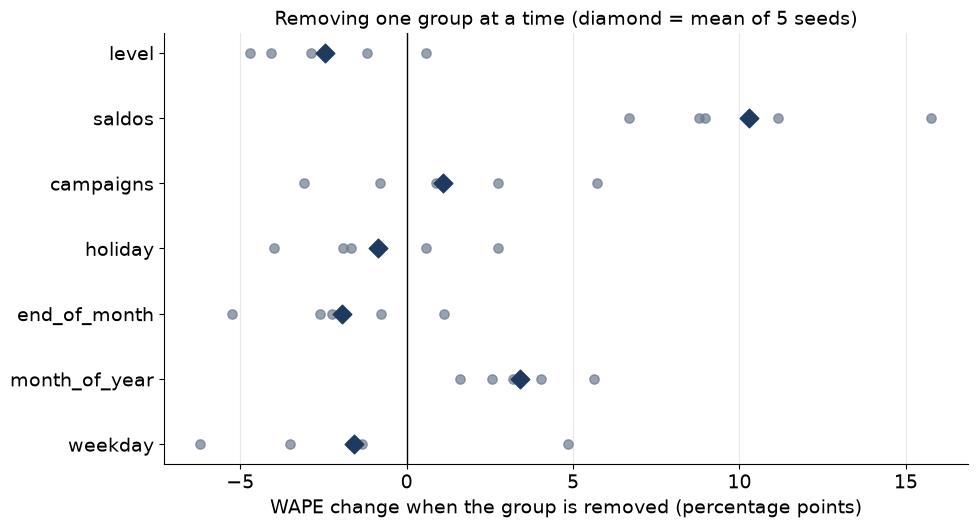

Guardado: evidence_dl_unidades/DLU11.png

--- Controlo 1: contagens ---
Linhas de previsão mensal: 560 | esperado: 560 | em falta: 0 | negativas: 0 | bate: True
Controlo 2: colunas de cada variante = completa menos as do grupo retirado: True | colunas da completa: 19
Controlo 3: repetir Jul 2025 com a completa e semente 0: diferença máxima 0.0 (esperado 0)
Controlo 4: só meses de Training: True


In [10]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses forecast_step, to_monthly, scorecard, FEATURE_GROUPS, SEEDS, TARGETS, MARKETS, split_of, fmt, pct, save_table, save_fig (previous cells).
for nome in ['forecast_step', 'to_monthly', 'scorecard', 'FEATURE_GROUPS', 'SEEDS', 'TARGETS', 'MARKETS', 'split_of', 'fmt', 'pct', 'save_table', 'save_fig']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again, then this one.")

plt.rcParams.update({'font.size': 14})
CFG_G = {'loss': 'huber', 'layers': (32,), 'epochs': 100}                  # provisional configuration, the same for all variants
GROUPS_A = ['weekday', 'month_of_year', 'end_of_month', 'holiday', 'campaigns', 'saldos', 'level']      # scenario A: without spend
STEPS = [t for t in TARGETS if split_of(t) == 'Training']
VARIANTS = {'full (7 groups)': GROUPS_A}
VARIANTS.update({f'without {g}': [x for x in GROUPS_A if x != g] for g in GROUPS_A})

# ---------- train all variants ----------
t0 = time.time()
fcs, n_cols = [], {}
for vname, groups in VARIANTS.items():
    n_cols[vname] = sum(len(FEATURE_GROUPS[g]) for g in groups)
    for seed in SEEDS:
        parts = [forecast_step(m, groups, CFG_G, seed).assign(step=str(m)) for m in STEPS]          # one model per market and per month
        fcs.append(to_monthly(pd.concat(parts, ignore_index=True), f'{vname}||{seed}'))
fc6 = pd.concat(fcs, ignore_index=True)
print(f'Networks trained: {len(VARIANTS) * len(SEEDS) * len(STEPS) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- metrics per variant and seed ----------
sc6 = scorecard(fc6)
sc6 = sc6[sc6['split'] == 'Training'].copy()
sc6[['variant', 'seed']] = sc6['method'].str.split(r'\|\|', expand=True)
sc6['seed'] = sc6['seed'].astype(int)
tot = sc6[sc6['mark'] == 'ES + PT'].set_index(['variant', 'seed'])

# ---------- DLU9: each group, with and without ----------
full_w = tot.loc['full (7 groups)']['WAPE']
rows = [{'Variant': 'full (7 groups)', 'Columns': n_cols['full (7 groups)'], 'WAPE mean': pct(full_w.mean()), 'WAPE std (seeds)': pct(full_w.std()),
         'Bias mean': pct(tot.loc['full (7 groups)']['Bias'].mean()), 'WAPE change vs full (pp)': '', 'Full wins (seeds of 5)': '', 'Decision': 'reference'}]
decisao = {}
for g in GROUPS_A:
    v = f'without {g}'
    w = tot.loc[v]['WAPE']
    ganha = int((full_w.sort_index() < w.sort_index()).sum())                 # seeds where having the group is better (comparison per seed)
    fica = bool(full_w.mean() < w.mean() and ganha >= 4)
    decisao[g] = {'delta_pp': (w.mean() - full_w.mean()) * 100, 'wins': ganha, 'fica': fica}
    rows.append({'Variant': v, 'Columns': n_cols[v], 'WAPE mean': pct(w.mean()), 'WAPE std (seeds)': pct(w.std()), 'Bias mean': pct(tot.loc[v]['Bias'].mean()),
                 'WAPE change vs full (pp)': f"{(w.mean() - full_w.mean()) * 100:+.1f}".replace('.', ','), 'Full wins (seeds of 5)': ganha,
                 'Decision': 'group stays' if fica else 'candidate to leave'})
dlu9 = pd.DataFrame(rows)
print('\n--- Each group, with and without (ES + PT, Training, mean of the 5 seeds; positive change = removing the group makes it worse) ---')
display(dlu9)
save_table(dlu9, 'DLU9', 'Variable groups: full network against each group removed (scenario A, units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- DLU10: by market ----------
mk = sc6[sc6['mark'].isin(MARKETS)].groupby(['variant', 'mark'])['WAPE'].mean().unstack()
dlu10 = pd.DataFrame({'Variant': list(VARIANTS), **{f'WAPE {m}': [pct(mk.loc[v, m]) for v in VARIANTS] for m in MARKETS}})
print('\n--- WAPE by market (mean of the 5 seeds) ---')
display(dlu10)
save_table(dlu10, 'DLU10', 'Variable groups: WAPE by market (scenario A, units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- chart: how much WAPE rises when each group is removed (dot = one seed) ----------
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, g in enumerate(GROUPS_A):
    d = (tot.loc[f'without {g}']['WAPE'].sort_index() - full_w.sort_index()) * 100
    ax.scatter(d.to_numpy(), [i] * len(d), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([d.mean()], [i], color='#1f3a5f', marker='D', s=90, zorder=4)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(range(len(GROUPS_A))); ax.set_yticklabels(GROUPS_A)
ax.set_xlabel('WAPE change when the group is removed (percentage points)'); ax.set_title('Removing one group at a time (diamond = mean of 5 seeds)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU11', 'Change in WAPE when each variable group is removed (scenario A, units, Training)', 'Jan-Jul 2025')

# ---------- checks ----------
n_esperado = len(VARIANTS) * len(SEEDS) * len(STEPS) * len(MARKETS)          # one monthly row per variant, seed, month and market
vazios = int(fc6['forecast'].isna().sum()); neg = int((fc6['forecast'] < 0).sum())
print('\n--- Check 1: counts ---')
print('Monthly forecast rows:', fmt(len(fc6)), '| expected:', fmt(n_esperado), '| missing:', vazios, '| negatives:', neg, '| match:', bool(len(fc6) == n_esperado and vazios == 0 and neg == 0))
cols_ok = all(n_cols[f'without {g}'] == n_cols['full (7 groups)'] - len(FEATURE_GROUPS[g]) for g in GROUPS_A)
print('Check 2: columns of each variant = full minus those of the removed group:', cols_ok, '| columns of the full one:', n_cols['full (7 groups)'])
m_ref = STEPS[-1]
rep = to_monthly(forecast_step(m_ref, GROUPS_A, CFG_G, SEEDS[0]), 'x').set_index('mark')['forecast']
guardada = fc6[(fc6['method'] == f'full (7 groups)||{SEEDS[0]}') & (fc6['month'] == m_ref)].set_index('mark')['forecast']
print(f"Check 3: repeat {m_ref.strftime('%b %Y')} with the full one and seed {SEEDS[0]}: largest difference", float((guardada - rep.loc[guardada.index]).abs().max()), '(expected 0)')
print('Check 4: only Training months:', bool(set(fc6['month']) == set(STEPS) and all(split_of(m) == 'Training' for m in fc6['month'].unique())))

# Efficiency: 8 variants × 5 seeds × 7 steps × 2 network trainings, each O(E·N·P) (E epochs, N training rows, P parameters): time O(V·S·T·E·N·P) with V=8, S=5, T=7;
# space O(N·C + P) per training (C columns); only the monthly forecasts are stored (O(V·S·T·M)).

### 6a. Conclusions

**Confirmed (full table, Training):**
- By the fixed rule, two groups **stay**: **month of the year** (removing it makes WAPE worse by about 3 points, in all 5 seeds) and **sales periods** (worse by about 10 points, in all 5 seeds).
- The other five are **candidates to leave**: day of the week, end of the month, holidays, campaigns and level. For none of them does the full network win in 4 of the 5 seeds. For four of them, removing the group even improves the mean WAPE. For campaigns, removing it makes things worse by about 1 point, but the full network only wins in 3 seeds.
- The group that costs the least to lose is the **level**: without it WAPE falls by 2,5 points, the biggest gain of all, and the full network only wins in one seed.

**Derived:**
- Almost all networks underestimate: the bias has practically the same value as WAPE, with a negative sign, and no variant corrects it. The network forecasts below the actual almost always, in every month.
- Sales periods help in both markets. Month of the year helps a lot in PT and does not help in ES, where removing it improves things a little.
- End of the month and holidays seem to hurt PT.

**To validate:**
- Differences of 1 to 2 points are at the level of the noise between seeds (spread of 2 to 3 points), and there are only 7 months. So the decision is the rule, not a reading of the points on the chart.
- **Hypothesis (not tested)** for the underestimation: units grew a lot from 2024 to 2025 and the network, trained only with the past, does not extrapolate that growth. Clipping the level to the training range may make this worse, because when the level rises above the maximum seen, the network stops seeing it.
- The result depends on the provisional configuration (Huber, 32, 100 epochs) and on this being scenario A.
- The definition of units is still to be confirmed with Parfois.

**Decision:** round 2 without the level, with the other six groups and the same rule (each group is tested with and without). In the same cell I add a month-by-month table (forecast against actual) to see in which months the bias fails the most.

## 7. Round 2: the base without the level (scenario A, Training)

**What we will do:** repeat the test of point 6, now with the network of 6 groups (the full one without the level, the group the rule told us to remove) and 6 networks where another group is removed one at a time. The forecast against the actual is also shown month by month, to see where the underestimation is.

**Goal:** continue choosing the base of variables by the fixed rule, and understand in which months the network fails the most.

**Fixed decisions (those of point 6, unchanged):**
- Scenario A, provisional configuration (Huber, one layer of 32, 100 epochs), 5 seeds, 7 Training months, monthly WAPE of ES + PT.
- **Rule:** a group stays if the network of 6 groups has a lower mean WAPE than the network without that group **and** wins in at least 4 of the 5 seeds. If several fail, only the one that costs the least leaves and the round is repeated.
- Comparison is only made inside this round: the results of round 1 are not mixed with these, except in the month-by-month table, where they serve as a reference.

**Cautions:**
- The level leaves by rule, not because we proved it is useless: without it the network stops seeing recent sales and only knows the calendar.
- There are only Training months. The Test stays closed.
- The month-by-month table describes what happened; it decides nothing.

**Checks:** 7 variants × 5 seeds × 7 steps × 2 markets; no missing forecast; the columns of each variant match the groups; the network of 6 groups of this round gives exactly the same forecast as the "without level" variant of round 1 (same groups, same seeds); repeating a training gives the same forecast; Training months only.

Redes treinadas: 490 em 5.9 minutos

--- Ronda 2: cada grupo, com e sem (ES + PT, Training, média das 5 sementes; mudança positiva = tirar o grupo piora) ---


,Variant,Columns,WAPE mean,WAPE std (seeds),Bias mean,WAPE change vs base (pp),Base wins (seeds of 5),Decision
0,full (6 groups),18,"40,1%","0,8%","-40,1%",,,reference
1,without weekday,11,"39,6%","0,6%","-39,6%","-0,5",2,candidate to leave
2,without month_of_year,16,"34,7%","0,6%","-34,7%","-5,4",0,candidate to leave
3,without end_of_month,17,"40,5%","0,5%","-40,5%","+0,4",3,candidate to leave
4,without holiday,17,"39,3%","0,5%","-39,3%","-0,8",1,candidate to leave
5,without campaigns,12,"40,1%","0,1%","-40,1%","-0,0",3,candidate to leave
6,without saldos,17,"39,6%","0,2%","-39,6%","-0,5",1,candidate to leave


Guardado: evidence_dl_unidades/DLU12.csv

--- WAPE por mercado (média das 5 sementes) ---


,Variant,WAPE Online ES,WAPE Online PT
0,full (6 groups),"41,5%","36,0%"
1,without weekday,"40,9%","35,8%"
2,without month_of_year,"36,1%","30,5%"
3,without end_of_month,"42,0%","36,0%"
4,without holiday,"40,6%","35,3%"
5,without campaigns,"41,5%","36,1%"
6,without saldos,"40,9%","35,7%"


Guardado: evidence_dl_unidades/DLU13.csv


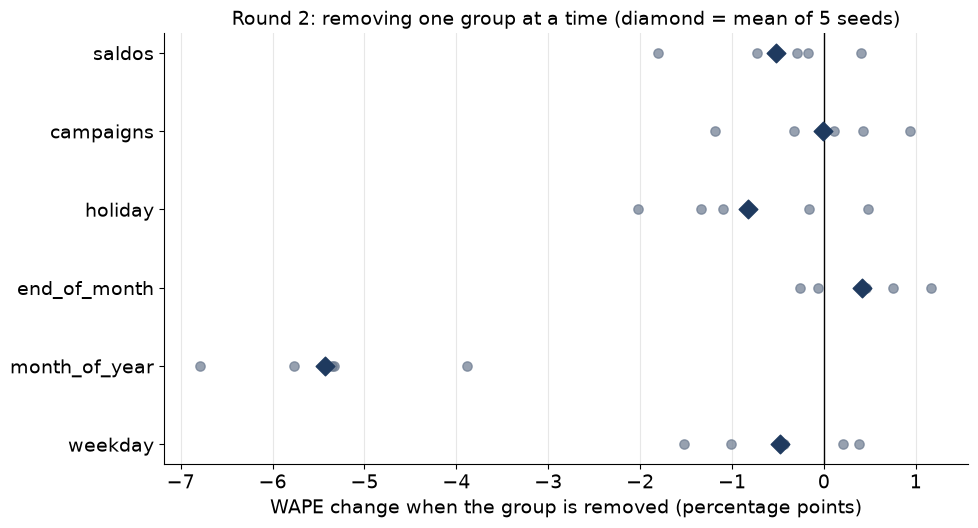

Guardado: evidence_dl_unidades/DLU14.png

--- Mês a mês: previsto contra real (média das 5 sementes; erro = (previsto - real) / real) ---


,Month to forecast,Market,Actual (units),"Forecast, 6 groups",Error 6 groups,"Forecast, 7 groups (with level)",Error 7 groups
0,Jan 2025,Online ES,332.982,148.356,"-55,4%",99.847,"-70,0%"
1,Jan 2025,Online PT,128.398,64.041,"-50,1%",50.811,"-60,4%"
2,Jan 2025,ES + PT,461.380,212.397,"-54,0%",150.658,"-67,3%"
3,Feb 2025,Online ES,223.662,113.483,"-49,3%",123.987,"-44,6%"
4,Feb 2025,Online PT,78.806,46.570,"-40,9%",51.427,"-34,7%"
5,Feb 2025,ES + PT,302.468,160.053,"-47,1%",175.414,"-42,0%"
6,Mar 2025,Online ES,113.004,52.722,"-53,3%",53.127,"-53,0%"
7,Mar 2025,Online PT,38.317,22.066,"-42,4%",42.471,"10,8%"
8,Mar 2025,ES + PT,151.321,74.788,"-50,6%",95.598,"-36,8%"
9,Apr 2025,Online ES,104.634,70.272,"-32,8%",59.648,"-43,0%"


Guardado: evidence_dl_unidades/DLU15.csv

--- Controlo 1: contagens ---
Linhas de previsão mensal: 490 | esperado: 490 | em falta: 0 | negativas: 0 | bate: True
Controlo 2: colunas de cada variante = base menos as do grupo retirado: True | colunas da base: 18
Controlo 3: a base de 6 grupos desta ronda = variante "sem nível" da ronda 1: diferença máxima 0.0 (esperado 0)
Controlo 4: repetir Jul 2025 com a base e semente 0: diferença máxima 0.0 (esperado 0)
Controlo 5: só meses de Training: True


In [11]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the functions and variables of the previous cells, including fc6 and GROUPS_A from point 6.
for nome in ['forecast_step', 'to_monthly', 'scorecard', 'FEATURE_GROUPS', 'SEEDS', 'TARGETS', 'MARKETS', 'split_of', 'fmt', 'pct', 'save_table', 'save_fig', 'CFG_G', 'GROUPS_A', 'STEPS', 'fc6', 'monthly']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including the one of point 6), then this one.")

plt.rcParams.update({'font.size': 14})
GROUPS_B = [g for g in GROUPS_A if g != 'level']                       # base of round 2: without the level
BASE_B = 'full (6 groups)'
VARIANTS_B = {BASE_B: GROUPS_B}
VARIANTS_B.update({f'without {g}': [x for x in GROUPS_B if x != g] for g in GROUPS_B})

# ---------- train all variants ----------
t0 = time.time()
fcs, n_cols_b = [], {}
for vname, groups in VARIANTS_B.items():
    n_cols_b[vname] = sum(len(FEATURE_GROUPS[g]) for g in groups)
    for seed in SEEDS:
        parts = [forecast_step(m, groups, CFG_G, seed) for m in STEPS]
        fcs.append(to_monthly(pd.concat(parts, ignore_index=True), f'{vname}||{seed}'))
fc7 = pd.concat(fcs, ignore_index=True)
print(f'Networks trained: {len(VARIANTS_B) * len(SEEDS) * len(STEPS) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- metrics per variant and seed ----------
sc7 = scorecard(fc7)
sc7 = sc7[sc7['split'] == 'Training'].copy()
sc7[['variant', 'seed']] = sc7['method'].str.split(r'\|\|', expand=True)
sc7['seed'] = sc7['seed'].astype(int)
tot7 = sc7[sc7['mark'] == 'ES + PT'].set_index(['variant', 'seed'])

# ---------- DLU12: each group, with and without (round 2) ----------
base_w = tot7.loc[BASE_B]['WAPE'].sort_index()
rows = [{'Variant': BASE_B, 'Columns': n_cols_b[BASE_B], 'WAPE mean': pct(base_w.mean()), 'WAPE std (seeds)': pct(base_w.std()), 'Bias mean': pct(tot7.loc[BASE_B]['Bias'].mean()),
         'WAPE change vs base (pp)': '', 'Base wins (seeds of 5)': '', 'Decision': 'reference'}]
for g in GROUPS_B:
    v = f'without {g}'
    w = tot7.loc[v]['WAPE'].sort_index()
    ganha = int((base_w < w).sum())
    fica = bool(base_w.mean() < w.mean() and ganha >= 4)
    rows.append({'Variant': v, 'Columns': n_cols_b[v], 'WAPE mean': pct(w.mean()), 'WAPE std (seeds)': pct(w.std()), 'Bias mean': pct(tot7.loc[v]['Bias'].mean()),
                 'WAPE change vs base (pp)': f"{(w.mean() - base_w.mean()) * 100:+.1f}".replace('.', ','), 'Base wins (seeds of 5)': ganha,
                 'Decision': 'group stays' if fica else 'candidate to leave'})
dlu12 = pd.DataFrame(rows)
print('\n--- Round 2: each group, with and without (ES + PT, Training, mean of the 5 seeds; positive change = removing the group makes it worse) ---')
display(dlu12)
save_table(dlu12, 'DLU12', 'Round 2: base network without level against each group removed (scenario A, units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- DLU13: by market ----------
mk7 = sc7[sc7['mark'].isin(MARKETS)].groupby(['variant', 'mark'])['WAPE'].mean().unstack()
dlu13 = pd.DataFrame({'Variant': list(VARIANTS_B), **{f'WAPE {m}': [pct(mk7.loc[v, m]) for v in VARIANTS_B] for m in MARKETS}})
print('\n--- WAPE by market (mean of the 5 seeds) ---')
display(dlu13)
save_table(dlu13, 'DLU13', 'Round 2: WAPE by market (scenario A, units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- chart ----------
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, g in enumerate(GROUPS_B):
    d = (tot7.loc[f'without {g}']['WAPE'].sort_index() - base_w) * 100
    ax.scatter(d.to_numpy(), [i] * len(d), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([d.mean()], [i], color='#1f3a5f', marker='D', s=90, zorder=4)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(range(len(GROUPS_B))); ax.set_yticklabels(GROUPS_B)
ax.set_xlabel('WAPE change when the group is removed (percentage points)'); ax.set_title('Round 2: removing one group at a time (diamond = mean of 5 seeds)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU14', 'Round 2: change in WAPE when each variable group is removed (scenario A, units, Training)', 'Jan-Jul 2025')

# ---------- DLU15: month by month, forecast against actual (mean of the 5 seeds), with and without level ----------
act = monthly.set_index(['mark', 'month'])['net_units']
def mensal(fc, met):
    d = fc[fc['method'].str.startswith(met + '||')].groupby(['mark', 'month'])['forecast'].mean()          # mean of the seeds
    return d
b6, b7 = mensal(fc7, BASE_B), mensal(fc6, 'full (7 groups)')
rows = []
for m in STEPS:
    for mkt in MARKETS + ['ES + PT']:
        sel = MARKETS if mkt == 'ES + PT' else [mkt]
        r_ = float(sum(act[(x, m)] for x in sel)); f6_ = float(sum(b6[(x, m)] for x in sel)); f7_ = float(sum(b7[(x, m)] for x in sel))
        rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mkt, 'Actual (units)': fmt(r_), 'Forecast, 6 groups': fmt(f6_), 'Error 6 groups': pct((f6_ - r_) / r_),
                     'Forecast, 7 groups (with level)': fmt(f7_), 'Error 7 groups': pct((f7_ - r_) / r_)})
dlu15 = pd.DataFrame(rows)
print('\n--- Month by month: forecast against actual (mean of the 5 seeds; error = (forecast - actual) / actual) ---')
display(dlu15)
save_table(dlu15, 'DLU15', 'Month by month: forecast against actual, 6 groups and 7 groups (scenario A, units, Training, mean of 5 seeds)', 'Jan-Jul 2025')

# ---------- checks ----------
n_esperado = len(VARIANTS_B) * len(SEEDS) * len(STEPS) * len(MARKETS)
vazios = int(fc7['forecast'].isna().sum()); neg = int((fc7['forecast'] < 0).sum())
print('\n--- Check 1: counts ---')
print('Monthly forecast rows:', fmt(len(fc7)), '| expected:', fmt(n_esperado), '| missing:', vazios, '| negatives:', neg, '| match:', bool(len(fc7) == n_esperado and vazios == 0 and neg == 0))
cols_ok = all(n_cols_b[f'without {g}'] == n_cols_b[BASE_B] - len(FEATURE_GROUPS[g]) for g in GROUPS_B)
print('Check 2: columns of each variant = base minus those of the removed group:', cols_ok, '| columns of the base:', n_cols_b[BASE_B])
a_ = fc7[fc7['method'].str.startswith(BASE_B + '||')].assign(seed=lambda d: d['method'].str.split(r'\|\|').str[1]).set_index(['seed', 'mark', 'month'])['forecast'].sort_index()
b_ = fc6[fc6['method'].str.startswith('without level||')].assign(seed=lambda d: d['method'].str.split(r'\|\|').str[1]).set_index(['seed', 'mark', 'month'])['forecast'].sort_index()
print('Check 3: the 6-group base of this round = "no level" variant of round 1: largest difference', float((a_ - b_).abs().max()), '(expected 0)')
m_ref = STEPS[-1]
rep = to_monthly(forecast_step(m_ref, GROUPS_B, CFG_G, SEEDS[0]), 'x').set_index('mark')['forecast']
guardada = fc7[(fc7['method'] == f'{BASE_B}||{SEEDS[0]}') & (fc7['month'] == m_ref)].set_index('mark')['forecast']
print(f"Check 4: repeat {m_ref.strftime('%b %Y')} with the base and seed {SEEDS[0]}: largest difference", float((guardada - rep.loc[guardada.index]).abs().max()), '(expected 0)')
print('Check 5: only Training months:', bool(set(fc7['month']) == set(STEPS) and all(split_of(m) == 'Training' for m in fc7['month'].unique())))

# Efficiency: 7 variants × 5 seeds × 7 steps × 2 network trainings, each O(E·N·P): time O(V·S·T·E·N·P) with V=7, S=5, T=7; space O(N·C + P) per training; only the monthly forecasts are stored.

### 7a. Conclusions

**Confirmed (full table, Training):**
- None of the 6 groups meets the rule to stay: for all of them, the network of 6 groups does not win in 4 of the 5 seeds.
- The one that costs the least to lose is **month of the year**: without it WAPE falls by 5,4 points and the base loses in all 5 seeds. It is the only effect clearly outside the noise (the others are below 1 point, with seeds on both sides of zero).
- By the rule, month of the year leaves and the round is repeated (round 3, with 5 groups).
- In the month-by-month table the network **underestimates in every month and in both markets**, more in January to March (about 50%) than in May to July (16% to 33%).

**Derived:**
- The groups interact: **sales periods**, which were worth about 10 points in round 1, no longer count here without the level, and **month of the year**, which helped with the level, now hurts without it. So the choice has to be made round by round and not group by group.
- With the level the network follows PT better in March and April (positive error), but not ES, and it does not improve the other months.
- From May to July (the months where B3 also exists), the monthly WAPE of the base is about 29%, calculated from the table, against 27,3% for B3. It is not a final comparison, because the configuration is provisional, the seeds were mixed in the mean and B3 overestimates while the network underestimates.

**To validate:**
- **Hypothesis (not tested):** the underestimation is structural. Units grew a lot from 2024 to 2025 and, in the first months of 2025, the network only saw 2024 (and a single January, without level), so it has no way to extrapolate the growth. Choosing variables alone does not solve this.
- If the rule keeps removing groups, the network is left with only the calendar and loses any information about the recent pace. It is worth deciding in advance what to do in that case.
- The definition of units is still to be confirmed with Parfois.

**Decision:** round 3 without the month of the year, by the rule. In parallel, fix before seeing results two hypotheses for the underestimation, to test next as separate variants (for example, recent growth as a variable, or the level without clipping to the training range).

## 8. Round 3: the base without the month of the year (scenario A, Training)

**What we will do:** repeat the test with the network of 5 groups (the one of 6 without the month of the year, which the rule told us to remove in round 2) and 5 networks where another group is removed one at a time. The base of 5 groups against the one of 6 is also shown month by month.

**Goal:** close the choice of the base of variables for scenario A by the fixed rule.

**Fixed decisions (those of point 6, unchanged):** scenario A, provisional configuration (Huber, one layer of 32, 100 epochs), 5 seeds, 7 Training months, monthly WAPE of ES + PT. A group stays if the base has a lower mean WAPE than the network without it **and** wins in at least 4 of the 5 seeds; if several fail, only the one that costs the least leaves.

**New rules, fixed before seeing the results of this round:**
- **Stop:** the removal of groups ends in this round, whatever the result. The final base of scenario A is the one of 5 groups, minus the group that leaves now, if any leaves. In three rounds two groups out of eight have already left and the remaining differences are at the level of the noise; continuing to remove groups would leave the network with only the calendar.
- **The underestimation is not solved by removing groups.** What the network lacks is information about growth. Once the base is fixed, two hypotheses are tested separately, each as a variant on the base and with the same rule (lower mean WAPE and a win in at least 4 of the 5 seeds, over the same 7 Training months):
  - **H1, trend over time:** add a variable with the number of days since 1 January 2024. It is a date, known in advance, and does not use data after the cutoff.
  - **H2, level without clipping:** add the 28-day level again, but without clipping to the range seen in training, to see whether the clipping is what made it fail.

**Cautions:**
- There are only Training months. The Test stays closed.
- Hypotheses H1 and H2 are only tested in the next point; here they are only written down.
- The month-by-month table describes what happened; it decides nothing.

**Checks:** 6 variants × 5 seeds × 7 steps × 2 markets; no missing forecast; the columns match the groups; the base of 5 groups of this round gives exactly the same forecast as the "without month of the year" variant of round 2 (same groups, same seeds); repeating a training gives the same forecast; Training months only.

Redes treinadas: 420 em 4.3 minutos

--- Ronda 3: cada grupo, com e sem (ES + PT, Training, média das 5 sementes; mudança positiva = tirar o grupo piora) ---


,Variant,Columns,WAPE mean,WAPE std (seeds),Bias mean,WAPE change vs base (pp),Base wins (seeds of 5),Decision
0,full (5 groups),16,"34,7%","0,6%","-34,7%",,,reference
1,without weekday,9,"35,0%","0,1%","-35,0%","+0,3",4,group stays
2,without end_of_month,15,"35,2%","0,3%","-35,2%","+0,5",5,group stays
3,without holiday,15,"34,7%","0,4%","-34,7%","+0,0",3,candidate to leave
4,without campaigns,10,"32,3%","0,3%","-32,2%","-2,4",0,candidate to leave
5,without saldos,15,"42,1%","0,4%","-36,4%","+7,5",5,group stays


Guardado: evidence_dl_unidades/DLU16.csv

Pela regra, sai: campaigns (candidatos: holiday, campaigns). A remoção acaba aqui. Base final do cenário A: weekday, end_of_month, holiday, saldos (4 grupos)

--- WAPE por mercado (média das 5 sementes) ---


,Variant,WAPE Online ES,WAPE Online PT
0,full (5 groups),"36,1%","30,5%"
1,without weekday,"36,5%","30,8%"
2,without end_of_month,"36,7%","30,8%"
3,without holiday,"36,2%","30,4%"
4,without campaigns,"33,6%","29,6%"
5,without saldos,"41,8%","43,9%"


Guardado: evidence_dl_unidades/DLU17.csv


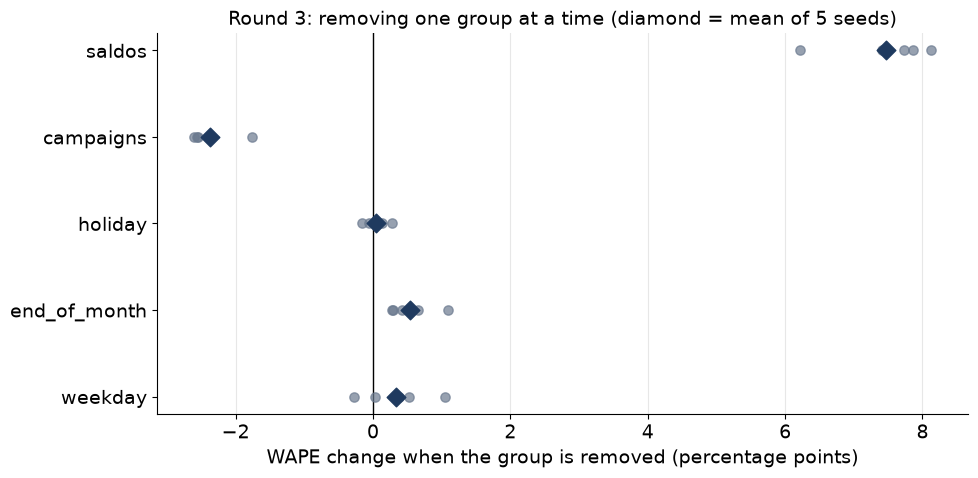

Guardado: evidence_dl_unidades/DLU18.png

--- Mês a mês: previsto contra real (média das 5 sementes; erro = (previsto - real) / real) ---


,Month to forecast,Market,Actual (units),"Forecast, 5 groups",Error 5 groups,"Forecast, 6 groups",Error 6 groups
0,Jan 2025,ES + PT,461.380,206.495,"-55,2%",212.397,"-54,0%"
1,Jan 2025,Online ES,332.982,145.813,"-56,2%",148.356,"-55,4%"
2,Jan 2025,Online PT,128.398,60.682,"-52,7%",64.041,"-50,1%"
3,Feb 2025,ES + PT,302.468,191.348,"-36,7%",160.053,"-47,1%"
4,Feb 2025,Online ES,223.662,137.933,"-38,3%",113.483,"-49,3%"
5,Feb 2025,Online PT,78.806,53.415,"-32,2%",46.570,"-40,9%"
6,Mar 2025,ES + PT,151.321,139.730,"-7,7%",74.788,"-50,6%"
7,Mar 2025,Online ES,113.004,104.523,"-7,5%",52.722,"-53,3%"
8,Mar 2025,Online PT,38.317,35.207,"-8,1%",22.066,"-42,4%"
9,Apr 2025,ES + PT,135.154,106.693,"-21,1%",94.339,"-30,2%"


Guardado: evidence_dl_unidades/DLU19.csv

--- Controlo 1: contagens ---
Linhas de previsão mensal: 420 | esperado: 420 | em falta: 0 | negativas: 0 | bate: True
Controlo 2: colunas de cada variante = base menos as do grupo retirado: True | colunas da base: 16
Controlo 3: a base de 5 grupos desta ronda = variante "sem mês do ano" da ronda 2: diferença máxima 0.0 (esperado 0)
Controlo 4: repetir Jul 2025 com a base e semente 0: diferença máxima 0.0 (esperado 0)
Controlo 5: só meses de Training: True


In [12]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the functions and variables of the previous cells, including fc7, GROUPS_B and BASE_B from point 7.
for nome in ['forecast_step', 'to_monthly', 'scorecard', 'FEATURE_GROUPS', 'SEEDS', 'TARGETS', 'MARKETS', 'split_of', 'fmt', 'pct', 'save_table', 'save_fig', 'CFG_G', 'STEPS', 'fc7', 'GROUPS_B', 'BASE_B', 'monthly']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including the one of point 7), then this one.")

plt.rcParams.update({'font.size': 14})
GROUPS_C = [g for g in GROUPS_B if g != 'month_of_year']               # base of round 3: without the month of the year
BASE_C = 'full (5 groups)'
VARIANTS_C = {BASE_C: GROUPS_C}
VARIANTS_C.update({f'without {g}': [x for x in GROUPS_C if x != g] for g in GROUPS_C})

# ---------- train all variants ----------
t0 = time.time()
fcs, n_cols_c = [], {}
for vname, groups in VARIANTS_C.items():
    n_cols_c[vname] = sum(len(FEATURE_GROUPS[g]) for g in groups)
    for seed in SEEDS:
        parts = [forecast_step(m, groups, CFG_G, seed) for m in STEPS]
        fcs.append(to_monthly(pd.concat(parts, ignore_index=True), f'{vname}||{seed}'))
fc8 = pd.concat(fcs, ignore_index=True)
print(f'Networks trained: {len(VARIANTS_C) * len(SEEDS) * len(STEPS) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- metrics per variant and seed ----------
sc8 = scorecard(fc8)
sc8 = sc8[sc8['split'] == 'Training'].copy()
sc8[['variant', 'seed']] = sc8['method'].str.split(r'\|\|', expand=True)
sc8['seed'] = sc8['seed'].astype(int)
tot8 = sc8[sc8['mark'] == 'ES + PT'].set_index(['variant', 'seed'])

# ---------- DLU16: each group, with and without (round 3) ----------
base_w = tot8.loc[BASE_C]['WAPE'].sort_index()
rows = [{'Variant': BASE_C, 'Columns': n_cols_c[BASE_C], 'WAPE mean': pct(base_w.mean()), 'WAPE std (seeds)': pct(base_w.std()), 'Bias mean': pct(tot8.loc[BASE_C]['Bias'].mean()),
         'WAPE change vs base (pp)': '', 'Base wins (seeds of 5)': '', 'Decision': 'reference'}]
delta, falham = {}, []
for g in GROUPS_C:
    v = f'without {g}'
    w = tot8.loc[v]['WAPE'].sort_index()
    ganha = int((base_w < w).sum())
    fica = bool(base_w.mean() < w.mean() and ganha >= 4)
    delta[g] = (w.mean() - base_w.mean()) * 100
    if not fica:
        falham.append(g)
    rows.append({'Variant': v, 'Columns': n_cols_c[v], 'WAPE mean': pct(w.mean()), 'WAPE std (seeds)': pct(w.std()), 'Bias mean': pct(tot8.loc[v]['Bias'].mean()),
                 'WAPE change vs base (pp)': f"{delta[g]:+.1f}".replace('.', ','), 'Base wins (seeds of 5)': ganha, 'Decision': 'group stays' if fica else 'candidate to leave'})
dlu16 = pd.DataFrame(rows)
print('\n--- Round 3: each group, with and without (ES + PT, Training, mean of the 5 seeds; positive change = removing the group makes it worse) ---')
display(dlu16)
save_table(dlu16, 'DLU16', 'Round 3: base network without month of year against each group removed (scenario A, units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- what the rule says to do (the fixed rule: only what costs least leaves; removal ends here) ----------
if falham:
    sai = min(falham, key=lambda g: delta[g])                          # the smallest rise in WAPE (or the largest drop) when it is removed
    GROUPS_FINAL_A = [g for g in GROUPS_C if g != sai]
    print(f"\nBy the rule, it leaves: {sai} (candidates: {', '.join(falham)}). Removal ends here. Final base of scenario A: {', '.join(GROUPS_FINAL_A)} ({len(GROUPS_FINAL_A)} groups)")
else:
    sai = None; GROUPS_FINAL_A = list(GROUPS_C)
    print(f"\nBy the rule, no group leaves. Final base of scenario A: {', '.join(GROUPS_FINAL_A)} ({len(GROUPS_FINAL_A)} groups)")

# ---------- DLU17: by market ----------
mk8 = sc8[sc8['mark'].isin(MARKETS)].groupby(['variant', 'mark'])['WAPE'].mean().unstack()
dlu17 = pd.DataFrame({'Variant': list(VARIANTS_C), **{f'WAPE {m}': [pct(mk8.loc[v, m]) for v in VARIANTS_C] for m in MARKETS}})
print('\n--- WAPE by market (mean of the 5 seeds) ---')
display(dlu17)
save_table(dlu17, 'DLU17', 'Round 3: WAPE by market (scenario A, units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- chart ----------
fig, ax = plt.subplots(figsize=(10, 5))
for i, g in enumerate(GROUPS_C):
    d = (tot8.loc[f'without {g}']['WAPE'].sort_index() - base_w) * 100
    ax.scatter(d.to_numpy(), [i] * len(d), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([d.mean()], [i], color='#1f3a5f', marker='D', s=90, zorder=4)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(range(len(GROUPS_C))); ax.set_yticklabels(GROUPS_C)
ax.set_xlabel('WAPE change when the group is removed (percentage points)'); ax.set_title('Round 3: removing one group at a time (diamond = mean of 5 seeds)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU18', 'Round 3: change in WAPE when each variable group is removed (scenario A, units, Training)', 'Jan-Jul 2025')

# ---------- DLU19: month by month, 5-group base against the 6-group one (mean of the 5 seeds) ----------
act = monthly.set_index(['mark', 'month'])['net_units']
def mensal(fc, met):
    return fc[fc['method'].str.startswith(met + '||')].groupby(['mark', 'month'])['forecast'].mean()          # mean of the seeds
b5, b6 = mensal(fc8, BASE_C), mensal(fc7, BASE_B)
rows = []
for m in STEPS:
    for mkt in ['ES + PT'] + MARKETS:
        sel = MARKETS if mkt == 'ES + PT' else [mkt]
        r_ = float(sum(act[(x, m)] for x in sel)); f5_ = float(sum(b5[(x, m)] for x in sel)); f6_ = float(sum(b6[(x, m)] for x in sel))
        rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mkt, 'Actual (units)': fmt(r_), 'Forecast, 5 groups': fmt(f5_), 'Error 5 groups': pct((f5_ - r_) / r_),
                     'Forecast, 6 groups': fmt(f6_), 'Error 6 groups': pct((f6_ - r_) / r_)})
dlu19 = pd.DataFrame(rows)
print('\n--- Month by month: forecast against actual (mean of the 5 seeds; error = (forecast - actual) / actual) ---')
display(dlu19)
save_table(dlu19, 'DLU19', 'Month by month: forecast against actual, 5 groups and 6 groups (scenario A, units, Training, mean of 5 seeds)', 'Jan-Jul 2025')

# ---------- checks ----------
n_esperado = len(VARIANTS_C) * len(SEEDS) * len(STEPS) * len(MARKETS)
vazios = int(fc8['forecast'].isna().sum()); neg = int((fc8['forecast'] < 0).sum())
print('\n--- Check 1: counts ---')
print('Monthly forecast rows:', fmt(len(fc8)), '| expected:', fmt(n_esperado), '| missing:', vazios, '| negatives:', neg, '| match:', bool(len(fc8) == n_esperado and vazios == 0 and neg == 0))
cols_ok = all(n_cols_c[f'without {g}'] == n_cols_c[BASE_C] - len(FEATURE_GROUPS[g]) for g in GROUPS_C)
print('Check 2: columns of each variant = base minus those of the removed group:', cols_ok, '| columns of the base:', n_cols_c[BASE_C])
a_ = fc8[fc8['method'].str.startswith(BASE_C + '||')].assign(seed=lambda d: d['method'].str.split(r'\|\|').str[1]).set_index(['seed', 'mark', 'month'])['forecast'].sort_index()
b_ = fc7[fc7['method'].str.startswith('without month_of_year||')].assign(seed=lambda d: d['method'].str.split(r'\|\|').str[1]).set_index(['seed', 'mark', 'month'])['forecast'].sort_index()
print('Check 3: the 5-group base of this round = "without month of the year" variant of round 2: largest difference', float((a_ - b_).abs().max()), '(expected 0)')
m_ref = STEPS[-1]
rep = to_monthly(forecast_step(m_ref, GROUPS_C, CFG_G, SEEDS[0]), 'x').set_index('mark')['forecast']
guardada = fc8[(fc8['method'] == f'{BASE_C}||{SEEDS[0]}') & (fc8['month'] == m_ref)].set_index('mark')['forecast']
print(f"Check 4: repeat {m_ref.strftime('%b %Y')} with the base and seed {SEEDS[0]}: largest difference", float((guardada - rep.loc[guardada.index]).abs().max()), '(expected 0)')
print('Check 5: only Training months:', bool(set(fc8['month']) == set(STEPS) and all(split_of(m) == 'Training' for m in fc8['month'].unique())))

# Efficiency: 6 variants × 5 seeds × 7 steps × 2 network trainings, each O(E·N·P): time O(V·S·T·E·N·P) with V=6, S=5, T=7; space O(N·C + P) per training; only the monthly forecasts are stored.

### 8a. Conclusions

**Confirmed (full table, Training):**
- By the rule, three groups stay: **sales periods** (removing them makes things worse by about 7,5 points, in all 5 seeds), **end of the month** (+0,5, in all 5 seeds) and **day of the week** (+0,3, in 4 seeds).
- **Holidays** do not meet the rule to stay (effect of 0,0 points, the base only wins in 3 seeds) and **campaigns** make the forecast worse: without them WAPE falls by 2,4 points and the base loses in all 5 seeds.
- By the fixed rule, only one group leaves, the one that costs the least: **campaigns**. The removal ends here and the **final base of scenario A has 4 groups**: day of the week, end of the month, holidays and sales periods (10 columns). Holidays stay only because the removal ends in this round, not because they proved to help.
- The network of 4 groups was already trained in this round (it is the "without campaigns" variant), with a WAPE of about 32% over the 7 Training months. It still underestimates: the bias has almost the same value as WAPE, with a negative sign.

**Derived:**
- **Sales periods** and **month of the year** replace each other: with the month of the year in the network, sales periods hardly counted (round 2); without it, they become the most important group. This supports choosing round by round and not group by group.
- The underestimation remains in every month, but the base of 5 groups improves mostly March and April against the one of 6 (March goes from about −50% to −8%) and gets a little worse in May and June. January and February remain the worst months (−55% and −37% in total ES + PT).
- Without sales periods, PT gets much worse than ES.

**To validate:**
- **Hypothesis (not tested):** the underestimation is structural, due to a lack of information about growth. January and February are the months with the least history for the network (a single year and almost no 2025), which is consistent with this pattern.
- The month-by-month table is for the base of 5 groups, not the final base of 4. The one for the final base will come in the comparison with hypotheses H1 and H2.
- The results depend on the provisional configuration (Huber, 32, 100 epochs); the grid only runs after the variables are fixed.
- The definition of units is still to be confirmed with Parfois.

**Decision:** final base of scenario A = day of the week, end of the month, holidays and sales periods. In the next point we test hypotheses H1 (trend over time) and H2 (level without clipping), each as a variant on this base, with the rule already fixed (lower mean WAPE and a win in at least 4 of the 5 seeds, over the same 7 Training months).

## 9. Hypotheses H1 and H2: what does the network lack to stop underestimating? (scenario A, Training)

**What we will do:** test on the final base of scenario A (day of the week, end of the month, holidays and sales periods) the two hypotheses fixed in point 8, each as a separate variant:
- **H1, trend over time:** add a variable with the number of days since 1 January 2024.
- **H2, level without clipping:** add the 28-day level, without clipping to the range seen in training.

We add a diagnostic variant, **base + level with clipping**, only to separate the effect of clipping from the effect of the level (it has no decision). And a table that shows, month by month, whether the level at the cutoff was outside the training range.

**Goal:** see whether either piece of information reduces the underestimation and fix the full base of scenario A.

**Decisions fixed before seeing results:**
- **Rule (the one of point 8):** a hypothesis enters if the mean WAPE of ES + PT over the 7 Training months is lower than that of the base **and** it wins in at least 4 of the 5 seeds (compared seed by seed).
- **If both pass:** the one with the lowest mean WAPE stays. They are not combined, for simplicity and because there are only 7 months to validate.
- **Provisional configuration, the same as the base:** Huber, one layer of 32, 100 epochs; 5 seeds; 7 Training months. The base is the "without campaigns" variant of round 3 (same groups, same seeds), so it is not trained again.
- Bias and WAPE by market are supporting evidence.

**Cautions:**
- The trend variable falls outside the training range in every month to forecast. The network will extrapolate, and that is the point of the hypothesis; the network does not clip it.
- The 28-day level uses only data up to the cutoff. The level without clipping can be far above what was seen in training, and the network will also extrapolate.
- There are only Training months. The Test stays closed.

**Checks:** 3 new variants × 5 seeds × 7 steps × 2 markets; no missing forecast; the recalculated base gives exactly the same forecast as the one of round 3; the trend is 0 on 1 January 2024 and 730 on 31 December 2025, equal in both markets; Training months only.

Redes treinadas: 210 em 2.0 minutos

--- Hipóteses contra a base (ES + PT, Training, média das 5 sementes; "Columns" da variante com nível inclui a marca de "sem histórico") ---


,Variant,Columns,WAPE mean,WAPE std (seeds),Bias mean,WAPE change vs base (pp; negative = better),Wins vs base (seeds of 5),Decision
0,base (4 groups),10,"32,3%","0,3%","-32,2%",,,reference
1,H1: base + trend,11,"41,0%","1,4%","1,0%","+8,7",0,does not enter
2,H2: base + level (no clip),12,"56,1%","2,3%","-36,6%","+23,8",0,does not enter
3,Diagnostic: base + level (with clip),12,"43,9%","0,8%","-36,8%","+11,6",0,diagnostic only


Guardado: evidence_dl_unidades/DLU20.csv

Pela regra, nenhuma hipótese entra. Base completa do cenário A: weekday, end_of_month, holiday, saldos

--- WAPE por mercado (média das 5 sementes) ---


,Variant,WAPE Online ES,WAPE Online PT
0,base (4 groups),"33,6%","29,6%"
1,H1: base + trend,"39,8%","44,6%"
2,H2: base + level (no clip),"54,7%","60,8%"
3,Diagnostic: base + level (with clip),"41,5%","51,5%"


Guardado: evidence_dl_unidades/DLU21.csv


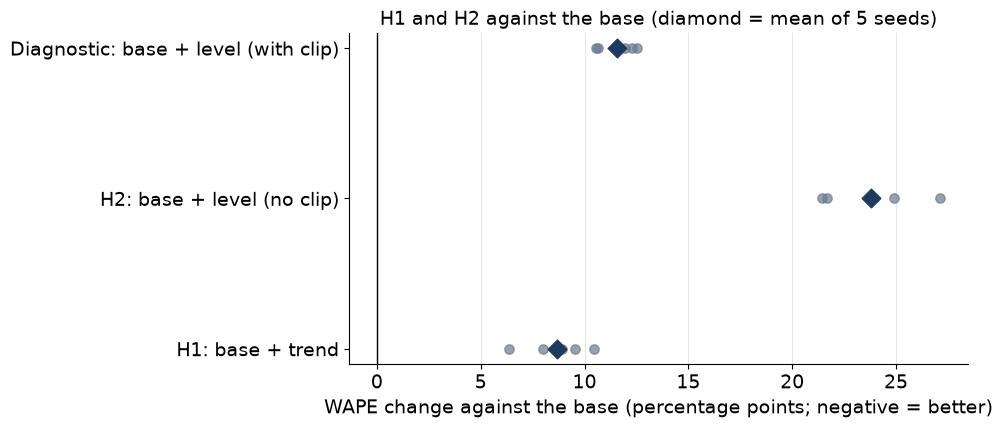

Guardado: evidence_dl_unidades/DLU22.png

--- O corte do nível ao intervalo do treino estaria a atuar? (nível de 28 dias no corte contra o intervalo visto no treino) ---


,Month to forecast,Market,Level at cutoff,Training min,Training max,Outside the training range
0,Jan 2025,Online ES,8.155,2.062,6.015,above
1,Jan 2025,Online PT,3.367,759,2.050,above
2,Feb 2025,Online ES,5.780,2.062,6.015,no
3,Feb 2025,Online PT,2.042,759,2.050,no
4,Mar 2025,Online ES,11.570,2.062,8.155,above
5,Mar 2025,Online PT,3.679,759,3.367,above
6,Apr 2025,Online ES,7.988,2.062,8.155,no
7,Apr 2025,Online PT,2.814,759,3.367,no
8,May 2025,Online ES,3.658,2.062,11.570,no
9,May 2025,Online PT,1.236,759,3.679,no


Guardado: evidence_dl_unidades/DLU23.csv

--- Mês a mês (ES + PT): previsto contra real, média das 5 sementes ---


,Month to forecast,Actual (units),Forecast base,Error base,Forecast H1,Error H1,Forecast H2,Error H2
0,Jan 2025,461.380,203.832,"-55,8%",207.559,"-55,0%",11.519,"-97,5%"
1,Feb 2025,302.468,194.153,"-35,8%",243.011,"-19,7%",120.319,"-60,2%"
2,Mar 2025,151.321,148.779,"-1,7%",316.010,"108,8%",310.050,"104,9%"
3,Apr 2025,135.154,135.278,"0,1%",282.055,"108,7%",155.596,"15,1%"
4,May 2025,168.036,143.543,"-14,6%",207.137,"23,3%",154.844,"-7,9%"
5,Jun 2025,259.624,160.347,"-38,2%",205.380,"-20,9%",168.930,"-34,9%"
6,Jul 2025,362.588,261.523,"-27,9%",398.530,"9,9%",244.806,"-32,5%"


Guardado: evidence_dl_unidades/DLU24.csv

--- Controlo 1: contagens ---
Linhas das variantes novas: 210 | esperado: 210 | em falta (todas): 0 | negativas (todas): 0 | bate: True
Controlo 2: recalcular a base em Jul 2025, semente 0: diferença máxima contra a da ronda 3 0.0 (esperado 0)
Controlo 3: tendência de 0 a 730 dias, igual nos dois mercados, e a tabela original ficou igual: True
Controlo 4: só meses de Training: True
Controlo 5: meses/mercados com o nível fora do intervalo do treino (onde o corte atua): 4 de 14


In [13]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the functions and variables of the previous cells, including fc8 and GROUPS_FINAL_A from point 8.
for nome in ['forecast_step', 'to_monthly', 'scorecard', 'FEATURE_GROUPS', 'SEEDS', 'TARGETS', 'MARKETS', 'split_of', 'fmt', 'pct', 'save_table', 'save_fig', 'CFG_G', 'STEPS', 'fc8', 'GROUPS_FINAL_A',
             'feat', 'monthly', 'cutoff_date']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including the one of point 8), then this one.")

plt.rcParams.update({'font.size': 14})
BASE_D = 'base (4 groups)'

# ---------- the two hypotheses, as table and groups ----------
feat_h = feat.copy()
feat_h['trend_days'] = (feat_h['day'] - pd.Timestamp('2024-01-01')).dt.days        # depends only on the date: uses no data after the cutoff
FEATURE_GROUPS['trend'] = ['trend_days']                                           # records the group (the feat_h table has the column; the original feat does not)

VARIANTS_D = {
    'H1: base + trend': dict(groups=GROUPS_FINAL_A + ['trend'], table=feat_h, clip=True),
    'H2: base + level (no clip)': dict(groups=GROUPS_FINAL_A + ['level'], table=feat_h, clip=False),
    'Diagnostic: base + level (with clip)': dict(groups=GROUPS_FINAL_A + ['level'], table=feat_h, clip=True),
}

# ---------- train the new variants ----------
t0 = time.time()
fcs = []
for vname, v in VARIANTS_D.items():
    for seed in SEEDS:
        parts = [forecast_step(m, v['groups'], CFG_G, seed, table=v['table'], clip=v['clip']) for m in STEPS]
        fcs.append(to_monthly(pd.concat(parts, ignore_index=True), f'{vname}||{seed}'))
base_fc = fc8[fc8['method'].str.startswith('without campaigns||')].copy()                 # the base comes from round 3 (same groups and seeds)
base_fc['method'] = base_fc['method'].str.replace('without campaigns', BASE_D, regex=False)
fc9 = pd.concat([base_fc] + fcs, ignore_index=True)
print(f'Networks trained: {len(VARIANTS_D) * len(SEEDS) * len(STEPS) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- metrics per variant and seed ----------
sc9 = scorecard(fc9)
sc9 = sc9[sc9['split'] == 'Training'].copy()
sc9[['variant', 'seed']] = sc9['method'].str.split(r'\|\|', expand=True)
sc9['seed'] = sc9['seed'].astype(int)
tot9 = sc9[sc9['mark'] == 'ES + PT'].set_index(['variant', 'seed'])

# ---------- DLU20: the hypotheses against the base ----------
base_w = tot9.loc[BASE_D]['WAPE'].sort_index()
rows = [{'Variant': BASE_D, 'Columns': 10, 'WAPE mean': pct(base_w.mean()), 'WAPE std (seeds)': pct(base_w.std()), 'Bias mean': pct(tot9.loc[BASE_D]['Bias'].mean()),
         'WAPE change vs base (pp; negative = better)': '', 'Wins vs base (seeds of 5)': '', 'Decision': 'reference'}]
entram, delta9 = [], {}
for vname, v in VARIANTS_D.items():
    w = tot9.loc[vname]['WAPE'].sort_index()
    ganha = int((w < base_w).sum())
    delta9[vname] = (w.mean() - base_w.mean()) * 100
    entra = bool(w.mean() < base_w.mean() and ganha >= 4)
    if vname.startswith('H') and entra:
        entram.append(vname)
    rows.append({'Variant': vname, 'Columns': sum(len(FEATURE_GROUPS[g]) for g in v['groups']) + (1 if 'level' in v['groups'] else 0), 'WAPE mean': pct(w.mean()),
                 'WAPE std (seeds)': pct(w.std()), 'Bias mean': pct(tot9.loc[vname]['Bias'].mean()),
                 'WAPE change vs base (pp; negative = better)': f"{delta9[vname]:+.1f}".replace('.', ','), 'Wins vs base (seeds of 5)': ganha,
                 'Decision': 'diagnostic only' if vname.startswith('Diag') else ('enters' if entra else 'does not enter')})
dlu20 = pd.DataFrame(rows)
print('\n--- Hypotheses against the base (ES + PT, Training, mean of the 5 seeds; "Columns" of the variant with level includes the "no history" flag) ---')
display(dlu20)
save_table(dlu20, 'DLU20', 'H1 (trend) and H2 (level without clip) against the base of scenario A (units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- what the rule says: the one with the lowest mean WAPE stays in, if any passes ----------
SPEC_A = {'groups': list(GROUPS_FINAL_A), 'table': feat, 'clip': True, 'name': BASE_D}
if entram:
    vencedora = min(entram, key=lambda n: delta9[n])
    SPEC_A = {'groups': list(VARIANTS_D[vencedora]['groups']), 'table': VARIANTS_D[vencedora]['table'], 'clip': VARIANTS_D[vencedora]['clip'], 'name': vencedora}
    print(f"\nBy the rule, it enters: {vencedora} (passed: {', '.join(entram)}). Full base of scenario A: {', '.join(SPEC_A['groups'])}; level clipping: {SPEC_A['clip']}")
else:
    print(f"\nBy the rule, no hypothesis enters. Full base of scenario A: {', '.join(SPEC_A['groups'])}")

# ---------- DLU21: by market ----------
mk9 = sc9[sc9['mark'].isin(MARKETS)].groupby(['variant', 'mark'])['WAPE'].mean().unstack()
ordem = [BASE_D] + list(VARIANTS_D)
dlu21 = pd.DataFrame({'Variant': ordem, **{f'WAPE {m}': [pct(mk9.loc[v, m]) for v in ordem] for m in MARKETS}})
print('\n--- WAPE by market (mean of the 5 seeds) ---')
display(dlu21)
save_table(dlu21, 'DLU21', 'H1 and H2: WAPE by market (scenario A, units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- chart ----------
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, vname in enumerate(VARIANTS_D):
    d = (tot9.loc[vname]['WAPE'].sort_index() - base_w) * 100
    ax.scatter(d.to_numpy(), [i] * len(d), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([d.mean()], [i], color='#1f3a5f', marker='D', s=90, zorder=4)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(range(len(VARIANTS_D))); ax.set_yticklabels(list(VARIANTS_D))
ax.set_xlabel('WAPE change against the base (percentage points; negative = better)'); ax.set_title('H1 and H2 against the base (diamond = mean of 5 seeds)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU22', 'H1 and H2: change in WAPE against the base (scenario A, units, Training)', 'Jan-Jul 2025')

# ---------- DLU23: was the level clipping acting? (level at the cutoff against the range seen in training) ----------
rows = []
for m in STEPS:
    for mk in MARKETS:
        tr = feat[(feat['mark'] == mk) & (feat['month'] <= m - 2)]['level_28d']
        lv = float(feat[(feat['mark'] == mk) & (feat['month'] == m)]['level_28d'].iloc[0])
        lo, hi = float(tr.min()), float(tr.max())
        rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Level at cutoff': fmt(lv), 'Training min': fmt(lo), 'Training max': fmt(hi),
                     'Outside the training range': 'above' if lv > hi else ('below' if lv < lo else 'no')})
dlu23 = pd.DataFrame(rows)
print('\n--- Would the clipping of the level to the training range be acting? (28-day level at the cutoff against the range seen in training) ---')
display(dlu23)
save_table(dlu23, 'DLU23', 'Level at cutoff against the range seen in training, by month and market (scenario A, units, Training)', 'Jan-Jul 2025')

# ---------- DLU24: month by month, ES + PT, forecast against actual (mean of the 5 seeds) ----------
act = monthly.set_index(['mark', 'month'])['net_units']
def mensal(met):
    return fc9[fc9['method'].str.startswith(met + '||')].groupby(['mark', 'month'])['forecast'].mean()
cmp = {'base': mensal(BASE_D), 'H1': mensal('H1: base + trend'), 'H2': mensal('H2: base + level (no clip)')}
rows = []
for m in STEPS:
    r_ = float(sum(act[(x, m)] for x in MARKETS))
    row = {'Month to forecast': m.strftime('%b %Y'), 'Actual (units)': fmt(r_)}
    for k, s in cmp.items():
        f_ = float(sum(s[(x, m)] for x in MARKETS))
        row[f'Forecast {k}'] = fmt(f_); row[f'Error {k}'] = pct((f_ - r_) / r_)
    rows.append(row)
dlu24 = pd.DataFrame(rows)
print('\n--- Month by month (ES + PT): forecast against actual, mean of the 5 seeds ---')
display(dlu24)
save_table(dlu24, 'DLU24', 'Month by month, ES + PT: forecast against actual, base, H1 and H2 (scenario A, units, Training, mean of 5 seeds)', 'Jan-Jul 2025')

# ---------- checks ----------
n_esperado = len(VARIANTS_D) * len(SEEDS) * len(STEPS) * len(MARKETS)
novas = fc9[~fc9['method'].str.startswith(BASE_D)]
vazios = int(fc9['forecast'].isna().sum()); neg = int((fc9['forecast'] < 0).sum())
print('\n--- Check 1: counts ---')
print('Rows of the new variants:', fmt(len(novas)), '| expected:', fmt(n_esperado), '| missing (all):', vazios, '| negatives (all):', neg, '| match:', bool(len(novas) == n_esperado and vazios == 0 and neg == 0))
m_ref = STEPS[-1]
rep = to_monthly(forecast_step(m_ref, GROUPS_FINAL_A, CFG_G, SEEDS[0]), 'x').set_index('mark')['forecast']
guardada = fc9[(fc9['method'] == f'{BASE_D}||{SEEDS[0]}') & (fc9['month'] == m_ref)].set_index('mark')['forecast']
print(f"Check 2: recalculate the base in {m_ref.strftime('%b %Y')}, seed {SEEDS[0]}: largest difference against that of round 3", float((guardada - rep.loc[guardada.index]).abs().max()), '(expected 0)')
t_ok = bool(feat_h.groupby('mark')['trend_days'].min().eq(0).all() and feat_h.groupby('mark')['trend_days'].max().eq(730).all()
            and (feat_h[feat_h['mark'] == MARKETS[0]]['trend_days'].to_numpy() == feat_h[feat_h['mark'] == MARKETS[1]]['trend_days'].to_numpy()).all()
            and (feat_h[feat.columns].equals(feat)))
print('Check 3: trend from 0 to 730 days, equal in both markets, and the original table stayed the same:', t_ok)
print('Check 4: only Training months:', bool(set(fc9['month']) == set(STEPS) and all(split_of(m) == 'Training' for m in fc9['month'].unique())))
fora = dlu23[dlu23['Outside the training range'] != 'no']
print('Check 5: months/markets with the level outside the training range (where the clipping acts):', len(fora), 'of', len(dlu23))

# Efficiency: 3 variants × 5 seeds × 7 steps × 2 network trainings, each O(E·N·P): time O(V·S·T·E·N·P) with V=3, S=5, T=7; space O(N·C + P) per training; only the monthly forecasts are stored.

### 9a. Conclusions

**Confirmed (full table, Training):**
- **Neither hypothesis enters** by the fixed rule: H1 (trend over time) and H2 (level without clipping) make WAPE worse and lose in all 5 seeds. The base of 4 groups stays (day of the week, end of the month, holidays and sales periods), with level clipping (which the base does not use), and the `SPEC_A` dictionary keeps this.
- The **trend corrects the bias** (it gets close to 0), but the month-by-month error is much larger: it spikes in March and April (the forecast becomes more than double the actual) and stays far below in January.
- The **level** makes the network worse, with or without clipping. Without clipping WAPE is much worse than with it, so clipping was not the problem: the level itself is.
- Clipping only acted in 4 of the 14 cases (January and March, in both markets).

**Derived:**
- The two cases in January and March where the level leaves the range are exactly the cutoffs of 30/11/2024 and 31/01/2025. At those cutoffs the 28-day level is far above the usual one from May to July, and the forecast without clipping collapses in January (about −97% in total ES + PT).
- The base does well in March and April (error close to 0) and fails in the months with sales periods and peaks: January, February, June and July. From May to July the WAPE of the base is around 28% (from the averages in the month-by-month table), against 27,3% for B3. The comparison is only indicative: the configuration is provisional, and B3 overestimates while the network underestimates.

**To validate:**
- **Hypothesis (not tested):** the 28-day level picks up campaign and sales periods (Black Friday at the November cutoff, the January sales) and does not represent the demand of the following months. So it confuses the network instead of helping it.
- **Hypothesis (not tested):** the 2025 sales peaks grew more than those of 2024 and the network, with a single year of history, learns a sales effect that falls short.
- The definition of units is still to be confirmed with Parfois.

**Decision:** base of scenario A closed (4 groups, no trend, no level). What is missing is information about growth in a stable form, and this is not solved with more loose variables. The natural next step is the configuration grid on this base, and then scenario C (the advertising spend of the month) and the 50/50 average with B3, which was already planned because B3 and the network err in opposite directions.

## 10. Configuration grid on the base of scenario A (Training)

**What we will do:** train the final base of scenario A (day of the week, end of the month, holidays and sales periods) with the 12 configurations of the grid from point 5 (loss × size × epochs), 5 seeds each, over the 7 Training months, and choose the best one by the rule fixed below.

**Goal:** fix the configuration of the network of scenario A, to compare it later with B3 and with the 50/50 average.

**Decisions fixed before seeing results:**
- **Grid:** the one from point 5, unchanged (12 combinations). Everything else stays fixed (Adam, rate 0,001, weight decay 0,0001, batches of 32, Huber limit equal to 1).
- **Decision metric:** monthly WAPE of ES + PT over the 7 Training months, mean of the 5 seeds.
- **Choice rule:** the configuration with the lowest mean WAPE stays. If there are others within **0,5 points** of it, choose the simplest among all of them: first the one with fewer parameters (one layer before two), then the one with fewer epochs, and lastly the one with the lowest mean WAPE.
- **Bias, WAPE by market and spread between seeds** are supporting evidence and do not decide.
- The provisional configuration of the previous points (Huber, one layer of 32, 100 epochs) is one of the 12 and its result has to match that of the base from point 9.

**Cautions:**
- It is the slowest cell of the notebook so far. The estimate from point 5 was about 15 minutes, but earlier estimates were off by a factor of 2 to 3, so expect 15 to 45 minutes. The cell prints progress and saves the forecasts to a file at the end.
- There are only Training months. The Test stays closed.
- With 5 seeds and 7 months, differences below 0,5 points are noise; that is what the simplicity rule is for.

**Checks:** 12 configurations × 5 seeds × 7 steps × 2 markets; no missing forecast; the result of the provisional configuration matches exactly that of the base from point 9; Training months only; the choice can be reproduced from the table.

  1/12 l1_32_e100: 0.6 min (acumulado 0.6 min)
  2/12 l1_32_e300: 2.7 min (acumulado 3.3 min)
  3/12 l1_32x16_e100: 1.2 min (acumulado 4.6 min)
  4/12 l1_32x16_e300: 3.7 min (acumulado 8.2 min)
  5/12 mse_32_e100: 0.9 min (acumulado 9.1 min)
  6/12 mse_32_e300: 2.7 min (acumulado 11.9 min)
  7/12 mse_32x16_e100: 1.1 min (acumulado 13.0 min)
  8/12 mse_32x16_e300: 3.3 min (acumulado 16.3 min)
  9/12 huber_32_e100: 0.5 min (acumulado 16.7 min)
  10/12 huber_32_e300: 1.4 min (acumulado 18.1 min)
  11/12 huber_32x16_e100: 0.6 min (acumulado 18.7 min)
  12/12 huber_32x16_e300: 1.8 min (acumulado 20.5 min)
Redes treinadas: 840 em 20.5 minutos

--- Grelha: as 12 configurações (ES + PT, Training, média das 5 sementes) ---


,Configuration,WAPE mean,WAPE std (seeds),Bias mean,WAPE Online ES,WAPE Online PT,Minutes (5 seeds x 7 steps),Within 0.5 pp of the best,Chosen
0,l1_32_e100,"36,9%","0,3%","-36,9%","37,6%","34,9%",0.6,,
1,l1_32_e300,"37,0%","0,3%","-37,0%","37,8%","34,8%",2.7,,
2,l1_32x16_e100,"37,1%","0,3%","-37,1%","37,8%","35,0%",1.2,,
3,l1_32x16_e300,"37,0%","0,2%","-37,0%","37,8%","34,8%",3.7,,
4,mse_32_e100,"31,2%","0,4%","-26,3%","31,6%","31,7%",0.9,yes,yes
5,mse_32_e300,"31,3%","0,5%","-26,0%","31,4%","32,3%",2.7,yes,
6,mse_32x16_e100,"31,2%","0,5%","-26,3%","31,5%","32,2%",1.1,yes,
7,mse_32x16_e300,"31,6%","0,3%","-25,7%","31,7%","32,6%",3.3,yes,
8,huber_32_e100,"32,3%","0,3%","-32,2%","33,6%","29,6%",0.5,,
9,huber_32_e300,"32,2%","0,4%","-32,1%","33,5%","29,5%",1.4,,


Guardado: evidence_dl_unidades/DLU25.csv

Melhor WAPE médio: mse_32x16_e100 (31,2%). Configurações a menos de 0,5 pontos: mse_32_e100, mse_32_e300, mse_32x16_e100, mse_32x16_e300.
Pela regra, escolhe-se: mse_32_e100 (a mais simples dentro da janela).


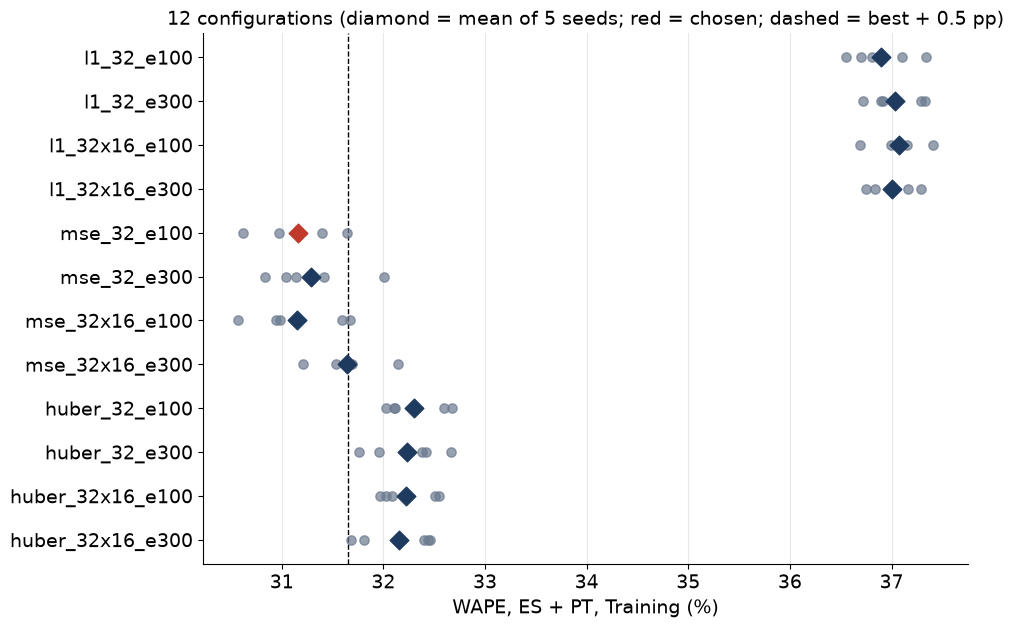

Guardado: evidence_dl_unidades/DLU26.png

--- Mês a mês (ES + PT): previsto contra real, configuração escolhida e provisória (média das 5 sementes) ---


,Month to forecast,Actual (units),Forecast huber_32_e100 (provisional),Error provisional,Forecast mse_32_e100 (chosen),Error chosen
0,Jan 2025,461.380,203.832,"-55,8%",212.324,"-54,0%"
1,Feb 2025,302.468,194.153,"-35,8%",207.511,"-31,4%"
2,Mar 2025,151.321,148.779,"-1,7%",179.938,"18,9%"
3,Apr 2025,135.154,135.278,"0,1%",149.443,"10,6%"
4,May 2025,168.036,143.543,"-14,6%",170.045,"1,2%"
5,Jun 2025,259.624,160.347,"-38,2%",163.317,"-37,1%"
6,Jul 2025,362.588,261.523,"-27,9%",274.640,"-24,3%"


Guardado: evidence_dl_unidades/DLU27.csv

Configuração do cenário A fixada: mse_32_e100 | grupos: weekday, end_of_month, holiday, saldos | corte do nível: True

--- Controlo 1: contagens ---
Linhas de previsão mensal: 840 | esperado: 840 | em falta: 0 | negativas: 0 | bate: True
Controlo 2: a configuração provisória na grelha = a base do ponto 9 (mesmos grupos e sementes): diferença máxima 0.0 (esperado 0)
Controlo 3: só meses de Training: True
Controlo 4: a escolha reproduz-se a partir da tabela DLU25 (menor WAPE, janela de 0,5 pontos, mais simples): True


In [14]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the functions and variables of the previous cells, including SPEC_A and fc9 from point 9, CONFIGS, cfg_name and SEEDS from point 5.
for nome in ['forecast_step', 'to_monthly', 'scorecard', 'SEEDS', 'CONFIGS', 'cfg_name', 'TARGETS', 'MARKETS', 'split_of', 'fmt', 'pct', 'save_table', 'save_fig', 'CFG_G', 'STEPS', 'SPEC_A', 'fc9',
             'monthly', 'EVID']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including the one of point 9), then this one.")

plt.rcParams.update({'font.size': 14})

# ---------- train the grid ----------
t0 = time.time()
fcs, tempos = [], {}
for k, cfg in enumerate(CONFIGS, 1):
    t1 = time.time()
    for seed in SEEDS:
        parts = [forecast_step(m, SPEC_A['groups'], cfg, seed, table=SPEC_A['table'], clip=SPEC_A['clip']) for m in STEPS]
        fcs.append(to_monthly(pd.concat(parts, ignore_index=True), f'{cfg_name(cfg)}||{seed}'))
    tempos[cfg_name(cfg)] = time.time() - t1
    print(f'  {k}/{len(CONFIGS)} {cfg_name(cfg)}: {round(tempos[cfg_name(cfg)] / 60, 1)} min (cumulative {round((time.time() - t0) / 60, 1)} min)')
fc10 = pd.concat(fcs, ignore_index=True)
fc10.to_csv(EVID / 'DLU25_raw_forecasts.csv', index=False)
print(f'Networks trained: {len(CONFIGS) * len(SEEDS) * len(STEPS) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- metrics per configuration and seed ----------
sc10 = scorecard(fc10)
sc10 = sc10[sc10['split'] == 'Training'].copy()
sc10[['config', 'seed']] = sc10['method'].str.split(r'\|\|', expand=True)
sc10['seed'] = sc10['seed'].astype(int)
tot10 = sc10[sc10['mark'] == 'ES + PT'].set_index(['config', 'seed'])
mk10 = sc10[sc10['mark'].isin(MARKETS)].groupby(['config', 'mark'])['WAPE'].mean().unstack()

# ---------- choice by the fixed rule ----------
n_par = lambda c: sum(a * b + b for a, b in zip([len(SPEC_A['groups'])] + list(c['layers']), c['layers'])) + c['layers'][-1] + 1      # approximate parameters: only used to sort by size
stats = pd.DataFrame({'wape': tot10['WAPE'].groupby('config').mean(), 'std': tot10['WAPE'].groupby('config').std(), 'bias': tot10['Bias'].groupby('config').mean()})
stats['params'] = [n_par(next(c for c in CONFIGS if cfg_name(c) == n)) for n in stats.index]
stats['epochs'] = [next(c for c in CONFIGS if cfg_name(c) == n)['epochs'] for n in stats.index]
melhor = stats['wape'].min()
janela = stats[stats['wape'] <= melhor + 0.005].sort_values(['params', 'epochs', 'wape'])
BEST_CFG_NAME = janela.index[0]
BEST_CFG = next(c for c in CONFIGS if cfg_name(c) == BEST_CFG_NAME)
melhor_nome = stats['wape'].idxmin()

# ---------- DLU25: the 12 configurations ----------
rows = []
for c in CONFIGS:
    n = cfg_name(c)
    rows.append({'Configuration': n, 'WAPE mean': pct(stats.loc[n, 'wape']), 'WAPE std (seeds)': pct(stats.loc[n, 'std']), 'Bias mean': pct(stats.loc[n, 'bias']),
                 'WAPE Online ES': pct(mk10.loc[n, MARKETS[0]]), 'WAPE Online PT': pct(mk10.loc[n, MARKETS[1]]), 'Minutes (5 seeds x 7 steps)': round(tempos[n] / 60, 1),
                 'Within 0.5 pp of the best': 'yes' if n in janela.index else '', 'Chosen': 'yes' if n == BEST_CFG_NAME else ''})
dlu25 = pd.DataFrame(rows)
print('\n--- Grid: the 12 configurations (ES + PT, Training, mean of the 5 seeds) ---')
display(dlu25)
save_table(dlu25, 'DLU25', 'Grid of 12 configurations on the base of scenario A (units, Training, 5 seeds)', 'Jan-Jul 2025')
print(f"\nBest mean WAPE: {melhor_nome} ({pct(melhor)}). Configurations within 0,5 points: {', '.join(janela.index)}.")
print(f"By the rule, the choice is: {BEST_CFG_NAME} (the simplest within the window).")

# ---------- chart: WAPE of each configuration, one dot per seed ----------
ordem = [cfg_name(c) for c in CONFIGS]
fig, ax = plt.subplots(figsize=(10, 6.5))
for i, n in enumerate(ordem):
    w = tot10.loc[n]['WAPE'] * 100
    ax.scatter(w.to_numpy(), [i] * len(w), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([w.mean()], [i], color='#c0392b' if n == BEST_CFG_NAME else '#1f3a5f', marker='D', s=90, zorder=4)
ax.set_yticks(range(len(ordem))); ax.set_yticklabels(ordem); ax.invert_yaxis()
ax.axvline((melhor + 0.005) * 100, color='black', lw=1, ls='--')
ax.set_xlabel('WAPE, ES + PT, Training (%)'); ax.set_title('12 configurations (diamond = mean of 5 seeds; red = chosen; dashed = best + 0.5 pp)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU26', 'WAPE of each configuration of the grid, one dot per seed (scenario A, units, Training)', 'Jan-Jul 2025')

# ---------- DLU27: month by month, ES + PT, chosen configuration against the provisional one ----------
act = monthly.set_index(['mark', 'month'])['net_units']
def mensal(df, met):
    return df[df['method'].str.startswith(met + '||')].groupby(['mark', 'month'])['forecast'].mean()
prov = mensal(fc10, cfg_name(CFG_G)); esc = mensal(fc10, BEST_CFG_NAME)
rows = []
for m in STEPS:
    r_ = float(sum(act[(x, m)] for x in MARKETS)); fp = float(sum(prov[(x, m)] for x in MARKETS)); fe = float(sum(esc[(x, m)] for x in MARKETS))
    rows.append({'Month to forecast': m.strftime('%b %Y'), 'Actual (units)': fmt(r_), f'Forecast {cfg_name(CFG_G)} (provisional)': fmt(fp), 'Error provisional': pct((fp - r_) / r_),
                 f'Forecast {BEST_CFG_NAME} (chosen)': fmt(fe), 'Error chosen': pct((fe - r_) / r_)})
dlu27 = pd.DataFrame(rows)
print('\n--- Month by month (ES + PT): forecast against actual, chosen and provisional configuration (mean of the 5 seeds) ---')
display(dlu27)
save_table(dlu27, 'DLU27', 'Month by month, ES + PT: chosen configuration against the provisional one (scenario A, units, Training, mean of 5 seeds)', 'Jan-Jul 2025')

# ---------- what is fixed for the following points ----------
CFG_A = BEST_CFG
print(f"\nScenario A configuration fixed: {BEST_CFG_NAME} | groups: {', '.join(SPEC_A['groups'])} | level clipping: {SPEC_A['clip']}")

# ---------- checks ----------
n_esperado = len(CONFIGS) * len(SEEDS) * len(STEPS) * len(MARKETS)
vazios = int(fc10['forecast'].isna().sum()); neg = int((fc10['forecast'] < 0).sum())
print('\n--- Check 1: counts ---')
print('Monthly forecast rows:', fmt(len(fc10)), '| expected:', fmt(n_esperado), '| missing:', vazios, '| negatives:', neg, '| match:', bool(len(fc10) == n_esperado and vazios == 0 and neg == 0))
a_ = fc10[fc10['method'].str.startswith(cfg_name(CFG_G) + '||')].assign(seed=lambda d: d['method'].str.split(r'\|\|').str[1]).set_index(['seed', 'mark', 'month'])['forecast'].sort_index()
b_ = fc9[fc9['method'].str.startswith('base (4 groups)||')].assign(seed=lambda d: d['method'].str.split(r'\|\|').str[1]).set_index(['seed', 'mark', 'month'])['forecast'].sort_index()
b_ = b_.loc[b_.index.isin(a_.index)]
print('Check 2: the provisional configuration in the grid = the base of point 9 (same groups and seeds): largest difference', float((a_.loc[b_.index] - b_).abs().max()), '(expected 0)')
print('Check 3: only Training months:', bool(set(fc10['month']) == set(STEPS) and all(split_of(m) == 'Training' for m in fc10['month'].unique())))
reprod = stats.assign(dentro=stats['wape'] <= stats['wape'].min() + 0.005).query('dentro').sort_values(['params', 'epochs', 'wape']).index[0]
print('Check 4: the choice is reproduced from table DLU25 (lowest WAPE, window of 0,5 points, simplest):', reprod == BEST_CFG_NAME)

# Efficiency: 12 configurations × 5 seeds × 7 steps × 2 network trainings, each O(E·N·P): time O(C·S·T·E·N·P) with C=12, S=5, T=7, E∈{100,300}; space O(N·V + P) per training; only the monthly forecasts are stored (C·S·T·M rows).

### 10a. Conclusions

**Confirmed (full table, Training):**
- **The loss is the factor that weighs the most.** Squared error (MSE) is at about 31%, Huber at about 32% and absolute error (L1) at about 37%. Within each loss, size and epochs hardly move WAPE (less than 0,5 points).
- The rule chooses **`mse_32_e100`** (MSE, one layer of 32, 100 epochs): four MSE configurations are within 0,5 points of the best (the best on average is `mse_32x16_e100`, by a tiny difference) and this one is the simplest. It is fixed in `CFG_A`.
- Bias stays negative in all configurations, but it is smaller with MSE (about −26%) than with Huber (about −32%) and L1 (about −37%).
- The grid took about 20 minutes, within the estimate.

**Derived:**
- With MSE the network raises the forecast in the peak months and no longer fails by much in March, April and May (errors between +19% and +1%), but it stays far below in January, February, June and July (between −54% and −24%). Underestimation is traded for overestimation in some months, without removing the pattern.
- The difference between MSE and Huber is about 1 point, with some overlap between seeds; between those two and L1 the difference is large and clear.

**To validate:**
- **Hypothesis (not tested):** MSE helps because it penalises large errors more, and the large errors are in the peak months; L1 learns the typical day and underestimates the peaks.
- The choice of variables (points 6 to 9) was made with the provisional configuration (Huber). With MSE the conclusions may change, in particular about the trend (H1) and the level (H2), which made the forecast much worse.
- The definition of units is still to be confirmed with Parfois.

**Decision:** configuration of scenario A fixed (`mse_32_e100`, with the 4 groups). Before moving on, I propose a quick sensitivity check: repeat with MSE the removal of each of the 4 groups and hypotheses H1 and H2 on the base, with the same rules, only to see whether any conclusion from point 6 to 9 flips. After that come scenario C (the advertising spend of the month), the 50/50 average with B3 and, finally, product category, the Test and MLflow.

## 11. Sensitivity check: do the conclusions of points 6 to 9 hold with MSE? (scenario A, Training)

**What we will do:** points 6 to 9 chose the variables with the provisional configuration (Huber). Now, with the fixed configuration (`mse_32_e100`), we repeat on the base of 4 groups: the removal of each group, one at a time, and hypotheses H1 (trend over time) and H2 (level without clipping), plus the diagnostic of level clipping. Each decision is compared with the one made with Huber.

**Goal:** see whether any conclusion flips with the chosen loss, before moving on to scenario C.

**Decisions fixed before seeing results:**
- **The usual rules:** monthly WAPE of ES + PT over the 7 Training months, mean of 5 seeds. A group stays if the base has a lower mean WAPE than the network without it **and** wins in at least 4 of the 5 seeds. A hypothesis enters if its mean WAPE is lower than that of the base **and** it wins in at least 4 of the 5 seeds.
- **What changes the base:** only a hypothesis (H1 or H2) that passes the rule. In that case the one with the lowest mean WAPE stays and the grid is repeated for the new base in a separate point. Removing groups is informative only: the stop rule of point 8 holds and the base of 4 groups loses none.
- **If a group of the base fails the rule now:** it is recorded as a warning and we decide with you, without changing anything on our own.
- **Reference base:** the `mse_32_e100` configuration with the 4 groups, already trained in point 10 (same seeds); it is not trained again.

**Cautions:**
- There are only Training months. The Test stays closed.
- This check does not reopen the groups that left (month of the year, level, campaigns); it only confirms whether what stayed and what was rejected still holds.

**Checks:** 7 variants × 5 seeds × 7 steps × 2 markets; no missing forecast; the base recalculated for one month gives exactly the same forecast as the one from point 10; Training months only.

Redes treinadas: 490 em 3.0 minutos

--- Verificação com o MSE (ES + PT, Training, média das 5 sementes). Nos grupos, mudança positiva = tirar o grupo piora; nas hipóteses, negativa = melhor ---


,Variant,WAPE mean,WAPE std (seeds),Bias mean,WAPE change vs base (pp),Wins (seeds of 5),Decision with MSE,Decision with Huber
0,"base (4 groups, MSE)","31,2%","0,4%","-26,3%",,,reference,
1,without weekday,"32,4%","0,3%","-25,9%","+1,2",5,group stays,group stays
2,without end_of_month,"30,3%","0,2%","-25,9%","-0,9",0,candidate to leave,group stays
3,without holiday,"30,7%","0,3%","-25,3%","-0,5",0,candidate to leave,candidate to leave
4,without saldos,"43,5%","0,3%","-24,9%","+12,3",5,group stays,group stays
5,H1: base + trend,"46,7%","3,3%","12,2%","+15,5",0,does not enter,does not enter
6,H2: base + level (no clip),"55,9%","1,6%","-37,1%","+24,8",0,does not enter,does not enter
7,Diagnostic: base + level (with clip),"47,0%","1,3%","-37,7%","+15,8",0,diagnostic only,diagnostic only


Guardado: evidence_dl_unidades/DLU28.csv

Pela regra, nenhuma hipótese entra: a base e a configuração do cenário A mantêm-se.
Avisos (grupos da base que falham a regra com o MSE e que ficavam com o Huber): without end_of_month
Decisões que mudam entre Huber e MSE: without end_of_month

--- WAPE por mercado (média das 5 sementes) ---


,Variant,WAPE Online ES,WAPE Online PT
0,"base (4 groups, MSE)","31,6%","31,7%"
1,without weekday,"32,5%","33,1%"
2,without end_of_month,"30,9%","30,6%"
3,without holiday,"31,0%","31,2%"
4,without saldos,"42,4%","46,7%"
5,H1: base + trend,"44,9%","52,7%"
6,H2: base + level (no clip),"53,8%","62,2%"
7,Diagnostic: base + level (with clip),"43,9%","55,9%"


Guardado: evidence_dl_unidades/DLU29.csv


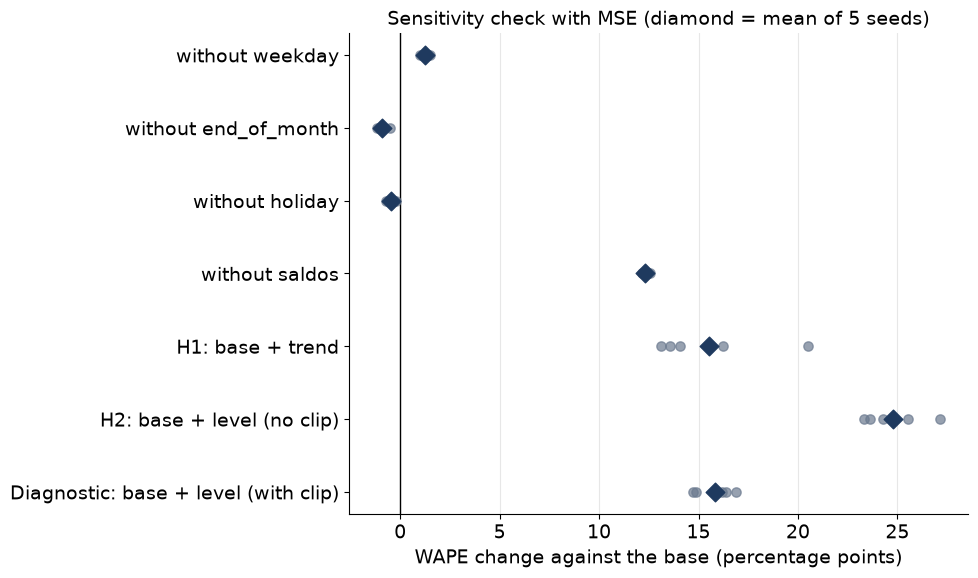

Guardado: evidence_dl_unidades/DLU30.png

--- Controlo 1: contagens ---
Linhas das variantes novas: 490 | esperado: 490 | em falta (todas): 0 | negativas (todas): 0 | bate: True
Controlo 2: recalcular a base em Jul 2025, semente 0: diferença máxima contra a do ponto 10 0.0 (esperado 0)
Controlo 3: só meses de Training: True


In [15]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the variables of the previous cells, including SPEC_A, feat_h, dlu16 and dlu20 (points 8 and 9), fc10, CFG_A and BEST_CFG_NAME (point 10).
for nome in ['forecast_step', 'to_monthly', 'scorecard', 'FEATURE_GROUPS', 'SEEDS', 'MARKETS', 'split_of', 'fmt', 'pct', 'save_table', 'save_fig', 'STEPS', 'SPEC_A', 'feat', 'feat_h', 'dlu16', 'dlu20',
             'fc10', 'CFG_A', 'BEST_CFG_NAME', 'monthly']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including those of points 8 to 10), then this one.")

plt.rcParams.update({'font.size': 14})
BASE_E = 'base (4 groups, MSE)'
G = list(SPEC_A['groups'])

# ---------- variants: the removal of each group and the hypotheses of point 9 ----------
VARIANTS_E = {f'without {g}': dict(groups=[x for x in G if x != g], table=feat_h, clip=True) for g in G}
VARIANTS_E.update({
    'H1: base + trend': dict(groups=G + ['trend'], table=feat_h, clip=True),
    'H2: base + level (no clip)': dict(groups=G + ['level'], table=feat_h, clip=False),
    'Diagnostic: base + level (with clip)': dict(groups=G + ['level'], table=feat_h, clip=True),
})

# ---------- train the variants ----------
t0 = time.time()
fcs = []
for vname, v in VARIANTS_E.items():
    for seed in SEEDS:
        parts = [forecast_step(m, v['groups'], CFG_A, seed, table=v['table'], clip=v['clip']) for m in STEPS]
        fcs.append(to_monthly(pd.concat(parts, ignore_index=True), f'{vname}||{seed}'))
base_fc = fc10[fc10['method'].str.startswith(BEST_CFG_NAME + '||')].copy()                 # the base comes from point 10 (same configuration, groups and seeds)
base_fc['method'] = base_fc['method'].str.replace(BEST_CFG_NAME, BASE_E, regex=False)
fc11 = pd.concat([base_fc] + fcs, ignore_index=True)
print(f'Networks trained: {len(VARIANTS_E) * len(SEEDS) * len(STEPS) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- metrics per variant and seed ----------
sc11 = scorecard(fc11)
sc11 = sc11[sc11['split'] == 'Training'].copy()
sc11[['variant', 'seed']] = sc11['method'].str.split(r'\|\|', expand=True)
sc11['seed'] = sc11['seed'].astype(int)
tot11 = sc11[sc11['mark'] == 'ES + PT'].set_index(['variant', 'seed'])

# Huber decisions, read from the tables of points 8 and 9 (not written by hand)
dec_h = {}
for g in G:
    r = dlu16[dlu16['Variant'] == f'without {g}']
    dec_h[f'without {g}'] = r['Decision'].iloc[0] if len(r) else 'n/a'
for v in ['H1: base + trend', 'H2: base + level (no clip)', 'Diagnostic: base + level (with clip)']:
    dec_h[v] = dlu20[dlu20['Variant'] == v]['Decision'].iloc[0]

# ---------- DLU28: the verification ----------
base_w = tot11.loc[BASE_E]['WAPE'].sort_index()
rows = [{'Variant': BASE_E, 'WAPE mean': pct(base_w.mean()), 'WAPE std (seeds)': pct(base_w.std()), 'Bias mean': pct(tot11.loc[BASE_E]['Bias'].mean()),
         'WAPE change vs base (pp)': '', 'Wins (seeds of 5)': '', 'Decision with MSE': 'reference', 'Decision with Huber': ''}]
entram, delta11, avisos = [], {}, []
for vname in VARIANTS_E:
    w = tot11.loc[vname]['WAPE'].sort_index()
    delta11[vname] = (w.mean() - base_w.mean()) * 100
    if vname.startswith('without'):
        ganha = int((base_w < w).sum())                                              # seeds where the base (with the group) is better
        fica = bool(base_w.mean() < w.mean() and ganha >= 4)
        decisao = 'group stays' if fica else 'candidate to leave'
        if not fica and dec_h[vname] == 'group stays':
            avisos.append(vname)
    else:
        ganha = int((w < base_w).sum())                                              # seeds where the variant is better
        entra = bool(w.mean() < base_w.mean() and ganha >= 4)
        decisao = 'diagnostic only' if vname.startswith('Diag') else ('enters' if entra else 'does not enter')
        if decisao == 'enters':
            entram.append(vname)
    rows.append({'Variant': vname, 'WAPE mean': pct(w.mean()), 'WAPE std (seeds)': pct(w.std()), 'Bias mean': pct(tot11.loc[vname]['Bias'].mean()),
                 'WAPE change vs base (pp)': f"{delta11[vname]:+.1f}".replace('.', ','), 'Wins (seeds of 5)': ganha, 'Decision with MSE': decisao, 'Decision with Huber': dec_h[vname]})
dlu28 = pd.DataFrame(rows)
print('\n--- Verification with MSE (ES + PT, Training, mean of the 5 seeds). For groups, positive change = removing the group makes it worse; for hypotheses, negative = better ---')
display(dlu28)
save_table(dlu28, 'DLU28', 'Sensitivity check with MSE: group removals and hypotheses H1 and H2 on the base of scenario A (units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- what the rule says ----------
SPEC_A_FINAL = dict(SPEC_A)
if entram:
    venc = min(entram, key=lambda n: delta11[n])
    SPEC_A_FINAL = {'groups': list(VARIANTS_E[venc]['groups']), 'table': VARIANTS_E[venc]['table'], 'clip': VARIANTS_E[venc]['clip'], 'name': venc}
    print(f"\nBy the rule, it enters: {venc} (passed: {', '.join(entram)}). The grid has to be repeated for this base in a separate point.")
else:
    print('\nBy the rule, no hypothesis enters: the base and the configuration of scenario A stay.')
print('Warnings (base groups that fail the rule with MSE and that stayed with Huber):', ', '.join(avisos) if avisos else 'none')
same = [(v, dec_h[v]) for v in dlu28['Variant'][1:] if dec_h[v] != dlu28[dlu28['Variant'] == v]['Decision with MSE'].iloc[0]]
print('Decisions that change between Huber and MSE:', ', '.join(f'{v}' for v, _ in same) if same else 'none')

# ---------- DLU29: by market ----------
mk11 = sc11[sc11['mark'].isin(MARKETS)].groupby(['variant', 'mark'])['WAPE'].mean().unstack()
ordem = [BASE_E] + list(VARIANTS_E)
dlu29 = pd.DataFrame({'Variant': ordem, **{f'WAPE {m}': [pct(mk11.loc[v, m]) for v in ordem] for m in MARKETS}})
print('\n--- WAPE by market (mean of the 5 seeds) ---')
display(dlu29)
save_table(dlu29, 'DLU29', 'Sensitivity check with MSE: WAPE by market (scenario A, units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- chart ----------
fig, ax = plt.subplots(figsize=(10, 6))
nomes = list(VARIANTS_E)
for i, vname in enumerate(nomes):
    d = (tot11.loc[vname]['WAPE'].sort_index() - base_w) * 100
    ax.scatter(d.to_numpy(), [i] * len(d), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([d.mean()], [i], color='#1f3a5f', marker='D', s=90, zorder=4)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(range(len(nomes))); ax.set_yticklabels(nomes); ax.invert_yaxis()
ax.set_xlabel('WAPE change against the base (percentage points)'); ax.set_title('Sensitivity check with MSE (diamond = mean of 5 seeds)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU30', 'Sensitivity check with MSE: change in WAPE against the base (scenario A, units, Training)', 'Jan-Jul 2025')

# ---------- checks ----------
n_esperado = len(VARIANTS_E) * len(SEEDS) * len(STEPS) * len(MARKETS)
novas = fc11[~fc11['method'].str.startswith(BASE_E)]
vazios = int(fc11['forecast'].isna().sum()); neg = int((fc11['forecast'] < 0).sum())
print('\n--- Check 1: counts ---')
print('Rows of the new variants:', fmt(len(novas)), '| expected:', fmt(n_esperado), '| missing (all):', vazios, '| negatives (all):', neg, '| match:', bool(len(novas) == n_esperado and vazios == 0 and neg == 0))
m_ref = STEPS[-1]
rep = to_monthly(forecast_step(m_ref, G, CFG_A, SEEDS[0], table=SPEC_A['table'], clip=SPEC_A['clip']), 'x').set_index('mark')['forecast']
guardada = fc11[(fc11['method'] == f'{BASE_E}||{SEEDS[0]}') & (fc11['month'] == m_ref)].set_index('mark')['forecast']
print(f"Check 2: recalculate the base in {m_ref.strftime('%b %Y')}, seed {SEEDS[0]}: largest difference against that of point 10", float((guardada - rep.loc[guardada.index]).abs().max()), '(expected 0)')
print('Check 3: only Training months:', bool(set(fc11['month']) == set(STEPS) and all(split_of(m) == 'Training' for m in fc11['month'].unique())))

# Efficiency: 7 variants × 5 seeds × 7 steps × 2 network trainings, each O(E·N·P): time O(V·S·T·E·N·P) with V=7, S=5, T=7, E=100; space O(N·C + P) per training; only the monthly forecasts are stored.

### 11a. Conclusions

**Confirmed (full table, Training):**
- **No hypothesis enters** with MSE: the trend (H1) and the level without clipping (H2) make WAPE worse by more than 15 and 24 points, lose in all 5 seeds and repeat the Huber conclusion. The base and the configuration of scenario A stay.
- Of the 4 groups of the base, **day of the week** and **sales periods** still stay (sales periods weigh even more: removing them makes things worse by about 12 points, against about 7,5 with Huber).
- **Holidays** still do not meet the rule (as with Huber). **End of the month** now fails it: without it WAPE falls by 0,9 points and the base loses in all 5 seeds. It is the only decision that flips.
- By the rule fixed in point 11, this stays as a **warning** and does not change the base on its own.

**Derived:**
- The level makes the network worse with the MSE loss just as with Huber, and clipping still helps (without clipping WAPE is even worse). This supports the reading from point 9: the problem is the 28-day level itself, not the clipping.
- With MSE the trend no longer corrects the bias; it moves it to the positive side (the network overestimates) and the spread between seeds is much larger than in the other variants.

**To validate:**
- The effect of end of the month and holidays is small (less than 1 point) and comes from 7 Training months. Removing both at the same time was not tested, and the groups have already shown they interact.
- There is still underestimation in all variants (the bias is around −25%).
- The definition of units is still to be confirmed with Parfois.

**Decision:** the base of scenario A stays with 4 groups and the `mse_32_e100` configuration, until we decide with you what to do about the end-of-month warning.

## 12. Scenario C: does the advertising spend of the month help? (Training)

**What we will do:** add to the base of scenario A (day of the week, end of the month, holidays and sales periods, with `mse_32_e100`) the advertising spend of the month to forecast, which the company allowed us to assume as known. Two forms are tested and each is compared with scenario A, over the same months and with the same seeds.

**Goal:** decide whether scenario C is a different network from scenario A or whether, with this information, the result does not improve.

**Decisions fixed before seeing results:**
- **Scenario C (the one from the previous notebooks):** base A plus the spend of the day and the total spend of the month to forecast (the two columns of the advertising group). It is the variant the decision is based on.
- **Sensitivity variant (no decision):** base A plus only the total spend of the month. It shows what is gained if only the monthly total is known and not the split by day.
- **Rule:** scenario C enters if the mean WAPE of ES + PT over the 7 Training months is lower than that of scenario A **and** it wins in at least 4 of the 5 seeds (compared seed by seed). If it does not enter, scenario C uses the network of scenario A.
- **If only the sensitivity variant passes the rule:** it becomes a warning and we decide with you.
- **Same configuration as scenario A** (`mse_32_e100`), same treatment as point 5 (spend clipped to the range seen in training) and the same 5 seeds. The configuration grid for scenario C, if it enters, is done in the next point.
- **Reference:** scenario A already trained in point 10 (same groups, configuration and seeds), which is not trained again.

**Cautions:**
- The spend of the month to forecast is, by construction, information from the future assumed as known. Scenario C answers "what error would we have if the spend of the month were known", not "what error would we have today".
- There are only Training months. The Test stays closed.
- The table of spend against the training range shows where clipping acts.

**Checks:** 2 variants × 5 seeds × 7 steps × 2 markets; no missing forecast; no missing spend in the Training rows and the month to forecast; scenario A recalculated for one month gives exactly the same forecast as the one from point 10; changing the spend of months after the month to forecast does not change the forecast (and changing it inside the month to forecast does, as assumed); Training months only.

Redes treinadas: 140 em 0.9 minutos

--- Cenário C contra o cenário A (ES + PT, Training, média das 5 sementes) ---


,Variant,WAPE mean,WAPE std (seeds),Bias mean,WAPE change vs A (pp; negative = better),Wins vs A (seeds of 5),Decision
0,"scenario A (4 groups, MSE)","31,2%","0,4%","-26,3%",,,reference
1,C: A + spend of day and month,"6,8%","1,6%","2,3%","-24,4",5,enters
2,Sensitivity: A + spend of month only,"12,1%","2,1%","2,1%","-19,0",5,passes the rule (warning)


Guardado: evidence_dl_unidades/DLU31.csv

Pela regra, o cenário C entra: tem rede própria (base A + investimento do dia e do mês). A grelha de configurações do cenário C faz-se no ponto seguinte.

--- WAPE por mercado (média das 5 sementes) ---


,Variant,WAPE Online ES,WAPE Online PT
0,"scenario A (4 groups, MSE)","31,6%","31,7%"
1,C: A + spend of day and month,"5,8%","14,0%"
2,Sensitivity: A + spend of month only,"10,6%","20,5%"


Guardado: evidence_dl_unidades/DLU32.csv


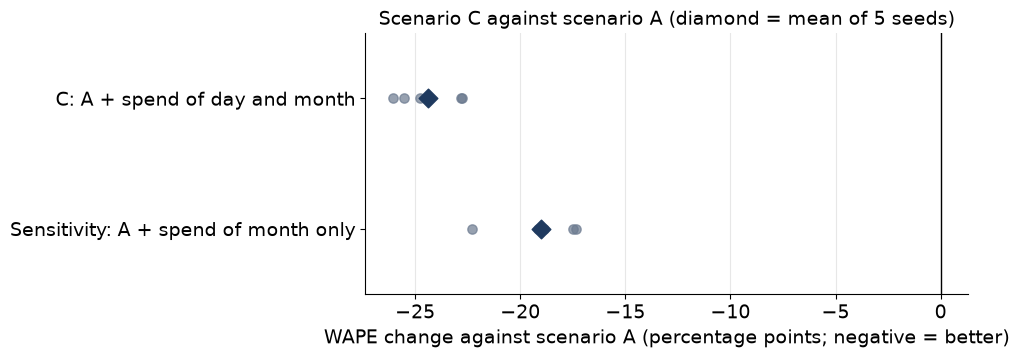

Guardado: evidence_dl_unidades/DLU33.png

--- O investimento do mês a prever contra o intervalo visto no treino ---


,Month to forecast,Market,Spend of the month (EUR),Training min,Training max,Month outside the range,Highest day in the month (EUR),Highest day in training (EUR)
0,Jan 2025,Online ES,232.921,57.710,207.644,above,13.682,39.555
1,Jan 2025,Online PT,79.992,25.699,63.035,above,4.853,11.071
2,Feb 2025,Online ES,147.626,57.710,220.875,no,6.578,39.555
3,Feb 2025,Online PT,52.239,25.699,72.368,no,2.183,11.071
4,Mar 2025,Online ES,127.563,57.710,232.921,no,4.967,39.555
5,Mar 2025,Online PT,37.186,25.699,79.992,no,1.545,11.071
6,Apr 2025,Online ES,131.091,57.710,232.921,no,5.666,39.555
7,Apr 2025,Online PT,41.757,25.699,79.992,no,2.079,11.071
8,May 2025,Online ES,151.711,57.710,232.921,no,5.923,39.555
9,May 2025,Online PT,53.165,25.699,79.992,no,2.032,11.071


Guardado: evidence_dl_unidades/DLU34.csv

--- Mês a mês (ES + PT): previsto contra real, média das 5 sementes ---


,Month to forecast,Actual (units),Forecast A,Error A,Forecast C,Error C,Forecast month only,Error month only
0,Jan 2025,461.380,212.324,"-54,0%",443.827,"-3,8%",399.704,"-13,4%"
1,Feb 2025,302.468,207.511,"-31,4%",282.900,"-6,5%",290.377,"-4,0%"
2,Mar 2025,151.321,179.938,"18,9%",152.034,"0,5%",165.022,"9,1%"
3,Apr 2025,135.154,149.443,"10,6%",153.326,"13,4%",148.551,"9,9%"
4,May 2025,168.036,170.045,"1,2%",178.137,"6,0%",196.007,"16,6%"
5,Jun 2025,259.624,163.317,"-37,1%",258.030,"-0,6%",240.574,"-7,3%"
6,Jul 2025,362.588,274.640,"-24,3%",413.962,"14,2%",438.090,"20,8%"


Guardado: evidence_dl_unidades/DLU35.csv

--- Controlo 1: contagens ---
Linhas das variantes novas: 140 | esperado: 140 | em falta (todas): 0 | negativas (todas): 0 | bate: True
Controlo 2: investimento em falta na tabela (esperado 0): 0
Controlo 3: recalcular o cenário A em Jul 2025, semente 0: diferença máxima contra a do ponto 10 0.0 (esperado 0)
Controlo 4: investimento alterado depois de Jul 2025: diferença máxima 0.0 (esperado 0) | alterado dentro de Jul 2025: diferença máxima 21.864 (esperado > 0, é o que o cenário C assume) | bate: True
Controlo 5: só meses de Training: True


In [17]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the variables of the previous cells, including SPEC_A, fc10, CFG_A and BEST_CFG_NAME (point 10).
for nome in ['forecast_step', 'to_monthly', 'scorecard', 'FEATURE_GROUPS', 'SEEDS', 'MARKETS', 'split_of', 'fmt', 'pct', 'save_table', 'save_fig', 'STEPS', 'SPEC_A', 'feat', 'fc10', 'CFG_A',
             'BEST_CFG_NAME', 'monthly']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including the one of point 10), then this one.")

plt.rcParams.update({'font.size': 14})
BASE_F = 'scenario A (4 groups, MSE)'
G = list(SPEC_A['groups'])
FEATURE_GROUPS['paid_month'] = ['spend_month']                                    # only the total of the month (sensitivity variant)

VARIANTS_F = {
    'C: A + spend of day and month': dict(groups=G + ['paid_C_month_M'], table=feat, clip=True),
    'Sensitivity: A + spend of month only': dict(groups=G + ['paid_month'], table=feat, clip=True),
}
NOME_C = 'C: A + spend of day and month'

# ---------- train the variants ----------
t0 = time.time()
fcs = []
for vname, v in VARIANTS_F.items():
    for seed in SEEDS:
        parts = [forecast_step(m, v['groups'], CFG_A, seed, table=v['table'], clip=v['clip']) for m in STEPS]
        fcs.append(to_monthly(pd.concat(parts, ignore_index=True), f'{vname}||{seed}'))
base_fc = fc10[fc10['method'].str.startswith(BEST_CFG_NAME + '||')].copy()
base_fc['method'] = base_fc['method'].str.replace(BEST_CFG_NAME, BASE_F, regex=False)
fc12 = pd.concat([base_fc] + fcs, ignore_index=True)
print(f'Networks trained: {len(VARIANTS_F) * len(SEEDS) * len(STEPS) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- metrics per variant and seed ----------
sc12 = scorecard(fc12)
sc12 = sc12[sc12['split'] == 'Training'].copy()
sc12[['variant', 'seed']] = sc12['method'].str.split(r'\|\|', expand=True)
sc12['seed'] = sc12['seed'].astype(int)
tot12 = sc12[sc12['mark'] == 'ES + PT'].set_index(['variant', 'seed'])

# ---------- DLU31: scenario C against scenario A ----------
base_w = tot12.loc[BASE_F]['WAPE'].sort_index()
rows = [{'Variant': BASE_F, 'WAPE mean': pct(base_w.mean()), 'WAPE std (seeds)': pct(base_w.std()), 'Bias mean': pct(tot12.loc[BASE_F]['Bias'].mean()),
         'WAPE change vs A (pp; negative = better)': '', 'Wins vs A (seeds of 5)': '', 'Decision': 'reference'}]
delta12, passa = {}, {}
for vname in VARIANTS_F:
    w = tot12.loc[vname]['WAPE'].sort_index()
    ganha = int((w < base_w).sum())
    delta12[vname] = (w.mean() - base_w.mean()) * 100
    passa[vname] = bool(w.mean() < base_w.mean() and ganha >= 4)
    rows.append({'Variant': vname, 'WAPE mean': pct(w.mean()), 'WAPE std (seeds)': pct(w.std()), 'Bias mean': pct(tot12.loc[vname]['Bias'].mean()),
                 'WAPE change vs A (pp; negative = better)': f"{delta12[vname]:+.1f}".replace('.', ','), 'Wins vs A (seeds of 5)': ganha,
                 'Decision': ('enters' if passa[vname] else 'does not enter') if vname == NOME_C else ('passes the rule (warning)' if passa[vname] else 'no decision')})
dlu31 = pd.DataFrame(rows)
print('\n--- Scenario C against scenario A (ES + PT, Training, mean of the 5 seeds) ---')
display(dlu31)
save_table(dlu31, 'DLU31', 'Scenario C (paid media of the month) against scenario A (units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- what the rule says ----------
if passa[NOME_C]:
    SPEC_C = {'groups': list(VARIANTS_F[NOME_C]['groups']), 'table': feat, 'clip': True, 'name': NOME_C}
    print('\nBy the rule, scenario C enters: it has its own network (base A + spend of the day and of the month). The grid of configurations for scenario C is done in the next point.')
else:
    SPEC_C = dict(SPEC_A)
    print('\nBy the rule, scenario C does not enter: it uses the network of scenario A (spend does not improve the forecast).')
if passa['Sensitivity: A + spend of month only'] and not passa[NOME_C]:
    print('Warning: the variant with only the total of the month passes the rule and scenario C does not. We decide with you.')

# ---------- DLU32: by market ----------
mk12 = sc12[sc12['mark'].isin(MARKETS)].groupby(['variant', 'mark'])['WAPE'].mean().unstack()
ordem = [BASE_F] + list(VARIANTS_F)
dlu32 = pd.DataFrame({'Variant': ordem, **{f'WAPE {m}': [pct(mk12.loc[v, m]) for v in ordem] for m in MARKETS}})
print('\n--- WAPE by market (mean of the 5 seeds) ---')
display(dlu32)
save_table(dlu32, 'DLU32', 'Scenario C: WAPE by market (units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- chart ----------
fig, ax = plt.subplots(figsize=(10, 3.8))
nomes = list(VARIANTS_F)
for i, vname in enumerate(nomes):
    d = (tot12.loc[vname]['WAPE'].sort_index() - base_w) * 100
    ax.scatter(d.to_numpy(), [i] * len(d), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([d.mean()], [i], color='#1f3a5f', marker='D', s=90, zorder=4)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(range(len(nomes))); ax.set_yticklabels(nomes); ax.set_ylim(len(nomes) - 0.5, -0.5)
ax.set_xlabel('WAPE change against scenario A (percentage points; negative = better)'); ax.set_title('Scenario C against scenario A (diamond = mean of 5 seeds)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU33', 'Scenario C: change in WAPE against scenario A (units, Training)', 'Jan-Jul 2025')

# ---------- DLU34: the spend of the month to forecast against the range seen in training (is the clipping acting?) ----------
rows = []
for m in STEPS:
    for mk in MARKETS:
        tr = feat[(feat['mark'] == mk) & (feat['month'] <= m - 2)]
        gm = feat[(feat['mark'] == mk) & (feat['month'] == m)]
        sm, lo, hi = float(gm['spend_month'].iloc[0]), float(tr['spend_month'].min()), float(tr['spend_month'].max())
        sd_max, sd_hi = float(gm['spend_day'].max()), float(tr['spend_day'].max())
        rows.append({'Month to forecast': m.strftime('%b %Y'), 'Market': mk, 'Spend of the month (EUR)': fmt(sm), 'Training min': fmt(lo), 'Training max': fmt(hi),
                     'Month outside the range': 'above' if sm > hi else ('below' if sm < lo else 'no'), 'Highest day in the month (EUR)': fmt(sd_max), 'Highest day in training (EUR)': fmt(sd_hi)})
dlu34 = pd.DataFrame(rows)
print('\n--- The spend of the month to forecast against the range seen in training ---')
display(dlu34)
save_table(dlu34, 'DLU34', 'Paid media of the month to forecast against the range seen in training, by month and market', 'Jan-Jul 2025')

# ---------- DLU35: month by month, ES + PT, scenario A against scenario C ----------
act = monthly.set_index(['mark', 'month'])['net_units']
def mensal(met):
    return fc12[fc12['method'].str.startswith(met + '||')].groupby(['mark', 'month'])['forecast'].mean()
cmp = {'A': mensal(BASE_F), 'C': mensal(NOME_C), 'month only': mensal('Sensitivity: A + spend of month only')}
rows = []
for m in STEPS:
    r_ = float(sum(act[(x, m)] for x in MARKETS))
    row = {'Month to forecast': m.strftime('%b %Y'), 'Actual (units)': fmt(r_)}
    for k, s in cmp.items():
        f_ = float(sum(s[(x, m)] for x in MARKETS))
        row[f'Forecast {k}'] = fmt(f_); row[f'Error {k}'] = pct((f_ - r_) / r_)
    rows.append(row)
dlu35 = pd.DataFrame(rows)
print('\n--- Month by month (ES + PT): forecast against actual, mean of the 5 seeds ---')
display(dlu35)
save_table(dlu35, 'DLU35', 'Month by month, ES + PT: forecast against actual, scenarios A and C (units, Training, mean of 5 seeds)', 'Jan-Jul 2025')

# ---------- checks ----------
n_esperado = len(VARIANTS_F) * len(SEEDS) * len(STEPS) * len(MARKETS)
novas = fc12[~fc12['method'].str.startswith(BASE_F)]
vazios = int(fc12['forecast'].isna().sum()); neg = int((fc12['forecast'] < 0).sum())
print('\n--- Check 1: counts ---')
print('Rows of the new variants:', fmt(len(novas)), '| expected:', fmt(n_esperado), '| missing (all):', vazios, '| negatives (all):', neg, '| match:', bool(len(novas) == n_esperado and vazios == 0 and neg == 0))
sem_inv = int(feat[['spend_day', 'spend_month']].isna().sum().sum())
print('Check 2: spend missing in the table (expected 0):', sem_inv)
m_ref = STEPS[-1]
rep = to_monthly(forecast_step(m_ref, G, CFG_A, SEEDS[0], table=SPEC_A['table'], clip=SPEC_A['clip']), 'x').set_index('mark')['forecast']
guardada = fc12[(fc12['method'] == f'{BASE_F}||{SEEDS[0]}') & (fc12['month'] == m_ref)].set_index('mark')['forecast']
print(f"Check 3: recalculate scenario A in {m_ref.strftime('%b %Y')}, seed {SEEDS[0]}: largest difference against that of point 10", float((guardada - rep.loc[guardada.index]).abs().max()), '(expected 0)')
# spend after the month to forecast does not count; that of the month itself does (it is the assumed hypothesis)
gC = VARIANTS_F[NOME_C]['groups']
f0 = forecast_step(m_ref, gC, CFG_A, SEEDS[0], table=feat)
t_dep = feat.copy(); aft = t_dep['month'] > m_ref
t_dep.loc[aft, ['spend_day', 'spend_month']] = t_dep.loc[aft, ['spend_day', 'spend_month']] * 3          # months after July 2025 (after the month to forecast)
t_in = feat.copy(); inm = t_in['month'] == m_ref
t_in.loc[inm, ['spend_day', 'spend_month']] = t_in.loc[inm, ['spend_day', 'spend_month']] * 3             # within the month to forecast
f_dep = forecast_step(m_ref, gC, CFG_A, SEEDS[0], table=t_dep)
f_in = forecast_step(m_ref, gC, CFG_A, SEEDS[0], table=t_in)
d_dep = float(np.abs(f0['forecast'].to_numpy() - f_dep['forecast'].to_numpy()).max()); d_in = float(np.abs(f0['forecast'].to_numpy() - f_in['forecast'].to_numpy()).max())
print(f"Check 4: spend changed after {m_ref.strftime('%b %Y')}: largest difference {d_dep} (expected 0) | changed within {m_ref.strftime('%b %Y')}: largest difference {fmt(d_in)} (expected > 0, it is what scenario C assumes) | match:",
      bool(d_dep == 0 and d_in > 0))
print('Check 5: only Training months:', bool(set(fc12['month']) == set(STEPS) and all(split_of(m) == 'Training' for m in fc12['month'].unique())))

# Efficiency: 2 variants × 5 seeds × 7 steps × 2 network trainings, each O(E·N·P): time O(V·S·T·E·N·P) with V=2, S=5, T=7, E=100; space O(N·C + P) per training; only the monthly forecasts are stored.

### 12a. Conclusions

**Confirmed (full table, Training):**
- **Scenario C enters**, by a wide margin: mean WAPE falls from about 31% (scenario A) to about 7%, and it wins in all 5 seeds. The difference is much larger than the spread between seeds. Bias goes from about −26% to close to 0 (slightly positive).
- Scenario C has its own network: base A plus the spend of the day and of the month (`SPEC_C`).
- The variant with only the **total of the month** also passes the rule (about 12%, in all 5 seeds), so most of the gain comes from the monthly total and daily spend improves it further. Since scenario C entered, this variant raises no warning.
- Both markets improve, ES more than PT. Spend clipping only acted in January 2025 (the total of the month was above the maximum seen in training, in both markets).

**Derived:**
- Month by month, scenario C is off by a few points in January, February, March and June, and overestimates in April and July (about +13% to +14%). The systematic underestimation of scenario A disappears.
- The variant with only the monthly total errs more per month (from −13% to +21%).

**To validate:**
- This result is an **upper limit**: scenario C assumes the spend of the month to forecast is known at the cutoff. That is information from the future, which the company allowed us to assume. We still need to know **at what level Parfois knows the spend on that date** (only the monthly total, or also the split by day). The variant with only the monthly total is the more prudent reading.
- **Hypothesis (not tested):** part of the gain comes from spend following demand (more spend on campaign and peak days), not from causing sales. The model does not tell the two apart.
- The groups of the base were chosen in scenario A. With spend in the network, some (for example, sales periods) may become redundant; this was not tested.
- The definition of units is still to be confirmed with Parfois.

**Decision:** scenario C uses base A plus the spend of the day and of the month. In the next point we run the configuration grid for scenario C (12 configurations, with the rule from point 10) and then a quick check of the groups inside scenario C.

## 13. Configuration grid in scenario C (Training)

**What we will do:** train the network of scenario C (base A plus the spend of the day and of the month) with the 12 configurations of the grid from point 5, 5 seeds each, over the 7 Training months, and choose the best one by the same rule as point 10.

**Goal:** fix the configuration of the network of scenario C. With spend in the network, the best loss or the best size may not be those of scenario A.

**Decisions fixed before seeing results:**
- **Grid and fixed parameters:** those from point 5, unchanged.
- **Decision metric:** monthly WAPE of ES + PT over the 7 Training months, mean of the 5 seeds.
- **Choice rule (the one from point 10):** the configuration with the lowest mean WAPE stays. If there are others within **0,5 points** of it, choose the simplest among all of them (fewer parameters, then fewer epochs, and lastly the lowest mean WAPE). The window of 0,5 points is kept in absolute value, as in scenario A, even though the WAPE of scenario C is much lower.
- **Bias, WAPE by market and spread between seeds** are supporting evidence and do not decide.
- The configuration of scenario A (`mse_32_e100`) is one of the 12 and its result has to match that of point 12.

**Cautions:**
- It is the slowest cell, like the one in point 10: expect about 20 minutes (the one in point 10 took 20,5), and it may take longer. The cell prints progress and saves the forecasts to a file at the end.
- There are only Training months. The Test stays closed.
- Scenario C assumes the spend of the month is known; the result of this grid is an upper limit of what can be achieved with that information.

**Checks:** 12 configurations × 5 seeds × 7 steps × 2 markets; no missing forecast; the result of the scenario A configuration matches exactly that of point 12; Training months only; the choice can be reproduced from the table.

  1/12 l1_32_e100: 0.5 min (acumulado 0.5 min)
  2/12 l1_32_e300: 2.0 min (acumulado 2.5 min)
  3/12 l1_32x16_e100: 1.2 min (acumulado 3.7 min)
  4/12 l1_32x16_e300: 3.4 min (acumulado 7.2 min)
  5/12 mse_32_e100: 0.9 min (acumulado 8.0 min)
  6/12 mse_32_e300: 2.7 min (acumulado 10.7 min)
  7/12 mse_32x16_e100: 1.1 min (acumulado 11.8 min)
  8/12 mse_32x16_e300: 3.4 min (acumulado 15.2 min)
  9/12 huber_32_e100: 0.9 min (acumulado 16.1 min)
  10/12 huber_32_e300: 2.8 min (acumulado 18.9 min)
  11/12 huber_32x16_e100: 1.1 min (acumulado 20.0 min)
  12/12 huber_32x16_e300: 3.5 min (acumulado 23.5 min)
Redes treinadas: 840 em 23.5 minutos

--- Grelha do cenário C: as 12 configurações (ES + PT, Training, média das 5 sementes) ---


,Configuration,WAPE mean,WAPE std (seeds),Bias mean,WAPE Online ES,WAPE Online PT,Minutes (5 seeds x 7 steps),Within 0.5 pp of the best,Chosen
0,l1_32_e100,"14,1%","0,9%","-11,9%","12,8%","17,9%",0.5,,
1,l1_32_e300,"13,7%","1,0%","-11,2%","12,7%","16,6%",2.0,,
2,l1_32x16_e100,"13,9%","1,0%","-11,6%","13,4%","15,4%",1.2,,
3,l1_32x16_e300,"8,3%","3,5%","-4,9%","8,3%","10,9%",3.4,,
4,mse_32_e100,"6,8%","1,6%","2,3%","5,8%","14,0%",0.9,,
5,mse_32_e300,"7,2%","1,2%","4,9%","6,4%","14,1%",2.7,,
6,mse_32x16_e100,"5,7%","1,5%","3,2%","5,7%","13,5%",1.1,yes,
7,mse_32x16_e300,"5,7%","1,3%","3,0%","5,6%","12,1%",3.4,yes,
8,huber_32_e100,"9,2%","0,7%","-4,2%","7,7%","14,6%",0.9,,
9,huber_32_e300,"5,3%","0,8%","1,4%","5,8%","10,9%",2.8,yes,yes


Guardado: evidence_dl_unidades/DLU36.csv

Melhor WAPE médio: huber_32_e300 (5,3%). Configurações a menos de 0,5 pontos: huber_32_e300, mse_32x16_e100, mse_32x16_e300.
Pela regra, escolhe-se: huber_32_e300 (a mais simples dentro da janela).


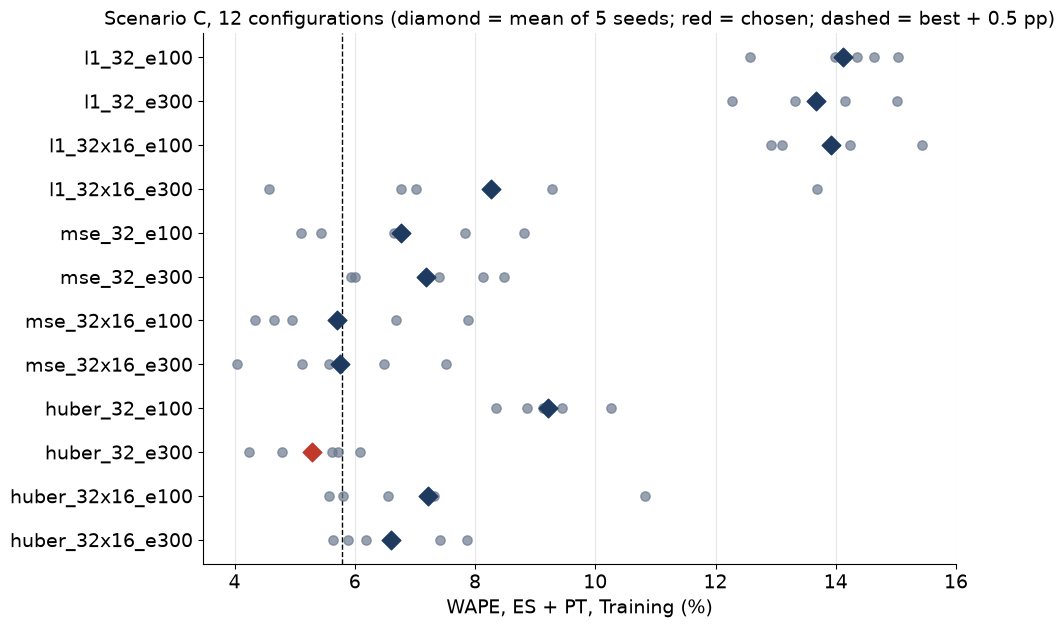

Guardado: evidence_dl_unidades/DLU37.png

--- Mês a mês (ES + PT): previsto contra real, configuração escolhida e a do cenário A (média das 5 sementes) ---


,Month to forecast,Actual (units),Forecast mse_32_e100 (scenario A config),Error A config,Forecast huber_32_e300 (chosen),Error chosen
0,Jan 2025,461.380,443.827,"-3,8%",470.767,"2,0%"
1,Feb 2025,302.468,282.900,"-6,5%",297.632,"-1,6%"
2,Mar 2025,151.321,152.034,"0,5%",147.922,"-2,2%"
3,Apr 2025,135.154,153.326,"13,4%",143.431,"6,1%"
4,May 2025,168.036,178.137,"6,0%",158.192,"-5,9%"
5,Jun 2025,259.624,258.030,"-0,6%",245.937,"-5,3%"
6,Jul 2025,362.588,413.962,"14,2%",402.598,"11,0%"


Guardado: evidence_dl_unidades/DLU38.csv

Configuração do cenário C fixada: huber_32_e300 | grupos: weekday, end_of_month, holiday, saldos, paid_C_month_M | corte do investimento: True

--- Controlo 1: contagens ---
Linhas de previsão mensal: 840 | esperado: 840 | em falta: 0 | negativas: 0 | bate: True
Controlo 2: a configuração do cenário A na grelha = o cenário C do ponto 12 (mesmos grupos e sementes): diferença máxima 0.0 (esperado 0)
Controlo 3: só meses de Training: True
Controlo 4: a escolha reproduz-se a partir da tabela DLU36 (menor WAPE, janela de 0,5 pontos, mais simples): True


In [18]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the variables of the previous cells, including SPEC_C and fc12 from point 12, CFG_A from point 10, CONFIGS, cfg_name and SEEDS from point 5.
for nome in ['forecast_step', 'to_monthly', 'scorecard', 'SEEDS', 'CONFIGS', 'cfg_name', 'TARGETS', 'MARKETS', 'split_of', 'fmt', 'pct', 'save_table', 'save_fig', 'CFG_A', 'STEPS', 'SPEC_C', 'fc12',
             'monthly', 'EVID', 'FEATURE_GROUPS']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including the one of point 12), then this one.")

plt.rcParams.update({'font.size': 14})
NOME_C = 'C: A + spend of day and month'
if SPEC_C['name'] != NOME_C:
    raise RuntimeError('Scenario C did not enter in point 12; this grid is only done if it did.')

# ---------- train the grid ----------
t0 = time.time()
fcs, tempos = [], {}
for k, cfg in enumerate(CONFIGS, 1):
    t1 = time.time()
    for seed in SEEDS:
        parts = [forecast_step(m, SPEC_C['groups'], cfg, seed, table=SPEC_C['table'], clip=SPEC_C['clip']) for m in STEPS]
        fcs.append(to_monthly(pd.concat(parts, ignore_index=True), f'{cfg_name(cfg)}||{seed}'))
    tempos[cfg_name(cfg)] = time.time() - t1
    print(f'  {k}/{len(CONFIGS)} {cfg_name(cfg)}: {round(tempos[cfg_name(cfg)] / 60, 1)} min (cumulative {round((time.time() - t0) / 60, 1)} min)')
fc13 = pd.concat(fcs, ignore_index=True)
fc13.to_csv(EVID / 'DLU36_raw_forecasts.csv', index=False)
print(f'Networks trained: {len(CONFIGS) * len(SEEDS) * len(STEPS) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- metrics per configuration and seed ----------
sc13 = scorecard(fc13)
sc13 = sc13[sc13['split'] == 'Training'].copy()
sc13[['config', 'seed']] = sc13['method'].str.split(r'\|\|', expand=True)
sc13['seed'] = sc13['seed'].astype(int)
tot13 = sc13[sc13['mark'] == 'ES + PT'].set_index(['config', 'seed'])
mk13 = sc13[sc13['mark'].isin(MARKETS)].groupby(['config', 'mark'])['WAPE'].mean().unstack()

# ---------- choice by the fixed rule ----------
n_in = sum(len(FEATURE_GROUPS[g]) for g in SPEC_C['groups'])                       # input columns of scenario C
n_par = lambda c: sum(a * b + b for a, b in zip([n_in] + list(c['layers']), c['layers'])) + c['layers'][-1] + 1      # approximate parameters: only used to sort by size
cfg_by = {cfg_name(c): c for c in CONFIGS}
stats = pd.DataFrame({'wape': tot13['WAPE'].groupby('config').mean(), 'std': tot13['WAPE'].groupby('config').std(), 'bias': tot13['Bias'].groupby('config').mean()})
stats['params'] = [n_par(cfg_by[n]) for n in stats.index]
stats['epochs'] = [cfg_by[n]['epochs'] for n in stats.index]
melhor = stats['wape'].min()
janela = stats[stats['wape'] <= melhor + 0.005].sort_values(['params', 'epochs', 'wape'])
BEST_CFG_C_NAME = janela.index[0]
CFG_C = cfg_by[BEST_CFG_C_NAME]
melhor_nome = stats['wape'].idxmin()

# ---------- DLU36: the 12 configurations ----------
rows = []
for c in CONFIGS:
    n = cfg_name(c)
    rows.append({'Configuration': n, 'WAPE mean': pct(stats.loc[n, 'wape']), 'WAPE std (seeds)': pct(stats.loc[n, 'std']), 'Bias mean': pct(stats.loc[n, 'bias']),
                 'WAPE Online ES': pct(mk13.loc[n, MARKETS[0]]), 'WAPE Online PT': pct(mk13.loc[n, MARKETS[1]]), 'Minutes (5 seeds x 7 steps)': round(tempos[n] / 60, 1),
                 'Within 0.5 pp of the best': 'yes' if n in janela.index else '', 'Chosen': 'yes' if n == BEST_CFG_C_NAME else ''})
dlu36 = pd.DataFrame(rows)
print('\n--- Scenario C grid: the 12 configurations (ES + PT, Training, mean of the 5 seeds) ---')
display(dlu36)
save_table(dlu36, 'DLU36', 'Grid of 12 configurations on scenario C (units, Training, 5 seeds)', 'Jan-Jul 2025')
print(f"\nBest mean WAPE: {melhor_nome} ({pct(melhor)}). Configurations within 0,5 points: {', '.join(janela.index)}.")
print(f"By the rule, the choice is: {BEST_CFG_C_NAME} (the simplest within the window).")

# ---------- chart: WAPE of each configuration, one dot per seed ----------
ordem = [cfg_name(c) for c in CONFIGS]
fig, ax = plt.subplots(figsize=(10, 6.5))
for i, n in enumerate(ordem):
    w = tot13.loc[n]['WAPE'] * 100
    ax.scatter(w.to_numpy(), [i] * len(w), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([w.mean()], [i], color='#c0392b' if n == BEST_CFG_C_NAME else '#1f3a5f', marker='D', s=90, zorder=4)
ax.set_yticks(range(len(ordem))); ax.set_yticklabels(ordem); ax.invert_yaxis()
ax.axvline((melhor + 0.005) * 100, color='black', lw=1, ls='--')
ax.set_xlabel('WAPE, ES + PT, Training (%)'); ax.set_title('Scenario C, 12 configurations (diamond = mean of 5 seeds; red = chosen; dashed = best + 0.5 pp)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU37', 'Scenario C: WAPE of each configuration of the grid, one dot per seed (units, Training)', 'Jan-Jul 2025')

# ---------- DLU38: month by month, ES + PT, chosen configuration against that of scenario A ----------
act = monthly.set_index(['mark', 'month'])['net_units']
def mensal(df, met):
    return df[df['method'].str.startswith(met + '||')].groupby(['mark', 'month'])['forecast'].mean()
refA = mensal(fc13, cfg_name(CFG_A)); esc = mensal(fc13, BEST_CFG_C_NAME)
rows = []
for m in STEPS:
    r_ = float(sum(act[(x, m)] for x in MARKETS)); fa = float(sum(refA[(x, m)] for x in MARKETS)); fe = float(sum(esc[(x, m)] for x in MARKETS))
    rows.append({'Month to forecast': m.strftime('%b %Y'), 'Actual (units)': fmt(r_), f'Forecast {cfg_name(CFG_A)} (scenario A config)': fmt(fa), 'Error A config': pct((fa - r_) / r_),
                 f'Forecast {BEST_CFG_C_NAME} (chosen)': fmt(fe), 'Error chosen': pct((fe - r_) / r_)})
dlu38 = pd.DataFrame(rows)
print('\n--- Month by month (ES + PT): forecast against actual, chosen configuration and that of scenario A (mean of the 5 seeds) ---')
display(dlu38)
save_table(dlu38, 'DLU38', 'Month by month, ES + PT, scenario C: chosen configuration against the scenario A one (units, Training, mean of 5 seeds)', 'Jan-Jul 2025')

# ---------- what is fixed for the following points ----------
print(f"\nScenario C configuration fixed: {BEST_CFG_C_NAME} | groups: {', '.join(SPEC_C['groups'])} | spend clipping: {SPEC_C['clip']}")

# ---------- checks ----------
n_esperado = len(CONFIGS) * len(SEEDS) * len(STEPS) * len(MARKETS)
vazios = int(fc13['forecast'].isna().sum()); neg = int((fc13['forecast'] < 0).sum())
print('\n--- Check 1: counts ---')
print('Monthly forecast rows:', fmt(len(fc13)), '| expected:', fmt(n_esperado), '| missing:', vazios, '| negatives:', neg, '| match:', bool(len(fc13) == n_esperado and vazios == 0 and neg == 0))
a_ = fc13[fc13['method'].str.startswith(cfg_name(CFG_A) + '||')].assign(seed=lambda d: d['method'].str.split(r'\|\|').str[1]).set_index(['seed', 'mark', 'month'])['forecast'].sort_index()
b_ = fc12[fc12['method'].str.startswith(NOME_C + '||')].assign(seed=lambda d: d['method'].str.split(r'\|\|').str[1]).set_index(['seed', 'mark', 'month'])['forecast'].sort_index()
b_ = b_.loc[b_.index.isin(a_.index)]
print('Check 2: the scenario A configuration in the grid = scenario C of point 12 (same groups and seeds): largest difference', float((a_.loc[b_.index] - b_).abs().max()), '(expected 0)')
print('Check 3: only Training months:', bool(set(fc13['month']) == set(STEPS) and all(split_of(m) == 'Training' for m in fc13['month'].unique())))
reprod = stats.assign(dentro=stats['wape'] <= stats['wape'].min() + 0.005).query('dentro').sort_values(['params', 'epochs', 'wape']).index[0]
print('Check 4: the choice is reproduced from table DLU36 (lowest WAPE, window of 0,5 points, simplest):', reprod == BEST_CFG_C_NAME)

# Efficiency: 12 configurations × 5 seeds × 7 steps × 2 network trainings, each O(E·N·P): time O(C·S·T·E·N·P) with C=12, S=5, T=7, E∈{100,300}; space O(N·V + P) per training; only the monthly forecasts are stored (C·S·T·M rows).

### 13a. Conclusions

**Confirmed (full table, Training):**
- The rule chooses **`huber_32_e300`** (Huber, one layer of 32, 300 epochs) for scenario C: it has the lowest mean WAPE (about 5,3%) and, of the three within 0,5 points of the best, it is the simplest (the other two have two layers). It is fixed in `CFG_C`.
- With spend in the network, the best loss is no longer that of scenario A: Huber and MSE are close, and absolute error (L1) is clearly worse, except for one two-layer configuration with a large spread between seeds.
- The bias of the chosen configuration is small and positive (about +1,4%), without the underestimation of scenario A.
- The grid took about 23,5 minutes, within the estimate.

**Derived:**
- Against the configuration of scenario A applied to scenario C (`mse_32_e100`, about 6,8%), the chosen one gains about 1,5 points. In April and July the overestimation decreases, in January and February the error is below 2%, and in June and May there is now a slight underestimation.
- July (about +11%) and April (about +6%) remain the months where the network overestimates the most.

**To validate:**
- The top configurations are separated by 0,5 to 1,5 points, and the spread between seeds of each one is 1 to 2 points. The choice between them is partly noise; the fixed rule is there to decide without picking the best by luck.
- The groups of the base were chosen in scenario A; with spend in the network some may no longer be needed. This still has to be checked.
- The result assumes the spend of the day and of the month is known at the cutoff, and we still have to confirm with Parfois at what level they know it.
- The definition of units is still to be confirmed with Parfois.

**Decision:** configuration of scenario C fixed (`huber_32_e300`, with base A and the spend of the day and of the month). In the next point we do the quick check of the groups inside scenario C (removing each one, with the usual rule, as information only), and then the 50/50 average with B3 and the category variant.

## 14. Check of the groups inside scenario C (Training)

**What we will do:** with the configuration of scenario C (`huber_32_e300`), remove the 4 calendar groups of the base (day of the week, end of the month, holidays and sales periods) one at a time and see whether they are still justified with the spend of the month in the network. Spend always stays.

**Goal:** find out whether any group chosen in scenario A becomes redundant when the network already knows the spend.

**Decisions fixed before seeing results:**
- **The usual rules:** monthly WAPE of ES + PT over the 7 Training months, mean of 5 seeds. A group stays if the network of scenario C has a lower mean WAPE than the network without it **and** wins in at least 4 of the 5 seeds (compared seed by seed).
- **The check is informative only:** the network of scenario C does not change on its own. A group that fails the rule becomes a warning and we decide with you (as in point 11).
- **Reference:** scenario C with `huber_32_e300` already trained in point 13 (same groups and seeds); it is not trained again.
- **We do not reopen** the groups that left in scenario A (month of the year, level, campaigns), nor hypotheses H1 and H2.
- The table compares each decision with the one made in scenario A with MSE (point 11).

**Cautions:**
- This cell trains networks of 300 epochs: expect 10 to 15 minutes (4 variants, each like one row of the grid from point 13, which took between 2,8 and 3,5 minutes). The cell prints progress.
- The WAPE of scenario C is low (about 5%) and the spread between seeds is 1 to 2 points: small differences are noise, and that is what the 4-in-5 rule is for.
- There are only Training months. The Test stays closed.

**Checks:** 4 variants × 5 seeds × 7 steps × 2 markets; no missing forecast; scenario C recalculated for one month gives exactly the same forecast as the one from point 13; Training months only.

  1/4 without weekday: 2.8 min (acumulado 2.8 min)
  2/4 without end_of_month: 3.0 min (acumulado 5.8 min)
  3/4 without holiday: 2.9 min (acumulado 8.7 min)
  4/4 without saldos: 1.3 min (acumulado 10.0 min)
Redes treinadas: 280 em 10.0 minutos

--- Grupos dentro do cenário C (ES + PT, Training, média das 5 sementes; mudança positiva = tirar o grupo piora) ---


,Variant,WAPE mean,WAPE std (seeds),Bias mean,WAPE change vs C (pp),C wins (seeds of 5),Decision in scenario C,Decision in scenario A (MSE)
0,scenario C (A groups + spend),"5,3%","0,8%","1,4%",,,reference,
1,without weekday,"10,9%","1,3%","-6,4%","+5,6",5,group stays,group stays
2,without end_of_month,"6,7%","1,3%","-1,0%","+1,4",4,group stays,candidate to leave
3,without holiday,"7,3%","1,4%","3,5%","+2,0",4,group stays,candidate to leave
4,without saldos,"24,4%","1,2%","-9,9%","+19,1",5,group stays,group stays


Guardado: evidence_dl_unidades/DLU39.csv

Avisos (grupos que falham a regra no cenário C): nenhum
Decisões que mudam entre o cenário A (MSE) e o cenário C: end_of_month, holiday
A rede do cenário C não muda sozinha: SPEC_C e CFG_C ficam como estão.

--- WAPE por mercado (média das 5 sementes) ---


,Variant,WAPE Online ES,WAPE Online PT
0,scenario C (A groups + spend),"5,8%","10,9%"
1,without weekday,"9,8%","15,0%"
2,without end_of_month,"5,8%","13,7%"
3,without holiday,"7,7%","12,1%"
4,without saldos,"26,7%","20,2%"


Guardado: evidence_dl_unidades/DLU40.csv


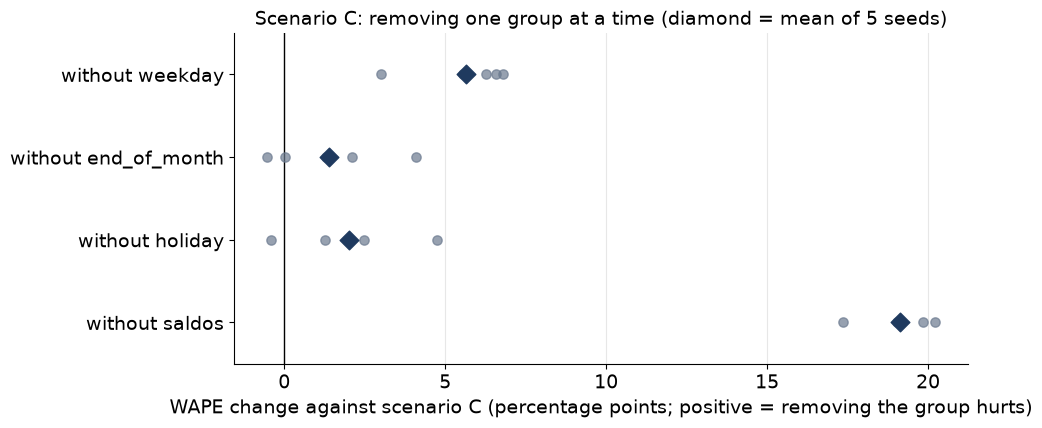

Guardado: evidence_dl_unidades/DLU41.png

--- Controlo 1: contagens ---
Linhas das variantes novas: 280 | esperado: 280 | em falta (todas): 0 | negativas (todas): 0 | bate: True
Controlo 2: recalcular o cenário C em Jul 2025, semente 0: diferença máxima contra a do ponto 13 0.0 (esperado 0)
Controlo 3: só meses de Training: True


In [19]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the variables of the previous cells, including SPEC_C (point 12), fc13, CFG_C and BEST_CFG_C_NAME (point 13) and dlu28 (point 11).
for nome in ['forecast_step', 'to_monthly', 'scorecard', 'SEEDS', 'MARKETS', 'split_of', 'fmt', 'pct', 'save_table', 'save_fig', 'STEPS', 'SPEC_C', 'SPEC_A', 'fc13', 'CFG_C', 'BEST_CFG_C_NAME', 'dlu28',
             'monthly']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including that of point 13), then this one.")

plt.rcParams.update({'font.size': 14})
BASE_G = 'scenario C (A groups + spend)'
G = list(SPEC_A['groups'])                                                        # the 4 calendar groups
PAID = [g for g in SPEC_C['groups'] if g not in G]                                # the spend group (always stays)
VARIANTS_G = {f'without {g}': dict(groups=[x for x in SPEC_C['groups'] if x != g], table=SPEC_C['table'], clip=SPEC_C['clip']) for g in G}

# ---------- train the variants ----------
t0 = time.time()
fcs = []
for k, (vname, v) in enumerate(VARIANTS_G.items(), 1):
    t1 = time.time()
    for seed in SEEDS:
        parts = [forecast_step(m, v['groups'], CFG_C, seed, table=v['table'], clip=v['clip']) for m in STEPS]
        fcs.append(to_monthly(pd.concat(parts, ignore_index=True), f'{vname}||{seed}'))
    print(f'  {k}/{len(VARIANTS_G)} {vname}: {round((time.time() - t1) / 60, 1)} min (cumulative {round((time.time() - t0) / 60, 1)} min)')
base_fc = fc13[fc13['method'].str.startswith(BEST_CFG_C_NAME + '||')].copy()               # the base comes from point 13 (same configuration, groups and seeds)
base_fc['method'] = base_fc['method'].str.replace(BEST_CFG_C_NAME, BASE_G, regex=False)
fc14 = pd.concat([base_fc] + fcs, ignore_index=True)
print(f'Networks trained: {len(VARIANTS_G) * len(SEEDS) * len(STEPS) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- metrics per variant and seed ----------
sc14 = scorecard(fc14)
sc14 = sc14[sc14['split'] == 'Training'].copy()
sc14[['variant', 'seed']] = sc14['method'].str.split(r'\|\|', expand=True)
sc14['seed'] = sc14['seed'].astype(int)
tot14 = sc14[sc14['mark'] == 'ES + PT'].set_index(['variant', 'seed'])

# ---------- DLU39: each group, with and without, in scenario C ----------
base_w = tot14.loc[BASE_G]['WAPE'].sort_index()
rows = [{'Variant': BASE_G, 'WAPE mean': pct(base_w.mean()), 'WAPE std (seeds)': pct(base_w.std()), 'Bias mean': pct(tot14.loc[BASE_G]['Bias'].mean()),
         'WAPE change vs C (pp)': '', 'C wins (seeds of 5)': '', 'Decision in scenario C': 'reference', 'Decision in scenario A (MSE)': ''}]
delta14, avisos = {}, []
for g in G:
    v = f'without {g}'
    w = tot14.loc[v]['WAPE'].sort_index()
    ganha = int((base_w < w).sum())                                              # seeds where the network with the group is better
    delta14[g] = (w.mean() - base_w.mean()) * 100
    fica = bool(base_w.mean() < w.mean() and ganha >= 4)
    decisao = 'group stays' if fica else 'candidate to leave'
    dec_a = dlu28[dlu28['Variant'] == v]['Decision with MSE'].iloc[0]
    if not fica:
        avisos.append(g)
    rows.append({'Variant': v, 'WAPE mean': pct(w.mean()), 'WAPE std (seeds)': pct(w.std()), 'Bias mean': pct(tot14.loc[v]['Bias'].mean()),
                 'WAPE change vs C (pp)': f"{delta14[g]:+.1f}".replace('.', ','), 'C wins (seeds of 5)': ganha, 'Decision in scenario C': decisao, 'Decision in scenario A (MSE)': dec_a})
dlu39 = pd.DataFrame(rows)
print('\n--- Groups inside scenario C (ES + PT, Training, mean of the 5 seeds; positive change = removing the group makes it worse) ---')
display(dlu39)
save_table(dlu39, 'DLU39', 'Scenario C: each calendar group removed, one at a time (units, Training, 5 seeds)', 'Jan-Jul 2025')
print('\nWarnings (groups that fail the rule in scenario C):', ', '.join(avisos) if avisos else 'none')
muda = [g for g in G if dlu39[dlu39['Variant'] == f'without {g}']['Decision in scenario C'].iloc[0] != dlu39[dlu39['Variant'] == f'without {g}']['Decision in scenario A (MSE)'].iloc[0]]
print('Decisions that change between scenario A (MSE) and scenario C:', ', '.join(muda) if muda else 'none')
print('The network of scenario C does not change by itself: SPEC_C and CFG_C stay as they are.')

# ---------- DLU40: by market ----------
mk14 = sc14[sc14['mark'].isin(MARKETS)].groupby(['variant', 'mark'])['WAPE'].mean().unstack()
ordem = [BASE_G] + list(VARIANTS_G)
dlu40 = pd.DataFrame({'Variant': ordem, **{f'WAPE {m}': [pct(mk14.loc[v, m]) for v in ordem] for m in MARKETS}})
print('\n--- WAPE by market (mean of the 5 seeds) ---')
display(dlu40)
save_table(dlu40, 'DLU40', 'Scenario C: WAPE by market with each calendar group removed (units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- chart ----------
fig, ax = plt.subplots(figsize=(10, 4.5))
nomes = list(VARIANTS_G)
for i, vname in enumerate(nomes):
    d = (tot14.loc[vname]['WAPE'].sort_index() - base_w) * 100
    ax.scatter(d.to_numpy(), [i] * len(d), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([d.mean()], [i], color='#1f3a5f', marker='D', s=90, zorder=4)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(range(len(nomes))); ax.set_yticklabels(nomes); ax.set_ylim(len(nomes) - 0.5, -0.5)
ax.set_xlabel('WAPE change against scenario C (percentage points; positive = removing the group hurts)'); ax.set_title('Scenario C: removing one group at a time (diamond = mean of 5 seeds)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU41', 'Scenario C: change in WAPE when each calendar group is removed (units, Training)', 'Jan-Jul 2025')

# ---------- checks ----------
n_esperado = len(VARIANTS_G) * len(SEEDS) * len(STEPS) * len(MARKETS)
novas = fc14[~fc14['method'].str.startswith(BASE_G)]
vazios = int(fc14['forecast'].isna().sum()); neg = int((fc14['forecast'] < 0).sum())
print('\n--- Check 1: counts ---')
print('Rows of the new variants:', fmt(len(novas)), '| expected:', fmt(n_esperado), '| missing (all):', vazios, '| negatives (all):', neg, '| match:', bool(len(novas) == n_esperado and vazios == 0 and neg == 0))
m_ref = STEPS[-1]
rep = to_monthly(forecast_step(m_ref, SPEC_C['groups'], CFG_C, SEEDS[0], table=SPEC_C['table'], clip=SPEC_C['clip']), 'x').set_index('mark')['forecast']
guardada = fc14[(fc14['method'] == f'{BASE_G}||{SEEDS[0]}') & (fc14['month'] == m_ref)].set_index('mark')['forecast']
print(f"Check 2: recalculate scenario C in {m_ref.strftime('%b %Y')}, seed {SEEDS[0]}: largest difference against that of point 13", float((guardada - rep.loc[guardada.index]).abs().max()), '(expected 0)')
print('Check 3: only Training months:', bool(set(fc14['month']) == set(STEPS) and all(split_of(m) == 'Training' for m in fc14['month'].unique())))

# Efficiency: 4 variants × 5 seeds × 7 steps × 2 network trainings, each O(E·N·P): time O(V·S·T·E·N·P) with V=4, S=5, T=7, E=300; space O(N·C + P) per training; only the monthly forecasts are stored.

### 14a. Conclusions

**Confirmed (full table, Training):**
- **The 4 calendar groups stay in scenario C**: none fails the rule, so there are no warnings. The network of scenario C stays as it is (`SPEC_C`, `CFG_C`).
- The two most important are **sales periods** (without them WAPE rises by about 19 points, in all 5 seeds) and **day of the week** (about 5,6 points, in all 5 seeds).
- **End of the month** (about 1,4 points) and **holidays** (about 2,0 points) stay by a small margin: they win in 4 of the 5 seeds, which is the minimum of the rule.
- Two decisions change compared with scenario A with MSE: end of the month and holidays were candidates to leave and here they stay. Effects of 1 to 2 points are at the level of the spread between seeds (about 1 to 1,5 points).

**Derived:**
- With spend in the network, the calendar still weighs a lot (day of the week and sales periods): the spend of the month does not replace these groups.
- What the warning in point 11 showed for end of the month (removing it improved scenario A) does not repeat in scenario C. This supports keeping the base of 4 groups instead of changing it for differences of less than 1 point.

**To validate:**
- The result of scenario C is an upper limit: it assumes the spend of the day and of the month is known at the cutoff, and we still have to confirm with Parfois at what level they know it.
- **Hypothesis (not tested):** part of the gain from spend comes from it following demand (more spend on campaign and peak days), not from causing sales.
- The results of this point depend on the configuration of scenario C (Huber, 32, 300 epochs), chosen among configurations separated by little.
- The definition of units is still to be confirmed with Parfois.

**Decision:** scenarios A and C are closed in Training: A with `mse_32_e100` and the 4 calendar groups; C with `huber_32_e300`, those 4 groups and the spend of the day and of the month. The next point compares, in Training, B3, the two networks and the 50/50 averages with B3, and fixes the Test protocol before we open it.

## 15. B3, networks and 50/50 averages in Training, and the Test protocol

**What we will do:** with the Training forecasts that already exist (nothing is trained), compare five methods in the months where B3 exists (May to July 2025): **B3**, the **network of scenario A**, the **50/50 average of network A with B3**, the **network of scenario C** and the **50/50 average of network C with B3**. The 50/50 average is included because B3 overestimates and the networks tend to underestimate (scenario A), and it already won in other notebooks.

**Goal:** choose, in Training and by the rule fixed below, the final method of each scenario, and fix the Test protocol before opening it.

**Decisions fixed before seeing results:**
- **Comparison months:** only May to July 2025 (the 3 Training months where B3 exists). It is little evidence; it serves to decide the final method, not to declare a winner.
- **Decision metric:** monthly WAPE of ES + PT, mean of the 5 seeds. B3 has no seeds: each seed is compared with its WAPE (constant). Bias, RMSE and WAPE by market are supporting evidence.
- **50/50 average:** half of the monthly forecast of B3 and half of the forecast of the network, market by market, seed by seed.
- **Rule to choose the final method of each scenario:** the 50/50 average replaces the network alone if it has a lower mean WAPE **and** wins in at least 4 of the 5 seeds; otherwise, the final method is the network alone. Each method is also compared with B3 by the same rule; if the chosen method does not beat B3, it becomes a warning and we decide with you.
- **Nothing is trained or re-chosen here:** the configuration and groups of each scenario stay as they are.

**Test protocol (fixed now, before opening it):**
- **Months:** August to December 2025 (5 months). Each month uses data up to its cutoff (last day of month M−2) and the network is rebuilt every month (same rule as Training), with the 5 seeds.
- **Methods:** B3, network A, 50/50 average A + B3, network C and 50/50 average C + B3, all with the configurations already fixed. The 5 methods are shown in the Test, but the final method of each scenario is the one chosen **in Training** in this point: the Test is not used to re-choose.
- **Metrics:** WAPE (the decision metric), bias, RMSE (in units, on monthly totals) and R², for ES + PT and by market, plus the daily R².
- **It is opened only once.** If the cell fails, the code is fixed, never the choices.

**Cautions:**
- With 3 months, the differences between methods are fragile. The 4-in-5 seeds rule does not fix that.
- The network of scenario C assumes the spend of the month is known, so it does not compete with B3 on equal terms; it is shown as an upper limit.
- There are only Training months. The Test stays closed.

**Checks:** 5 methods × 5 seeds × 3 months × 2 markets; no missing forecast; the B3 of this cell gives the same WAPE as the one from point 4; the 50/50 average really is the average of the network and B3; B3 recalculated from scratch for one month matches; only Training months enter (none from the Test).

Meses de comparação: ['2025-05', '2025-06', '2025-07']

--- Os 5 métodos, maio a julho de 2025 (ES + PT, Training, média das 5 sementes) ---


,Method,WAPE mean,WAPE std (seeds),Bias mean,"RMSE (units, monthly totals)",Beats B3 (seeds of 5),Beats B3 by the rule,Beats the network alone (seeds of 5),Beats the network alone by the rule
0,B3,"27,3%","0,0%","20,5%",78.645,,,,
1,A network,"23,6%","0,6%","-23,1%",75.341,5,yes,,
2,A 50/50,"13,4%","0,3%","-1,3%",42.956,5,yes,5,yes
3,C network,"8,0%","1,3%","2,1%",25.355,5,yes,,
4,C 50/50,"11,3%","0,3%","11,3%",34.045,5,yes,0,no


Guardado: evidence_dl_unidades/DLU42.csv

Método final do cenário A, pela regra: A 50/50 | do cenário C: C network

--- WAPE por mercado (média das 5 sementes) ---


,Method,WAPE Online ES,WAPE Online PT
0,B3,"27,8%","25,4%"
1,A network,"25,7%","21,7%"
2,A 50/50,"13,1%","14,8%"
3,C network,"8,0%","12,3%"
4,C 50/50,"10,7%","13,7%"


Guardado: evidence_dl_unidades/DLU43.csv


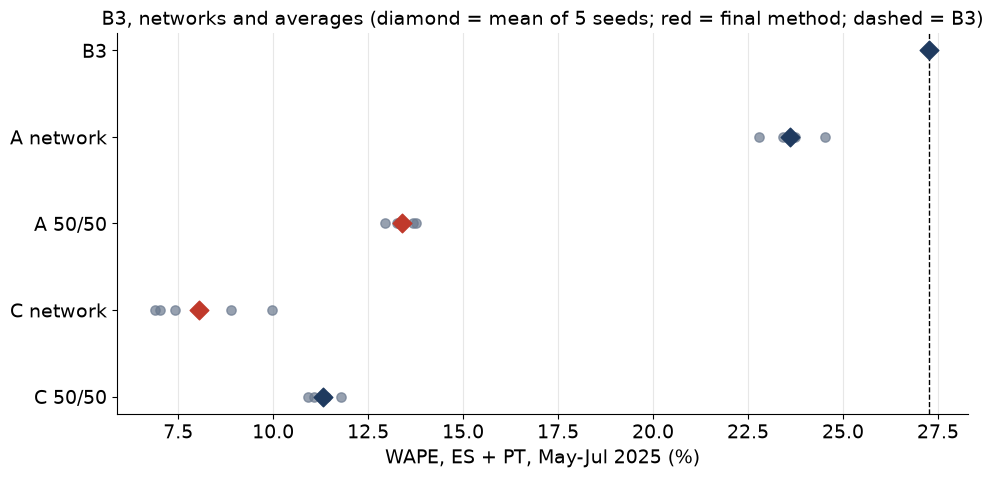

Guardado: evidence_dl_unidades/DLU44.png

--- Mês a mês (ES + PT): previsto contra real, média das 5 sementes ---


,Month to forecast,Actual (units),B3,Error B3,A network,Error A network,A 50/50,Error A 50/50,C network,Error C network,C 50/50,Error C 50/50
0,May 2025,168.036,260.903,"55,3%",170.045,"1,2%",215.474,"28,2%",158.192,"-5,9%",209.548,"24,7%"
1,Jun 2025,259.624,355.655,"37,0%",163.317,"-37,1%",259.486,"-0,1%",245.937,"-5,3%",300.796,"15,9%"
2,Jul 2025,362.588,335.964,"-7,3%",274.640,"-24,3%",305.302,"-15,8%",402.598,"11,0%",369.281,"1,8%"


Guardado: evidence_dl_unidades/DLU45.csv

--- Controlo 1: contagens ---
Linhas de previsão mensal: 150 | esperado: 150 | em falta: 0 | bate: True
Controlo 2: WAPE do B3 desta célula contra o do ponto 4: 27,3% contra 27,3% | bate: True
Controlo 3: a média 50/50 é a média da rede e do B3 (diferença máxima A e C): 0.0 0.0 (esperado 0)
Controlo 4: B3 recalculado do zero em Jul 2025 (Online ES): diferença 0.0 (esperado 0)
Controlo 5: meses usados: ['2025-05', '2025-06', '2025-07'] | todos de Training: True | nenhum do Test: True


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the variables of the previous cells: fc_b3 and meses_b3 (point 4), fc10 and BEST_CFG_NAME (point 10), fc13 and BEST_CFG_C_NAME (point 13).
for nome in ['scorecard', 'SEEDS', 'MARKETS', 'split_of', 'fmt', 'pct', 'save_table', 'save_fig', 'fc_b3', 'meses_b3', 'fc10', 'BEST_CFG_NAME', 'fc13', 'BEST_CFG_C_NAME', 'monthly', 'history', 'daily',
             'b3_monthly', 'TARGET']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including those of points 10 and 13), then this one.")

plt.rcParams.update({'font.size': 14})
M_EVAL = [m for m in meses_b3 if split_of(m) == 'Training']                           # May to July 2025
print('Comparison months:', [str(m) for m in M_EVAL])

# ---------- the monthly forecasts of each method, by seed ----------
def serie(df, nome_met, seed):
    d = df[(df['method'] == f'{nome_met}||{seed}') & (df['month'].isin(M_EVAL))]
    return d.set_index(['mark', 'month'])['forecast'].sort_index()
b3 = fc_b3[(fc_b3['method'] == 'B3 monthly') & (fc_b3['month'].isin(M_EVAL))].set_index(['mark', 'month'])['forecast'].sort_index()
parts = []
for seed in SEEDS:
    a, c = serie(fc10, BEST_CFG_NAME, seed), serie(fc13, BEST_CFG_C_NAME, seed)
    for nome, s in [('B3', b3), ('A network', a), ('A 50/50', 0.5 * a + 0.5 * b3), ('C network', c), ('C 50/50', 0.5 * c + 0.5 * b3)]:
        parts.append(s.rename('forecast').reset_index().assign(method=f'{nome}||{seed}'))
fc15 = pd.concat(parts, ignore_index=True)

sc15 = scorecard(fc15)
sc15 = sc15[sc15['split'] == 'Training'].copy()
sc15[['variant', 'seed']] = sc15['method'].str.split(r'\|\|', expand=True)
sc15['seed'] = sc15['seed'].astype(int)
tot15 = sc15[sc15['mark'] == 'ES + PT'].set_index(['variant', 'seed'])
W = {v: tot15.loc[v]['WAPE'].sort_index() for v in ['B3', 'A network', 'A 50/50', 'C network', 'C 50/50']}

# ---------- DLU42: the 5 methods and the rule ----------
def vence(x, y):                      # x beats y if it has a lower mean WAPE and wins in at least 4 of the 5 seeds (comparison by seed)
    return bool(x.mean() < y.mean() and int((x < y).sum()) >= 4), int((x < y).sum())
ref_rede = {'A 50/50': 'A network', 'C 50/50': 'C network'}
rows = []
for v in W:
    bias_m = tot15.loc[v]['Bias'].mean(); rmse_m = tot15.loc[v]['RMSE'].mean()
    r_b3 = vence(W[v], W['B3']) if v != 'B3' else (None, '')
    r_rd = vence(W[v], W[ref_rede[v]]) if v in ref_rede else (None, '')
    rows.append({'Method': v, 'WAPE mean': pct(W[v].mean()), 'WAPE std (seeds)': pct(W[v].std()), 'Bias mean': pct(bias_m), 'RMSE (units, monthly totals)': fmt(rmse_m),
                 'Beats B3 (seeds of 5)': r_b3[1], 'Beats B3 by the rule': '' if r_b3[0] is None else ('yes' if r_b3[0] else 'no'),
                 'Beats the network alone (seeds of 5)': r_rd[1], 'Beats the network alone by the rule': '' if r_rd[0] is None else ('yes' if r_rd[0] else 'no')})
dlu42 = pd.DataFrame(rows)
print('\n--- The 5 methods, May to July 2025 (ES + PT, Training, mean of the 5 seeds) ---')
display(dlu42)
save_table(dlu42, 'DLU42', 'B3, networks and 50/50 averages with B3 (units, Training months with B3, 5 seeds)', 'May-Jul 2025')

# ---------- what the rule says ----------
FINAL_A = 'A 50/50' if vence(W['A 50/50'], W['A network'])[0] else 'A network'
FINAL_C = 'C 50/50' if vence(W['C 50/50'], W['C network'])[0] else 'C network'
print(f'\nFinal method of scenario A, by the rule: {FINAL_A} | of scenario C: {FINAL_C}')
for nome in [FINAL_A, FINAL_C]:
    if not vence(W[nome], W['B3'])[0]:
        print(f'Warning: {nome} does not beat B3 by the rule (in these 3 months). We decide with you.')

# ---------- DLU43: by market ----------
mk15 = sc15[sc15['mark'].isin(MARKETS)].groupby(['variant', 'mark'])['WAPE'].mean().unstack()
dlu43 = pd.DataFrame({'Method': list(W), **{f'WAPE {m}': [pct(mk15.loc[v, m]) for v in W] for m in MARKETS}})
print('\n--- WAPE by market (mean of the 5 seeds) ---')
display(dlu43)
save_table(dlu43, 'DLU43', 'B3, networks and 50/50 averages: WAPE by market (units, Training months with B3, 5 seeds)', 'May-Jul 2025')

# ---------- chart ----------
fig, ax = plt.subplots(figsize=(10, 5))
nomes = list(W)
for i, v in enumerate(nomes):
    w = W[v] * 100
    ax.scatter(w.to_numpy(), [i] * len(w), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([w.mean()], [i], color='#c0392b' if v in (FINAL_A, FINAL_C) else '#1f3a5f', marker='D', s=90, zorder=4)
ax.axvline(W['B3'].mean() * 100, color='black', lw=1, ls='--')
ax.set_yticks(range(len(nomes))); ax.set_yticklabels(nomes); ax.invert_yaxis()
ax.set_xlabel('WAPE, ES + PT, May-Jul 2025 (%)'); ax.set_title('B3, networks and averages (diamond = mean of 5 seeds; red = final method; dashed = B3)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU44', 'B3, networks and 50/50 averages: WAPE by method, one dot per seed (units, Training months with B3)', 'May-Jul 2025')

# ---------- DLU45: month by month, ES + PT, mean of the 5 seeds ----------
act = monthly.set_index(['mark', 'month'])['net_units']
def mensal(v):
    return fc15[fc15['method'].str.startswith(v + '||')].groupby(['mark', 'month'])['forecast'].mean()
M = {v: mensal(v) for v in W}
rows = []
for m in M_EVAL:
    r_ = float(sum(act[(x, m)] for x in MARKETS))
    row = {'Month to forecast': m.strftime('%b %Y'), 'Actual (units)': fmt(r_)}
    for v in W:
        f_ = float(sum(M[v][(x, m)] for x in MARKETS))
        row[f'{v}'] = fmt(f_); row[f'Error {v}'] = pct((f_ - r_) / r_)
    rows.append(row)
dlu45 = pd.DataFrame(rows)
print('\n--- Month by month (ES + PT): forecast against actual, mean of the 5 seeds ---')
display(dlu45)
save_table(dlu45, 'DLU45', 'Month by month, ES + PT: forecast against actual for B3, networks and averages (units, Training months with B3, mean of 5 seeds)', 'May-Jul 2025')

# ---------- checks ----------
n_esperado = 5 * len(SEEDS) * len(M_EVAL) * len(MARKETS)
vazios = int(fc15['forecast'].isna().sum())
print('\n--- Check 1: counts ---')
print('Monthly forecast rows:', fmt(len(fc15)), '| expected:', fmt(n_esperado), '| missing:', vazios, '| match:', bool(len(fc15) == n_esperado and vazios == 0))
sc_b3 = scorecard(fc_b3[fc_b3['method'] == 'B3 monthly'])
w_b3_p4 = float(sc_b3[(sc_b3['mark'] == 'ES + PT') & (sc_b3['split'] == 'Training')]['WAPE'].iloc[0])
print('Check 2: WAPE of B3 in this cell against that of point 4:', pct(W['B3'].mean()), 'against', pct(w_b3_p4), '| match:', bool(abs(W['B3'].mean() - w_b3_p4) < 1e-12))
a0, c0 = serie(fc10, BEST_CFG_NAME, SEEDS[0]), serie(fc13, BEST_CFG_C_NAME, SEEDS[0])
bl_a = fc15[fc15['method'] == f'A 50/50||{SEEDS[0]}'].set_index(['mark', 'month'])['forecast'].sort_index()
bl_c = fc15[fc15['method'] == f'C 50/50||{SEEDS[0]}'].set_index(['mark', 'month'])['forecast'].sort_index()
print('Check 3: the 50/50 average is the average of the network and B3 (largest difference A and C):', float(np.abs(bl_a - (a0 + b3) / 2).max()), float(np.abs(bl_c - (c0 + b3) / 2).max()), '(expected 0)')
m_chk = M_EVAL[-1]; mk0 = MARKETS[0]
h0 = history(daily, m_chk); h0 = h0[h0['mark'] == mk0]
print(f"Check 4: B3 recalculated from scratch in {m_chk.strftime('%b %Y')} ({mk0}): difference", abs(float(b3_monthly(h0, m_chk, TARGET)) - float(b3[(mk0, m_chk)])), '(expected 0)')
meses_usados = sorted(set(fc15['month']))
print('Check 5: months used:', [str(m) for m in meses_usados], '| all Training:', all(split_of(m) == 'Training' for m in meses_usados), '| none from the Test:', not any(split_of(m) == 'Test' for m in meses_usados))

# Efficiency: trains nothing; combining forecasts and computing metrics is O(M·S·K), with M = months (3), S = seeds (5) and K = methods (5); space O(M·S·K·P) with P = markets.

### 15a. Conclusions

**Confirmed (Training, May to July 2025, ES + PT, mean of the 5 seeds):**
- Checks: 150 forecast rows, none missing; the WAPE of B3 equals that of point 4; the 50/50 average is the average of the network and B3; B3 recalculated from scratch matches; only Training months enter.
- Scenario A: the network alone has WAPE 23,6% and bias −23,1%; the 50/50 average with B3 has 13,4% and −1,3%, and beats the network in 5 of 5 seeds.
- Scenario C: the network alone has WAPE 8,0% and bias +2,1%; the 50/50 average has 11,3% and +11,3%, and beats the network in 0 of 5 seeds.
- B3 has WAPE 27,3% and bias +20,5%. All methods beat B3 in 5 of 5 seeds, so the rule raised no warnings.
- The order of the methods is the same in ES and PT.

**Derived:**
- The 50/50 average helps in scenario A because B3 overestimates and the network underestimates, and the two deviations cancel out. In scenario C the network no longer has bias, and adding B3 only adds its own.
- The gain of the average in A comes from June and July. In May the network alone is almost exact (+1,2%) and the average gets worse (+28,2%), because B3 fails a lot in that month (+55,3%).
- The result of the average depends on the errors of B3 and the network having opposite signs, which happened in these 3 months.

**To validate:**
- There are only 3 months of evidence with B3 (May to July). Training has 7 months, but B3 needs history from 2024.
- The "5 of 5 seeds" measures the stability of the network between seeds, not the variation between months. B3 has no seeds.
- Scenario C assumes the spend of the month is known at the cutoff, so its 8,0% is an upper limit and does not compete on equal terms with the 13,4% of A. We still have to confirm with Parfois at what level that spend is known.
- The Test includes Black Friday and Christmas, and Training does not.

**Decision:**
- Final method of scenario A: **A 50/50** (average of the mse_32_e100 network with B3).
- Final method of scenario C: **network C alone** (huber_32_e300).
- Test protocol fixed: August to December 2025, 5 seeds, the 5 methods shown, final method chosen in Training only; opened only once.

## 16. Units by product category

**What we will do:** build net units by market, day and product category (Training only), see which categories exist, how much they weigh and how many days have sales, and apply the ML grouping into 5 macro-groups (and the variant of 7). Nothing is trained.

**Goal:** have the category table validated before using it in a model, and understand whether the groups have enough units to be forecast.

**Decisions fixed before seeing results:**
- **Target by category:** the same net units as the main target (SALE and CANCELLED lines of orders with at least one SALE line, on the order day), split by product category (`cat_des_en` from `slv_product`, joined by `prod_sfk = prod_spk`). The sum of the categories has to give the units of the day.
- **Groups:** the base is the 5 ML macro-groups (gold document, section 2), to keep it comparable with the colleague's model. The sensitivity variant splits *Winter and Apparel* into *Apparel*, *Footwear* and *Other winter* (7 groups). The variant does not replace the base, whatever the result.
- **Categories outside the ML grouping:** they go in a separate group, *Not mapped*, so the sum still closes. If any appear, we say which.
- **Training only:** the code does not read data after July 2025.
- **Rule for the category model (next point):** it enters if it has a lower mean WAPE than the direct model and wins in at least 4 of the 5 seeds, in scenarios A and C, with the configurations already fixed. The design of the network is fixed in the next point, before training.

**Cautions:**
- A group with many days without sales is hard to forecast, and the sum of the groups can accumulate errors.
- The result that category had in gross sales is not assumed here. Units are a different target.
- Days with negative units per group are counted, because the forecast is limited to 0.

**Checks:** the sum of the categories equals the daily net units (1.156 market-days); the product key is unique in `slv_product`; the sum of the groups equals the total in both versions; last day read = end of Training.

Categorias encontradas nas unidades: 19 | categorias do agrupamento do ML: 20
Categorias do ML que não existem nos nossos dados: ['home']
Categorias nossas fora do agrupamento do ML: nenhuma

--- Categorias de produto: unidades líquidas e quota (ES + PT, só Training) ---


,Category,Group (ML),Units 2024,Units Jan-Jul 2025,Share 2024,Share Jan-Jul 2025,"Market-days with units, Jan-Jul 2025 (of 424)"
0,Apparel,Winter and Apparel,556.551,577.133,"25,1%","31,4%",424
1,Hand Bag,Bags and Small Goods,431.454,343.616,"19,5%","18,7%",424
2,Footwear,Winter and Apparel,316.940,300.339,"14,3%","16,3%",424
3,Jewellery,Jewellery and Watches,382.504,263.504,"17,3%","14,3%",424
4,Wallet,Bags and Small Goods,103.852,79.569,"4,7%","4,3%",424
5,Stainless Steel,Jewellery and Watches,57.830,40.537,"2,6%","2,2%",424
6,Party,Party and Lifestyle,55.717,40.048,"2,5%","2,2%",424
7,Travel,Summer and Travel,45.192,31.468,"2,0%","1,7%",424
8,Night,Party and Lifestyle,47.184,30.229,"2,1%","1,6%",424
9,Winter Textiles,Winter and Apparel,32.205,23.486,"1,5%","1,3%",184


Guardado: evidence_dl_unidades/DLU46.csv

--- Grupos: quota das unidades e dias com venda (ES + PT, só Training) ---


,Version,Group,Categories,Share 2024,Share Jan-Jul 2025,"Market-days with units, Jan-Jul 2025",Share of market-days without units
0,5 groups,Jewellery and Watches,"Stainless Steel, Watches, Jewellery, Silver","22,9%","18,5%",424,"0,0%"
1,5 groups,Bags and Small Goods,"Wallet, Belts, Fragrances, Hand Bag","24,6%","23,3%",424,"0,0%"
2,5 groups,Summer and Travel,"Waterproof, Travel, Sunglasses","3,3%","2,8%",424,"0,0%"
3,5 groups,Winter and Apparel,"Scarves, Hats, Apparel, Footwear, Winter Textiles","42,9%","50,4%",424,"0,0%"
4,5 groups,Party and Lifestyle,"Night, Home, Hair Accessories, Party","6,3%","5,1%",424,"0,0%"
5,7 groups,Jewellery and Watches,"Stainless Steel, Watches, Jewellery, Silver","22,9%","18,5%",424,"0,0%"
6,7 groups,Bags and Small Goods,"Wallet, Belts, Fragrances, Hand Bag","24,6%","23,3%",424,"0,0%"
7,7 groups,Summer and Travel,"Waterproof, Travel, Sunglasses","3,3%","2,8%",424,"0,0%"
8,7 groups,Party and Lifestyle,"Night, Home, Hair Accessories, Party","6,3%","5,1%",424,"0,0%"
9,7 groups,Apparel,Apparel,"25,1%","31,4%",424,"0,0%"


Guardado: evidence_dl_unidades/DLU47.csv


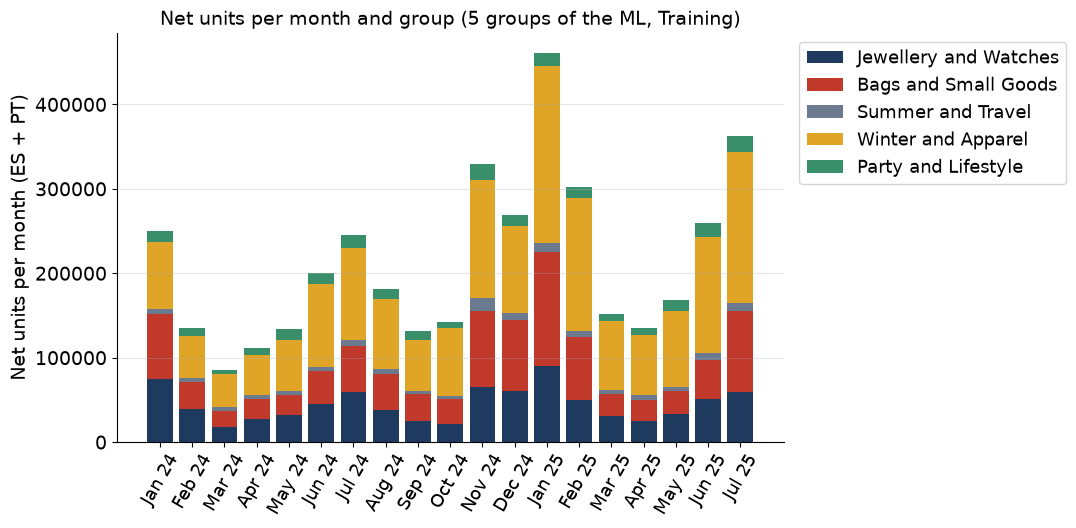

Guardado: evidence_dl_unidades/DLU48.png

--- Controlo 1: a soma das categorias é igual às unidades líquidas do dia (a mesma tabela diária da célula 1) ---
Dias de mercado comparados: 1.156 | maior diferença num dia (unidades): 0,0000 | bate: True
Unidades totais: tabela diária 4.055.529 | soma das categorias 4.055.529

Controlo 2: a chave dos produtos é única em slv_product: 246.821 linhas, 246.821 chaves distintas | bate: True | unidades sem categoria: 0 (0,0% das unidades)
Controlo 3 (5 groups): a soma dos grupos é igual ao total: True | unidades em "Not mapped": 0
Controlo 3 (7 groups): a soma dos grupos é igual ao total: True | unidades em "Not mapped": 0
Controlo 4: mercado-dias-grupo com unidades líquidas negativas (5 grupos): 0 de 5.780 com registos | unidades nesses casos: 0
Controlo 5: último dia lido: 2025-07-31 | fim do Training: 2025-07-31 | nenhum dia do Test: True


In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the variables of the previous cells: con, lake, scope_facts (temporary table from cell 1), daily, TRAIN_END (point 5), MARKETS, fmt, pct, save_table, save_fig.
for nome in ['con', 'lake', 'daily', 'TRAIN_END', 'MARKETS', 'fmt', 'pct', 'save_table', 'save_fig']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again, then this one.")

plt.rcParams.update({'font.size': 14})
cut = pd.Timestamp(TRAIN_END)                                                   # only data up to the end of Training is read
SILVER_DET = f"'{lake.uri('silver', 'slv_order_det')}.parquet'"
SILVER_PROD = f"'{lake.uri('silver', 'slv_product')}.parquet'"

# ---------- does the product table have the columns we need? ----------
cols_prod = con.sql(f"DESCRIBE SELECT * FROM read_parquet({SILVER_PROD})").df()['column_name'].tolist()
if not {'prod_spk', 'cat_des_en'} <= set(cols_prod):
    raise RuntimeError(f'slv_product does not have prod_spk and cat_des_en. Columns found: {cols_prod}')
n_prod, n_prod_d = con.execute(f"SELECT count(*), count(DISTINCT prod_spk) FROM read_parquet({SILVER_PROD})").fetchall()[0]

# ---------- units by market, day and category (only up to the end of Training) ----------
# Same definition of the target as cell 1: SALE and CANCELLED lines (cancellations with negative sign) of orders with at least one SALE line, on the order day.
# The category comes from slv_product (cat_des_en), joined by prod_sfk = prod_spk; products without category stay in 'No category'.
con.execute(f"""
CREATE OR REPLACE TEMP TABLE cat_units AS
SELECT f.mark, f.order_d AS day, COALESCE(p.cat_des_en, 'No category') AS cat,
       sum(CAST(d.prod_qty AS DOUBLE)) AS units, count(*) AS lines
FROM scope_facts f
JOIN read_parquet({SILVER_DET}) d ON d.order_id = f.order_id
LEFT JOIN read_parquet({SILVER_PROD}) p ON d.prod_sfk = p.prod_spk
WHERE f.sale_lines > 0 AND d.type IN ('SALE', 'CANCELLED') AND f.order_d <= DATE '{cut.date()}'
GROUP BY 1, 2, 3
""")
cu = con.sql("SELECT * FROM cat_units").df()
cu['day'] = pd.to_datetime(cu['day']); cu['year'] = cu['day'].dt.year
assert cu['day'].max() <= cut, 'information leak: Test data in the study'

# ---------- the ML grouping (gold document, section 2), fixed before seeing results ----------
MAP_ML = {'Jewellery and Watches': ['Stainless Steel', 'Watches', 'Jewellery', 'Silver'],
          'Bags and Small Goods': ['Wallet', 'Belts', 'Fragrances', 'Hand Bag'],
          'Summer and Travel': ['Waterproof', 'Travel', 'Sunglasses'],
          'Winter and Apparel': ['Scarves', 'Hats', 'Apparel', 'Footwear', 'Winter Textiles'],
          'Party and Lifestyle': ['Night', 'Home', 'Hair Accessories', 'Party']}
MAP_7 = {g: cs for g, cs in MAP_ML.items() if g != 'Winter and Apparel'}                  # variant: the large group is split in three
MAP_7.update({'Apparel': ['Apparel'], 'Footwear': ['Footwear'], 'Other winter': ['Scarves', 'Hats', 'Winter Textiles']})
def mapa(m):
    inv = {c.lower(): g for g, cs in m.items() for c in cs}                                 # lowercase category -> group
    return cu['cat'].astype(str).str.strip().str.lower().map(inv).fillna('Not mapped')
cu['g5'], cu['g7'] = mapa(MAP_ML), mapa(MAP_7)

ml_names = sorted({c.lower() for cs in MAP_ML.values() for c in cs})
nossas = sorted(cu['cat'].astype(str).str.strip().str.lower().unique())
print('Categories found in the units:', len(nossas), '| categories of the ML grouping:', len(ml_names))
print('ML categories that do not exist in our data:', sorted(set(ml_names) - set(nossas)) or 'none')
print('Our categories outside the ML grouping:', sorted(set(nossas) - set(ml_names)) or 'none')

# ---------- DLU46: categories, share of units and days with sales ----------
dias_2025 = ((cut - pd.Timestamp('2025-01-01')).days + 1) * len(MARKETS)                   # market days from January 2025 to the end of Training
tot_u = cu.groupby('year')['units'].sum()
rows = []
for cat, d in cu.groupby('cat'):
    u = d.groupby('year')['units'].sum()
    com_venda = int(d[(d['year'] == 2025) & (d['units'] > 0)][['mark', 'day']].drop_duplicates().shape[0])
    rows.append({'Category': cat, 'Group (ML)': d['g5'].iloc[0], 'Units 2024': fmt(u.get(2024, 0)), 'Units Jan-Jul 2025': fmt(u.get(2025, 0)),
                 'Share 2024': pct(u.get(2024, 0) / tot_u[2024]), 'Share Jan-Jul 2025': pct(u.get(2025, 0) / tot_u[2025]),
                 f'Market-days with units, Jan-Jul 2025 (of {dias_2025})': com_venda, '_o': u.get(2025, 0)})
dlu46 = pd.DataFrame(rows).sort_values('_o', ascending=False).drop(columns='_o').reset_index(drop=True)
print('\n--- Product categories: net units and share (ES + PT, Training only) ---')
display(dlu46)
save_table(dlu46, 'DLU46', 'Net units by product category: units, share and days with units (ES + PT, Training)', 'Jan 2024 - Jul 2025')

# ---------- DLU47: the groups (5 from ML and the variant of 7) ----------
def tabela_grupos(col, m):
    ordem = list(m) + (['Not mapped'] if (cu[col] == 'Not mapped').any() else [])
    out = []
    for g in ordem:
        d = cu[cu[col] == g]
        dia = d.groupby(['mark', 'day'])['units'].sum()                                      # units of the group by market and day
        u = d.groupby('year')['units'].sum()
        d25 = dia[dia.index.get_level_values('day') >= pd.Timestamp('2025-01-01')]
        out.append({'Version': f'{len(m)} groups', 'Group': g, 'Categories': ', '.join(m.get(g, [])) or '-', 'Share 2024': pct(u.get(2024, 0) / tot_u[2024]),
                    'Share Jan-Jul 2025': pct(u.get(2025, 0) / tot_u[2025]), 'Market-days with units, Jan-Jul 2025': int((d25 > 0).sum()),
                    'Share of market-days without units': pct(1 - (d25 > 0).sum() / dias_2025)})
    return pd.DataFrame(out)
dlu47 = pd.concat([tabela_grupos('g5', MAP_ML), tabela_grupos('g7', MAP_7)], ignore_index=True)
print('\n--- Groups: share of units and days with sales (ES + PT, Training only) ---')
display(dlu47)
save_table(dlu47, 'DLU47', 'Product groups (5 of the ML and the 7-group variant): share of units and days with units (ES + PT, Training)', 'Jan 2024 - Jul 2025')

# ---------- chart: units by month and group (ES + PT, 5 groups) ----------
mes = cu.assign(month=cu['day'].dt.to_period('M')).groupby(['month', 'g5'])['units'].sum().unstack(fill_value=0)
grupos_g = [g for g in list(MAP_ML) + ['Not mapped'] if g in mes.columns]
cores = ['#1f3a5f', '#c0392b', '#6b7a8f', '#e0a526', '#3a8f6b', '#8e5ea2']
fig, ax = plt.subplots(figsize=(11, 5.5))
base = np.zeros(len(mes))
for g, cor in zip(grupos_g, cores):
    ax.bar(range(len(mes)), mes[g].to_numpy(), bottom=base, label=g, color=cor)
    base += mes[g].to_numpy()
ax.set_xticks(range(len(mes))); ax.set_xticklabels([m.strftime('%b %y') for m in mes.index], rotation=60, fontsize=13)
ax.set_ylabel('Net units per month (ES + PT)'); ax.set_title('Net units per month and group (5 groups of the ML, Training)', fontsize=14)
ax.legend(fontsize=13, loc='upper left', bbox_to_anchor=(1.01, 1)); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU48', 'Net units per month and group (5 groups of the ML, ES + PT, Training)', 'Jan 2024 - Jul 2025')

# ---------- checks ----------
print('\n--- Check 1: the sum of the categories equals the net units of the day (the same daily table from cell 1) ---')
soma = cu.groupby(['mark', 'day'])['units'].sum().rename('cat_sum')
ref = daily[daily['day'] <= cut].set_index(['mark', 'day'])['net_units']
cmp_ = pd.concat([ref, soma], axis=1).fillna(0)
dif = (cmp_['net_units'] - cmp_['cat_sum']).abs()
print('Market days compared:', fmt(len(cmp_)), '| largest difference in a day (units):', f"{dif.max():.4f}".replace('.', ','), '| match:', bool(dif.max() < 1e-6))
print('Total units: daily table', fmt(ref.sum()), '| sum of the categories', fmt(cu['units'].sum()))

sem_cat = cu[cu['cat'] == 'No category']
print('\nCheck 2: the product key is unique in slv_product:', fmt(n_prod), 'rows,', fmt(n_prod_d), 'distinct keys | match:', bool(n_prod == n_prod_d),
      '| units without category:', fmt(sem_cat['units'].sum()), f"({pct(sem_cat['units'].sum() / cu['units'].sum())} of the units)")

for col, nome in [('g5', '5 groups'), ('g7', '7 groups')]:
    g_ = cu.groupby(col)['units'].sum()
    print(f'Check 3 ({nome}): the sum of the groups equals the total:', bool(abs(g_.sum() - cu['units'].sum()) < 1e-6), '| units in "Not mapped":', fmt(g_.get('Not mapped', 0)))

neg = cu.groupby(['mark', 'day', 'g5'])['units'].sum()
print('Check 4: market-day-groups with negative net units (5 groups):', int((neg < 0).sum()), 'of', fmt(len(neg)), 'with records',
      '| units in those cases:', fmt(neg[neg < 0].sum()))
print('Check 5: last day read:', cu['day'].max().date(), '| end of Training:', cut.date(), '| no Test day:', bool(cu['day'].max() <= cut))

# Efficiency: one pass over slv_order_det with two joins (O(n) in time, n = detail rows up to the end of Training); the rest are groupings over cu, with c × d × m rows
# (c = categories, d = days, m = markets), O(c·d·m·log(c·d·m)); space O(c·d·m).

### 16a. Conclusions

**Confirmed (Training, ES + PT):**
- Checks: the sum of the categories equals the daily net units (1.156 market-days, difference 0); the key of `slv_product` is unique; no units are left without a category; the sum of the groups closes in both versions; there are no market-day-groups with negative units; no Test day was read.
- We found 19 categories. The ML grouping has 20, and the one missing in our data is *home*. None of our categories is outside the grouping, so there is no *Not mapped* group.
- The 5 groups have units on all 424 market-days from January to July 2025, as do the 3 parts into which the variant splits *Winter and Apparel*.
- *Winter and Apparel* is the largest group: 42,9% of units in 2024 and 50,4% from January to July 2025. Within it, *Apparel* weighs 31,4% and *Footwear* 16,3%; *Scarves*, *Hats* and *Winter Textiles* together weigh 2,7%.
- The small groups weigh little: *Summer and Travel* 2,8%, *Party and Lifestyle* 5,1%, and the *Other winter* of the variant 2,7%.
- The category table shows some with days without sales (*Winter Textiles* only has sales on 184 of the 424 market-days; *Waterproof* on 321). This does not affect the groups.

**Derived:**
- The chart shows strong seasonality. Units rise from November to January and are lowest in March and April. The rise comes mostly from *Winter and Apparel*.
- The small groups (about 3% of units each) will have little signal, so the sum of the groups may accumulate noise.
- The 2025 shares cover only seven months and those of 2024 the whole year. The rise of *Winter and Apparel* from 2024 to 2025 may be partly seasonality, so we do not treat it as a trend.

**To validate:**
- That the grouping used is the one in the ML gold document. We extracted it in the gross sales notebook and confirmed it fits our data, but we did not compare it with the colleague's file in this notebook.
- Whether *home* has no sales in ES and PT or exists under another name. We only know it does not appear.
- That forecasting by group helps. This can only be seen with the model.

**Decision:**
- Base: the 5 ML macro-groups. Sensitivity variant: 7 groups, with *Winter and Apparel* split into *Apparel*, *Footwear* and *Other winter*. The variant does not replace the base.
- The entry rule stays as fixed in point 16: lower mean WAPE than the direct model and better in at least 4 of 5 seeds, in scenarios A and C.

## 17. Category model against the direct model

**What we will do:** train the units model by product group (the 5 ML macro-groups and the variant of 7), in scenarios A and C, and compare it with the direct model of each scenario (the forecasts already calculated in points 10 and 13).

**Goal:** see whether forecasting by group and adding up gives a better total than forecasting the total directly, by the rule fixed in point 16.

**Design fixed before seeing results:**
- **One model per market, as in the direct model.** Each row is a market, day and group, and the target is the net units of that group on that day. The identity of the group enters as 0/1 columns. The calendar variables (and spend, in scenario C) are the same for all groups.
- **Same choices as the direct model.** Each scenario uses the groups of variables and the configuration already fixed (A: mse_32_e100; C: huber_32_e300), with the spend clipping of C. No new grid, so that the only thing that changes is the granularity.
- **Total of the month:** sum of the forecasts of the groups (each forecast limited to 0), then added up to monthly. Same seeds, same 7 steps and same cutoff rule (data up to the last day of M−2).
- **Entry rule (fixed in point 16):** the 5 ML groups enter if they have a lower mean WAPE than the direct model and win in at least 4 of the 5 seeds, in each scenario. The variant of 7 groups is sensitivity only: it never replaces the base and is only reported as a finding if it meets the same rule.
- **Metrics:** WAPE (decides), bias and RMSE of the monthly total ES + PT; WAPE and bias of each group as a diagnostic, deciding nothing.

**Cautions:**
- The configuration was chosen for the direct model on these same 7 months, which favours it slightly.
- Squared error gives more weight to the large groups: *Winter and Apparel* weighs half of the units.
- Each training has 5 or 7 times more rows than the direct one, so it takes about 5 to 7 times longer. The cell prints an estimate from the minutes of the direct model (tables DLU25 and DLU36) before training.
- There are only Training months. The Test stays closed.

**Checks:** 4 variants × 5 seeds × 7 steps × 2 markets = 280 forecasts, none missing or negative; the sum of the groups equals the units of the day in all rows; forecasting group by group gives the same total as forecasting the whole table; changing the units after the cutoff does not change the forecast; the WAPE of the direct model here equals that of tables DLU25 and DLU36.

Tabela g5: 5.780 linhas = 1.156 mercado-dias × 5 grupos | colunas do grupo: ['g5_0', 'g5_1', 'g5_2', 'g5_3', 'g5_4']
Tabela g7: 8.092 linhas = 1.156 mercado-dias × 7 grupos | colunas do grupo: ['g7_0', 'g7_1', 'g7_2', 'g7_3', 'g7_4', 'g7_5', 'g7_6']
Estimativa: cerca de 44 minutos (5 x 0.9 + 7 x 0.9 + 5 x 2.8 + 7 x 2.8 minutos do modelo direto)
  A: 5 groups: 1.9 min (acumulado 1.9 min)
  A: 7 groups: 2.7 min (acumulado 4.7 min)
  C: 5 groups: 5.7 min (acumulado 10.4 min)
  C: 7 groups: 8.0 min (acumulado 18.4 min)
Redes treinadas: 280 em 18.4 minutos

--- Modelo por categoria contra o modelo direto (ES + PT, Training, média das 5 sementes) ---


,Method,WAPE mean,WAPE std (seeds),Bias mean,"RMSE (units, monthly totals)",WAPE change vs direct (pp; negative = better),Wins vs direct (seeds of 5),Decision
0,A: direct,"31,2%","0,4%","-26,3%",112.831,,,reference
1,A: 5 groups,"32,2%","0,7%","-26,2%",113.720,"+1,0",0,does not enter
2,A: 7 groups,"33,0%","1,1%","-25,7%",115.634,"+1,9",0,does not pass (sensitivity)
3,C: direct,"5,3%","0,8%","1,4%",18.553,,,reference
4,C: 5 groups,"7,0%","2,2%","4,0%",27.534,"+1,7",1,does not enter
5,C: 7 groups,"7,9%","2,7%","5,6%",29.684,"+2,6",2,does not pass (sensitivity)


Guardado: evidence_dl_unidades/DLU49.csv

Cenário A: grupos do ML (5) não entram pela regra | variante de 7 grupos: não passa a regra

Cenário C: grupos do ML (5) não entram pela regra | variante de 7 grupos: não passa a regra

--- WAPE e viés de cada grupo (ES + PT somados por mês, média das 5 sementes) ---


,Scenario,Version,Group,Share of units (Jan-Jul 2025),WAPE mean,Bias mean
0,A,5 groups,Jewellery and Watches,"18,5%","21,1%","-9,4%"
1,A,5 groups,Bags and Small Goods,"23,3%","42,9%","-21,8%"
2,A,5 groups,Summer and Travel,"2,8%","32,4%","-18,1%"
3,A,5 groups,Winter and Apparel,"50,4%","36,3%","-36,0%"
4,A,5 groups,Party and Lifestyle,"5,1%","26,2%","-15,1%"
5,A,7 groups,Jewellery and Watches,"18,5%","22,5%","-8,2%"
6,A,7 groups,Bags and Small Goods,"23,3%","43,9%","-21,1%"
7,A,7 groups,Summer and Travel,"2,8%","32,4%","-15,9%"
8,A,7 groups,Party and Lifestyle,"5,1%","23,4%","-12,0%"
9,A,7 groups,Apparel,"31,4%","38,5%","-38,5%"


Guardado: evidence_dl_unidades/DLU50.csv


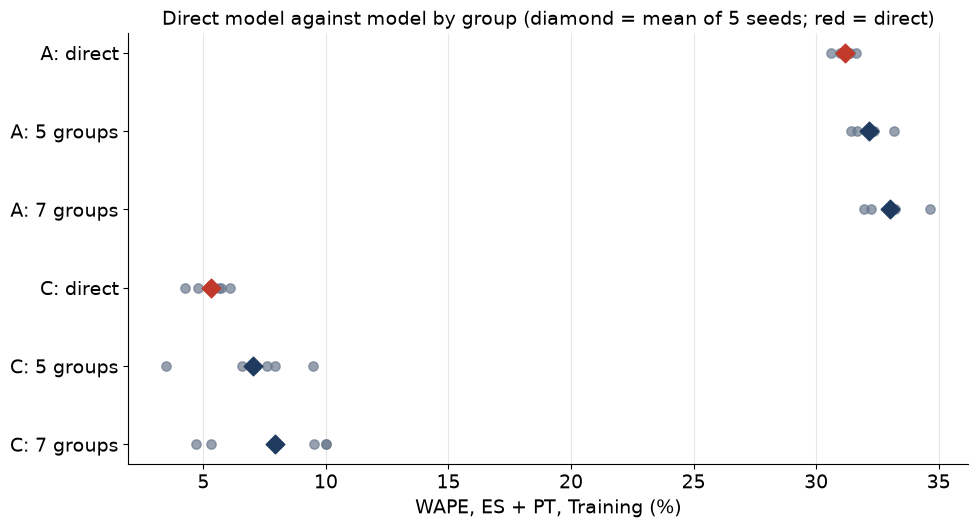

Guardado: evidence_dl_unidades/DLU51.png

--- Mês a mês (ES + PT): erro de cada método, média das 5 sementes ---


,Month to forecast,Actual (units),Error A: direct,Error A: 5 groups,Error A: 7 groups,Error C: direct,Error C: 5 groups,Error C: 7 groups
0,Jan 2025,461.380,"-54,0%","-53,5%","-54,8%","2,0%","10,9%","13,4%"
1,Feb 2025,302.468,"-31,4%","-33,8%","-32,0%","-1,6%","1,5%","2,5%"
2,Mar 2025,151.321,"18,9%","22,4%","25,5%","-2,2%","-2,2%","1,4%"
3,Apr 2025,135.154,"10,6%","9,6%","12,7%","6,1%","10,8%","7,6%"
4,May 2025,168.036,"1,2%","4,6%","6,8%","-5,9%","-3,2%","-4,0%"
5,Jun 2025,259.624,"-37,1%","-37,8%","-37,4%","-5,3%","-4,2%","-2,9%"
6,Jul 2025,362.588,"-24,3%","-24,9%","-25,9%","11,0%","6,7%","9,7%"


Guardado: evidence_dl_unidades/DLU52.csv

--- Controlo 1: contagens ---
Previsões mensais totais (soma dos grupos): 280 | esperado: 280 | em falta: 0 | negativas: 0 | bate: True
Controlo 2 (g5): a soma dos grupos é igual às unidades do dia em todas as linhas: True
Controlo 2 (g7): a soma dos grupos é igual às unidades do dia em todas as linhas: True
Controlo 3: prever grupo a grupo e prever a tabela inteira dá o mesmo total (diferença máxima, unidades): 0,0000 (esperado perto de 0: só arredondamentos) | bate: True
Controlo 4: alterar as unidades depois do corte (2024-11-30) não muda a previsão de Jan 2025 (diferença máxima, unidades): 0.0 (esperado 0)
Controlo 5: só meses de Training: True
Controlo 6 (A: direct): WAPE médio aqui 31,2% | na tabela DLU25 31,2% | bate: True
Controlo 6 (C: direct): WAPE médio aqui 5,3% | na tabela DLU36 5,3% | bate: True


In [23]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Uses the variables of the previous cells: fit_pack, prever_mes, scorecard, feat, FEATURE_GROUPS, SEEDS, STEPS, SPEC_A, CFG_A, fc10, BEST_CFG_NAME (point 10),
# SPEC_C, CFG_C, fc13, BEST_CFG_C_NAME (point 13) and cu, MAP_ML, MAP_7 (point 16).
for nome in ['fit_pack', 'prever_mes', 'scorecard', 'feat', 'FEATURE_GROUPS', 'SEEDS', 'STEPS', 'MARKETS', 'split_of', 'cutoff_date', 'SPEC_A', 'CFG_A', 'fc10', 'BEST_CFG_NAME',
             'SPEC_C', 'CFG_C', 'fc13', 'BEST_CFG_C_NAME', 'cu', 'MAP_ML', 'MAP_7', 'monthly', 'fmt', 'pct', 'save_table', 'save_fig', 'EVID', 'TRAIN_END']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including those of points 10, 13 and 16), then this one.")

plt.rcParams.update({'font.size': 14})
cut = pd.Timestamp(TRAIN_END)
SPEC, CFG = {'A': SPEC_A, 'C': SPEC_C}, {'A': CFG_A, 'C': CFG_C}
for s in SPEC.values():
    assert s['table'] is feat, 'the scenarios have to use the feat table (one row per market and day)'

# ---------- the table by category: each (market, day) row is repeated once per group; the target becomes the units of the group ----------
# The calendar columns (and spend, in scenario C) are the same for all groups; the identity of the group enters as 0/1 columns.
ft_days = feat[feat['day'] <= cut].copy()                                           # only days up to the end of Training
def tabela_cat(gcol):
    grupos = list(MAP_ML if gcol == 'g5' else MAP_7) + (['Not mapped'] if (cu[gcol] == 'Not mapped').any() else [])
    u = cu.groupby(['mark', 'day', gcol])['units'].sum().unstack(fill_value=0.0).reindex(columns=grupos, fill_value=0.0)    # units by market, day and group
    parts = []
    for k, g in enumerate(grupos):
        t = ft_days.copy()
        t['grp'] = g
        t['y'] = u[g].reindex(pd.MultiIndex.from_frame(t[['mark', 'day']])).fillna(0.0).to_numpy()      # days without records for the group get 0 units
        for j in range(len(grupos)):
            t[f'{gcol}_{j}'] = int(j == k)
        parts.append(t)
    FEATURE_GROUPS[gcol] = [f'{gcol}_{j}' for j in range(len(grupos))]
    return pd.concat(parts, ignore_index=True), grupos
TABS = {gcol: tabela_cat(gcol) for gcol in ['g5', 'g7']}
SUBS = {gcol: {g: ft[ft['grp'] == g] for g in grupos} for gcol, (ft, grupos) in TABS.items()}      # sub-tables by group, to forecast group by group
for gcol, (ft, grupos) in TABS.items():
    print(f"Table {gcol}: {fmt(len(ft))} rows = {fmt(len(ft_days))} market-days × {len(grupos)} groups | group columns: {FEATURE_GROUPS[gcol]}")

# ---------- train: one model per market, with the group as input; the total of the month is the sum of the groups ----------
VARS = [('A', '5 groups', 'g5'), ('A', '7 groups', 'g7'), ('C', '5 groups', 'g5'), ('C', '7 groups', 'g7')]
# Time estimate: each training has G times more rows than the direct one, so the time is about G × the minutes of the direct model (tables DLU25 and DLU36).
try:
    min_dir = {s: float(pd.read_csv(EVID / f).loc[lambda t: t['Configuration'] == n, 'Minutes (5 seeds x 7 steps)'].iloc[0]) for s, f, n in
               [('A', 'DLU25.csv', BEST_CFG_NAME), ('C', 'DLU36.csv', BEST_CFG_C_NAME)]}
    est = sum(len(TABS[gcol][1]) * min_dir[scen] for scen, ver, gcol in VARS)
    print(f'Estimate: about {round(est)} minutes ({" + ".join(f"{len(TABS[gcol][1])} x {min_dir[scen]}" for scen, ver, gcol in VARS)} minutes of the direct model)')
except Exception as e:
    print('No time estimate (could not read the minutes from tables DLU25 and DLU36):', e)
t0 = time.time()
rows_g = []
for scen, ver, gcol in VARS:
    t1 = time.time()
    ft, grupos = TABS[gcol]
    groups = list(SPEC[scen]['groups']) + [gcol]
    nome = f'{scen}: {ver}'
    for seed in SEEDS:
        for m in STEPS:
            pack = fit_pack(m, groups, CFG[scen], seed, table=ft)
            for g in grupos:
                p = prever_mes(pack, m, table=SUBS[gcol][g], clip=SPEC[scen]['clip']).groupby('mark')['forecast'].sum()
                rows_g += [(nome, seed, mk, m, g, float(p[mk])) for mk in MARKETS]
    print(f'  {nome}: {round((time.time() - t1) / 60, 1)} min (cumulative {round((time.time() - t0) / 60, 1)} min)')
fcg = pd.DataFrame(rows_g, columns=['variant', 'seed', 'mark', 'month', 'group', 'forecast'])
fcg.assign(month=fcg['month'].astype(str)).to_csv(EVID / 'DLU49_raw_forecasts.csv', index=False)
print(f'Networks trained: {len(VARS) * len(SEEDS) * len(STEPS) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- total monthly forecasts (sum of the groups) and direct references already calculated (same seeds and steps) ----------
tot = fcg.groupby(['variant', 'seed', 'mark', 'month'], as_index=False)['forecast'].sum()
tot['method'] = tot['variant'] + '||' + tot['seed'].astype(str)
def ref_direta(df, cfg_name_, nome):
    d = df[df['method'].str.startswith(cfg_name_ + '||') & df['month'].isin(STEPS)].copy()
    d['method'] = nome + '||' + d['method'].str.split(r'\|\|').str[1]
    return d[['method', 'mark', 'month', 'forecast']]
fc17 = pd.concat([ref_direta(fc10, BEST_CFG_NAME, 'A: direct'), ref_direta(fc13, BEST_CFG_C_NAME, 'C: direct'), tot[['method', 'mark', 'month', 'forecast']]], ignore_index=True)

sc17 = scorecard(fc17)
sc17 = sc17[sc17['split'] == 'Training'].copy()
sc17[['variant', 'seed']] = sc17['method'].str.split(r'\|\|', expand=True)
sc17['seed'] = sc17['seed'].astype(int)
tot17 = sc17[sc17['mark'] == 'ES + PT'].set_index(['variant', 'seed'])
W = {v: tot17.loc[v]['WAPE'].sort_index() for v in ['A: direct', 'A: 5 groups', 'A: 7 groups', 'C: direct', 'C: 5 groups', 'C: 7 groups']}

# ---------- DLU49: the rule, scenario by scenario ----------
rows, passa = [], {}
for nome, w in W.items():
    ref = W[nome.split(':')[0] + ': direct']
    ganha = int((w < ref).sum())
    if nome.endswith('direct'):
        dec_, dif_, gan_ = 'reference', '', ''
    else:
        passa[nome] = bool(w.mean() < ref.mean() and ganha >= 4)
        dif_, gan_ = f"{(w.mean() - ref.mean()) * 100:+.1f}".replace('.', ','), ganha
        dec_ = ('enters' if passa[nome] else 'does not enter') if nome.endswith('5 groups') else ('passes the rule (finding; does not replace the base)' if passa[nome] else 'does not pass (sensitivity)')
    rows.append({'Method': nome, 'WAPE mean': pct(w.mean()), 'WAPE std (seeds)': pct(w.std()), 'Bias mean': pct(tot17.loc[nome]['Bias'].mean()),
                 'RMSE (units, monthly totals)': fmt(tot17.loc[nome]['RMSE'].mean()), 'WAPE change vs direct (pp; negative = better)': dif_,
                 'Wins vs direct (seeds of 5)': gan_, 'Decision': dec_})
dlu49 = pd.DataFrame(rows)
print('\n--- Category model against the direct model (ES + PT, Training, mean of the 5 seeds) ---')
display(dlu49)
save_table(dlu49, 'DLU49', 'Model by product group against the direct model (units, scenarios A and C, Training, 5 seeds)', 'Jan-Jul 2025')
for scen in ['A', 'C']:
    print(f"\nScenario {scen}: ML groups (5) {'ENTER' if passa[f'{scen}: 5 groups'] else 'do not enter'} by the rule | variant of 7 groups: {'meets the rule' if passa[f'{scen}: 7 groups'] else 'does not meet the rule'}")

# ---------- DLU50: where the error is, group by group (diagnostic) ----------
act_g = {gc: cu.assign(month=cu['day'].dt.to_period('M')).groupby([gc, 'month'])['units'].sum() for gc in ['g5', 'g7']}
rows = []
for scen, ver, gcol in VARS:
    nome = f'{scen}: {ver}'
    f = fcg[fcg['variant'] == nome].groupby(['seed', 'group', 'month'])['forecast'].sum()
    tot_a = sum(act_g[gcol][(g, m)] for g in TABS[gcol][1] for m in STEPS)
    for g in TABS[gcol][1]:
        a = np.array([act_g[gcol][(g, m)] for m in STEPS], float)
        ws, bs = [], []
        for seed in SEEDS:
            fv = np.array([f[(seed, g, m)] for m in STEPS], float)
            ws.append(np.abs(fv - a).sum() / a.sum()); bs.append((fv - a).sum() / a.sum())
        rows.append({'Scenario': scen, 'Version': ver, 'Group': g, 'Share of units (Jan-Jul 2025)': pct(a.sum() / tot_a), 'WAPE mean': pct(np.mean(ws)), 'Bias mean': pct(np.mean(bs))})
dlu50 = pd.DataFrame(rows)
print('\n--- WAPE and bias of each group (ES + PT added up by month, mean of the 5 seeds) ---')
display(dlu50)
save_table(dlu50, 'DLU50', 'Model by product group: WAPE and bias of each group (units, Training, 5 seeds)', 'Jan-Jul 2025')

# ---------- chart: WAPE of each method, one dot per seed ----------
nomes = list(W)
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, v in enumerate(nomes):
    w = W[v] * 100
    ax.scatter(w.to_numpy(), [i] * len(w), color='#6b7a8f', alpha=0.7, s=45, zorder=3)
    ax.scatter([w.mean()], [i], color='#c0392b' if v.endswith('direct') else '#1f3a5f', marker='D', s=90, zorder=4)
ax.set_yticks(range(len(nomes))); ax.set_yticklabels(nomes); ax.invert_yaxis()
ax.set_xlabel('WAPE, ES + PT, Training (%)'); ax.set_title('Direct model against model by group (diamond = mean of 5 seeds; red = direct)', fontsize=14)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU51', 'WAPE of the direct model and of the model by group, one dot per seed (units, Training)', 'Jan-Jul 2025')

# ---------- DLU52: month by month, ES + PT, mean of the 5 seeds ----------
act = monthly.set_index(['mark', 'month'])['net_units']
mens = {v: fc17[fc17['method'].str.startswith(v + '||')].groupby(['mark', 'month'])['forecast'].mean() for v in W}
rows = []
for m in STEPS:
    r_ = float(sum(act[(x, m)] for x in MARKETS))
    row = {'Month to forecast': m.strftime('%b %Y'), 'Actual (units)': fmt(r_)}
    for v in W:
        row[f'Error {v}'] = pct((float(sum(mens[v][(x, m)] for x in MARKETS)) - r_) / r_)
    rows.append(row)
dlu52 = pd.DataFrame(rows)
print('\n--- Month by month (ES + PT): error of each method, mean of the 5 seeds ---')
display(dlu52)
save_table(dlu52, 'DLU52', 'Month by month, ES + PT: error of the direct model and of the model by group (units, Training, mean of 5 seeds)', 'Jan-Jul 2025')

# ---------- checks ----------
n_esperado = len(VARS) * len(SEEDS) * len(STEPS) * len(MARKETS)
print('\n--- Check 1: counts ---')
print('Total monthly forecasts (sum of the groups):', fmt(len(tot)), '| expected:', fmt(n_esperado), '| missing:', int(tot['forecast'].isna().sum()), '| negatives:', int((tot['forecast'] < 0).sum()),
      '| match:', bool(len(tot) == n_esperado and tot['forecast'].notna().all() and (tot['forecast'] >= 0).all()))
for gcol, (ft, grupos) in TABS.items():
    s_ = ft.groupby(['mark', 'day'])['y'].sum().rename('s')
    r_ = ft_days.set_index(['mark', 'day'])['y']
    print(f'Check 2 ({gcol}): the sum of the groups equals the units of the day in all rows:', bool(np.allclose(s_.reindex(r_.index).to_numpy(), r_.to_numpy())))

M_L = STEPS[0]
ft5 = TABS['g5'][0]; G5 = list(SPEC_A['groups']) + ['g5']
pk0 = fit_pack(M_L, G5, CFG_A, 0, table=ft5)
p_full = prever_mes(pk0, M_L, table=ft5, clip=SPEC_A['clip']).groupby('mark')['forecast'].sum()
p_grp = pd.concat([prever_mes(pk0, M_L, table=SUBS['g5'][g], clip=SPEC_A['clip']).groupby('mark')['forecast'].sum() for g in TABS['g5'][1]], axis=1).sum(axis=1)
d3 = float((p_full - p_grp).abs().max())
print('Check 3: forecasting group by group and forecasting the whole table gives the same total (largest difference, units):', f'{d3:.4f}'.replace('.', ','), '(expected close to 0: rounding only) | match:', bool(d3 < 0.01))
rng = np.random.default_rng(1)
ft_x = ft5.copy(); aft = ft_x['day'] > cutoff_date(M_L)
ft_x.loc[aft, 'y'] = ft_x.loc[aft, 'y'] + rng.integers(500, 5000, int(aft.sum()))
pk1 = fit_pack(M_L, G5, CFG_A, 0, table=ft_x)
p_x = prever_mes(pk1, M_L, table=ft_x, clip=SPEC_A['clip']).groupby('mark')['forecast'].sum()
print(f"Check 4: change the units after the cutoff ({cutoff_date(M_L).date()}) does not change the forecast of {M_L.strftime('%b %Y')} (largest difference, units):", float((p_full - p_x).abs().max()), '(expected 0)')
print('Check 5: only Training months:', bool(set(fc17['month']) == set(STEPS) and all(split_of(m) == 'Training' for m in STEPS)))
for nome, ficheiro, cfg_n in [('A: direct', 'DLU25.csv', BEST_CFG_NAME), ('C: direct', 'DLU36.csv', BEST_CFG_C_NAME)]:
    t = pd.read_csv(EVID / ficheiro)
    visto = t.loc[t['Configuration'] == cfg_n, 'WAPE mean'].iloc[0]
    print(f'Check 6 ({nome}): mean WAPE here {pct(W[nome].mean())} | in the table {ficheiro[:-4]} {visto} | match:', pct(W[nome].mean()) == visto)

# Efficiency: each training is O(E·(N·G)·P), with G = number of groups (5 or 7): the training rows are multiplied by G compared with the direct model. That is 4 variants × 5 seeds × 7 steps × 2 markets trainings;
# forecasting is O(G·D·P) per market and step, with D = days of the month. Space O(N·G·V), with V = number of variables.

### 17a. Conclusions

**Confirmed (Training, 7 steps, 5 seeds, ES + PT added up by month):**
- Checks: 280 forecasts, none missing or negative; the sum of the groups equals the units of the day in all rows; forecasting group by group gives the same total as forecasting the whole table; changing the units after the cutoff does not change the forecast; the WAPE of the direct model here equals that of tables DLU25 and DLU36.
- Scenario A: the direct model has WAPE 31,2%, the 5 groups 32,2% (better in 0 of 5 seeds) and the 7 groups 33,0% (0 of 5). None meets the rule.
- Scenario C: the direct model has WAPE 5,3%, the 5 groups 7,0% (1 of 5) and the 7 groups 7,9% (2 of 5). None meets the rule.
- The spread between seeds is larger in the group models: in C, 2,2 and 2,7 points against 0,8 for the direct one.
- In A, all groups are underestimated (bias from −9,4% to −36,0% with 5 groups). In C, the dominant group (*Winter and Apparel*, 50,4% of units) has WAPE 12,1% and bias −11,1%, and the small groups are far above the actual: *Summer and Travel* +46,1% and *Party and Lifestyle* +27,9%.

**Derived:**
- The error of A comes from the level (January −54%, June −37%), and splitting by groups does not fix it. The monthly totals of the three methods in A are almost equal.
- In C, the total of the 5 groups is closer to the actual than the direct one in May, June and July, and further away in January and April. In February and March they are equivalent. The worse WAPE and RMSE (27.534 against 18.553) come mostly from January.
- In the total of C, the errors of the groups partly offset each other: four groups overestimate and the dominant group underestimates.
- To split products by category, the forecast is only reasonable for the large groups (WAPE between 12% and 17% in C). The small groups have WAPE above 37%.
- Splitting *Winter and Apparel* into *Apparel*, *Footwear* and *Other winter* does not help: the total gets worse in both scenarios, and *Other winter* (2,7% of units) has WAPE 78,8% in C.
- The verdict is the same as in the gross sales notebook: no category version meets the rule.

**To validate:**
- The configuration was chosen for the direct model on these same 7 months, which favours it slightly. A configuration of its own for the groups was not tested, by a decision fixed before seeing results.
- Why the small groups are above the actual in C. We did not investigate the cause.

**Decision:**
- Forecasting by category does not enter in any scenario: the direct model stays as the base, with the final method from point 15 (A 50/50 and network C).
- The groups stay as a diagnostic (where the error is), not as the final forecast. The variant of 7 groups replaces nothing.
- Category does not go to the Test. It stays in the report as a negative result.

## 18. Test: August to December 2025 (opened only once)

**What we will do:** open the Test and measure the 5 methods (B3, network A, 50/50 average A + B3, network C, 50/50 average C + B3), each with the configuration already fixed. Each month rebuilds the network with data up to its cutoff (last day of M−2), with the 5 seeds, the same rule as Training.

**Goal:** report how the final method of each scenario, chosen in Training (point 15), behaves in months it has never seen, and compare it with B3.

**Protocol (fixed in point 15, unchanged):**
- **Final methods:** those from Training, **A 50/50** in scenario A and **network C** in scenario C. The other three are shown, but the Test is not used to re-choose anything.
- **Metrics:** WAPE (the decision metric), bias, RMSE (in units, on monthly totals) and R², for ES + PT and by market, plus the daily R².
- **It is opened only once.** If the cell fails, the code is fixed, never the choices or the methods. For safety, the forecasts are saved to a file. If the kernel dies after training, change `REUSE_RAW` to `True` to read them instead of training again.

**Details fixed now, before opening the Test:**
- **Daily R²:** the daily B3 copies each day of the target month from the day 364 days earlier, with recent growth. The daily 50/50 average is the average of the daily forecast of the network and the daily B3. The monthly total of that daily average is not exactly that of the monthly 50/50 (which uses monthly B3), so the daily R² is only a diagnostic. WAPE, bias, RMSE and monthly R² use monthly B3.
- **Comparison with B3:** the same rule as Training (lower mean WAPE and better in at least 4 of 5 seeds), only to report. B3 has no seeds.
- **Training data:** each Test month trains with data up to its cutoff, which includes Test months already known at that cutoff (for example, August to October to forecast December). This is what happens in production.

**Cautions:**
- Training has no Black Friday or Christmas and the Test does. It is the most demanding test for seasonality.
- There are only 5 months, so the monthly R² (5 points) is fragile.
- Scenario C assumes the spend of the month is known, so it is an upper limit. Spend is clipped to the range seen in training at each step.
- Time: about 100 trainings, in the same order of magnitude as Training (a few minutes).

**Checks:** 3.060 daily network forecasts (2 scenarios × 5 seeds × 153 days × 2 markets) and 250 monthly ones, none missing; only Test months; B3 recalculated from scratch for one month; the 50/50 is the average of the network and B3; changing the units after the cutoff does not change the August forecast; B3 does not vary with the seed.

Meses do Test: ['2025-08', '2025-09', '2025-10', '2025-11', '2025-12'] | métodos finais escolhidos em Training: A 50/50 e C network
Previsões lidas de evidence_dl_unidades/DLU53_raw_daily_forecasts.csv
Redes treinadas: 100 em 0.0 minutos

--- TEST (agosto a dezembro de 2025): os 5 métodos, ES + PT, média das 5 sementes ---


,Method,Role,WAPE mean,WAPE std (seeds),Bias mean,"RMSE (units, monthly totals)",R2 (monthly),R2 (daily),Beats B3 (seeds of 5),Beats B3 by the rule,"WAPE in Training, May-Jul (point 15)"
0,B3,reference,"15,2%","0,0%","5,6%",40.760,"0,89","0,93",,,"27,3%"
1,A network,,"40,8%","0,7%","-23,7%",151.932,"-0,47","0,07",0,no,"23,6%"
2,A 50/50,"final, scenario A","25,1%","0,4%","-9,1%",89.521,"0,49","0,69",0,no,"13,4%"
3,C network,"final, scenario C","15,9%","1,4%","15,9%",43.426,"0,88","0,80",1,no,"8,0%"
4,C 50/50,,"12,9%","0,6%","10,7%",34.698,"0,92","0,89",5,yes,"11,3%"


Guardado: evidence_dl_unidades/DLU53.csv
Resultado principal: A 50/50 tem WAPE 25,1% no Test, contra 15,2% do B3 | ganha ao B3 pela regra: não (0 de 5 sementes)
Resultado principal: C network tem WAPE 15,9% no Test, contra 15,2% do B3 | ganha ao B3 pela regra: não (1 de 5 sementes)

--- TEST: por mercado (média das 5 sementes) ---


,Market,Method,WAPE,Bias,"RMSE (units, monthly)",R2 (monthly),R2 (daily)
0,Online ES,B3,"15,7%","4,2%",32.918,"0,87","0,92"
1,Online ES,A network,"39,7%","-24,2%",112.039,"-0,48","0,06"
2,Online ES,A 50/50,"25,6%","-10,0%",68.264,"0,45","0,66"
3,Online ES,C network,"10,7%","10,5%",24.545,"0,93","0,79"
4,Online ES,C 50/50,"12,4%","7,4%",24.861,"0,93","0,88"
5,Online PT,B3,"13,6%","9,7%",9.544,"0,92","0,89"
6,Online PT,A network,"44,4%","-22,3%",39.950,"-0,43","0,08"
7,Online PT,A 50/50,"23,8%","-6,3%",21.373,"0,59","0,74"
8,Online PT,C network,"32,9%","32,0%",23.487,"0,50","0,75"
9,Online PT,C 50/50,"20,9%","20,9%",14.802,"0,80","0,86"


Guardado: evidence_dl_unidades/DLU54.csv

--- TEST: mês a mês (ES + PT), previsto contra real, média das 5 sementes ---


,Month,Actual (units),B3,Error B3,A network,Error A network,A 50/50,Error A 50/50,C network,Error C network,C 50/50,Error C 50/50
0,Aug 2025,213.652,228.597,"7,0%",293.782,"37,5%",261.190,"22,3%",270.697,"26,7%",249.647,"16,8%"
1,Sep 2025,146.651,180.175,"22,9%",150.012,"2,3%",165.093,"12,6%",161.778,"10,3%",170.976,"16,6%"
2,Oct 2025,144.492,190.360,"31,7%",168.060,"16,3%",179.210,"24,0%",200.252,"38,6%",195.306,"35,2%"
3,Nov 2025,485.383,425.563,"-12,3%",167.835,"-65,4%",296.699,"-38,9%",519.950,"7,1%",472.757,"-2,6%"
4,Dec 2025,262.715,298.458,"13,6%",175.720,"-33,1%",237.089,"-9,8%",299.101,"13,9%",298.780,"13,7%"


Guardado: evidence_dl_unidades/DLU55.csv


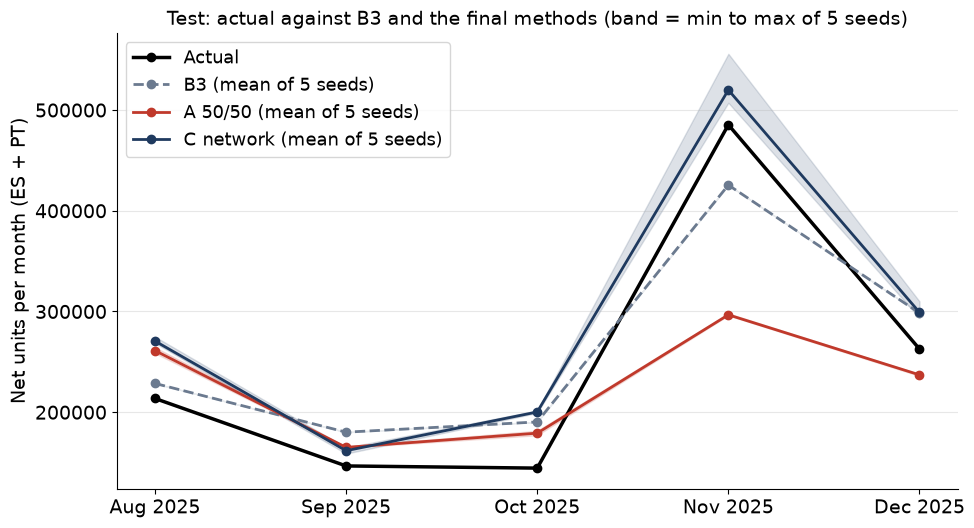

Guardado: evidence_dl_unidades/DLU56.png

--- Controlo 1: contagens ---
Previsões diárias das redes: 3.060 | esperado: 3.060 | em falta: 0 | negativas: 0
Previsões mensais dos 5 métodos: 250 | esperado: 250 | em falta: 0 | bate: True
Controlo 2: só meses do Test: True
Controlo 3: B3 recalculada do zero em Nov 2025 (Online ES): diferença 0.0 (esperado 0)
Controlo 4: a média 50/50 é a média da rede e do B3 (diferença máxima): 0.0 (esperado 0)
Controlo 5: alterar as unidades depois do corte (2025-06-30) não muda a previsão de Aug 2025 (diferença máxima, unidades): 0.0004375000007712515 (esperado 0)
Controlo 6: o WAPE do B3 no Test não depende das sementes (desvio entre sementes): 0.0 (esperado 0)


In [25]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# WARNING: this cell opens the Test (August to December 2025). Run it only once. If it fails, fix the code; the choices do not move.
# Uses the variables of the previous cells: forecast_step, scorecard, scorecard_daily, feat, SEEDS, TARGETS, MARKETS, split_of, cutoff_date, fc_b3, fcd_b3, b3_monthly, history, daily,
# TARGET (point 4), SPEC_A, CFG_A (points 5 to 10), SPEC_C, CFG_C (point 13), FINAL_A, FINAL_C (point 15).
for nome in ['forecast_step', 'scorecard', 'scorecard_daily', 'feat', 'SEEDS', 'TARGETS', 'MARKETS', 'split_of', 'cutoff_date', 'fc_b3', 'fcd_b3', 'b3_monthly', 'history', 'daily', 'TARGET',
             'SPEC_A', 'CFG_A', 'SPEC_C', 'CFG_C', 'FINAL_A', 'FINAL_C', 'monthly', 'fmt', 'pct', 'dec', 'save_table', 'save_fig', 'EVID']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including those of points 4, 10, 13 and 15), then this one.")

plt.rcParams.update({'font.size': 14})
d2 = lambda v: f"{v:.2f}".replace('.', ',')                        # does not depend on 'dec' (which ended up with another value in a previous cell)
REUSE_RAW = False                                                   # only change to True if the kernel dies after training: reads the already saved forecasts instead of training again
RAW = EVID / 'DLU53_raw_daily_forecasts.csv'
TEST_M = [t for t in TARGETS if split_of(t) == 'Test']
SPEC, CFG = {'A': SPEC_A, 'C': SPEC_C}, {'A': CFG_A, 'C': CFG_C}
METHODS = ['B3', 'A network', 'A 50/50', 'C network', 'C 50/50']
FINAIS = {FINAL_A: 'final, scenario A', FINAL_C: 'final, scenario C', 'B3': 'reference'}
print('Test months:', [str(m) for m in TEST_M], '| final methods chosen in Training:', FINAL_A, 'e', FINAL_C)

# ---------- train: each month rebuilds the network with data up to its cutoff (same rule as Training), 5 seeds ----------
t0 = time.time()
if REUSE_RAW and RAW.exists():
    nets = pd.read_csv(RAW, parse_dates=['day'])
    print('Forecasts read from', RAW)
else:
    parts = []
    for scen in ['A', 'C']:
        for seed in SEEDS:
            for m in TEST_M:
                p = forecast_step(m, SPEC[scen]['groups'], CFG[scen], seed, table=SPEC[scen]['table'], clip=SPEC[scen]['clip'])
                parts.append(p.assign(scen=scen, seed=seed))
        print(f'  scenario {scen}: {round((time.time() - t0) / 60, 1)} min (cumulative)')
    nets = pd.concat(parts, ignore_index=True)
    nets.to_csv(RAW, index=False)
print(f'Networks trained: {2 * len(SEEDS) * len(TEST_M) * len(MARKETS)} in {round((time.time() - t0) / 60, 1)} minutes')

# ---------- the forecasts of the 5 methods (daily and monthly), by seed ----------
nets['month'] = nets['day'].dt.to_period('M')
b3d = fcd_b3[fcd_b3['day'].dt.to_period('M').isin(TEST_M)].set_index(['mark', 'day'])['forecast'].sort_index()            # daily B3 (for the daily R²)
b3m = fc_b3[(fc_b3['method'] == 'B3 monthly') & fc_b3['month'].isin(TEST_M)].set_index(['mark', 'month'])['forecast'].sort_index()   # monthly B3 (the reference)
dly_parts, mon_parts = [], []
for seed in SEEDS:
    d_ = {'B3': b3d}
    m_ = {'B3': b3m}
    for scen in ['A', 'C']:
        n = nets[(nets['scen'] == scen) & (nets['seed'] == seed)].set_index(['mark', 'day'])['forecast'].sort_index()
        nm = n.groupby(['mark', n.index.get_level_values('day').to_period('M')]).sum()
        nm.index.names = ['mark', 'month']
        d_[f'{scen} network'], m_[f'{scen} network'] = n, nm.sort_index()
        d_[f'{scen} 50/50'], m_[f'{scen} 50/50'] = 0.5 * n + 0.5 * b3d, 0.5 * nm.sort_index() + 0.5 * b3m             # 50/50 average with B3
    for v in METHODS:
        dly_parts.append(d_[v].rename('forecast').reset_index().assign(method=f'{v}||{seed}'))
        mon_parts.append(m_[v].rename('forecast').reset_index().assign(method=f'{v}||{seed}'))
fcd18, fc18 = pd.concat(dly_parts, ignore_index=True), pd.concat(mon_parts, ignore_index=True)

sc18 = scorecard(fc18); sc18 = sc18[sc18['split'] == 'Test'].copy()
sd18 = scorecard_daily(fcd18); sd18 = sd18[sd18['split'] == 'Test'].copy()
for t in (sc18, sd18):
    t[['variant', 'seed']] = t['method'].str.split(r'\|\|', expand=True)
    t['seed'] = t['seed'].astype(int)
tot_m = sc18[sc18['mark'] == 'ES + PT'].set_index(['variant', 'seed'])
tot_d = sd18[sd18['mark'] == 'ES + PT'].set_index(['variant', 'seed'])
WT = {v: tot_m.loc[v]['WAPE'].sort_index() for v in METHODS}
vence = lambda x, y: (bool(x.mean() < y.mean() and int((x < y).sum()) >= 4), int((x < y).sum()))        # the same rule as Training (here only to report)

# ---------- DLU53: the main result (ES + PT) ----------
ctx = dlu42.set_index('Method')['WAPE mean'] if 'dlu42' in globals() else None
rows = []
for v in METHODS:
    r_b3 = vence(WT[v], WT['B3']) if v != 'B3' else (None, '')
    row = {'Method': v, 'Role': FINAIS.get(v, ''), 'WAPE mean': pct(WT[v].mean()), 'WAPE std (seeds)': pct(WT[v].std()), 'Bias mean': pct(tot_m.loc[v]['Bias'].mean()),
           'RMSE (units, monthly totals)': fmt(tot_m.loc[v]['RMSE'].mean()), 'R2 (monthly)': d2(tot_m.loc[v]['R2'].mean()), 'R2 (daily)': d2(tot_d.loc[v]['R2'].mean()),
           'Beats B3 (seeds of 5)': r_b3[1], 'Beats B3 by the rule': '' if r_b3[0] is None else ('yes' if r_b3[0] else 'no')}
    if ctx is not None:
        row['WAPE in Training, May-Jul (point 15)'] = ctx.get(v, '')
    rows.append(row)
dlu53 = pd.DataFrame(rows)
print('\n--- TEST (August to December 2025): the 5 methods, ES + PT, mean of the 5 seeds ---')
display(dlu53)
save_table(dlu53, 'DLU53', 'Test: B3, networks and 50/50 averages, ES + PT, units (5 months, mean of 5 seeds)', 'Aug-Dec 2025')
for nome in [FINAL_A, FINAL_C]:
    ok, n_ = vence(WT[nome], WT['B3'])
    print(f"Main result: {nome} has WAPE {pct(WT[nome].mean())} in the Test, against {pct(WT['B3'].mean())} of B3 | beats B3 by the rule: {'yes' if ok else 'no'} ({n_} of 5 seeds)")

# ---------- DLU54: by market ----------
rows = []
for mk in MARKETS:
    sm = sc18[sc18['mark'] == mk].groupby('variant')[['WAPE', 'Bias', 'RMSE', 'R2']].mean()
    sdm = sd18[sd18['mark'] == mk].groupby('variant')['R2'].mean()
    for v in METHODS:
        rows.append({'Market': mk, 'Method': v, 'WAPE': pct(sm.loc[v, 'WAPE']), 'Bias': pct(sm.loc[v, 'Bias']), 'RMSE (units, monthly)': fmt(sm.loc[v, 'RMSE']),
                     'R2 (monthly)': d2(sm.loc[v, 'R2']), 'R2 (daily)': d2(sdm.loc[v])})
dlu54 = pd.DataFrame(rows)
print('\n--- TEST: by market (mean of the 5 seeds) ---')
display(dlu54)
save_table(dlu54, 'DLU54', 'Test: B3, networks and 50/50 averages by market, units (5 months, mean of 5 seeds)', 'Aug-Dec 2025')

# ---------- DLU55: month by month, ES + PT ----------
act = monthly.set_index(['mark', 'month'])['net_units']
mens = {v: fc18[fc18['method'].str.startswith(v + '||')].groupby(['mark', 'month'])['forecast'].mean() for v in METHODS}
rows = []
for m in TEST_M:
    r_ = float(sum(act[(x, m)] for x in MARKETS))
    row = {'Month': m.strftime('%b %Y'), 'Actual (units)': fmt(r_)}
    for v in METHODS:
        f_ = float(sum(mens[v][(x, m)] for x in MARKETS))
        row[v] = fmt(f_); row[f'Error {v}'] = pct((f_ - r_) / r_)
    rows.append(row)
dlu55 = pd.DataFrame(rows)
print('\n--- TEST: month by month (ES + PT), forecast against actual, mean of the 5 seeds ---')
display(dlu55)
save_table(dlu55, 'DLU55', 'Test, month by month, ES + PT: forecast against actual for each method (units, mean of 5 seeds)', 'Aug-Dec 2025')

# ---------- chart: actual against B3 and the two final methods (the band is the minimum and maximum of the 5 seeds) ----------
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(TEST_M))
real = [float(sum(act[(k, m)] for k in MARKETS)) for m in TEST_M]
ax.plot(x, real, color='black', marker='o', lw=2.5, label='Actual')
for v, cor, ls in [('B3', '#6b7a8f', '--'), (FINAL_A, '#c0392b', '-'), (FINAL_C, '#1f3a5f', '-')]:
    por_seed = np.array([[float(sum(fc18[fc18['method'] == f'{v}||{s}'].set_index(['mark', 'month'])['forecast'][(k, m)] for k in MARKETS)) for m in TEST_M] for s in SEEDS])
    ax.plot(x, por_seed.mean(0), color=cor, ls=ls, marker='o', lw=2, label=f'{v} (mean of 5 seeds)')
    ax.fill_between(x, por_seed.min(0), por_seed.max(0), color=cor, alpha=0.15)
ax.set_xticks(x); ax.set_xticklabels([m.strftime('%b %Y') for m in TEST_M]); ax.set_ylabel('Net units per month (ES + PT)')
ax.set_title('Test: actual against B3 and the final methods (band = min to max of 5 seeds)', fontsize=14)
ax.legend(fontsize=13); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()
save_fig(fig, 'DLU56', 'Test: actual against B3 and the final methods, ES + PT, units (band = min to max of 5 seeds)', 'Aug-Dec 2025')

# ---------- checks ----------
n_dias = sum(pd.Period(m, 'M').days_in_month for m in TEST_M)
print('\n--- Check 1: counts ---')
print('Daily forecasts of the networks:', fmt(len(nets)), '| expected:', fmt(2 * len(SEEDS) * n_dias * len(MARKETS)), '| missing:', int(nets['forecast'].isna().sum()), '| negatives:', int((nets['forecast'] < 0).sum()))
print('Monthly forecasts of the 5 methods:', fmt(len(fc18)), '| expected:', fmt(len(METHODS) * len(SEEDS) * len(TEST_M) * len(MARKETS)), '| missing:', int(fc18['forecast'].isna().sum()),
      '| match:', bool(len(nets) == 2 * len(SEEDS) * n_dias * len(MARKETS) and len(fc18) == len(METHODS) * len(SEEDS) * len(TEST_M) * len(MARKETS) and fc18['forecast'].notna().all() and nets['forecast'].notna().all()))
print('Check 2: only Test months:', bool(set(fc18['month']) == set(TEST_M) and all(split_of(m) == 'Test' for m in TEST_M)))
m_chk = TEST_M[-2]; mk0 = MARKETS[0]
h0 = history(daily, m_chk); h0 = h0[h0['mark'] == mk0]
print(f"Check 3: B3 recalculated from scratch in {m_chk.strftime('%b %Y')} ({mk0}): difference", abs(float(b3_monthly(h0, m_chk, TARGET)) - float(b3m[(mk0, m_chk)])), '(expected 0)')
f50 = fc18[fc18['method'] == f'A 50/50||{SEEDS[0]}'].set_index(['mark', 'month'])['forecast'].sort_index()
fn = fc18[fc18['method'] == f'A network||{SEEDS[0]}'].set_index(['mark', 'month'])['forecast'].sort_index()
print('Check 4: the 50/50 average is the average of the network and B3 (largest difference):', float(np.abs(f50 - (fn + b3m) / 2).max()), '(expected 0)')
M_L = TEST_M[0]
rng = np.random.default_rng(1)
feat_x = feat.copy(); aft = feat_x['day'] > cutoff_date(M_L)
feat_x.loc[aft, 'y'] = feat_x.loc[aft, 'y'] + rng.integers(500, 5000, int(aft.sum()))
p_x = forecast_step(M_L, SPEC_A['groups'], CFG_A, SEEDS[0], table=feat_x, clip=SPEC_A['clip']).set_index(['mark', 'day'])['forecast'].sort_index()
p_o = nets[(nets['scen'] == 'A') & (nets['seed'] == SEEDS[0]) & (nets['month'] == M_L)].set_index(['mark', 'day'])['forecast'].sort_index()
print(f"Check 5: change the units after the cutoff ({cutoff_date(M_L).date()}) does not change the forecast of {M_L.strftime('%b %Y')} (largest difference, units):", float(np.abs(p_x - p_o).max()), '(expected 0)')
print('Check 6: the WAPE of B3 in the Test does not depend on the seeds (spread between seeds):', float(WT['B3'].std()), '(expected 0)')

# Efficiency: 2 scenarios × 5 seeds × 5 months × 2 markets = 100 trainings, each O(E·N·P) as in Training (N grows with the month); combining forecasts and metrics is O(K·S·M·P) with K = 5 methods, S = 5 seeds,
# M = 5 months and P = 2 markets (plus 153 days per market in the daily metrics). Space O(K·S·D) with D = days of the Test.

### 18a. Conclusions

**Confirmed (Test, August to December 2025, ES + PT, mean of the 5 seeds):**
- Checks: 3.060 daily network forecasts and 250 monthly ones, none missing; only Test months; B3 recalculated from scratch matches; the 50/50 is the average of the network and B3; B3 does not vary with the seed. Changing the units after the cutoff changes the August forecast by 0,0004 units, which is rounding and not leakage.
- The final methods chosen in Training have WAPE 25,1% (A 50/50, bias −9,1%) and 15,9% (network C, bias +15,9%). B3 has 15,2% (bias +5,6%). Neither beats B3 by the rule: A in 0 of 5 seeds and C in 1 of 5.
- Network A alone has WAPE 40,8%, bias −23,7% and a negative monthly R² (−0,47).
- Network C has WAPE 10,7% in ES, better than B3 (15,7%), and 32,9% in PT, worse than B3 (13,6%), with a bias of +32,0% in PT.
- In November (Black Friday) network A underestimates by 65,4%, A 50/50 underestimates by 38,9% and network C overestimates by 7,1%. B3 underestimates by 12,3%.
- The 50/50 average of C, which is not the final method, has WAPE 12,9% and beats B3 in 5 of 5 seeds.

**Derived:**
- Scenario A fails where Training did not see the seasonality. The final groups of A are day of the week, end of the month, holidays and sales periods. Campaigns and month of the year left in the Training rounds because they did not help from January to July, and that period has no Black Friday or Christmas. November weighs 39% of the Test units, and in November alone A 50/50 accumulates about 60% of the absolute error.
- Scenario C catches November because it uses the spend of the month, but it overestimates in most months. The error is concentrated in August and October (about 28% of the absolute error each) and in PT.
- The 50/50 average makes C worse in Training (11,3% against 8,0%) and improves it in the Test (12,9% against 15,9%). With 3 months of evidence, the choice in point 15 was fragile, as we warned.
- B3 has 15,2% in the Test and 27,3% in the 3 Training months. They are different months, so comparisons between periods are not direct.

**To validate:**
- Whether a scenario A with campaigns and month of the year would fix November. It is not tested now, because that would be re-choosing with the Test.
- Why network C overestimates in PT.
- The monthly R² has only 5 points. The daily R² of the 50/50 averages uses the daily B3, which does not give exactly the same monthly total as the monthly B3.
- Scenario C still assumes the spend of the month is known at the cutoff, which we still have to confirm with Parfois.

**Decision:**
- The result is reported as it is: no final method beats B3 on WAPE in the Test. It is a valid result to report.
- C 50/50 stays as an observation and does not replace the final method. The Test is not opened again or used to re-choose.

## 19. Module with the final models (`dl_unidades_final.py`)

**What we will do:** put the training and forecasting of the two final methods in a `.py` file, so they can be used without running the notebook (the colleague imports it in the DAG). Then confirm that it gives the same forecasts as the notebook.

**Goal:** be able to ask "forecast month M" and receive the forecast by market and total, from a table of variables.

**Decisions fixed before running:**
- **Which models:** the two final methods chosen in Training (point 15): **scenario A = 50/50 average of the mse_32_e100 network with B3**; **scenario C = network huber_32_e300**. Nothing is re-chosen with the Test. C 50/50, which beat B3 in the Test, stays only as an observation.
- **The module copies the notebook's choices:** columns, configurations and final method are written into the file from the notebook variables, so the two cannot diverge.
- **Training on demand:** the network is rebuilt with data up to the cutoff (last day of M−2), 5 seeds, as in the protocol. The package (weights, normalisation, spend limits, metadata) can be saved and loaded, with numbers and tensors only.
- **The input table** (one row per market and day) has `mark`, `day`, `y` (units of the day, may be missing from the cutoff on) and the columns of the scenario. The module does not build the variables; calendar, holidays, campaigns, sales periods and spend come from whoever calls it. Days after the cutoff never enter training.
- **No MLflow in this point:** registration is done in point 20.
- **Acceptance check:** daily and monthly forecasts equal to those of point 18, in August and December 2025, in both scenarios.

**Cautions:**
- Scenario C assumes the spend of month M is known at the cutoff, which we still have to confirm with Parfois. Scenario A does not need it.
- The sales periods of month M have to be known in advance. For a future month, whoever calls the module has to supply them.
- Neither final method beat B3 in the Test (point 18a). The module packages the fixed choices, not the "best in the Test".
- B3 needs 12 months of history before the month to forecast. The module refuses with a clear message if it is missing.

**Checks:** daily and monthly differences below 0,01 units; saving and loading the package gives the same forecast; it refuses an incomplete month, a table without columns and an unknown scenario; empty or changed units after the cutoff do not change the forecast; the last training day is the cutoff.

In [26]:
import pprint
import importlib
from pathlib import Path

# Uses the variables of the previous cells: FEATURE_GROUPS, SPEC_A, CFG_A, SPEC_C, CFG_C, CLIP_COLS, FIXED (point 5), FINAL_A and FINAL_C (point 15).
# Writes the file dl_unidades_final.py in the notebook folder, with the constants (columns, configurations, final method) taken from the notebook itself,
# so that the module and the notebook cannot diverge.
for nome in ['FEATURE_GROUPS', 'SPEC_A', 'CFG_A', 'SPEC_C', 'CFG_C', 'CLIP_COLS', 'FIXED', 'FINAL_A', 'FINAL_C']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again, then this one.")

def cenario(spec, cfg, final):
    cols = [c for g in spec['groups'] for c in FEATURE_GROUPS[g]]
    assert 'level_28d' not in cols, 'the module does not handle the level (the final models do not use it)'
    return {'cols': cols, 'cfg': {'loss': cfg['loss'], 'layers': list(cfg['layers']), 'epochs': int(cfg['epochs'])}, 'clip': bool(spec['clip']),
            'clip_cols': [c for c in cols if c in CLIP_COLS], 'method': final, 'blend_b3': final.endswith('50/50')}

SCEN = {'A': cenario(SPEC_A, CFG_A, FINAL_A), 'C': cenario(SPEC_C, CFG_C, FINAL_C)}
FIXED_MOD = {k: float(v) if k != 'batch' else int(v) for k, v in FIXED.items()}

MODULO = r'''"""
dl_unidades_final.py
Deep Learning · net units · final models of scenarios A and C: training, packaging and forecast of one month.

What it is for
- Forecast the net units of a month M (ES and PT) without running the notebook. The network is rebuilt with data up to the cutoff
  (last day of month M-2), as in the notebook protocol, and forecasts the days of M.
- Scenario A: final method = 50/50 average of the network with the B3 baseline. Does not use spend.
- Scenario C: final method = network alone. Uses the spend (spend_day, spend_month) of the day and of month M, assumed known.

Functions
- executar(tabela, mes, cenario)           trains and forecasts; returns (package, monthly forecast, daily forecast). It is the entry point.
- treinar(tabela, mes, cenario)            only trains; returns the package (weights, normalisation, limits, metadata).
- prever(pacote, tabela)                   daily forecast of an already trained package (trains nothing).
- previsao_mensal(pacote, tabela)          monthly forecast of the final method (ES, PT and ES + PT, with minimum and maximum across seeds).
- guardar_pacote(pacote, caminho) / carregar_pacote(caminho)    only tensors and simple types (no code inside).

The input table (one row per market and day) needs the columns: mark, day, y (net units of the day; may be missing from the cutoff on)
and the columns of COLUNAS[scenario]. It has to include the training days (up to the cutoff) and all days of month M. The module does not build the variables:
calendar, holidays, campaigns, sales periods and spend come from whoever calls it. Days after the cutoff are never used in training.

Rules that come from the notebook (do not change here without changing there):
- negative forecasts become 0, seed by seed; the final forecast is the mean of the seeds;
- the spend of a day to forecast is clipped to the minimum and maximum seen in training (scenario C);
- normalisation only with the training rows of each market; standard deviation 0 becomes 1; one model per market.
"""
import numpy as np
import pandas as pd
import torch
from torch import nn

MODULE_VERSION = '1.0'
MARKETS = ['Online ES', 'Online PT']
SEEDS = [0, 1, 2, 3, 4]
FIXED = __FIXED__
K_B3 = 3                                                           # recent months of the B3 baseline
SCENARIOS = __SCENARIOS__
COLUNAS = {k: v['cols'] for k, v in SCENARIOS.items()}
_LOSSES = {'l1': lambda: nn.L1Loss(), 'mse': lambda: nn.MSELoss(), 'huber': lambda: nn.HuberLoss(delta=FIXED['huber_delta'])}


def _make_net(d, layers):
    # MLP: d variables -> hidden layers with ReLU -> 1 number (units of the day, normalised)
    mods, prev = [], d
    for h in layers:
        mods += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    return nn.Sequential(*mods, nn.Linear(prev, 1))


def _fit_mlp(X, y, cfg, seed):
    # Same as in the notebook: the seed fixes the initial weights and the order of the rows in each epoch.
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    net = _make_net(X.shape[1], cfg['layers'])
    opt = torch.optim.Adam(net.parameters(), lr=FIXED['lr'], weight_decay=FIXED['weight_decay'])
    lossf = _LOSSES[cfg['loss']]()
    Xt = torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))
    yt = torch.from_numpy(np.ascontiguousarray(y, dtype=np.float32)).reshape(-1, 1)
    n, bs = len(Xt), int(FIXED['batch'])
    for _ in range(cfg['epochs']):
        perm = torch.randperm(n, generator=gen)
        for i in range(0, n, bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            lossf(net(Xt[idx]), yt[idx]).backward()
            opt.step()
    return net


def _predict(net, X):
    net.eval()
    with torch.no_grad():
        return net(torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))).numpy().ravel()


def _cenario(cenario):
    if cenario not in SCENARIOS:
        raise ValueError(f"Unknown scenario '{cenario}'. Options: {list(SCENARIOS)}")
    return SCENARIOS[cenario]


def _corte(mes):
    return (pd.Period(mes, 'M') - 2).end_time.normalize()          # last day of month M-2


def _tabela(tabela, cols):
    # validates the columns, converts the day and sorts by market and day (the row order changes the training batches)
    falta = [c for c in ['mark', 'day', 'y'] + list(cols) if c not in tabela.columns]
    if falta:
        raise ValueError(f'Missing columns in the table: {falta}')
    t = tabela[['mark', 'day', 'y'] + list(cols)].copy()
    t['day'] = pd.to_datetime(t['day'])
    return t.sort_values(['mark', 'day'], kind='stable').reset_index(drop=True)


def _dias_do_mes(t, mes):
    m = pd.Period(mes, 'M')
    tg = t[t['day'].dt.to_period('M') == m]
    esperado = m.days_in_month
    for mk in MARKETS:
        n = int((tg['mark'] == mk).sum())
        if n != esperado:
            raise ValueError(f'The table has {n} days of {mk} in {m}, expected {esperado}.')
    return tg


def treinar(tabela, mes, cenario, seeds=None):
    """Trains one model per market and seed with data up to the cutoff of month `mes` and returns the package."""
    torch.set_num_threads(1)                                       # tiny networks: a single processing thread always gives the same result
    sc = _cenario(cenario)
    cols, seeds = sc['cols'], list(SEEDS if seeds is None else seeds)
    t = _tabela(tabela, cols)
    _dias_do_mes(t, mes)                                           # the month to forecast has to be complete (calendar variables)
    corte = _corte(mes)
    tr_all = t[t['day'] <= corte]                                  # only rows up to the cutoff
    if tr_all[['y'] + cols].isna().any().any():
        raise ValueError('There are missing values in the training rows (up to the cutoff).')
    pacote = {'module_version': MODULE_VERSION, 'scenario': cenario, 'method': sc['method'], 'month': str(pd.Period(mes, 'M')), 'cutoff': str(corte.date()),
              'cols': list(cols), 'cfg': dict(sc['cfg']), 'clip': bool(sc['clip']), 'seeds': seeds, 'markets': {}}
    for mk in MARKETS:
        tr = tr_all[tr_all['mark'] == mk]
        X = tr[cols].to_numpy(float)
        mu, sd = X.mean(0), X.std(0)
        sd[sd == 0] = 1.0                                          # constant column in training
        y = tr['y'].to_numpy(float)
        ymu, ysd = float(y.mean()), float(y.std())
        clip = {c: [float(tr[c].min()), float(tr[c].max())] for c in sc['clip_cols']} if sc['clip'] else {}
        states = []
        for s in seeds:
            net = _fit_mlp((X - mu) / sd, (y - ymu) / ysd, sc['cfg'], s)
            states.append({k: v.detach().clone() for k, v in net.state_dict().items()})
        pacote['markets'][mk] = {'states': states, 'clip': clip, 'mu': mu.tolist(), 'sd': sd.tolist(), 'ymu': ymu, 'ysd': ysd, 'n_train': int(len(tr)),
                                 'last_train_day': str(tr['day'].max().date())}
    return pacote


def prever(pacote, tabela):
    """Daily forecast (mark, day, forecast = mean of the seeds, seed_<s> = one column per seed). Trains nothing."""
    cols, seeds = pacote['cols'], pacote['seeds']
    t = _tabela(tabela, cols)
    tg_all = _dias_do_mes(t, pacote['month'])
    out = []
    for mk in MARKETS:
        p = pacote['markets'][mk]
        tg = tg_all[tg_all['mark'] == mk].copy()
        for c, (lo, hi) in p['clip'].items():                      # values outside the training range become the minimum or the maximum seen
            tg[c] = tg[c].clip(lo, hi)
        if tg[cols].isna().any().any():
            raise ValueError(f'There are missing values in the variables of the month to forecast ({mk}).')
        X = (tg[cols].to_numpy(float) - np.array(p['mu'])) / np.array(p['sd'])
        df = pd.DataFrame({'mark': tg['mark'].to_numpy(), 'day': tg['day'].to_numpy()})
        for s, state in zip(seeds, p['states']):
            net = _make_net(X.shape[1], tuple(pacote['cfg']['layers']))
            net.load_state_dict(state)
            df[f'seed_{s}'] = np.maximum(_predict(net, X) * p['ysd'] + p['ymu'], 0.0)
        out.append(df)
    d = pd.concat(out, ignore_index=True)
    d['forecast'] = d[[f'seed_{s}' for s in seeds]].mean(axis=1)
    return d[['mark', 'day', 'forecast'] + [f'seed_{s}' for s in seeds]]


def b3_mensal(tabela, mes):
    """B3 baseline of each market: units of the same month of the previous year x (3 recent months up to the cutoff / the same 3 months a year earlier)."""
    t = _tabela(tabela, [])
    m = pd.Period(mes, 'M')
    h = t[t['day'] <= _corte(m)]
    mt = h.assign(month=h['day'].dt.to_period('M')).groupby(['mark', 'month'])['y'].sum()
    last = m - 2
    recent = [last - i for i in range(K_B3)]
    prior = [p - 12 for p in recent]
    base = m - 12
    out = {}
    for mk in MARKETS:
        s = mt.loc[mk] if mk in mt.index.get_level_values('mark') else pd.Series(dtype=float)
        if any(p not in s.index for p in recent + prior + [base]):
            raise ValueError(f'Not enough history for the B3 of {m} ({mk}): it needs the months {base}, {recent} and {prior}.')
        out[mk] = float(s[base] * s[recent].sum() / s[prior].sum())
    return out


def previsao_mensal(pacote, tabela):
    """Monthly forecast of the scenario final method (A: 50/50 average of the network with B3; C: the network), by market and total, with minimum and maximum across seeds."""
    seeds, sc = pacote['seeds'], _cenario(pacote['scenario'])
    d = prever(pacote, tabela)
    net = d.groupby('mark')[[f'seed_{s}' for s in seeds]].sum().reindex(MARKETS)           # units of the month, by market and seed
    if sc['blend_b3']:
        b3 = pd.Series(b3_mensal(tabela, pacote['month'])).reindex(MARKETS)
        fin = 0.5 * net + 0.5 * b3.to_numpy()[:, None]
    else:
        b3, fin = pd.Series(np.nan, index=MARKETS), net
    rows = []
    for mk in MARKETS + ['ES + PT']:
        f, n = (fin.sum(), net.sum()) if mk == 'ES + PT' else (fin.loc[mk], net.loc[mk])
        rows.append({'month': pacote['month'], 'scenario': pacote['scenario'], 'method': pacote['method'], 'mark': mk, 'forecast': float(f.mean()),
                     'forecast_min': float(f.min()), 'forecast_max': float(f.max()), 'net_only': float(n.mean()),
                     'b3': float(b3.sum() if mk == 'ES + PT' else b3[mk]) if sc['blend_b3'] else np.nan})
    return pd.DataFrame(rows)


def executar(tabela, mes, cenario, seeds=None):
    """Entry point: trains with data up to the cutoff and forecasts the month. Returns (package, monthly forecast, daily forecast)."""
    pacote = treinar(tabela, mes, cenario, seeds)
    return pacote, previsao_mensal(pacote, tabela), prever(pacote, tabela)


def guardar_pacote(pacote, caminho):
    torch.save(pacote, caminho)


def carregar_pacote(caminho):
    return torch.load(caminho, weights_only=True)                  # only reads numbers, text and tensors: it does not run code
'''
MODULO = MODULO.replace('__FIXED__', pprint.pformat(FIXED_MOD)).replace('__SCENARIOS__', pprint.pformat(SCEN, width=140, sort_dicts=False))
Path('dl_unidades_final.py').write_text(MODULO, encoding='utf-8')
compile(MODULO, 'dl_unidades_final.py', 'exec')            # fails here already if the code has a syntax error
print('Written: dl_unidades_final.py |', len(MODULO.splitlines()), 'lines')
for k, v in SCEN.items():
    print(f"Scenario {k}: final method {v['method']} | {len(v['cols'])} columns | configuration {v['cfg']} | spend clipping: {v['clip_cols'] if v['clip'] else 'no'} | 50/50 average with B3: {v['blend_b3']}")

# Efficiency: only writes a text file, O(L) with L = lines of the module; the training and forecasting of the module have the cost of the notebook.

Escrito: dl_unidades_final.py | 223 linhas
Cenário A: método final A 50/50 | 10 colunas | configuração {'loss': 'mse', 'layers': [32], 'epochs': 100} | corte do investimento: [] | média 50/50 com a B3: True
Cenário C: método final C network | 12 colunas | configuração {'loss': 'huber', 'layers': [32], 'epochs': 300} | corte do investimento: ['spend_day', 'spend_month'] | média 50/50 com a B3: False


In [27]:
import time
import importlib
import numpy as np
import pandas as pd

# Uses the variables of the previous cells: feat, nets, fc18 (point 18), TEST_M, SEEDS, MARKETS, FINAL_A, FINAL_C, cutoff_date, fmt, save_table and EVID.
# The file dl_unidades_final.py has to be written (previous cell).
for nome in ['feat', 'nets', 'fc18', 'TEST_M', 'SEEDS', 'MARKETS', 'FINAL_A', 'FINAL_C', 'cutoff_date', 'fmt', 'save_table', 'EVID']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including the one of point 18) and the cell that writes the module, then this one.")
import dl_unidades_final as U
importlib.reload(U)
print('Module loaded, version', U.MODULE_VERSION, '| scenarios:', list(U.SCENARIOS))

# ---------- acceptance check: the module gives the same forecasts as the notebook (those of point 18), in August and December 2025, in both scenarios ----------
FINAL = {'A': FINAL_A, 'C': FINAL_C}
rows, ultimo = [], {}
for scen in ['A', 'C']:
    for m in [TEST_M[0], TEST_M[-1]]:
        t0 = time.time()
        pacote, mensal, diario = U.executar(feat, m, scen)
        seg = time.time() - t0
        ref = nets[(nets['scen'] == scen) & (nets['day'].dt.to_period('M') == m)]
        dif_d = 0.0
        for s in SEEDS:
            r = ref[ref['seed'] == s].set_index(['mark', 'day'])['forecast'].sort_index()
            o = diario.set_index(['mark', 'day'])[f'seed_{s}'].sort_index()
            dif_d = max(dif_d, float(np.abs(r.to_numpy() - o.to_numpy()).max()))
        rm = fc18[fc18['method'].str.startswith(FINAL[scen] + '||') & (fc18['month'] == m)]
        por_mark = rm.groupby('mark')['forecast'].mean()
        tot_seed = rm.groupby('method')['forecast'].sum()
        dif_m = max(abs(float(mensal[mensal['mark'] == mk]['forecast'].iloc[0]) - float(por_mark[mk])) for mk in MARKETS)
        tot = mensal[mensal['mark'] == 'ES + PT'].iloc[0]
        dif_m = max(dif_m, abs(float(tot['forecast_min']) - float(tot_seed.min())), abs(float(tot['forecast_max']) - float(tot_seed.max())))
        rows.append({'Scenario': scen, 'Final method': FINAL[scen], 'Month': m.strftime('%b %Y'), 'Max daily difference vs notebook (units)': f'{dif_d:.4f}', 'Max monthly difference vs notebook (units)': f'{dif_m:.4f}',
                     'Module forecast ES + PT (units)': fmt(tot['forecast']), 'Seconds (5 seeds, 2 markets)': round(seg, 1)})
        ultimo[scen] = (pacote, m, diario, mensal)
dlu57 = pd.DataFrame(rows)
print('\n--- Acceptance check: the module against the notebook (point 18) ---')
display(dlu57)
save_table(dlu57, 'DLU57', 'Acceptance check: the final-model module gives the same forecasts as the notebook (units, Aug and Dec 2025)', 'Aug and Dec 2025')
print('Match (differences below 0,01 units; the rest is rounding):', bool((dlu57['Max daily difference vs notebook (units)'].astype(float) < 0.01).all() and (dlu57['Max monthly difference vs notebook (units)'].astype(float) < 0.01).all()))

# ---------- example of what the module returns (December 2025, scenario A and C) ----------
ex = pd.concat([ultimo[s][3] for s in ['A', 'C']], ignore_index=True)
ex_show = ex.assign(**{c: ex[c].map(fmt) for c in ['forecast', 'forecast_min', 'forecast_max', 'net_only', 'b3']})
print('\n--- Example: monthly forecast of the module (December 2025) ---')
display(ex_show)
save_table(ex_show, 'DLU58', 'Example of the monthly forecast returned by the module, final methods of scenarios A and C (units, Dec 2025)', 'Dec 2025')

# ---------- package and contract checks ----------
pacote, m, diario, mensal = ultimo['A']
caminho = EVID / 'pacote_teste.pt'
U.guardar_pacote(pacote, caminho)
lido = U.carregar_pacote(caminho)
d_lido = U.prever(lido, feat)
print('\n--- Package and contract checks ---')
print('Check 1: saving and loading the package gives the same forecast (largest difference, units):', float(np.abs(d_lido['forecast'].to_numpy() - diario['forecast'].to_numpy()).max()),
      '| size (KB):', fmt(caminho.stat().st_size / 1024))
caminho.unlink()                                                    # the file was only for testing
try:
    U.prever(lido, feat[feat['day'] < pd.Timestamp(m.start_time) + pd.Timedelta(days=10)]); recusa = False
except ValueError:
    recusa = True
print('Check 2: refuses to forecast with an incomplete month:', recusa)
try:
    U.executar(feat.drop(columns=['hol_wd']), m, 'A'); falta = False
except ValueError:
    falta = True
print('Check 3: refuses a table without the required columns:', falta)
try:
    U.executar(feat, m, 'X'); desconhecido = False
except ValueError:
    desconhecido = True
print('Check 4: refuses an unknown scenario:', desconhecido)

# as in production: units after the cutoff do not exist (they stay empty) and, in another test, they change; the forecast cannot change
corte = cutoff_date(m)
f_nan = feat.copy(); f_nan.loc[f_nan['day'] > corte, 'y'] = np.nan
rng = np.random.default_rng(1)
f_rui = feat.copy(); aft = f_rui['day'] > corte
f_rui.loc[aft, 'y'] = f_rui.loc[aft, 'y'] + rng.integers(500, 5000, int(aft.sum()))
base = mensal[mensal['mark'] == 'ES + PT']['forecast'].iloc[0]
v_nan = U.executar(f_nan, m, 'A')[1]; v_rui = U.executar(f_rui, m, 'A')[1]
print(f"Check 5: empty units after the cutoff ({corte.date()}), as in production. Difference in the ES + PT total (units):", abs(float(v_nan[v_nan['mark'] == 'ES + PT']['forecast'].iloc[0]) - float(base)), '(expected close to 0)')
print('Check 6: units changed after the cutoff. Difference in the ES + PT total (units):', abs(float(v_rui[v_rui['mark'] == 'ES + PT']['forecast'].iloc[0]) - float(base)), '(expected close to 0)')
print('Check 7: last training day of each market =', {mk: pacote['markets'][mk]['last_train_day'] for mk in MARKETS}, '| cutoff', corte.date(), '| match:',
      all(pacote['markets'][mk]['last_train_day'] == str(corte.date()) for mk in MARKETS))

# Efficiency: the module trains S seeds × 2 markets networks, each O(E·N·P) (as in the notebook); forecasting is O(S·D·P) with D = days of the month; B3 is O(N) to add up the months of the history.
# This cell does 4 + 2 runs (4 of the acceptance check and 2 of the cutoff tests), each with 10 trainings.

Módulo carregado, versão 1.0 | cenários: ['A', 'C']

--- Controlo de aceitação: o módulo contra o notebook (ponto 18) ---


,Scenario,Final method,Month,Max daily difference vs notebook (units),Max monthly difference vs notebook (units),Module forecast ES + PT (units),"Seconds (5 seeds, 2 markets)"
0,A,A 50/50,Aug 2025,0.0004,0.0042,261.190,4.5
1,A,A 50/50,Dec 2025,0.0005,0.0039,237.089,5.3
2,C,C network,Aug 2025,0.0003,0.0128,270.697,13.0
3,C,C network,Dec 2025,0.0005,0.0222,299.101,15.5


Guardado: evidence_dl_unidades/DLU57.csv
Bate (diferenças abaixo de 0,01 unidades; o resto é arredondamento): False

--- Exemplo: previsão mensal do módulo (dezembro de 2025) ---


,month,scenario,method,mark,forecast,forecast_min,forecast_max,net_only,b3
0,2025-12,A,A 50/50,Online ES,176.944,176.173,177.495,134.370,219.518
1,2025-12,A,A 50/50,Online PT,60.145,59.819,60.467,41.350,78.940
2,2025-12,A,A 50/50,ES + PT,237.089,235.991,237.804,175.720,298.458
3,2025-12,C,C network,Online ES,205.520,197.416,212.067,205.520,-
4,2025-12,C,C network,Online PT,93.582,88.660,97.987,93.582,-
5,2025-12,C,C network,ES + PT,299.101,293.603,310.054,299.101,-


Guardado: evidence_dl_unidades/DLU58.csv

--- Controlos do pacote e do contrato ---
Controlo 1: guardar e carregar o pacote dá a mesma previsão (diferença máxima, unidades): 0.0 | tamanho (KB): 28
Controlo 2: recusa prever com um mês incompleto: True
Controlo 3: recusa uma tabela sem as colunas necessárias: True
Controlo 4: recusa um cenário desconhecido: True
Controlo 5: unidades vazias depois do corte (2025-10-31), como em produção. Diferença no total ES + PT (unidades): 0.0 (esperado perto de 0)
Controlo 6: unidades alteradas depois do corte. Diferença no total ES + PT (unidades): 0.0 (esperado perto de 0)
Controlo 7: último dia de treino de cada mercado = {'Online ES': '2025-10-31', 'Online PT': '2025-10-31'} | corte 2025-10-31 | bate: True


## 19b. Diagnostic of the scenario C difference

**What we will do:** measure whether the notebook and the module reproduce their own forecast. Scenario C, seed 0, is trained again for August and December 2025. The notebook is compared with itself, the module with itself, and the two with each other.

**Goal:** find out whether the difference of 0,0128 and 0,0222 units in point 19 comes from numerical noise or from a real difference between the module and the notebook.

**Rule fixed before running:**
- If the notebook (saved against retrained) and the module (two runs) give a difference of 0,0000 and the module against the notebook gives more than 0: it is a real difference in the module. We look for it and fix it, and the module is not accepted.
- If the notebook or the module already differ from themselves: it is numerical noise on this machine. The tolerance becomes the largest difference of the monthly total ES + PT (seed 0) between repetitions of the same code, and never less than 0,01 units. It applies to both scenarios and to point 20.
- In no case do we write "rounding" without this proof.

**Checks:** the comparison of the saved notebook against the retrained notebook is the measure of reproducibility; the four rows per month must all be filled.

In [29]:
import numpy as np
import pandas as pd

# Diagnostic of the scenario C difference (point 19): measures whether the notebook and the module reproduce their own forecast.
# Scenario C, seed 0, August and December 2025. Uses: nets (point 18), forecast_step, SPEC_C, CFG_C, feat, TEST_M, save_table and the module U.
for nome in ['nets', 'forecast_step', 'SPEC_C', 'CFG_C', 'feat', 'TEST_M', 'save_table', 'U']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the cells of point 19 first.")

def serie(df, col='forecast'):
    return df.set_index(['mark', 'day'])[col].sort_index()

rows = []
for m in [TEST_M[0], TEST_M[-1]]:
    guardado = serie(nets[(nets['scen'] == 'C') & (nets['seed'] == 0) & (nets['day'].dt.to_period('M') == m)])               # the forecasts of point 18
    nb = serie(forecast_step(m, SPEC_C['groups'], CFG_C, 0, table=SPEC_C['table'], clip=SPEC_C['clip']))                       # notebook, retrained now
    m1 = serie(U.executar(feat, m, 'C', seeds=[0])[2], 'seed_0')                                                                # module, 1st run
    m2 = serie(U.executar(feat, m, 'C', seeds=[0])[2], 'seed_0')                                                                # module, 2nd run
    pares = [('Notebook saved (point 18) vs notebook retrained now', guardado, nb), ('Module vs module (2 runs)', m1, m2),
             ('Module vs notebook retrained now', m1, nb), ('Module vs notebook saved (point 18)', m1, guardado)]
    for nome, a, b in pares:
        rows.append({'Month': m.strftime('%b %Y'), 'Comparison': nome, 'Max daily difference (units)': f'{float((a - b).abs().max()):.4f}',
                     'Monthly total ES + PT difference (units)': f'{abs(float(a.sum() - b.sum())):.4f}'})
diag = pd.DataFrame(rows)
print('--- Diagnostic: scenario C, seed 0 ---')
display(diag)
save_table(diag, 'DLU57b', 'Diagnostic of the scenario C difference: reproducibility of notebook and module (units, seed 0, Aug and Dec 2025)', 'Aug and Dec 2025')

# Efficiency: 3 network trainings per month (1 from the notebook and 2 from the module, each with 2 markets), O(E·N·P) each; the comparisons are O(D).

--- Diagnóstico: cenário C, semente 0 ---


,Month,Comparison,Max daily difference (units),Monthly total ES + PT difference (units)
0,Aug 2025,Notebook saved (point 18) vs notebook retraine...,0.0003,0.0145
1,Aug 2025,Module vs module (2 runs),0.0000,0.0000
2,Aug 2025,Module vs notebook retrained now,0.0000,0.0000
3,Aug 2025,Module vs notebook saved (point 18),0.0003,0.0145
4,Dec 2025,Notebook saved (point 18) vs notebook retraine...,0.0003,0.0091
5,Dec 2025,Module vs module (2 runs),0.0000,0.0000
6,Dec 2025,Module vs notebook retrained now,0.0000,0.0000
7,Dec 2025,Module vs notebook saved (point 18),0.0003,0.0091


Guardado: evidence_dl_unidades/DLU57b.csv


### 19b. Conclusions

- **Confirmed:** the module is identical to the notebook retrained now (scenario C, seed 0, August and December 2025): difference 0,0000 per day and in the monthly total. The module also repeats itself with 0,0000.
- **Confirmed:** the forecasts saved in point 18 are not reproduced exactly when the notebook is retrained: maximum daily difference of 0,0003 and monthly total ES + PT of 0,0145 (August) and 0,0091 (December) units. The difference in point 19 comes from there, not from the module.
- **Derived:** the deviation is of the order of 0,00001% of the units of the month. The Test WAPE and the conclusions of 18a do not change, and nothing is recalculated.
- **To validate:** why the training of point 18 is not repeated exactly (the code is the same and so is the machine). It may depend on the state of the session in which the networks were trained. It does not affect the conclusions, but it is recorded.
- **Decision:** the rule of 19b would give a tolerance of 0,0145, measured with seed 0 only, and it still would not cover the 0,0222 of December. Instead of widening it, the acceptance now compares the module with the notebook retrained now, and the tolerance of 0,01 stays.

## 19c. Acceptance redone: the module against the notebook retrained now

**What we will do:** repeat the acceptance of point 19 with the corrected reference. The notebook is trained again (5 seeds, two scenarios, August and December 2025) and compared with the module.

**Rule fixed before running:** tolerance of 0,01 units, the same as in point 19. It is not widened. It has to give 0,0000 or very close. If any difference is above 0,01, it is a real difference and the module is not accepted.

**Checks:** the module does not train with data after the cutoff (already proven in 19). Maximum daily difference and monthly difference (by market, total ES + PT and minimum and maximum between seeds) below 0,01 in the four combinations.

In [30]:
import time
import numpy as np
import pandas as pd

# Acceptance of point 19 redone: the module against the notebook retrained now (same machine and session), 5 seeds.
# Uses: forecast_step, SPEC_A, SPEC_C, CFG_A, CFG_C, b3m (point 18), feat, SEEDS, MARKETS, TEST_M, FINAL_A, FINAL_C, fmt, save_table and the module U.
for nome in ['forecast_step', 'SPEC_A', 'SPEC_C', 'CFG_A', 'CFG_C', 'b3m', 'feat', 'SEEDS', 'MARKETS', 'TEST_M', 'FINAL_A', 'FINAL_C', 'fmt', 'save_table', 'U']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the cells of points 18 and 19 first.")

SPEC, CFGS, FIN = {'A': SPEC_A, 'C': SPEC_C}, {'A': CFG_A, 'C': CFG_C}, {'A': FINAL_A, 'C': FINAL_C}
rows = []
for scen in ['A', 'C']:
    for m in [TEST_M[0], TEST_M[-1]]:
        t0 = time.time()
        # notebook retrained now: one daily forecast per seed
        nb = {s: forecast_step(m, SPEC[scen]['groups'], CFGS[scen], s, table=SPEC[scen]['table'], clip=SPEC[scen]['clip']).set_index(['mark', 'day'])['forecast'].sort_index() for s in SEEDS}
        _, mensal, diario = U.executar(feat, m, scen)                                           # module
        dd = diario.set_index(['mark', 'day']).sort_index()
        dif_d = max(float((nb[s] - dd[f'seed_{s}']).abs().max()) for s in SEEDS)
        # monthly forecast of the final method calculated by the notebook: sum of the days by market and seed; in scenario A, 50/50 average with the B3 of point 18
        net = pd.DataFrame({s: nb[s].groupby(level='mark').sum() for s in SEEDS}).reindex(MARKETS)
        if scen == 'A':
            b3 = pd.Series({mk: float(b3m.loc[(mk, m)]) for mk in MARKETS})
            fin = 0.5 * net + 0.5 * b3.to_numpy()[:, None]
        else:
            fin = net
        dif_m = max(abs(float(mensal[mensal['mark'] == mk]['forecast'].iloc[0]) - float(fin.loc[mk].mean())) for mk in MARKETS)
        tot = fin.sum()                                                                          # ES + PT per seed
        t = mensal[mensal['mark'] == 'ES + PT'].iloc[0]
        dif_m = max(dif_m, abs(float(t['forecast']) - float(tot.mean())), abs(float(t['forecast_min']) - float(tot.min())), abs(float(t['forecast_max']) - float(tot.max())))
        rows.append({'Scenario': scen, 'Final method': FIN[scen], 'Month': m.strftime('%b %Y'), 'Max daily difference vs notebook retrained (units)': f'{dif_d:.4f}',
                     'Max monthly difference vs notebook retrained (units)': f'{dif_m:.4f}', 'Module forecast ES + PT (units)': fmt(t['forecast']), 'Seconds': round(time.time() - t0, 1)})
dlu57c = pd.DataFrame(rows)
print('--- Acceptance redone: the module against the notebook retrained now ---')
display(dlu57c)
save_table(dlu57c, 'DLU57c', 'Acceptance check redone: the final-model module against the notebook retrained now (units, Aug and Dec 2025, 5 seeds)', 'Aug and Dec 2025')
ok = bool((dlu57c['Max daily difference vs notebook retrained (units)'].astype(float) < 0.01).all() and (dlu57c['Max monthly difference vs notebook retrained (units)'].astype(float) < 0.01).all())
print('Match (differences below 0,01 units):', ok)

# Efficiency: per combination, 5 seeds × 2 markets of network trainings in the notebook and as many in the module, O(E·N·P) each; the comparisons are O(S·D) with D days of the month.

--- Aceitação refeita: o módulo contra o notebook retreinado agora ---


,Scenario,Final method,Month,Max daily difference vs notebook retrained (units),Max monthly difference vs notebook retrained (units),Module forecast ES + PT (units),Seconds
0,A,A 50/50,Aug 2025,0.0000,0.0000,261.190,9.2
1,A,A 50/50,Dec 2025,0.0000,0.0000,237.089,10.4
2,C,C network,Aug 2025,0.0000,0.0000,270.697,26.2
3,C,C network,Dec 2025,0.0000,0.0000,299.101,30.3


Guardado: evidence_dl_unidades/DLU57c.csv
Bate (diferenças abaixo de 0,01 unidades): True


### 19a. Conclusions

- **Confirmed:** the module `dl_unidades_final.py` packages the two final methods from point 15 (A 50/50 and C network), with the constants copied from the notebook. It is identical to the notebook retrained now: difference 0,0000 per day and in the monthly total, with 5 seeds, in both scenarios, in August and December 2025 (19c).
- **Confirmed:** saving and loading the package gives the same forecast. The module refuses an incomplete month, a table without the required columns and an unknown scenario. Empty or changed units after the cutoff do not change the forecast, and the last training day is the cutoff (31 October 2025).
- **Confirmed:** the first acceptance, against the saved forecasts of point 18, failed the 0,01 limit in scenario C (0,0128 and 0,0222 units). The diagnostic (19b) showed that the difference comes from those forecasts not being reproduced exactly when retrained (up to 0,0003 per day), and not from the module.
- **Derived:** the module takes about 5 seconds (scenario A) and 15 seconds (scenario C) to train and forecast one month, with 5 seeds and 2 markets.
- **To validate:** the spend of month M known at the cutoff (scenario C), the sales periods known in advance, the definition of units (sold + cancelled, without returns) and B3 needing 12 months of history. The module does not build the variables: calendar, holidays, campaigns, sales periods and spend come from whoever calls it.
- **Decision:** the module is accepted as it is. Point 20 registers this same file.

## 20. Registering the final models in MLflow

**What we will do:** register in MLflow the two final methods from point 15 as models that can be loaded by name, without running the notebook. It is the only point that writes to MLflow.

**Goal:** that the colleague (or me, a month from now) can load `models:/dl_unidades_cenario_A@producao`, pass the table and the month, and receive the forecast.

**Decisions fixed before running:**
- **Two registered models, one per scenario:** `dl_unidades_cenario_A` (A 50/50) and `dl_unidades_cenario_C` (network C). They are the two methods chosen in Training (point 15). The Test chooses nothing.
- **What is registered is the method, not the weights of one month:** to forecast month M the network trains with data up to the last day of M−2. Frozen weights would only serve one month. Each model carries inside the files `dl_unidades_final.py` and `dl_unidades_mlflow.py`, the input contract (columns and types), an input example and the library versions.
- **How to use it:** `predict(table, params={'month': 'YYYY-MM'})`. The `month` parameter is required and has no default value, so that the model refuses instead of forecasting an arbitrary month. With `output='daily'` it returns the daily forecast.
- **Alias `producao`:** it points, in each model, to the registered version. It means "version in use for this scenario", not "the best one". Which scenario is used depends on confirming the spend (scenario C) with Parfois.
- **What stays in the run:** the parameters of the method and metrics already calculated in points 15 and 18 (WAPE, bias and RMSE of ES + PT, plus the WAPE of B3 as a reference). Nothing new is calculated here. The Test is recorded for transparency.
- **No duplicates:** each version carries a fingerprint (module code, wrapper code and scenario). If an identical version already exists, no other is registered. `FORCAR = True` forces a new version.
- **Server and experiment:** `http://mlflow:5000`, the same as the sales notebook. Experiment `capstone_dl_unidades_liquidas`.
- **Acceptance check:** the model loaded by alias gives the forecast for December 2025 equal to that of the notebook retrained now (reference from 19c), with a difference below 0,01 units, in both scenarios. It is repeated in a new process, in another folder, with only the URI and a CSV.

**Cautions:**
- Neither final method beat B3 in the Test (point 18a). The registration keeps the choices fixed in Training, not "the best in the Test". The run carries this information in tags.
- Scenario C assumes the spend of month M is known at the cutoff. The definition of units (sold + cancelled, without returns) also still has to be confirmed. Both are kept in run tags.
- The input table still has to bring the variables already built (calendar, holidays, sales periods, spend). The registered model does not build them.
- If the module changes after registration, the fingerprint changes and the cell registers a new version.

**Checks:** difference below 0,01 units against the notebook (loaded by alias and in a new process); refuses without `month`, without the contract columns and with an incomplete month; empty units after the cutoff pass through the contract without changing the forecast; running the registration again does not create new versions; each model has version, alias, method, metrics and fingerprint.

**How to use it outside the notebook:**
```python
import mlflow, pandas as pd
mlflow.set_tracking_uri('http://mlflow:5000')
model = mlflow.pyfunc.load_model('models:/dl_unidades_cenario_A@producao')
forecast = model.predict(table, params={'month': '2026-02'})   # table: mark, day, y and the contract columns, with the training days and all days of the month
```

In [ ]:
import os
import sys
import hashlib
import importlib
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import mlflow
import mlflow.pyfunc
from mlflow.models import infer_signature, ModelSignature
from mlflow.types.schema import ParamSchema, ParamSpec, DataType
from mlflow.tracking import MlflowClient

# Uses the variables of the previous cells: feat, tot15 (Training, point 15), tot_m (Test, point 18), FINAL_A, FINAL_C, pct, fmt, save_table, EVID.
# The module dl_unidades_final.py must already be written (point 19). Registration only happens here, at the end: no earlier point wrote to MLflow.
for nome in ['feat', 'tot15', 'tot_m', 'FINAL_A', 'FINAL_C', 'pct', 'fmt', 'save_table', 'EVID']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the previous cells again (including points 15, 18 and 19) and then this one.")
import dl_unidades_final as U
importlib.reload(U)

# ---------- decisions fixed before running ----------
MLFLOW_URI = os.environ.get('MLFLOW_TRACKING_URI', 'http://mlflow:5000')    # the same server as the gross sales notebook
EXPERIMENT = 'capstone_dl_unidades_liquidas'
MODEL_NAMES = {'A': 'dl_unidades_cenario_A', 'C': 'dl_unidades_cenario_C'}  # one registered model per scenario: each one is a final method of point 15
ALIAS = 'producao'
FORCAR = False        # False: if an identical version already exists (same code and same choices), it does not register another. True only to force a new version.
FINAL = {'A': FINAL_A, 'C': FINAL_C}
MODEL_FILE, WRAP_FILE = Path('dl_unidades_final.py'), Path('dl_unidades_mlflow.py')

# ---------- file with the MLflow wrapper (it sits next to the module and travels inside the registered model) ----------
WRAP = '''"""
dl_unidades_mlflow.py
MLflow (pyfunc) wrapper of the dl_unidades_final module: takes the daily table and the month to forecast and returns the forecast.
The model trains on demand with the data up to the cutoff of the month (last day of M-2), as in the notebook.
Parameters of predict: month = "YYYY-MM" (required); output = "monthly" (default) or "daily".
"""
import mlflow.pyfunc


class ModeloUnidades(mlflow.pyfunc.PythonModel):
    def __init__(self, cenario):
        self.cenario = cenario                                     # "A" or "C"

    def predict(self, context, model_input, params=None):
        import dl_unidades_final as U                              # comes from code_paths: it is the same registered file
        params = params or {}
        mes = params.get('month')
        if not mes:
            raise ValueError('Missing parameter month (YYYY-MM), for example params={"month": "2025-12"}.')
        saida = params.get('output', 'monthly')
        if saida not in ('monthly', 'daily'):
            raise ValueError("output must be 'monthly' or 'daily'.")
        _, mensal, diario = U.executar(model_input, mes, self.cenario)
        return mensal if saida == 'monthly' else diario
'''
WRAP_FILE.write_text(WRAP, encoding='utf-8')
compile(WRAP, str(WRAP_FILE), 'exec')

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)
client = MlflowClient()
print('MLflow:', MLFLOW_URI, '| mlflow version:', mlflow.__version__, '| experiment:', EXPERIMENT)

def fingerprint(scen):
    # fingerprint of the version: module code (which already carries the notebook's choices) + wrapper + scenario. Same code and same choices = same fingerprint.
    h = hashlib.sha256()
    for p in (MODEL_FILE, WRAP_FILE):
        h.update(p.read_bytes())
    h.update(scen.encode())
    return h.hexdigest()[:16]

def versoes(nome):
    try:
        return client.search_model_versions(f"name='{nome}'")
    except Exception:
        return []

def metricas(scen):
    # only numbers already calculated in points 15 (Training) and 18 (Test), ES + PT, mean of the seeds; B3 is the reference
    f = FINAL[scen]
    return {'training_wape_es_pt': float(tot15.loc[f]['WAPE'].mean()), 'training_bias_es_pt': float(tot15.loc[f]['Bias'].mean()),
            'training_b3_wape_es_pt': float(tot15.loc['B3']['WAPE'].mean()),
            'test_wape_es_pt': float(tot_m.loc[f]['WAPE'].mean()), 'test_bias_es_pt': float(tot_m.loc[f]['Bias'].mean()),
            'test_rmse_es_pt_units': float(tot_m.loc[f]['RMSE'].mean()), 'test_b3_wape_es_pt': float(tot_m.loc['B3']['WAPE'].mean())}

def registar(scen):
    nome, sc, fp = MODEL_NAMES[scen], U.SCENARIOS[scen], fingerprint(scen)
    iguais = [v for v in versoes(nome) if (v.tags or {}).get('fingerprint') == fp]
    if iguais and not FORCAR:
        v = max(iguais, key=lambda x: int(x.version))
        acao, run_id, versao = 'already existed (does not register another)', v.run_id, v.version
    else:
        cols = ['mark', 'day', 'y'] + list(sc['cols'])
        exemplo = feat[cols].copy()                                # full table: it serves as the example and as the contract test
        for c in cols:
            if c not in ('mark', 'day'):
                exemplo[c] = exemplo[c].astype('float64')          # numbers as decimals, so the contract accepts integers and decimals
        saida = pd.DataFrame({'month': ['2025-12'], 'scenario': [scen], 'method': [sc['method']], 'mark': ['ES + PT'], 'forecast': [0.0],
                              'forecast_min': [0.0], 'forecast_max': [0.0], 'net_only': [0.0], 'b3': [0.0]})
        base = infer_signature(exemplo, saida)
        # month has no default value: if it is missing, the model refuses instead of forecasting an arbitrary month
        assinatura = ModelSignature(inputs=base.inputs, outputs=base.outputs,
                                    params=ParamSchema([ParamSpec('month', DataType.string, None), ParamSpec('output', DataType.string, 'monthly')]))
        reqs = [f"torch=={torch.__version__.split('+')[0]}", f'numpy=={np.__version__}', f'pandas=={pd.__version__}', f'mlflow=={mlflow.__version__}']
        sys.path.insert(0, str(Path('.').resolve()))
        import dl_unidades_mlflow as W
        importlib.reload(W)
        with mlflow.start_run(run_name=f'dl_unidades_cenario_{scen}') as run:
            mlflow.log_params({'scenario': scen, 'final_method': sc['method'], 'columns': ','.join(sc['cols']), 'loss': sc['cfg']['loss'], 'layers': str(sc['cfg']['layers']),
                               'epochs': sc['cfg']['epochs'], 'clip_spend': sc['clip'], 'blend_b3_50_50': sc['blend_b3'], 'seeds': str(U.SEEDS), 'k_b3': U.K_B3,
                               'module_version': U.MODULE_VERSION, 'python': platform.python_version()} | {f'fixed_{k}': v for k, v in U.FIXED.items()})
            mlflow.log_metrics(metricas(scen))
            mlflow.set_tags({'fingerprint': fp, 'target': 'net_units (SALE + CANCELLED, without returns)', 'markets': 'Online ES, Online PT', 'data': '2024-01-01 to 2025-12-31',
                             'training': 'Jan-Jul 2025', 'test': 'Aug-Dec 2025 (opened once, point 18; not used to choose the method)',
                             'caveat': ('assumes the spend of month M is known at the cutoff (to be confirmed with Parfois)' if scen == 'C' else 'does not use spend'),
                             'caveat_units': 'definition of units (sold + cancelled, without returns) to be confirmed with Parfois'})
            if (EVID / 'DLU57.csv').exists():
                mlflow.log_artifact(str(EVID / 'DLU57.csv'), 'evidence')
            kw = dict(python_model=W.ModeloUnidades(scen), code_paths=[str(MODEL_FILE), str(WRAP_FILE)], signature=assinatura, input_example=exemplo,
                      pip_requirements=reqs, registered_model_name=nome)
            try:
                info = mlflow.pyfunc.log_model(name='modelo', **kw)
            except TypeError:                                      # old MLflow versions
                info = mlflow.pyfunc.log_model(artifact_path='modelo', **kw)
            run_id = run.info.run_id
        novas = [v for v in versoes(nome) if v.run_id == run_id]
        versao = max(novas, key=lambda x: int(x.version)).version
        client.set_model_version_tag(nome, versao, 'fingerprint', fp)
        acao = 'registada'
    client.set_registered_model_alias(nome, ALIAS, versao)         # the alias always points to the registered (or already existing) version of this fingerprint
    return {'Scenario': scen, 'Registered model': nome, 'Final method': sc['method'], 'Version': versao, 'Alias': ALIAS, 'Action': acao, 'Run ID': run_id[:8],
            'Fingerprint': fp}

rows = [registar(s) for s in ['A', 'C']]
dlu59 = pd.DataFrame(rows)
mm = pd.DataFrame([{'Scenario': s, 'WAPE Training (May-Jul)': pct(metricas(s)['training_wape_es_pt']), 'B3 Training': pct(metricas(s)['training_b3_wape_es_pt']),
                    'WAPE Test (Aug-Dec)': pct(metricas(s)['test_wape_es_pt']), 'B3 Test': pct(metricas(s)['test_b3_wape_es_pt'])} for s in ['A', 'C']])
dlu59 = dlu59.merge(mm, on='Scenario')
print('\n--- What was registered in MLflow ---')
display(dlu59)
save_table(dlu59, 'DLU59', 'MLflow registry: final models of scenarios A and C (version, alias, run and WAPE ES + PT)', 'Training and Test')
print('Versions per registered model:', {n: len(versoes(n)) for n in MODEL_NAMES.values()}, '| alias', ALIAS, '->', {n: client.get_model_version_by_alias(n, ALIAS).version for n in MODEL_NAMES.values()})

# Efficiency: registering trains nothing; cost = writing the model (the two .py files and the example of N rows), O(N) in time and space, plus O(V) requests to the server with V versions per model.

In [33]:
import os
import sys
import time
import tempfile
import subprocess
import numpy as np
import pandas as pd
import mlflow
import mlflow.pyfunc

# Uses what the previous cell left: MODEL_NAMES, ALIAS, FINAL, client, versoes, registar, MLFLOW_URI, U, and from the notebook: forecast_step, SPEC_A, SPEC_C, CFG_A, CFG_C, b3m, SEEDS, TEST_M, MARKETS.
for nome in ['MODEL_NAMES', 'ALIAS', 'FINAL', 'client', 'versoes', 'registar', 'MLFLOW_URI', 'U', 'cutoff_date', 'forecast_step', 'SPEC_A', 'SPEC_C', 'CFG_A', 'CFG_C', 'b3m',
             'SEEDS', 'TEST_M', 'MARKETS', 'feat', 'fmt', 'save_table', 'EVID']:
    if nome not in globals():
        raise RuntimeError(f"Missing '{nome}'. Run the registration cell first (this one does not work alone) and the notebook cells.")

SPEC_NB, CFG_NB = {'A': SPEC_A, 'C': SPEC_C}, {'A': CFG_A, 'C': CFG_C}

def entrada(scen):
    # the table with only the columns of the scenario contract (MLflow ignores the others, but warns)
    return feat[['mark', 'day', 'y'] + list(U.SCENARIOS[scen]['cols'])]

M = TEST_M[-1]                                          # December 2025: the last Test month, cutoff on 31 October
mes = str(M)
_REF = {}

def ref_notebook(scen):
    # the reference is the notebook retrained now (as in 19c), not the saved forecasts of point 18: so the test covers the whole path, notebook -> module -> MLflow
    if scen not in _REF:
        nb = {s: forecast_step(M, SPEC_NB[scen]['groups'], CFG_NB[scen], s, table=SPEC_NB[scen]['table'], clip=SPEC_NB[scen]['clip']).set_index(['mark', 'day'])['forecast'].sort_index() for s in SEEDS}
        net = pd.DataFrame({s: nb[s].groupby(level='mark').sum() for s in SEEDS}).reindex(MARKETS)      # units of the month, by market and seed
        if scen == 'A':
            b3 = pd.Series({mk: float(b3m.loc[(mk, M)]) for mk in MARKETS})
            fin = 0.5 * net + 0.5 * b3.to_numpy()[:, None]
        else:
            fin = net
        tot = fin.sum()
        _REF[scen] = (fin.mean(axis=1), float(tot.min()), float(tot.max()))
    return _REF[scen]

def dif(mensal, scen):
    por_mark, mn, mx = ref_notebook(scen)
    d = max(abs(float(mensal[mensal['mark'] == mk]['forecast'].iloc[0]) - float(por_mark[mk])) for mk in MARKETS)
    t = mensal[mensal['mark'] == 'ES + PT'].iloc[0]
    return max(d, abs(float(t['forecast_min']) - mn), abs(float(t['forecast_max']) - mx)), float(t['forecast'])

# ---------- 1) the model comes from MLflow by alias and gives the same forecast as the notebook ----------
rows, modelos = [], {}
for scen in ['A', 'C']:
    uri = f'models:/{MODEL_NAMES[scen]}@{ALIAS}'
    ref_notebook(scen)                                  # trains the reference before timing the registered model
    t0 = time.time()
    mod = mlflow.pyfunc.load_model(uri)
    mensal = mod.predict(entrada(scen), params={'month': mes})
    seg = time.time() - t0
    d, tot = dif(mensal, scen)
    modelos[scen] = mod
    ver = client.get_model_version_by_alias(MODEL_NAMES[scen], ALIAS).version
    rows.append({'Scenario': scen, 'Model URI': f'{MODEL_NAMES[scen]}@{ALIAS} (v{ver})', 'Month': M.strftime('%b %Y'), 'Max monthly difference vs notebook retrained (units)': f'{d:.4f}',
                 'Forecast ES + PT (units)': fmt(tot), 'Seconds (load + train + predict)': round(seg, 1)})
dlu60 = pd.DataFrame(rows)
print('--- Acceptance check: the model loaded from MLflow against the notebook retrained now ---')
display(dlu60)
save_table(dlu60, 'DLU60', 'Acceptance check: model loaded from the MLflow registry against the notebook retrained now (units, Dec 2025)', 'Dec 2025')
print('Match (difference below 0,01 units):', bool((dlu60['Max monthly difference vs notebook retrained (units)'].astype(float) < 0.01).all()))

# ---------- 2) use outside the notebook: another process, another folder, with only the model URI and a CSV of the table ----------
pasta = tempfile.mkdtemp()
csv = os.path.join(pasta, 'tabela.csv'); out = os.path.join(pasta, 'previsao.csv')
entrada('A').to_csv(csv, index=False)
codigo = ("import sys, pandas as pd, mlflow\n"
          "mlflow.set_tracking_uri(sys.argv[1])\n"
          "t = pd.read_csv(sys.argv[2], parse_dates=['day'])\n"
          "m = mlflow.pyfunc.load_model(sys.argv[3])\n"
          "m.predict(t, params={'month': sys.argv[4]}).to_csv(sys.argv[5], index=False)\n"
          "import dl_unidades_final as U\n"
          "print('module loaded from:', U.__file__)\n")
# Without -I: isolated mode hides the libraries installed in the user folder (torch was not found).
# cwd = temporary folder: the module in the notebook folder is out of reach, only what comes inside the registered model.
r = subprocess.run([sys.executable, '-c', codigo, MLFLOW_URI, csv, f"models:/{MODEL_NAMES['A']}@{ALIAS}", mes, out], capture_output=True, text=True, cwd=pasta)
if r.returncode != 0:
    print('Check 1: FAILED\n', r.stderr[-1500:])
else:
    ext = pd.read_csv(out)
    d_ext, tot_ext = dif(ext, 'A')
    print(f"Check 1: new process, temporary folder, without the notebook (scenario A, {mes}). Difference vs retrained notebook (units):", round(d_ext, 4), '| forecast ES + PT:', fmt(tot_ext))
    print(r.stdout.strip().splitlines()[-1])

# ---------- 3) contract and protections ----------
mod = modelos['A']
sig = mod.metadata.signature
print('Check 2: the model has a contract (signature) with', len(sig.inputs.input_names()), 'input columns and parameters', [p.name for p in sig.params])
try:
    mod.predict(entrada('A'), params={}); sem_mes = False
except Exception:
    sem_mes = True
print('Check 3: refuses to forecast without the month parameter:', sem_mes)
try:
    mod.predict(entrada('A').drop(columns=['hol_wd']), params={'month': mes}); sem_col = False
except Exception:
    sem_col = True
print('Check 4: refuses a table without the contract columns:', sem_col)
try:
    mod.predict(entrada('A')[feat['day'] < pd.Timestamp(M.start_time) + pd.Timedelta(days=10)], params={'month': mes}); incompleto = False
except Exception:
    incompleto = True
print('Check 5: refuses an incomplete month:', incompleto)

# as in production: empty units after the cutoff (31 October) pass through the contract and do not change the forecast
corte = cutoff_date(M)
ent = entrada('A').copy(); ent.loc[ent['day'] > corte, 'y'] = np.nan
v_nan = mod.predict(ent, params={'month': mes})
d_nan, _ = dif(v_nan, 'A')
print(f"Check 6: empty units after the cutoff ({corte.date()}) pass through the contract and the forecast does not change. Difference vs retrained notebook (units):", round(d_nan, 4))

# ---------- 4) no duplicates: running the registration again does not create new versions ----------
antes = {n: len(versoes(n)) for n in MODEL_NAMES.values()}
again = [registar(s) for s in ['A', 'C']]
depois = {n: len(versoes(n)) for n in MODEL_NAMES.values()}
print('Check 7: running the registration again does not create new versions. Versions before:', antes, '| after:', depois, '| actions:', [a['Action'] for a in again], '| equal:', antes == depois)

# ---------- 5) what the registered model carries ----------
for scen in ['A', 'C']:
    v = client.get_model_version_by_alias(MODEL_NAMES[scen], ALIAS)
    run = client.get_run(v.run_id)
    print(f"Check 8 ({scen}): version {v.version} | method {run.data.params['final_method']} | columns {len(run.data.params['columns'].split(','))} | WAPE Training {run.data.metrics['training_wape_es_pt']:.4f} | WAPE Test {run.data.metrics['test_wape_es_pt']:.4f} | fingerprint {v.tags.get('fingerprint')}")
    arts = [a.path for a in client.list_artifacts(v.run_id)]
    print('   run artifacts:', arts)

# Efficiency: each forecast trains S seeds × 2 markets networks, O(S·E·N·P) as in the module; the notebook reference costs as much again. Loading is O(size of the registered model), only two .py files and metadata.

--- Controlo de aceitação: o modelo carregado do MLflow contra o notebook retreinado agora ---


,Scenario,Model URI,Month,Max monthly difference vs notebook retrained (units),Forecast ES + PT (units),Seconds (load + train + predict)
0,A,dl_unidades_cenario_A@producao (v1),Dec 2025,0.0000,237.089,5.7
1,C,dl_unidades_cenario_C@producao (v1),Dec 2025,0.0000,299.101,15.9


Guardado: evidence_dl_unidades/DLU60.csv
Bate (diferença abaixo de 0,01 unidades): True
Controlo 1: processo novo, pasta temporária, sem o notebook (cenário A, 2025-12). Diferença vs notebook retreinado (unidades): 0.0 | previsão ES + PT: 237.089
módulo carregado de: /tmp/tmpmqxe5i3h/code/dl_unidades_final.py
Controlo 2: o modelo tem contrato (assinatura) com 13 colunas de entrada e parâmetros ['month', 'output']
Controlo 3: recusa prever sem o parâmetro month: True
Controlo 4: recusa uma tabela sem as colunas do contrato: True
Controlo 5: recusa um mês incompleto: True
Controlo 6: unidades vazias depois do corte (2025-10-31) passam pelo contrato e a previsão não muda. Diferença vs notebook retreinado (unidades): 0.0
Controlo 7: voltar a correr o registo não cria versões novas. Versões antes: {'dl_unidades_cenario_A': 1, 'dl_unidades_cenario_C': 1} | depois: {'dl_unidades_cenario_A': 1, 'dl_unidades_cenario_C': 1} | ações: ['já existia (não regista outra)', 'já existia (não regista out

### 20a. Conclusions

- **Confirmed:** the two final methods are registered in MLflow as `dl_unidades_cenario_A` (A 50/50) and `dl_unidades_cenario_C` (C network), version 1, with the alias `producao`. Each model carries the module, the wrapper, the input contract, the example and the library versions.
- **Confirmed:** the model loaded by alias gives the forecast for December 2025 equal to that of the notebook retrained now, with a difference of 0,0000 in both scenarios. In a new process, in another folder and with only the URI and a CSV, it also gives 0,0, with the module loaded from the registered copy.
- **Confirmed:** the model refuses to forecast without `month`, without the contract columns and with an incomplete month. Empty units after the cutoff pass through the contract without changing the forecast. Running the registration again does not create new versions.
- **Confirmed:** the metrics saved in the run are those of points 15 and 18, with the WAPE of ES + PT. Scenario A: 13,4% in Training and 25,1% in Test. Scenario C: 8,0% and 15,9%. B3 as a reference: 27,3% and 15,2%.
- **Derived:** loading and forecasting one month takes about 6 seconds in scenario A and 16 in C, because the model trains on demand.
- **To validate:** the spend of month M known at the cutoff (scenario C), the sales periods known in advance and the definition of units (sold + cancelled, without returns). They are in run tags. The version of the MLflow server was not confirmed, only that registration and loading work with client 3.17.0. The warning about the input example is expected, because the model refuses on purpose to forecast without `month`.
- **Decision:** the alias `producao` means "version in use for this scenario", not "the best one". Neither final method beat B3 in the Test (point 18a), and the registration does not re-choose with the Test. Which scenario to use depends on Parfois confirming the spend.